In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam


In [4]:
csv_path = "C:\\Users\\devgo\\OneDrive\\Desktop\\project\\data\\GroundTruth.csv"
img_dir = "C:\\Users\\devgo\\OneDrive\\Desktop\\project\\data\\images"
out_dir = "C:\\Users\\devgo\\OneDrive\\Desktop\\project\\data\\processed_images"
os.makedirs(out_dir, exist_ok=True)

df = pd.read_csv(csv_path)
df["image"] = df["image_id"] + ".jpg"
label_cols = ['MEL', 'NV', 'BCC', 'AKIEC', 'BKL', 'DF', 'VASC']

for label in label_cols:
    os.makedirs(os.path.join(out_dir, label), exist_ok=True)

for _, row in df.iterrows():
    img_name = row["image"]
    src = os.path.join(img_dir, img_name)
    for label in label_cols:
        if row[label] == 1 and os.path.exists(src):
            dst = os.path.join(out_dir, label, img_name)
            try:
                Image.open(src).convert("RGB").resize((64, 64)).save(dst)
            except:
                continue


In [5]:
image_counts = df[label_cols].sum().astype(int)
print(image_counts)

MEL      1113
NV       6705
BCC       514
AKIEC     327
BKL      1099
DF        115
VASC      142
dtype: int64


In [5]:
def build_generator():
    model = models.Sequential()
    model.add(layers.Dense(4*4*128, use_bias=False, input_shape=(100,)))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())
    model.add(layers.Reshape((4, 4, 128)))

    model.add(layers.Conv2DTranspose(128, 4, strides=2, padding='same', use_bias=False))  # 8x8
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())

    model.add(layers.Conv2DTranspose(64, 4, strides=2, padding='same', use_bias=False))  # 16x16
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())

    model.add(layers.Conv2DTranspose(32, 4, strides=2, padding='same', use_bias=False))  # 32x32
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())

    model.add(layers.Conv2DTranspose(3, 4, strides=2, padding='same', use_bias=False, activation='tanh'))  # 64x64
    return model


In [6]:
def build_discriminator():
    model = models.Sequential()
    model.add(layers.Conv2D(32, 4, strides=2, padding='same', input_shape=(64, 64, 3)))
    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.4))

    model.add(layers.Conv2D(64, 4, strides=2, padding='same'))
    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.4))

    model.add(layers.Conv2D(128, 4, strides=2, padding='same'))
    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.4))

    model.add(layers.Flatten())
    model.add(layers.Dense(1))
    return model


In [13]:
BATCH_SIZE = 64
NOISE_DIM = 100
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def discriminator_loss(real_output, fake_output):
    return cross_entropy(tf.ones_like(real_output), real_output) + cross_entropy(tf.zeros_like(fake_output), fake_output)

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

def load_class_images(folder):
    paths = [os.path.join(folder, f) for f in os.listdir(folder) if f.endswith('.jpg')]
    imgs = []
    for path in paths:
        try:
            img = Image.open(path).convert("RGB").resize((64, 64))
            img = np.asarray(img).astype("float32") / 127.5 - 1
            imgs.append(img)
        except:
            continue
    return tf.data.Dataset.from_tensor_slices(np.array(imgs)).shuffle(1000).batch(BATCH_SIZE)


In [14]:
def show_generated_images(generator, epoch, seed, label):
    predictions = generator(seed, training=False)
    fig = plt.figure(figsize=(4, 4))
    for i in range(predictions.shape[0]):
        plt.subplot(4, 4, i+1)
        plt.imshow(((predictions[i] + 1) / 2).numpy())
        plt.axis('off')
    plt.suptitle(f"{label} - Epoch {epoch}")
    plt.tight_layout()
    plt.show()

def train_gan_for_class(label, path, max_epochs=3000, target_total=0):
    print(f"\n📁 Training GAN for: {label}")
    dataset = load_class_images(path)
    current_count = len([f for f in os.listdir(path) if f.endswith('.jpg')])
    gen_needed = target_total - current_count
    if gen_needed <= 0:
        print("✅ Already balanced.")
        return

    generator = build_generator()
    discriminator = build_discriminator()
    gen_opt = Adam(1e-4, beta_1=0.5)
    disc_opt = Adam(1e-4, beta_1=0.5)
    seed = tf.random.normal([16, NOISE_DIM])

    for epoch in range(max_epochs):
        g_losses, d_losses = [], []
        for batch in dataset:
            noise = tf.random.normal([BATCH_SIZE, NOISE_DIM])
            with tf.GradientTape() as g_tape, tf.GradientTape() as d_tape:
                fake_imgs = generator(noise, training=True)
                real_out = discriminator(batch, training=True)
                fake_out = discriminator(fake_imgs, training=True)
                g_loss = generator_loss(fake_out)
                d_loss = discriminator_loss(real_out, fake_out)

            g_grads = g_tape.gradient(g_loss, generator.trainable_variables)
            d_grads = d_tape.gradient(d_loss, discriminator.trainable_variables)
            gen_opt.apply_gradients(zip(g_grads, generator.trainable_variables))
            disc_opt.apply_gradients(zip(d_grads, discriminator.trainable_variables))

            g_losses.append(g_loss.numpy())
            d_losses.append(d_loss.numpy())

        print(f"Epoch {epoch+1} — G_loss: {np.mean(g_losses):.4f}, D_loss: {np.mean(d_losses):.4f}")

        if epoch % 100 == 0:
            show_generated_images(generator, epoch, seed, label)

    # Save generated images
    aug_dir = os.path.join(path, "augmented")
    os.makedirs(aug_dir, exist_ok=True)
    noise = tf.random.normal([gen_needed, NOISE_DIM])
    gen_imgs = generator(noise, training=False)

    for i, img in enumerate(gen_imgs):
        out = ((img + 1) * 127.5).numpy().astype("uint8")
        Image.fromarray(out).save(os.path.join(aug_dir, f"aug_{i}.jpg"))

    print(f"✅ Generated and saved {gen_needed} images for {label}.")


🔢 Image counts per class: {'AKIEC': 327, 'BCC': 514, 'BKL': 1099, 'DF': 115, 'MEL': 1113, 'NV': 6705, 'VASC': 142}
📊 Max class size = 6705

📁 Training GAN for: AKIEC
Epoch 1 — G_loss: 0.7206, D_loss: 1.3336


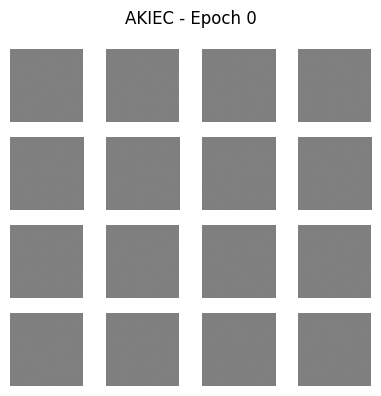

Epoch 2 — G_loss: 0.7656, D_loss: 1.2365
Epoch 3 — G_loss: 0.8544, D_loss: 1.0656
Epoch 4 — G_loss: 0.9926, D_loss: 0.8153
Epoch 5 — G_loss: 1.1130, D_loss: 0.6403
Epoch 6 — G_loss: 1.2322, D_loss: 0.5441
Epoch 7 — G_loss: 1.3889, D_loss: 0.5273
Epoch 8 — G_loss: 1.4688, D_loss: 0.4821
Epoch 9 — G_loss: 1.4786, D_loss: 0.5079
Epoch 10 — G_loss: 1.3892, D_loss: 0.5992
Epoch 11 — G_loss: 1.2470, D_loss: 0.7312
Epoch 12 — G_loss: 1.0864, D_loss: 0.9122
Epoch 13 — G_loss: 1.0792, D_loss: 0.9690
Epoch 14 — G_loss: 1.0255, D_loss: 1.0117
Epoch 15 — G_loss: 1.0001, D_loss: 1.0665
Epoch 16 — G_loss: 0.9765, D_loss: 1.0460
Epoch 17 — G_loss: 1.0364, D_loss: 1.0768
Epoch 18 — G_loss: 1.0673, D_loss: 1.0379
Epoch 19 — G_loss: 1.0158, D_loss: 1.0384
Epoch 20 — G_loss: 1.0752, D_loss: 1.1266
Epoch 21 — G_loss: 1.0594, D_loss: 1.1323
Epoch 22 — G_loss: 1.0414, D_loss: 1.1512
Epoch 23 — G_loss: 1.0402, D_loss: 1.2449
Epoch 24 — G_loss: 0.9290, D_loss: 1.2240
Epoch 25 — G_loss: 0.9182, D_loss: 1.2125


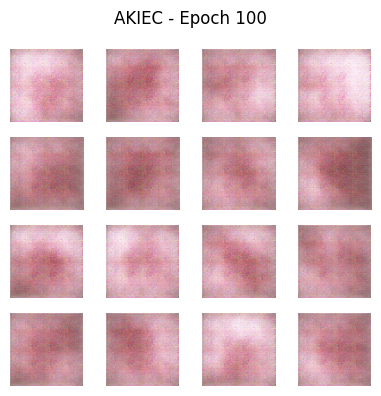

Epoch 102 — G_loss: 0.6914, D_loss: 1.3500
Epoch 103 — G_loss: 0.6808, D_loss: 1.3886
Epoch 104 — G_loss: 0.6859, D_loss: 1.3450
Epoch 105 — G_loss: 0.7092, D_loss: 1.3103
Epoch 106 — G_loss: 0.7278, D_loss: 1.3112
Epoch 107 — G_loss: 0.7020, D_loss: 1.3197
Epoch 108 — G_loss: 0.6769, D_loss: 1.3244
Epoch 109 — G_loss: 0.6490, D_loss: 1.3996
Epoch 110 — G_loss: 0.6870, D_loss: 1.3340
Epoch 111 — G_loss: 0.7356, D_loss: 1.2736
Epoch 112 — G_loss: 0.7263, D_loss: 1.3084
Epoch 113 — G_loss: 0.6856, D_loss: 1.3735
Epoch 114 — G_loss: 0.6742, D_loss: 1.3903
Epoch 115 — G_loss: 0.7015, D_loss: 1.3268
Epoch 116 — G_loss: 0.7339, D_loss: 1.3154
Epoch 117 — G_loss: 0.7128, D_loss: 1.3278
Epoch 118 — G_loss: 0.6896, D_loss: 1.3428
Epoch 119 — G_loss: 0.6869, D_loss: 1.3659
Epoch 120 — G_loss: 0.6898, D_loss: 1.3410
Epoch 121 — G_loss: 0.7016, D_loss: 1.3518
Epoch 122 — G_loss: 0.6977, D_loss: 1.3569
Epoch 123 — G_loss: 0.7072, D_loss: 1.3512
Epoch 124 — G_loss: 0.7244, D_loss: 1.3463
Epoch 125 —

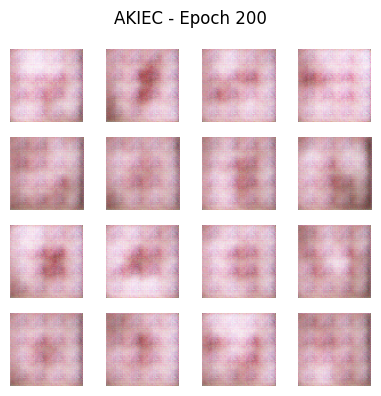

Epoch 202 — G_loss: 0.7316, D_loss: 1.3483
Epoch 203 — G_loss: 0.7227, D_loss: 1.3499
Epoch 204 — G_loss: 0.7146, D_loss: 1.3629
Epoch 205 — G_loss: 0.7191, D_loss: 1.3251
Epoch 206 — G_loss: 0.7548, D_loss: 1.2741
Epoch 207 — G_loss: 0.7923, D_loss: 1.2533
Epoch 208 — G_loss: 0.7688, D_loss: 1.3341
Epoch 209 — G_loss: 0.7193, D_loss: 1.3551
Epoch 210 — G_loss: 0.7167, D_loss: 1.3923
Epoch 211 — G_loss: 0.7041, D_loss: 1.3950
Epoch 212 — G_loss: 0.7099, D_loss: 1.3071
Epoch 213 — G_loss: 0.7478, D_loss: 1.2823
Epoch 214 — G_loss: 0.7470, D_loss: 1.3153
Epoch 215 — G_loss: 0.7301, D_loss: 1.3896
Epoch 216 — G_loss: 0.6939, D_loss: 1.3612
Epoch 217 — G_loss: 0.7164, D_loss: 1.3678
Epoch 218 — G_loss: 0.7372, D_loss: 1.3240
Epoch 219 — G_loss: 0.7580, D_loss: 1.3244
Epoch 220 — G_loss: 0.7406, D_loss: 1.3690
Epoch 221 — G_loss: 0.7154, D_loss: 1.3534
Epoch 222 — G_loss: 0.7231, D_loss: 1.3319
Epoch 223 — G_loss: 0.7441, D_loss: 1.2906
Epoch 224 — G_loss: 0.7280, D_loss: 1.3625
Epoch 225 —

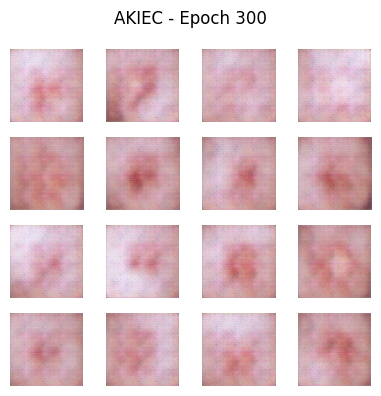

Epoch 302 — G_loss: 0.7132, D_loss: 1.3864
Epoch 303 — G_loss: 0.7014, D_loss: 1.4246
Epoch 304 — G_loss: 0.7117, D_loss: 1.4273
Epoch 305 — G_loss: 0.7886, D_loss: 1.3473
Epoch 306 — G_loss: 0.7686, D_loss: 1.3669
Epoch 307 — G_loss: 0.6926, D_loss: 1.4648
Epoch 308 — G_loss: 0.6886, D_loss: 1.4061
Epoch 309 — G_loss: 0.7289, D_loss: 1.3308
Epoch 310 — G_loss: 0.7415, D_loss: 1.2393
Epoch 311 — G_loss: 0.7370, D_loss: 1.2329
Epoch 312 — G_loss: 0.7280, D_loss: 1.2885
Epoch 313 — G_loss: 0.8596, D_loss: 1.1112
Epoch 314 — G_loss: 0.9415, D_loss: 0.9855
Epoch 315 — G_loss: 0.8006, D_loss: 1.1520
Epoch 316 — G_loss: 0.7780, D_loss: 1.2247
Epoch 317 — G_loss: 0.7853, D_loss: 1.2050
Epoch 318 — G_loss: 0.6924, D_loss: 1.5181
Epoch 319 — G_loss: 0.6503, D_loss: 1.6017
Epoch 320 — G_loss: 0.7299, D_loss: 1.4645
Epoch 321 — G_loss: 0.6976, D_loss: 1.4438
Epoch 322 — G_loss: 0.6925, D_loss: 1.4357
Epoch 323 — G_loss: 0.7137, D_loss: 1.4431
Epoch 324 — G_loss: 0.7239, D_loss: 1.4027
Epoch 325 —

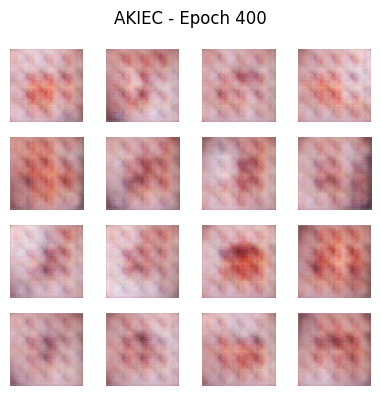

Epoch 402 — G_loss: 0.7018, D_loss: 1.4486
Epoch 403 — G_loss: 0.7136, D_loss: 1.4240
Epoch 404 — G_loss: 0.7504, D_loss: 1.3601
Epoch 405 — G_loss: 0.7517, D_loss: 1.3016
Epoch 406 — G_loss: 0.7433, D_loss: 1.3114
Epoch 407 — G_loss: 0.7093, D_loss: 1.3728
Epoch 408 — G_loss: 0.6944, D_loss: 1.4129
Epoch 409 — G_loss: 0.6874, D_loss: 1.4297
Epoch 410 — G_loss: 0.7220, D_loss: 1.3413
Epoch 411 — G_loss: 0.7395, D_loss: 1.2969
Epoch 412 — G_loss: 0.7217, D_loss: 1.3195
Epoch 413 — G_loss: 0.7018, D_loss: 1.3682
Epoch 414 — G_loss: 0.7017, D_loss: 1.4054
Epoch 415 — G_loss: 0.7254, D_loss: 1.3580
Epoch 416 — G_loss: 0.7481, D_loss: 1.2792
Epoch 417 — G_loss: 0.7368, D_loss: 1.2932
Epoch 418 — G_loss: 0.7149, D_loss: 1.3896
Epoch 419 — G_loss: 0.6859, D_loss: 1.4522
Epoch 420 — G_loss: 0.6896, D_loss: 1.4111
Epoch 421 — G_loss: 0.7352, D_loss: 1.3340
Epoch 422 — G_loss: 0.7487, D_loss: 1.3272
Epoch 423 — G_loss: 0.7179, D_loss: 1.4014
Epoch 424 — G_loss: 0.7208, D_loss: 1.3929
Epoch 425 —

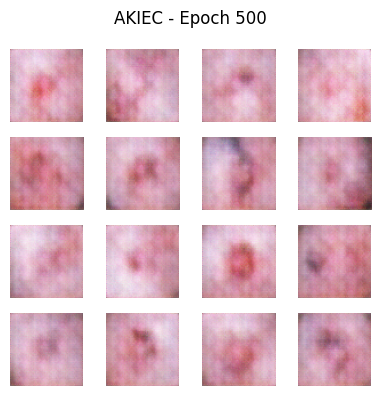

Epoch 502 — G_loss: 0.7636, D_loss: 1.3422
Epoch 503 — G_loss: 0.7553, D_loss: 1.3261
Epoch 504 — G_loss: 0.7238, D_loss: 1.3663
Epoch 505 — G_loss: 0.7364, D_loss: 1.4050
Epoch 506 — G_loss: 0.7252, D_loss: 1.4434
Epoch 507 — G_loss: 0.6835, D_loss: 1.3919
Epoch 508 — G_loss: 0.7095, D_loss: 1.3127
Epoch 509 — G_loss: 0.7144, D_loss: 1.2737
Epoch 510 — G_loss: 0.7003, D_loss: 1.3469
Epoch 511 — G_loss: 0.6954, D_loss: 1.4245
Epoch 512 — G_loss: 0.7335, D_loss: 1.4097
Epoch 513 — G_loss: 0.7687, D_loss: 1.3232
Epoch 514 — G_loss: 0.7558, D_loss: 1.3235
Epoch 515 — G_loss: 0.7113, D_loss: 1.3720
Epoch 516 — G_loss: 0.7074, D_loss: 1.4092
Epoch 517 — G_loss: 0.6959, D_loss: 1.4068
Epoch 518 — G_loss: 0.6718, D_loss: 1.3786
Epoch 519 — G_loss: 0.6968, D_loss: 1.3460
Epoch 520 — G_loss: 0.6886, D_loss: 1.3244
Epoch 521 — G_loss: 0.6994, D_loss: 1.4165
Epoch 522 — G_loss: 0.7196, D_loss: 1.3963
Epoch 523 — G_loss: 0.7299, D_loss: 1.3603
Epoch 524 — G_loss: 0.7525, D_loss: 1.3170
Epoch 525 —

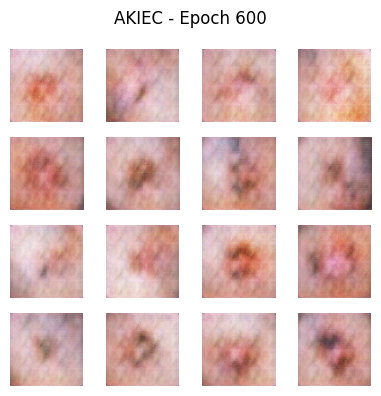

Epoch 602 — G_loss: 0.6940, D_loss: 1.3962
Epoch 603 — G_loss: 0.6679, D_loss: 1.3697
Epoch 604 — G_loss: 0.6808, D_loss: 1.3290
Epoch 605 — G_loss: 0.7010, D_loss: 1.3304
Epoch 606 — G_loss: 0.7224, D_loss: 1.4173
Epoch 607 — G_loss: 0.7279, D_loss: 1.4059
Epoch 608 — G_loss: 0.7335, D_loss: 1.3609
Epoch 609 — G_loss: 0.7255, D_loss: 1.3566
Epoch 610 — G_loss: 0.7238, D_loss: 1.3686
Epoch 611 — G_loss: 0.7162, D_loss: 1.3906
Epoch 612 — G_loss: 0.6977, D_loss: 1.3577
Epoch 613 — G_loss: 0.7050, D_loss: 1.3454
Epoch 614 — G_loss: 0.6736, D_loss: 1.3825
Epoch 615 — G_loss: 0.6907, D_loss: 1.4212
Epoch 616 — G_loss: 0.7468, D_loss: 1.3990
Epoch 617 — G_loss: 0.7357, D_loss: 1.3694
Epoch 618 — G_loss: 0.7353, D_loss: 1.3541
Epoch 619 — G_loss: 0.6943, D_loss: 1.3805
Epoch 620 — G_loss: 0.6906, D_loss: 1.4212
Epoch 621 — G_loss: 0.7038, D_loss: 1.3866
Epoch 622 — G_loss: 0.7087, D_loss: 1.3423
Epoch 623 — G_loss: 0.7135, D_loss: 1.3341
Epoch 624 — G_loss: 0.6951, D_loss: 1.3835
Epoch 625 —

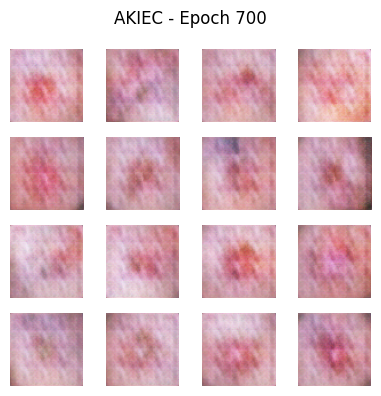

Epoch 702 — G_loss: 0.7029, D_loss: 1.3533
Epoch 703 — G_loss: 0.6815, D_loss: 1.3840
Epoch 704 — G_loss: 0.6731, D_loss: 1.3743
Epoch 705 — G_loss: 0.6825, D_loss: 1.3398
Epoch 706 — G_loss: 0.7011, D_loss: 1.3495
Epoch 707 — G_loss: 0.6989, D_loss: 1.3990
Epoch 708 — G_loss: 0.7096, D_loss: 1.4246
Epoch 709 — G_loss: 0.7278, D_loss: 1.4005
Epoch 710 — G_loss: 0.7267, D_loss: 1.3656
Epoch 711 — G_loss: 0.6681, D_loss: 1.3679
Epoch 712 — G_loss: 0.6805, D_loss: 1.3812
Epoch 713 — G_loss: 0.6795, D_loss: 1.3804
Epoch 714 — G_loss: 0.6844, D_loss: 1.3504
Epoch 715 — G_loss: 0.6960, D_loss: 1.3449
Epoch 716 — G_loss: 0.7100, D_loss: 1.3917
Epoch 717 — G_loss: 0.7152, D_loss: 1.4077
Epoch 718 — G_loss: 0.7450, D_loss: 1.3796
Epoch 719 — G_loss: 0.7431, D_loss: 1.3728
Epoch 720 — G_loss: 0.7073, D_loss: 1.3751
Epoch 721 — G_loss: 0.7222, D_loss: 1.4146
Epoch 722 — G_loss: 0.7160, D_loss: 1.4174
Epoch 723 — G_loss: 0.7031, D_loss: 1.3546
Epoch 724 — G_loss: 0.6862, D_loss: 1.3550
Epoch 725 —

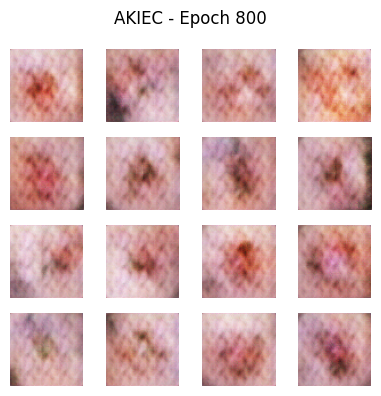

Epoch 802 — G_loss: 0.7263, D_loss: 1.3672
Epoch 803 — G_loss: 0.7019, D_loss: 1.3533
Epoch 804 — G_loss: 0.7019, D_loss: 1.3514
Epoch 805 — G_loss: 0.7019, D_loss: 1.4018
Epoch 806 — G_loss: 0.7013, D_loss: 1.3848
Epoch 807 — G_loss: 0.7389, D_loss: 1.3559
Epoch 808 — G_loss: 0.7123, D_loss: 1.3578
Epoch 809 — G_loss: 0.6984, D_loss: 1.3724
Epoch 810 — G_loss: 0.7153, D_loss: 1.3873
Epoch 811 — G_loss: 0.7217, D_loss: 1.3900
Epoch 812 — G_loss: 0.6967, D_loss: 1.3755
Epoch 813 — G_loss: 0.7030, D_loss: 1.3294
Epoch 814 — G_loss: 0.7003, D_loss: 1.3567
Epoch 815 — G_loss: 0.6932, D_loss: 1.3682
Epoch 816 — G_loss: 0.7445, D_loss: 1.4148
Epoch 817 — G_loss: 0.7175, D_loss: 1.3701
Epoch 818 — G_loss: 0.7001, D_loss: 1.3575
Epoch 819 — G_loss: 0.6927, D_loss: 1.3923
Epoch 820 — G_loss: 0.7020, D_loss: 1.3830
Epoch 821 — G_loss: 0.7216, D_loss: 1.3777
Epoch 822 — G_loss: 0.6900, D_loss: 1.3619
Epoch 823 — G_loss: 0.7036, D_loss: 1.3587
Epoch 824 — G_loss: 0.7021, D_loss: 1.3463
Epoch 825 —

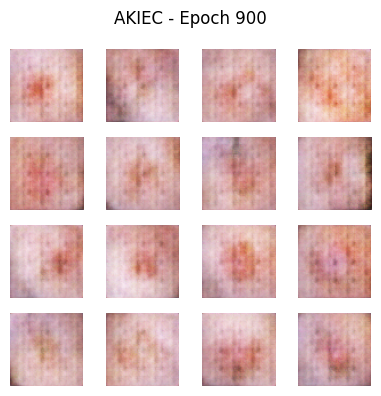

Epoch 902 — G_loss: 0.6986, D_loss: 1.3539
Epoch 903 — G_loss: 0.6930, D_loss: 1.3598
Epoch 904 — G_loss: 0.6731, D_loss: 1.3866
Epoch 905 — G_loss: 0.6870, D_loss: 1.3820
Epoch 906 — G_loss: 0.7049, D_loss: 1.3721
Epoch 907 — G_loss: 0.7018, D_loss: 1.3845
Epoch 908 — G_loss: 0.7013, D_loss: 1.3915
Epoch 909 — G_loss: 0.7296, D_loss: 1.3739
Epoch 910 — G_loss: 0.7274, D_loss: 1.3701
Epoch 911 — G_loss: 0.7091, D_loss: 1.3567
Epoch 912 — G_loss: 0.7138, D_loss: 1.3886
Epoch 913 — G_loss: 0.6937, D_loss: 1.3778
Epoch 914 — G_loss: 0.7036, D_loss: 1.3403
Epoch 915 — G_loss: 0.7155, D_loss: 1.3917
Epoch 916 — G_loss: 0.7001, D_loss: 1.3866
Epoch 917 — G_loss: 0.7159, D_loss: 1.3511
Epoch 918 — G_loss: 0.7189, D_loss: 1.3426
Epoch 919 — G_loss: 0.6857, D_loss: 1.3994
Epoch 920 — G_loss: 0.7133, D_loss: 1.4143
Epoch 921 — G_loss: 0.7537, D_loss: 1.3260
Epoch 922 — G_loss: 0.7227, D_loss: 1.3459
Epoch 923 — G_loss: 0.6800, D_loss: 1.4021
Epoch 924 — G_loss: 0.6822, D_loss: 1.3842
Epoch 925 —

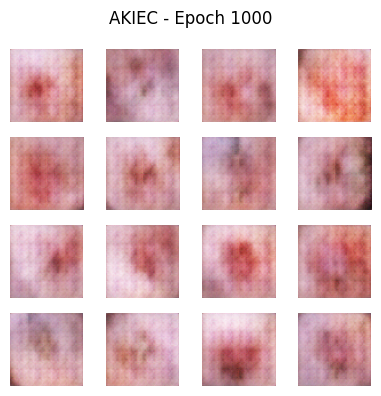

Epoch 1002 — G_loss: 0.7095, D_loss: 1.3802
Epoch 1003 — G_loss: 0.7149, D_loss: 1.3960
Epoch 1004 — G_loss: 0.7012, D_loss: 1.3703
Epoch 1005 — G_loss: 0.7043, D_loss: 1.3614
Epoch 1006 — G_loss: 0.7074, D_loss: 1.3572
Epoch 1007 — G_loss: 0.7014, D_loss: 1.3881
Epoch 1008 — G_loss: 0.6782, D_loss: 1.3733
Epoch 1009 — G_loss: 0.6755, D_loss: 1.3675
Epoch 1010 — G_loss: 0.7451, D_loss: 1.3065
Epoch 1011 — G_loss: 0.7885, D_loss: 1.1704
Epoch 1012 — G_loss: 0.6670, D_loss: 1.3557
Epoch 1013 — G_loss: 0.7151, D_loss: 1.3330
Epoch 1014 — G_loss: 0.7441, D_loss: 1.4036
Epoch 1015 — G_loss: 0.7395, D_loss: 1.4132
Epoch 1016 — G_loss: 0.7158, D_loss: 1.4189
Epoch 1017 — G_loss: 0.7341, D_loss: 1.4648
Epoch 1018 — G_loss: 0.7403, D_loss: 1.3862
Epoch 1019 — G_loss: 0.7312, D_loss: 1.3278
Epoch 1020 — G_loss: 0.7007, D_loss: 1.3943
Epoch 1021 — G_loss: 0.6846, D_loss: 1.4746
Epoch 1022 — G_loss: 0.6663, D_loss: 1.3764
Epoch 1023 — G_loss: 0.6552, D_loss: 1.3185
Epoch 1024 — G_loss: 0.7309, D_l

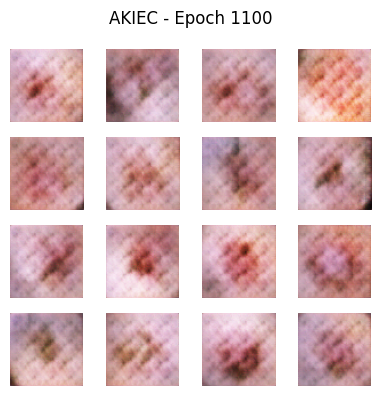

Epoch 1102 — G_loss: 0.7143, D_loss: 1.3703
Epoch 1103 — G_loss: 0.7024, D_loss: 1.3960
Epoch 1104 — G_loss: 0.7537, D_loss: 1.3792
Epoch 1105 — G_loss: 0.7169, D_loss: 1.3653
Epoch 1106 — G_loss: 0.7208, D_loss: 1.3440
Epoch 1107 — G_loss: 0.7061, D_loss: 1.3736
Epoch 1108 — G_loss: 0.6875, D_loss: 1.3866
Epoch 1109 — G_loss: 0.7009, D_loss: 1.3388
Epoch 1110 — G_loss: 0.6935, D_loss: 1.3462
Epoch 1111 — G_loss: 0.7338, D_loss: 1.4020
Epoch 1112 — G_loss: 0.7041, D_loss: 1.3957
Epoch 1113 — G_loss: 0.7238, D_loss: 1.3705
Epoch 1114 — G_loss: 0.7064, D_loss: 1.3722
Epoch 1115 — G_loss: 0.6986, D_loss: 1.4020
Epoch 1116 — G_loss: 0.7141, D_loss: 1.3795
Epoch 1117 — G_loss: 0.7297, D_loss: 1.3407
Epoch 1118 — G_loss: 0.7043, D_loss: 1.3942
Epoch 1119 — G_loss: 0.7206, D_loss: 1.4012
Epoch 1120 — G_loss: 0.7004, D_loss: 1.3840
Epoch 1121 — G_loss: 0.7081, D_loss: 1.3643
Epoch 1122 — G_loss: 0.7029, D_loss: 1.3549
Epoch 1123 — G_loss: 0.6865, D_loss: 1.3820
Epoch 1124 — G_loss: 0.6825, D_l

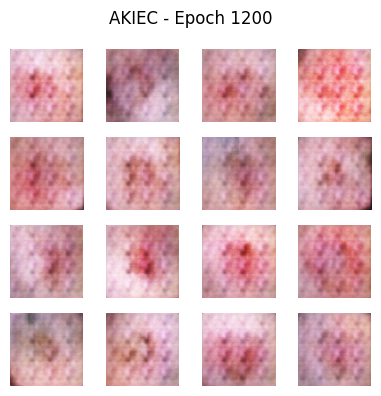

Epoch 1202 — G_loss: 0.6728, D_loss: 1.4142
Epoch 1203 — G_loss: 0.7110, D_loss: 1.3335
Epoch 1204 — G_loss: 0.6696, D_loss: 1.3186
Epoch 1205 — G_loss: 0.6920, D_loss: 1.4009
Epoch 1206 — G_loss: 0.7251, D_loss: 1.4145
Epoch 1207 — G_loss: 0.7306, D_loss: 1.3901
Epoch 1208 — G_loss: 0.7132, D_loss: 1.3775
Epoch 1209 — G_loss: 0.7145, D_loss: 1.3748
Epoch 1210 — G_loss: 0.6801, D_loss: 1.3920
Epoch 1211 — G_loss: 0.6879, D_loss: 1.3583
Epoch 1212 — G_loss: 0.7103, D_loss: 1.3427
Epoch 1213 — G_loss: 0.7140, D_loss: 1.3664
Epoch 1214 — G_loss: 0.7171, D_loss: 1.3821
Epoch 1215 — G_loss: 0.7287, D_loss: 1.3672
Epoch 1216 — G_loss: 0.7173, D_loss: 1.3770
Epoch 1217 — G_loss: 0.6883, D_loss: 1.3878
Epoch 1218 — G_loss: 0.6774, D_loss: 1.3688
Epoch 1219 — G_loss: 0.6775, D_loss: 1.3705
Epoch 1220 — G_loss: 0.7216, D_loss: 1.3675
Epoch 1221 — G_loss: 0.7129, D_loss: 1.3808
Epoch 1222 — G_loss: 0.7203, D_loss: 1.3716
Epoch 1223 — G_loss: 0.7055, D_loss: 1.3591
Epoch 1224 — G_loss: 0.7372, D_l

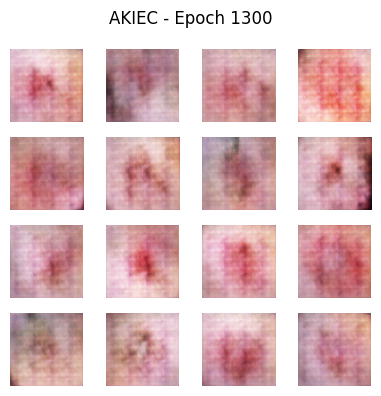

Epoch 1302 — G_loss: 0.7257, D_loss: 1.3882
Epoch 1303 — G_loss: 0.7186, D_loss: 1.3995
Epoch 1304 — G_loss: 0.7147, D_loss: 1.3987
Epoch 1305 — G_loss: 0.7180, D_loss: 1.3812
Epoch 1306 — G_loss: 0.6936, D_loss: 1.3483
Epoch 1307 — G_loss: 0.7082, D_loss: 1.3543
Epoch 1308 — G_loss: 0.7027, D_loss: 1.3841
Epoch 1309 — G_loss: 0.7081, D_loss: 1.3612
Epoch 1310 — G_loss: 0.6678, D_loss: 1.3536
Epoch 1311 — G_loss: 0.7099, D_loss: 1.3752
Epoch 1312 — G_loss: 0.7269, D_loss: 1.3995
Epoch 1313 — G_loss: 0.7191, D_loss: 1.3994
Epoch 1314 — G_loss: 0.7198, D_loss: 1.3786
Epoch 1315 — G_loss: 0.7052, D_loss: 1.3706
Epoch 1316 — G_loss: 0.7083, D_loss: 1.3797
Epoch 1317 — G_loss: 0.6823, D_loss: 1.3641
Epoch 1318 — G_loss: 0.7130, D_loss: 1.3591
Epoch 1319 — G_loss: 0.7309, D_loss: 1.3626
Epoch 1320 — G_loss: 0.7255, D_loss: 1.3556
Epoch 1321 — G_loss: 0.7164, D_loss: 1.3468
Epoch 1322 — G_loss: 0.6840, D_loss: 1.3515
Epoch 1323 — G_loss: 0.6844, D_loss: 1.3565
Epoch 1324 — G_loss: 0.6946, D_l

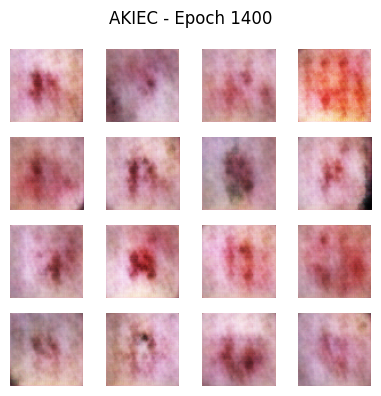

Epoch 1402 — G_loss: 0.7730, D_loss: 1.3556
Epoch 1403 — G_loss: 0.7194, D_loss: 1.3701
Epoch 1404 — G_loss: 0.7135, D_loss: 1.3871
Epoch 1405 — G_loss: 0.7085, D_loss: 1.4062
Epoch 1406 — G_loss: 0.7300, D_loss: 1.3768
Epoch 1407 — G_loss: 0.7254, D_loss: 1.3669
Epoch 1408 — G_loss: 0.7004, D_loss: 1.3430
Epoch 1409 — G_loss: 0.6857, D_loss: 1.3645
Epoch 1410 — G_loss: 0.6653, D_loss: 1.3710
Epoch 1411 — G_loss: 0.7297, D_loss: 1.3582
Epoch 1412 — G_loss: 0.7451, D_loss: 1.3708
Epoch 1413 — G_loss: 0.7176, D_loss: 1.3670
Epoch 1414 — G_loss: 0.7052, D_loss: 1.3873
Epoch 1415 — G_loss: 0.7067, D_loss: 1.3869
Epoch 1416 — G_loss: 0.6841, D_loss: 1.3874
Epoch 1417 — G_loss: 0.6834, D_loss: 1.3499
Epoch 1418 — G_loss: 0.6815, D_loss: 1.3739
Epoch 1419 — G_loss: 0.6832, D_loss: 1.4040
Epoch 1420 — G_loss: 0.6969, D_loss: 1.3559
Epoch 1421 — G_loss: 0.7528, D_loss: 1.3328
Epoch 1422 — G_loss: 0.7177, D_loss: 1.3949
Epoch 1423 — G_loss: 0.7331, D_loss: 1.3822
Epoch 1424 — G_loss: 0.7231, D_l

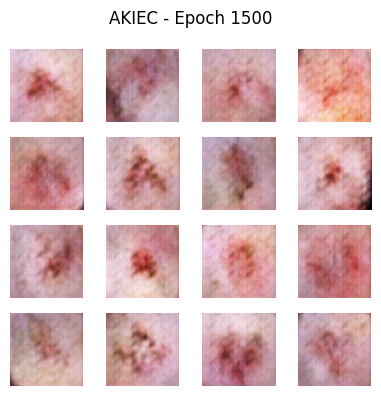

Epoch 1502 — G_loss: 0.6919, D_loss: 1.3816
Epoch 1503 — G_loss: 0.7196, D_loss: 1.3829
Epoch 1504 — G_loss: 0.6969, D_loss: 1.3789
Epoch 1505 — G_loss: 0.6987, D_loss: 1.3800
Epoch 1506 — G_loss: 0.7021, D_loss: 1.3728
Epoch 1507 — G_loss: 0.7130, D_loss: 1.3801
Epoch 1508 — G_loss: 0.7066, D_loss: 1.3828
Epoch 1509 — G_loss: 0.7044, D_loss: 1.3686
Epoch 1510 — G_loss: 0.7185, D_loss: 1.3768
Epoch 1511 — G_loss: 0.7102, D_loss: 1.3732
Epoch 1512 — G_loss: 0.7148, D_loss: 1.3799
Epoch 1513 — G_loss: 0.6881, D_loss: 1.3790
Epoch 1514 — G_loss: 0.7002, D_loss: 1.3759
Epoch 1515 — G_loss: 0.6691, D_loss: 1.3811
Epoch 1516 — G_loss: 0.6860, D_loss: 1.3738
Epoch 1517 — G_loss: 0.6964, D_loss: 1.3643
Epoch 1518 — G_loss: 0.6994, D_loss: 1.3740
Epoch 1519 — G_loss: 0.7134, D_loss: 1.3873
Epoch 1520 — G_loss: 0.6937, D_loss: 1.3722
Epoch 1521 — G_loss: 0.7049, D_loss: 1.3773
Epoch 1522 — G_loss: 0.7300, D_loss: 1.3846
Epoch 1523 — G_loss: 0.7155, D_loss: 1.3853
Epoch 1524 — G_loss: 0.6979, D_l

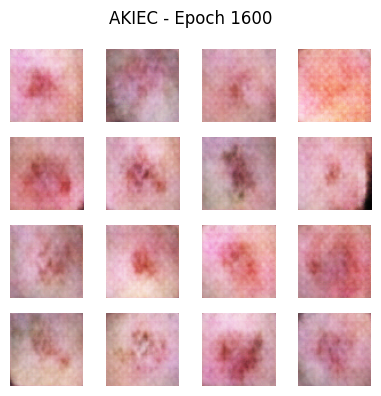

Epoch 1602 — G_loss: 0.6982, D_loss: 1.3790
Epoch 1603 — G_loss: 0.7119, D_loss: 1.3814
Epoch 1604 — G_loss: 0.6915, D_loss: 1.3688
Epoch 1605 — G_loss: 0.7039, D_loss: 1.3766
Epoch 1606 — G_loss: 0.7252, D_loss: 1.3622
Epoch 1607 — G_loss: 0.7137, D_loss: 1.3646
Epoch 1608 — G_loss: 0.6791, D_loss: 1.3904
Epoch 1609 — G_loss: 0.6776, D_loss: 1.3539
Epoch 1610 — G_loss: 0.6937, D_loss: 1.3832
Epoch 1611 — G_loss: 0.7712, D_loss: 1.3880
Epoch 1612 — G_loss: 0.7221, D_loss: 1.3717
Epoch 1613 — G_loss: 0.6956, D_loss: 1.3970
Epoch 1614 — G_loss: 0.6624, D_loss: 1.3773
Epoch 1615 — G_loss: 0.6924, D_loss: 1.3844
Epoch 1616 — G_loss: 0.7137, D_loss: 1.3722
Epoch 1617 — G_loss: 0.7057, D_loss: 1.3714
Epoch 1618 — G_loss: 0.7332, D_loss: 1.3891
Epoch 1619 — G_loss: 0.7055, D_loss: 1.3899
Epoch 1620 — G_loss: 0.6972, D_loss: 1.3716
Epoch 1621 — G_loss: 0.6941, D_loss: 1.3904
Epoch 1622 — G_loss: 0.6733, D_loss: 1.3724
Epoch 1623 — G_loss: 0.6771, D_loss: 1.3799
Epoch 1624 — G_loss: 0.7305, D_l

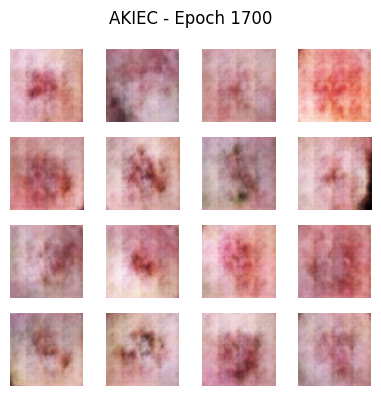

Epoch 1702 — G_loss: 0.6999, D_loss: 1.3839
Epoch 1703 — G_loss: 0.6942, D_loss: 1.3832
Epoch 1704 — G_loss: 0.7242, D_loss: 1.3782
Epoch 1705 — G_loss: 0.7480, D_loss: 1.3912
Epoch 1706 — G_loss: 0.6924, D_loss: 1.3776
Epoch 1707 — G_loss: 0.6768, D_loss: 1.3668
Epoch 1708 — G_loss: 0.6541, D_loss: 1.3705
Epoch 1709 — G_loss: 0.6929, D_loss: 1.3878
Epoch 1710 — G_loss: 0.7025, D_loss: 1.3926
Epoch 1711 — G_loss: 0.6925, D_loss: 1.3598
Epoch 1712 — G_loss: 0.7724, D_loss: 1.3753
Epoch 1713 — G_loss: 0.7220, D_loss: 1.3740
Epoch 1714 — G_loss: 0.7168, D_loss: 1.3779
Epoch 1715 — G_loss: 0.6807, D_loss: 1.3695
Epoch 1716 — G_loss: 0.7020, D_loss: 1.3710
Epoch 1717 — G_loss: 0.6777, D_loss: 1.3855
Epoch 1718 — G_loss: 0.6651, D_loss: 1.3685
Epoch 1719 — G_loss: 0.7088, D_loss: 1.3809
Epoch 1720 — G_loss: 0.6950, D_loss: 1.3888
Epoch 1721 — G_loss: 0.7195, D_loss: 1.3837
Epoch 1722 — G_loss: 0.6874, D_loss: 1.3754
Epoch 1723 — G_loss: 0.7010, D_loss: 1.3800
Epoch 1724 — G_loss: 0.7190, D_l

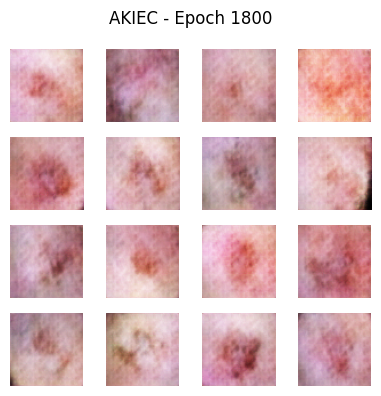

Epoch 1802 — G_loss: 0.6886, D_loss: 1.3762
Epoch 1803 — G_loss: 0.7316, D_loss: 1.3850
Epoch 1804 — G_loss: 0.7226, D_loss: 1.3805
Epoch 1805 — G_loss: 0.6818, D_loss: 1.3734
Epoch 1806 — G_loss: 0.7104, D_loss: 1.3863
Epoch 1807 — G_loss: 0.6923, D_loss: 1.3722
Epoch 1808 — G_loss: 0.7164, D_loss: 1.3839
Epoch 1809 — G_loss: 0.6996, D_loss: 1.3853
Epoch 1810 — G_loss: 0.6751, D_loss: 1.3696
Epoch 1811 — G_loss: 0.6734, D_loss: 1.3553
Epoch 1812 — G_loss: 0.7434, D_loss: 1.3825
Epoch 1813 — G_loss: 0.7066, D_loss: 1.3778
Epoch 1814 — G_loss: 0.6818, D_loss: 1.3574
Epoch 1815 — G_loss: 0.7102, D_loss: 1.3976
Epoch 1816 — G_loss: 0.7310, D_loss: 1.4015
Epoch 1817 — G_loss: 0.6836, D_loss: 1.3847
Epoch 1818 — G_loss: 0.7213, D_loss: 1.3691
Epoch 1819 — G_loss: 0.7029, D_loss: 1.3781
Epoch 1820 — G_loss: 0.6852, D_loss: 1.4026
Epoch 1821 — G_loss: 0.7175, D_loss: 1.3944
Epoch 1822 — G_loss: 0.7172, D_loss: 1.3581
Epoch 1823 — G_loss: 0.6872, D_loss: 1.3508
Epoch 1824 — G_loss: 0.6959, D_l

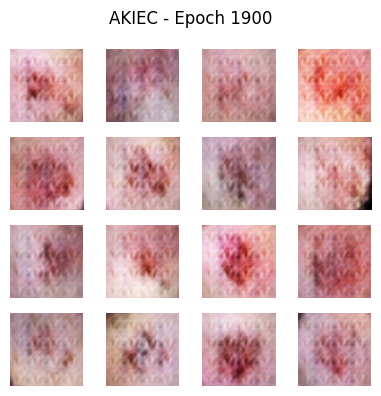

Epoch 1902 — G_loss: 0.6649, D_loss: 1.3468
Epoch 1903 — G_loss: 0.7292, D_loss: 1.3862
Epoch 1904 — G_loss: 0.7292, D_loss: 1.3883
Epoch 1905 — G_loss: 0.6746, D_loss: 1.3638
Epoch 1906 — G_loss: 0.7049, D_loss: 1.3867
Epoch 1907 — G_loss: 0.7521, D_loss: 1.3630
Epoch 1908 — G_loss: 0.6803, D_loss: 1.3708
Epoch 1909 — G_loss: 0.7405, D_loss: 1.3805
Epoch 1910 — G_loss: 0.7031, D_loss: 1.3750
Epoch 1911 — G_loss: 0.6916, D_loss: 1.3562
Epoch 1912 — G_loss: 0.6758, D_loss: 1.4077
Epoch 1913 — G_loss: 0.6699, D_loss: 1.3521
Epoch 1914 — G_loss: 0.7176, D_loss: 1.4012
Epoch 1915 — G_loss: 0.7204, D_loss: 1.4001
Epoch 1916 — G_loss: 0.6845, D_loss: 1.3768
Epoch 1917 — G_loss: 0.6882, D_loss: 1.3608
Epoch 1918 — G_loss: 0.6997, D_loss: 1.3712
Epoch 1919 — G_loss: 0.7332, D_loss: 1.3930
Epoch 1920 — G_loss: 0.7279, D_loss: 1.3332
Epoch 1921 — G_loss: 0.6955, D_loss: 1.3945
Epoch 1922 — G_loss: 0.7160, D_loss: 1.4040
Epoch 1923 — G_loss: 0.6887, D_loss: 1.3734
Epoch 1924 — G_loss: 0.7100, D_l

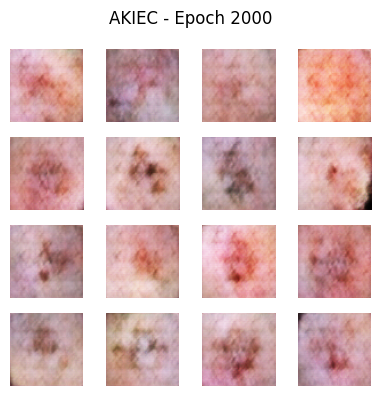

Epoch 2002 — G_loss: 0.6873, D_loss: 1.3926
Epoch 2003 — G_loss: 0.6886, D_loss: 1.3837
Epoch 2004 — G_loss: 0.6641, D_loss: 1.3463
Epoch 2005 — G_loss: 0.6804, D_loss: 1.3555
Epoch 2006 — G_loss: 0.7632, D_loss: 1.4111
Epoch 2007 — G_loss: 0.7357, D_loss: 1.3794
Epoch 2008 — G_loss: 0.7245, D_loss: 1.3668
Epoch 2009 — G_loss: 0.6924, D_loss: 1.3615
Epoch 2010 — G_loss: 0.6754, D_loss: 1.3788
Epoch 2011 — G_loss: 0.6768, D_loss: 1.3776
Epoch 2012 — G_loss: 0.6836, D_loss: 1.3745
Epoch 2013 — G_loss: 0.7117, D_loss: 1.4058
Epoch 2014 — G_loss: 0.7608, D_loss: 1.3624
Epoch 2015 — G_loss: 0.7089, D_loss: 1.3690
Epoch 2016 — G_loss: 0.7094, D_loss: 1.3705
Epoch 2017 — G_loss: 0.6986, D_loss: 1.3630
Epoch 2018 — G_loss: 0.7149, D_loss: 1.3789
Epoch 2019 — G_loss: 0.6987, D_loss: 1.3732
Epoch 2020 — G_loss: 0.6500, D_loss: 1.3461
Epoch 2021 — G_loss: 0.7116, D_loss: 1.4008
Epoch 2022 — G_loss: 0.7538, D_loss: 1.3802
Epoch 2023 — G_loss: 0.7213, D_loss: 1.3604
Epoch 2024 — G_loss: 0.6938, D_l

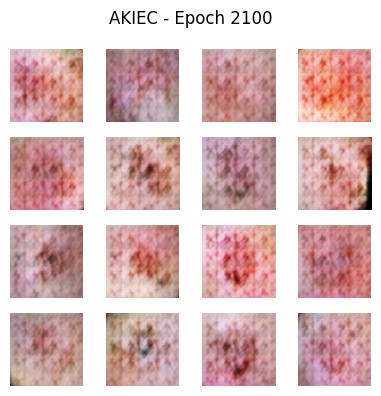

Epoch 2102 — G_loss: 0.6650, D_loss: 1.3498
Epoch 2103 — G_loss: 0.7102, D_loss: 1.3793
Epoch 2104 — G_loss: 0.6985, D_loss: 1.3714
Epoch 2105 — G_loss: 0.7392, D_loss: 1.3423
Epoch 2106 — G_loss: 0.6725, D_loss: 1.4130
Epoch 2107 — G_loss: 0.7705, D_loss: 1.3852
Epoch 2108 — G_loss: 0.7296, D_loss: 1.3543
Epoch 2109 — G_loss: 0.7231, D_loss: 1.3937
Epoch 2110 — G_loss: 0.6825, D_loss: 1.4251
Epoch 2111 — G_loss: 0.6638, D_loss: 1.3611
Epoch 2112 — G_loss: 0.6939, D_loss: 1.3267
Epoch 2113 — G_loss: 0.7223, D_loss: 1.3885
Epoch 2114 — G_loss: 0.7360, D_loss: 1.4156
Epoch 2115 — G_loss: 0.7368, D_loss: 1.3203
Epoch 2116 — G_loss: 0.7047, D_loss: 1.3964
Epoch 2117 — G_loss: 0.6762, D_loss: 1.3967
Epoch 2118 — G_loss: 0.6956, D_loss: 1.4017
Epoch 2119 — G_loss: 0.6502, D_loss: 1.3329
Epoch 2120 — G_loss: 0.7204, D_loss: 1.3439
Epoch 2121 — G_loss: 0.7873, D_loss: 1.3744
Epoch 2122 — G_loss: 0.7049, D_loss: 1.3472
Epoch 2123 — G_loss: 0.6380, D_loss: 1.3547
Epoch 2124 — G_loss: 0.7006, D_l

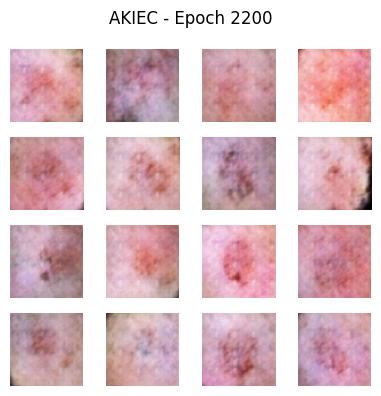

Epoch 2202 — G_loss: 0.6801, D_loss: 1.3528
Epoch 2203 — G_loss: 0.7181, D_loss: 1.3737
Epoch 2204 — G_loss: 0.6981, D_loss: 1.3910
Epoch 2205 — G_loss: 0.7318, D_loss: 1.3677
Epoch 2206 — G_loss: 0.6850, D_loss: 1.3563
Epoch 2207 — G_loss: 0.6983, D_loss: 1.3588
Epoch 2208 — G_loss: 0.7282, D_loss: 1.3889
Epoch 2209 — G_loss: 0.6838, D_loss: 1.3882
Epoch 2210 — G_loss: 0.7141, D_loss: 1.3676
Epoch 2211 — G_loss: 0.7160, D_loss: 1.3666
Epoch 2212 — G_loss: 0.6874, D_loss: 1.3667
Epoch 2213 — G_loss: 0.7215, D_loss: 1.3736
Epoch 2214 — G_loss: 0.6994, D_loss: 1.3670
Epoch 2215 — G_loss: 0.6857, D_loss: 1.3676
Epoch 2216 — G_loss: 0.7016, D_loss: 1.3887
Epoch 2217 — G_loss: 0.7320, D_loss: 1.3752
Epoch 2218 — G_loss: 0.7062, D_loss: 1.3789
Epoch 2219 — G_loss: 0.6895, D_loss: 1.3785
Epoch 2220 — G_loss: 0.7076, D_loss: 1.3774
Epoch 2221 — G_loss: 0.7363, D_loss: 1.3632
Epoch 2222 — G_loss: 0.6713, D_loss: 1.3771
Epoch 2223 — G_loss: 0.7030, D_loss: 1.3724
Epoch 2224 — G_loss: 0.7318, D_l

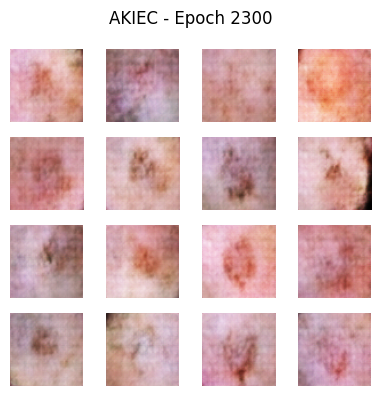

Epoch 2302 — G_loss: 0.7368, D_loss: 1.3908
Epoch 2303 — G_loss: 0.7090, D_loss: 1.3596
Epoch 2304 — G_loss: 0.6828, D_loss: 1.3453
Epoch 2305 — G_loss: 0.6954, D_loss: 1.3940
Epoch 2306 — G_loss: 0.7406, D_loss: 1.3811
Epoch 2307 — G_loss: 0.6716, D_loss: 1.3664
Epoch 2308 — G_loss: 0.7050, D_loss: 1.3760
Epoch 2309 — G_loss: 0.7108, D_loss: 1.3830
Epoch 2310 — G_loss: 0.7005, D_loss: 1.3688
Epoch 2311 — G_loss: 0.7216, D_loss: 1.3854
Epoch 2312 — G_loss: 0.6982, D_loss: 1.3888
Epoch 2313 — G_loss: 0.7100, D_loss: 1.3752
Epoch 2314 — G_loss: 0.7235, D_loss: 1.3567
Epoch 2315 — G_loss: 0.6978, D_loss: 1.3740
Epoch 2316 — G_loss: 0.6928, D_loss: 1.4125
Epoch 2317 — G_loss: 0.7505, D_loss: 1.3285
Epoch 2318 — G_loss: 0.6774, D_loss: 1.3627
Epoch 2319 — G_loss: 0.7008, D_loss: 1.4034
Epoch 2320 — G_loss: 0.6941, D_loss: 1.3825
Epoch 2321 — G_loss: 0.7054, D_loss: 1.3494
Epoch 2322 — G_loss: 0.7258, D_loss: 1.3750
Epoch 2323 — G_loss: 0.7207, D_loss: 1.4040
Epoch 2324 — G_loss: 0.7321, D_l

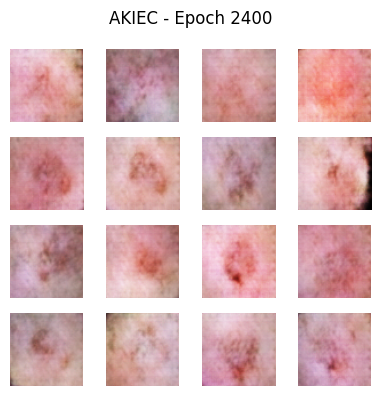

Epoch 2402 — G_loss: 0.7203, D_loss: 1.3801
Epoch 2403 — G_loss: 0.6829, D_loss: 1.3697
Epoch 2404 — G_loss: 0.7087, D_loss: 1.3643
Epoch 2405 — G_loss: 0.7006, D_loss: 1.3839
Epoch 2406 — G_loss: 0.7042, D_loss: 1.3649
Epoch 2407 — G_loss: 0.7025, D_loss: 1.3883
Epoch 2408 — G_loss: 0.7124, D_loss: 1.3855
Epoch 2409 — G_loss: 0.6842, D_loss: 1.3844
Epoch 2410 — G_loss: 0.7029, D_loss: 1.3575
Epoch 2411 — G_loss: 0.7066, D_loss: 1.3708
Epoch 2412 — G_loss: 0.7033, D_loss: 1.3854
Epoch 2413 — G_loss: 0.7120, D_loss: 1.3574
Epoch 2414 — G_loss: 0.7087, D_loss: 1.3881
Epoch 2415 — G_loss: 0.7203, D_loss: 1.3810
Epoch 2416 — G_loss: 0.7072, D_loss: 1.3701
Epoch 2417 — G_loss: 0.6795, D_loss: 1.3632
Epoch 2418 — G_loss: 0.6980, D_loss: 1.3919
Epoch 2419 — G_loss: 0.6770, D_loss: 1.3886
Epoch 2420 — G_loss: 0.7024, D_loss: 1.3684
Epoch 2421 — G_loss: 0.7121, D_loss: 1.3810
Epoch 2422 — G_loss: 0.7188, D_loss: 1.3751
Epoch 2423 — G_loss: 0.6933, D_loss: 1.3697
Epoch 2424 — G_loss: 0.6759, D_l

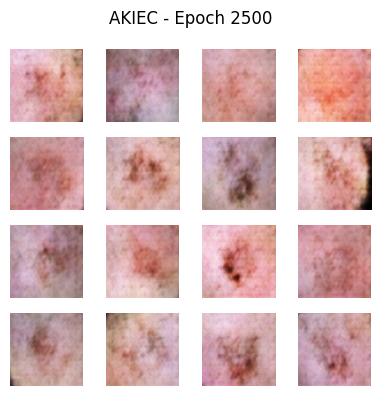

Epoch 2502 — G_loss: 0.6513, D_loss: 1.3751
Epoch 2503 — G_loss: 0.7158, D_loss: 1.3985
Epoch 2504 — G_loss: 0.7293, D_loss: 1.3644
Epoch 2505 — G_loss: 0.6940, D_loss: 1.3705
Epoch 2506 — G_loss: 0.7006, D_loss: 1.3786
Epoch 2507 — G_loss: 0.7088, D_loss: 1.3958
Epoch 2508 — G_loss: 0.7077, D_loss: 1.3601
Epoch 2509 — G_loss: 0.6963, D_loss: 1.3425
Epoch 2510 — G_loss: 0.7089, D_loss: 1.3782
Epoch 2511 — G_loss: 0.7228, D_loss: 1.3961
Epoch 2512 — G_loss: 0.7155, D_loss: 1.3615
Epoch 2513 — G_loss: 0.6914, D_loss: 1.3491
Epoch 2514 — G_loss: 0.7060, D_loss: 1.3864
Epoch 2515 — G_loss: 0.7122, D_loss: 1.3960
Epoch 2516 — G_loss: 0.6834, D_loss: 1.3687
Epoch 2517 — G_loss: 0.6955, D_loss: 1.3398
Epoch 2518 — G_loss: 0.7089, D_loss: 1.3584
Epoch 2519 — G_loss: 0.7824, D_loss: 1.3894
Epoch 2520 — G_loss: 0.7252, D_loss: 1.3638
Epoch 2521 — G_loss: 0.7247, D_loss: 1.3646
Epoch 2522 — G_loss: 0.6677, D_loss: 1.3383
Epoch 2523 — G_loss: 0.6695, D_loss: 1.3578
Epoch 2524 — G_loss: 0.7312, D_l

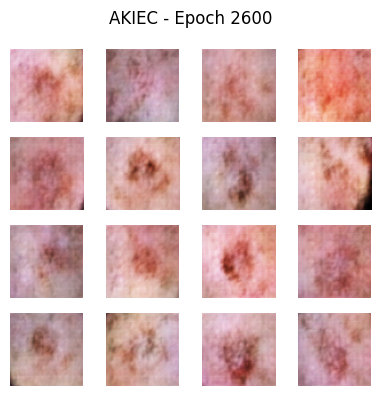

Epoch 2602 — G_loss: 0.7000, D_loss: 1.4052
Epoch 2603 — G_loss: 0.7715, D_loss: 1.3499
Epoch 2604 — G_loss: 0.7211, D_loss: 1.3645
Epoch 2605 — G_loss: 0.6831, D_loss: 1.3940
Epoch 2606 — G_loss: 0.6881, D_loss: 1.3773
Epoch 2607 — G_loss: 0.6915, D_loss: 1.3545
Epoch 2608 — G_loss: 0.6977, D_loss: 1.3374
Epoch 2609 — G_loss: 0.6875, D_loss: 1.4018
Epoch 2610 — G_loss: 0.7516, D_loss: 1.3792
Epoch 2611 — G_loss: 0.6874, D_loss: 1.3563
Epoch 2612 — G_loss: 0.6696, D_loss: 1.3786
Epoch 2613 — G_loss: 0.7052, D_loss: 1.3825
Epoch 2614 — G_loss: 0.7078, D_loss: 1.3586
Epoch 2615 — G_loss: 0.7232, D_loss: 1.3673
Epoch 2616 — G_loss: 0.6899, D_loss: 1.3661
Epoch 2617 — G_loss: 0.7323, D_loss: 1.3472
Epoch 2618 — G_loss: 0.7470, D_loss: 1.3829
Epoch 2619 — G_loss: 0.7024, D_loss: 1.3946
Epoch 2620 — G_loss: 0.6921, D_loss: 1.3629
Epoch 2621 — G_loss: 0.6846, D_loss: 1.3510
Epoch 2622 — G_loss: 0.7046, D_loss: 1.3438
Epoch 2623 — G_loss: 0.7354, D_loss: 1.4180
Epoch 2624 — G_loss: 0.7141, D_l

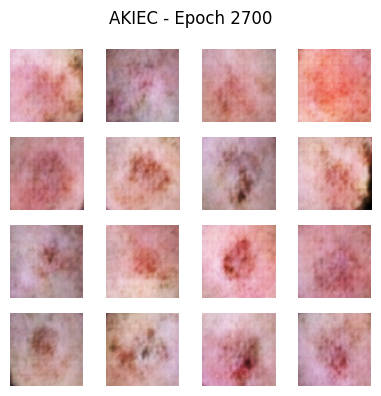

Epoch 2702 — G_loss: 0.7190, D_loss: 1.3763
Epoch 2703 — G_loss: 0.7335, D_loss: 1.3770
Epoch 2704 — G_loss: 0.7246, D_loss: 1.3677
Epoch 2705 — G_loss: 0.7104, D_loss: 1.3736
Epoch 2706 — G_loss: 0.7051, D_loss: 1.3748
Epoch 2707 — G_loss: 0.7416, D_loss: 1.3682
Epoch 2708 — G_loss: 0.6939, D_loss: 1.3709
Epoch 2709 — G_loss: 0.6759, D_loss: 1.3718
Epoch 2710 — G_loss: 0.7404, D_loss: 1.3700
Epoch 2711 — G_loss: 0.7238, D_loss: 1.3731
Epoch 2712 — G_loss: 0.6860, D_loss: 1.3737
Epoch 2713 — G_loss: 0.7083, D_loss: 1.3746
Epoch 2714 — G_loss: 0.7150, D_loss: 1.3517
Epoch 2715 — G_loss: 0.6994, D_loss: 1.3670
Epoch 2716 — G_loss: 0.7057, D_loss: 1.3656
Epoch 2717 — G_loss: 0.7074, D_loss: 1.3742
Epoch 2718 — G_loss: 0.7241, D_loss: 1.3603
Epoch 2719 — G_loss: 0.7161, D_loss: 1.3782
Epoch 2720 — G_loss: 0.7018, D_loss: 1.3656
Epoch 2721 — G_loss: 0.7124, D_loss: 1.3664
Epoch 2722 — G_loss: 0.7051, D_loss: 1.3629
Epoch 2723 — G_loss: 0.7197, D_loss: 1.3897
Epoch 2724 — G_loss: 0.6887, D_l

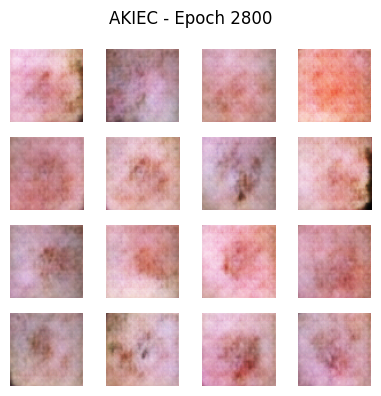

Epoch 2802 — G_loss: 0.6894, D_loss: 1.3568
Epoch 2803 — G_loss: 0.6941, D_loss: 1.3611
Epoch 2804 — G_loss: 0.7034, D_loss: 1.3699
Epoch 2805 — G_loss: 0.7562, D_loss: 1.3528
Epoch 2806 — G_loss: 0.7462, D_loss: 1.3760
Epoch 2807 — G_loss: 0.6787, D_loss: 1.3850
Epoch 2808 — G_loss: 0.7045, D_loss: 1.3672
Epoch 2809 — G_loss: 0.7183, D_loss: 1.3556
Epoch 2810 — G_loss: 0.7256, D_loss: 1.3683
Epoch 2811 — G_loss: 0.7213, D_loss: 1.4183
Epoch 2812 — G_loss: 0.7278, D_loss: 1.3403
Epoch 2813 — G_loss: 0.6997, D_loss: 1.4043
Epoch 2814 — G_loss: 0.6890, D_loss: 1.3942
Epoch 2815 — G_loss: 0.6897, D_loss: 1.3724
Epoch 2816 — G_loss: 0.7164, D_loss: 1.3309
Epoch 2817 — G_loss: 0.7199, D_loss: 1.3438
Epoch 2818 — G_loss: 0.7049, D_loss: 1.4165
Epoch 2819 — G_loss: 0.7592, D_loss: 1.3580
Epoch 2820 — G_loss: 0.7010, D_loss: 1.3404
Epoch 2821 — G_loss: 0.6852, D_loss: 1.3910
Epoch 2822 — G_loss: 0.7091, D_loss: 1.3758
Epoch 2823 — G_loss: 0.7167, D_loss: 1.3626
Epoch 2824 — G_loss: 0.7401, D_l

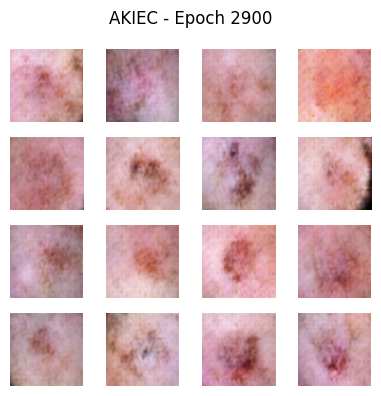

Epoch 2902 — G_loss: 0.6644, D_loss: 1.3609
Epoch 2903 — G_loss: 0.6805, D_loss: 1.3601
Epoch 2904 — G_loss: 0.7262, D_loss: 1.3690
Epoch 2905 — G_loss: 0.7316, D_loss: 1.3599
Epoch 2906 — G_loss: 0.6932, D_loss: 1.3636
Epoch 2907 — G_loss: 0.7095, D_loss: 1.3754
Epoch 2908 — G_loss: 0.7308, D_loss: 1.3645
Epoch 2909 — G_loss: 0.7137, D_loss: 1.3451
Epoch 2910 — G_loss: 0.7088, D_loss: 1.3628
Epoch 2911 — G_loss: 0.7289, D_loss: 1.3706
Epoch 2912 — G_loss: 0.6934, D_loss: 1.3609
Epoch 2913 — G_loss: 0.6778, D_loss: 1.3821
Epoch 2914 — G_loss: 0.7164, D_loss: 1.3702
Epoch 2915 — G_loss: 0.7361, D_loss: 1.3472
Epoch 2916 — G_loss: 0.7557, D_loss: 1.3678
Epoch 2917 — G_loss: 0.7535, D_loss: 1.3582
Epoch 2918 — G_loss: 0.6888, D_loss: 1.3915
Epoch 2919 — G_loss: 0.6973, D_loss: 1.3565
Epoch 2920 — G_loss: 0.7128, D_loss: 1.3316
Epoch 2921 — G_loss: 0.7243, D_loss: 1.3803
Epoch 2922 — G_loss: 0.7217, D_loss: 1.3746
Epoch 2923 — G_loss: 0.7218, D_loss: 1.3672
Epoch 2924 — G_loss: 0.7125, D_l

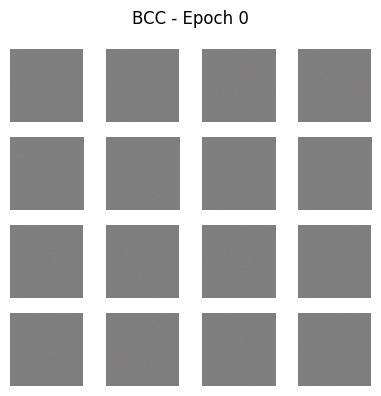

Epoch 2 — G_loss: 0.6767, D_loss: 1.0894
Epoch 3 — G_loss: 0.8255, D_loss: 0.8183
Epoch 4 — G_loss: 1.2175, D_loss: 0.5260
Epoch 5 — G_loss: 1.5738, D_loss: 0.4003
Epoch 6 — G_loss: 1.7211, D_loss: 0.3341
Epoch 7 — G_loss: 1.6450, D_loss: 0.4042
Epoch 8 — G_loss: 1.5147, D_loss: 0.4981
Epoch 9 — G_loss: 1.4190, D_loss: 0.7643
Epoch 10 — G_loss: 1.4258, D_loss: 0.7084
Epoch 11 — G_loss: 1.4087, D_loss: 0.6633
Epoch 12 — G_loss: 1.4337, D_loss: 0.7230
Epoch 13 — G_loss: 1.4077, D_loss: 0.8160
Epoch 14 — G_loss: 1.2871, D_loss: 0.9299
Epoch 15 — G_loss: 1.2888, D_loss: 0.9036
Epoch 16 — G_loss: 1.3107, D_loss: 0.8516
Epoch 17 — G_loss: 1.3602, D_loss: 0.7756
Epoch 18 — G_loss: 1.2121, D_loss: 0.9968
Epoch 19 — G_loss: 1.0747, D_loss: 1.1231
Epoch 20 — G_loss: 1.1320, D_loss: 1.1443
Epoch 21 — G_loss: 1.1353, D_loss: 1.0172
Epoch 22 — G_loss: 1.1869, D_loss: 1.0166
Epoch 23 — G_loss: 1.2332, D_loss: 0.8923
Epoch 24 — G_loss: 1.3245, D_loss: 0.8224
Epoch 25 — G_loss: 1.4278, D_loss: 0.8035


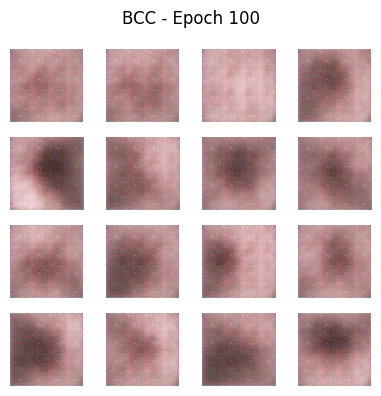

Epoch 102 — G_loss: 0.7186, D_loss: 1.3616
Epoch 103 — G_loss: 0.7391, D_loss: 1.3475
Epoch 104 — G_loss: 0.7099, D_loss: 1.3143
Epoch 105 — G_loss: 0.7357, D_loss: 1.3072
Epoch 106 — G_loss: 0.7395, D_loss: 1.3088
Epoch 107 — G_loss: 0.6998, D_loss: 1.3198
Epoch 108 — G_loss: 0.7432, D_loss: 1.2942
Epoch 109 — G_loss: 0.7325, D_loss: 1.3139
Epoch 110 — G_loss: 0.7217, D_loss: 1.2853
Epoch 111 — G_loss: 0.7409, D_loss: 1.3371
Epoch 112 — G_loss: 0.7238, D_loss: 1.3207
Epoch 113 — G_loss: 0.7290, D_loss: 1.3038
Epoch 114 — G_loss: 0.7427, D_loss: 1.2948
Epoch 115 — G_loss: 0.7584, D_loss: 1.2805
Epoch 116 — G_loss: 0.7744, D_loss: 1.2857
Epoch 117 — G_loss: 0.7583, D_loss: 1.3112
Epoch 118 — G_loss: 0.7378, D_loss: 1.3414
Epoch 119 — G_loss: 0.7547, D_loss: 1.3472
Epoch 120 — G_loss: 0.7628, D_loss: 1.3162
Epoch 121 — G_loss: 0.7578, D_loss: 1.3167
Epoch 122 — G_loss: 0.7421, D_loss: 1.3120
Epoch 123 — G_loss: 0.7732, D_loss: 1.2986
Epoch 124 — G_loss: 0.7718, D_loss: 1.2957
Epoch 125 —

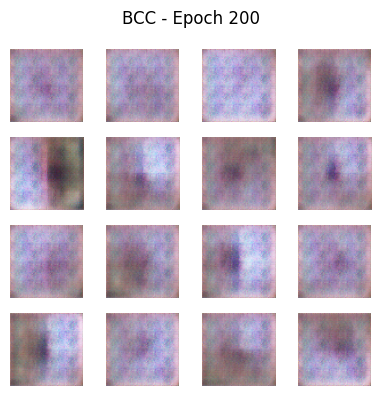

Epoch 202 — G_loss: 0.7118, D_loss: 1.4121
Epoch 203 — G_loss: 0.6918, D_loss: 1.4487
Epoch 204 — G_loss: 0.7098, D_loss: 1.4144
Epoch 205 — G_loss: 0.7236, D_loss: 1.4477
Epoch 206 — G_loss: 0.7266, D_loss: 1.3906
Epoch 207 — G_loss: 0.7339, D_loss: 1.3865
Epoch 208 — G_loss: 0.7223, D_loss: 1.3777
Epoch 209 — G_loss: 0.7364, D_loss: 1.3590
Epoch 210 — G_loss: 0.7509, D_loss: 1.3425
Epoch 211 — G_loss: 0.7476, D_loss: 1.3457
Epoch 212 — G_loss: 0.7495, D_loss: 1.2929
Epoch 213 — G_loss: 0.7781, D_loss: 1.2948
Epoch 214 — G_loss: 0.7730, D_loss: 1.2549
Epoch 215 — G_loss: 0.7988, D_loss: 1.2791
Epoch 216 — G_loss: 0.7767, D_loss: 1.2754
Epoch 217 — G_loss: 0.7833, D_loss: 1.2634
Epoch 218 — G_loss: 0.7627, D_loss: 1.2903
Epoch 219 — G_loss: 0.7129, D_loss: 1.3497
Epoch 220 — G_loss: 0.5971, D_loss: 1.6176
Epoch 221 — G_loss: 0.5988, D_loss: 1.6254
Epoch 222 — G_loss: 0.7165, D_loss: 1.3705
Epoch 223 — G_loss: 0.7681, D_loss: 1.3057
Epoch 224 — G_loss: 0.7353, D_loss: 1.3938
Epoch 225 —

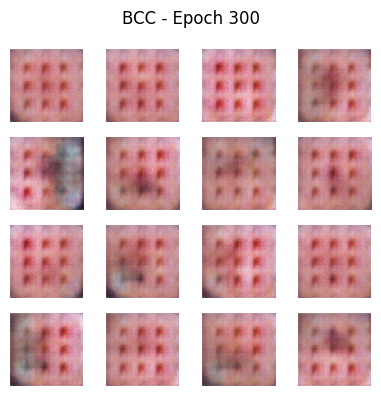

Epoch 302 — G_loss: 0.7141, D_loss: 1.2338
Epoch 303 — G_loss: 0.7688, D_loss: 1.2313
Epoch 304 — G_loss: 0.7858, D_loss: 1.2920
Epoch 305 — G_loss: 0.7896, D_loss: 1.2654
Epoch 306 — G_loss: 0.7176, D_loss: 1.2859
Epoch 307 — G_loss: 0.6399, D_loss: 1.4414
Epoch 308 — G_loss: 0.7793, D_loss: 1.4035
Epoch 309 — G_loss: 0.8417, D_loss: 1.2676
Epoch 310 — G_loss: 0.7357, D_loss: 1.3818
Epoch 311 — G_loss: 0.6895, D_loss: 1.4419
Epoch 312 — G_loss: 0.6886, D_loss: 1.3609
Epoch 313 — G_loss: 0.7465, D_loss: 1.3522
Epoch 314 — G_loss: 0.7541, D_loss: 1.3005
Epoch 315 — G_loss: 0.7043, D_loss: 1.3912
Epoch 316 — G_loss: 0.7289, D_loss: 1.3966
Epoch 317 — G_loss: 0.8370, D_loss: 1.1592
Epoch 318 — G_loss: 0.8006, D_loss: 1.4151
Epoch 319 — G_loss: 0.8354, D_loss: 1.3878
Epoch 320 — G_loss: 0.7131, D_loss: 1.3848
Epoch 321 — G_loss: 0.6308, D_loss: 1.4641
Epoch 322 — G_loss: 0.6936, D_loss: 1.2802
Epoch 323 — G_loss: 0.7253, D_loss: 1.3373
Epoch 324 — G_loss: 0.7522, D_loss: 1.4966
Epoch 325 —

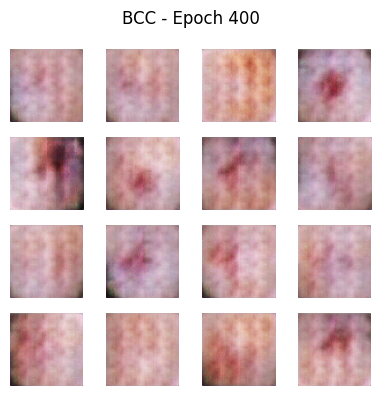

Epoch 402 — G_loss: 0.7006, D_loss: 1.3781
Epoch 403 — G_loss: 0.6945, D_loss: 1.3812
Epoch 404 — G_loss: 0.7116, D_loss: 1.3792
Epoch 405 — G_loss: 0.7233, D_loss: 1.3847
Epoch 406 — G_loss: 0.7153, D_loss: 1.3550
Epoch 407 — G_loss: 0.6934, D_loss: 1.3848
Epoch 408 — G_loss: 0.7034, D_loss: 1.3981
Epoch 409 — G_loss: 0.7108, D_loss: 1.3805
Epoch 410 — G_loss: 0.7230, D_loss: 1.3564
Epoch 411 — G_loss: 0.6961, D_loss: 1.3958
Epoch 412 — G_loss: 0.7065, D_loss: 1.4097
Epoch 413 — G_loss: 0.7031, D_loss: 1.3634
Epoch 414 — G_loss: 0.7044, D_loss: 1.3432
Epoch 415 — G_loss: 0.6925, D_loss: 1.3831
Epoch 416 — G_loss: 0.6965, D_loss: 1.3975
Epoch 417 — G_loss: 0.7218, D_loss: 1.3789
Epoch 418 — G_loss: 0.7212, D_loss: 1.3549
Epoch 419 — G_loss: 0.7022, D_loss: 1.3934
Epoch 420 — G_loss: 0.7336, D_loss: 1.4189
Epoch 421 — G_loss: 0.7139, D_loss: 1.3848
Epoch 422 — G_loss: 0.7144, D_loss: 1.3391
Epoch 423 — G_loss: 0.6791, D_loss: 1.3877
Epoch 424 — G_loss: 0.6773, D_loss: 1.4081
Epoch 425 —

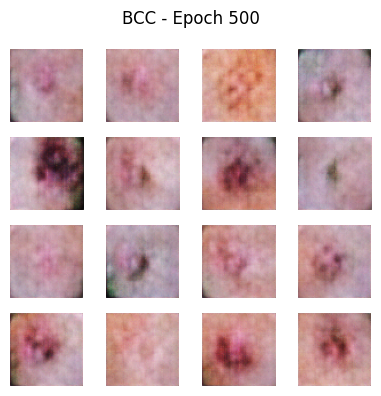

Epoch 502 — G_loss: 0.7087, D_loss: 1.3866
Epoch 503 — G_loss: 0.7080, D_loss: 1.3833
Epoch 504 — G_loss: 0.6879, D_loss: 1.3924
Epoch 505 — G_loss: 0.6797, D_loss: 1.3889
Epoch 506 — G_loss: 0.6809, D_loss: 1.3770
Epoch 507 — G_loss: 0.6889, D_loss: 1.3917
Epoch 508 — G_loss: 0.7137, D_loss: 1.3919
Epoch 509 — G_loss: 0.7102, D_loss: 1.3922
Epoch 510 — G_loss: 0.7138, D_loss: 1.3841
Epoch 511 — G_loss: 0.6741, D_loss: 1.3904
Epoch 512 — G_loss: 0.6553, D_loss: 1.3825
Epoch 513 — G_loss: 0.6800, D_loss: 1.3783
Epoch 514 — G_loss: 0.6980, D_loss: 1.3872
Epoch 515 — G_loss: 0.7164, D_loss: 1.3885
Epoch 516 — G_loss: 0.7250, D_loss: 1.3824
Epoch 517 — G_loss: 0.6811, D_loss: 1.3936
Epoch 518 — G_loss: 0.6865, D_loss: 1.3970
Epoch 519 — G_loss: 0.6884, D_loss: 1.3752
Epoch 520 — G_loss: 0.7041, D_loss: 1.3734
Epoch 521 — G_loss: 0.7031, D_loss: 1.3639
Epoch 522 — G_loss: 0.7237, D_loss: 1.3719
Epoch 523 — G_loss: 0.7053, D_loss: 1.3960
Epoch 524 — G_loss: 0.6853, D_loss: 1.3980
Epoch 525 —

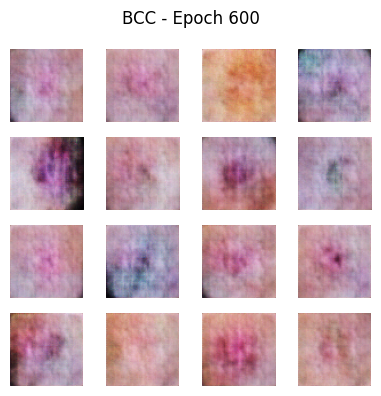

Epoch 602 — G_loss: 0.7016, D_loss: 1.3861
Epoch 603 — G_loss: 0.7006, D_loss: 1.3908
Epoch 604 — G_loss: 0.6953, D_loss: 1.3859
Epoch 605 — G_loss: 0.6978, D_loss: 1.3917
Epoch 606 — G_loss: 0.6848, D_loss: 1.3872
Epoch 607 — G_loss: 0.6891, D_loss: 1.3957
Epoch 608 — G_loss: 0.7016, D_loss: 1.3859
Epoch 609 — G_loss: 0.7012, D_loss: 1.3741
Epoch 610 — G_loss: 0.6993, D_loss: 1.3848
Epoch 611 — G_loss: 0.6772, D_loss: 1.3781
Epoch 612 — G_loss: 0.6949, D_loss: 1.3880
Epoch 613 — G_loss: 0.6631, D_loss: 1.3816
Epoch 614 — G_loss: 0.6665, D_loss: 1.3861
Epoch 615 — G_loss: 0.6926, D_loss: 1.4022
Epoch 616 — G_loss: 0.7194, D_loss: 1.3927
Epoch 617 — G_loss: 0.6744, D_loss: 1.3703
Epoch 618 — G_loss: 0.6587, D_loss: 1.3602
Epoch 619 — G_loss: 0.7116, D_loss: 1.3902
Epoch 620 — G_loss: 0.6987, D_loss: 1.4247
Epoch 621 — G_loss: 0.7326, D_loss: 1.3972
Epoch 622 — G_loss: 0.6909, D_loss: 1.3901
Epoch 623 — G_loss: 0.6921, D_loss: 1.3730
Epoch 624 — G_loss: 0.6854, D_loss: 1.3972
Epoch 625 —

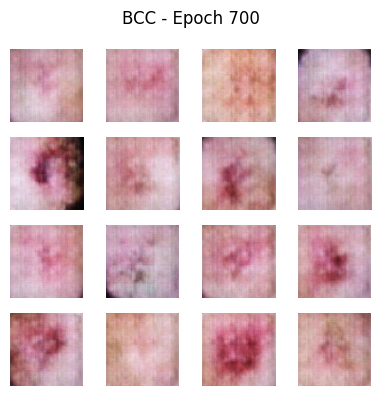

Epoch 702 — G_loss: 0.7330, D_loss: 1.4203
Epoch 703 — G_loss: 0.7123, D_loss: 1.3943
Epoch 704 — G_loss: 0.6910, D_loss: 1.3924
Epoch 705 — G_loss: 0.6681, D_loss: 1.3952
Epoch 706 — G_loss: 0.6808, D_loss: 1.3920
Epoch 707 — G_loss: 0.6860, D_loss: 1.3852
Epoch 708 — G_loss: 0.6966, D_loss: 1.3994
Epoch 709 — G_loss: 0.7212, D_loss: 1.3895
Epoch 710 — G_loss: 0.6895, D_loss: 1.3877
Epoch 711 — G_loss: 0.6989, D_loss: 1.3877
Epoch 712 — G_loss: 0.7259, D_loss: 1.3884
Epoch 713 — G_loss: 0.6661, D_loss: 1.3951
Epoch 714 — G_loss: 0.6709, D_loss: 1.3807
Epoch 715 — G_loss: 0.6632, D_loss: 1.3788
Epoch 716 — G_loss: 0.7218, D_loss: 1.3904
Epoch 717 — G_loss: 0.7066, D_loss: 1.4167
Epoch 718 — G_loss: 0.6907, D_loss: 1.3704
Epoch 719 — G_loss: 0.6594, D_loss: 1.3661
Epoch 720 — G_loss: 0.7058, D_loss: 1.3832
Epoch 721 — G_loss: 0.6840, D_loss: 1.3942
Epoch 722 — G_loss: 0.6724, D_loss: 1.3932
Epoch 723 — G_loss: 0.7050, D_loss: 1.3636
Epoch 724 — G_loss: 0.7132, D_loss: 1.3829
Epoch 725 —

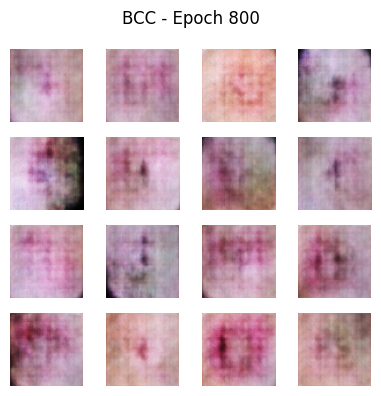

Epoch 802 — G_loss: 0.6803, D_loss: 1.3874
Epoch 803 — G_loss: 0.6818, D_loss: 1.3844
Epoch 804 — G_loss: 0.6815, D_loss: 1.3769
Epoch 805 — G_loss: 0.7053, D_loss: 1.3896
Epoch 806 — G_loss: 0.7103, D_loss: 1.3877
Epoch 807 — G_loss: 0.6815, D_loss: 1.3820
Epoch 808 — G_loss: 0.7033, D_loss: 1.3896
Epoch 809 — G_loss: 0.7083, D_loss: 1.3833
Epoch 810 — G_loss: 0.6881, D_loss: 1.3644
Epoch 811 — G_loss: 0.6727, D_loss: 1.3646
Epoch 812 — G_loss: 0.7135, D_loss: 1.4041
Epoch 813 — G_loss: 0.7298, D_loss: 1.3842
Epoch 814 — G_loss: 0.6925, D_loss: 1.3932
Epoch 815 — G_loss: 0.6975, D_loss: 1.3897
Epoch 816 — G_loss: 0.6954, D_loss: 1.3873
Epoch 817 — G_loss: 0.6876, D_loss: 1.3830
Epoch 818 — G_loss: 0.7186, D_loss: 1.3838
Epoch 819 — G_loss: 0.6980, D_loss: 1.3829
Epoch 820 — G_loss: 0.6718, D_loss: 1.3783
Epoch 821 — G_loss: 0.7135, D_loss: 1.4002
Epoch 822 — G_loss: 0.7367, D_loss: 1.3856
Epoch 823 — G_loss: 0.6885, D_loss: 1.3807
Epoch 824 — G_loss: 0.6940, D_loss: 1.3864
Epoch 825 —

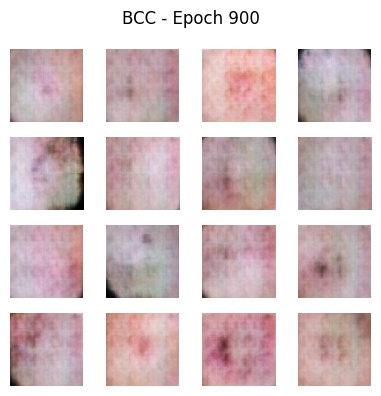

Epoch 902 — G_loss: 0.7188, D_loss: 1.3737
Epoch 903 — G_loss: 0.6764, D_loss: 1.4142
Epoch 904 — G_loss: 0.6884, D_loss: 1.3689
Epoch 905 — G_loss: 0.6667, D_loss: 1.3836
Epoch 906 — G_loss: 0.6652, D_loss: 1.3867
Epoch 907 — G_loss: 0.7217, D_loss: 1.3850
Epoch 908 — G_loss: 0.7304, D_loss: 1.3833
Epoch 909 — G_loss: 0.6947, D_loss: 1.3666
Epoch 910 — G_loss: 0.6475, D_loss: 1.3935
Epoch 911 — G_loss: 0.7033, D_loss: 1.3995
Epoch 912 — G_loss: 0.7177, D_loss: 1.3987
Epoch 913 — G_loss: 0.6902, D_loss: 1.3933
Epoch 914 — G_loss: 0.6975, D_loss: 1.3844
Epoch 915 — G_loss: 0.6853, D_loss: 1.3824
Epoch 916 — G_loss: 0.6991, D_loss: 1.3816
Epoch 917 — G_loss: 0.7086, D_loss: 1.3865
Epoch 918 — G_loss: 0.7142, D_loss: 1.3929
Epoch 919 — G_loss: 0.6702, D_loss: 1.3588
Epoch 920 — G_loss: 0.6973, D_loss: 1.3835
Epoch 921 — G_loss: 0.7070, D_loss: 1.3735
Epoch 922 — G_loss: 0.6952, D_loss: 1.3811
Epoch 923 — G_loss: 0.7376, D_loss: 1.3840
Epoch 924 — G_loss: 0.6954, D_loss: 1.3784
Epoch 925 —

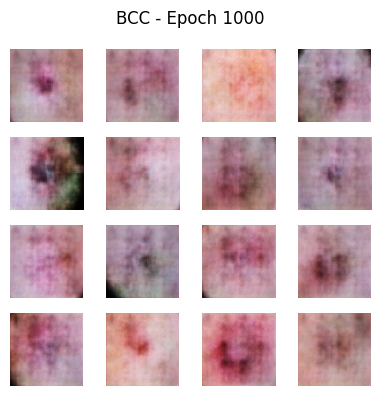

Epoch 1002 — G_loss: 0.7062, D_loss: 1.3919
Epoch 1003 — G_loss: 0.7175, D_loss: 1.3912
Epoch 1004 — G_loss: 0.7139, D_loss: 1.3895
Epoch 1005 — G_loss: 0.7018, D_loss: 1.3619
Epoch 1006 — G_loss: 0.6610, D_loss: 1.3971
Epoch 1007 — G_loss: 0.6897, D_loss: 1.3902
Epoch 1008 — G_loss: 0.7225, D_loss: 1.3731
Epoch 1009 — G_loss: 0.7327, D_loss: 1.4084
Epoch 1010 — G_loss: 0.6767, D_loss: 1.3750
Epoch 1011 — G_loss: 0.6655, D_loss: 1.3705
Epoch 1012 — G_loss: 0.6662, D_loss: 1.3976
Epoch 1013 — G_loss: 0.6857, D_loss: 1.4018
Epoch 1014 — G_loss: 0.7011, D_loss: 1.3808
Epoch 1015 — G_loss: 0.6971, D_loss: 1.3911
Epoch 1016 — G_loss: 0.6821, D_loss: 1.3617
Epoch 1017 — G_loss: 0.7273, D_loss: 1.3957
Epoch 1018 — G_loss: 0.6943, D_loss: 1.3949
Epoch 1019 — G_loss: 0.6764, D_loss: 1.3947
Epoch 1020 — G_loss: 0.6891, D_loss: 1.3893
Epoch 1021 — G_loss: 0.6882, D_loss: 1.3825
Epoch 1022 — G_loss: 0.7070, D_loss: 1.3875
Epoch 1023 — G_loss: 0.6827, D_loss: 1.3773
Epoch 1024 — G_loss: 0.6939, D_l

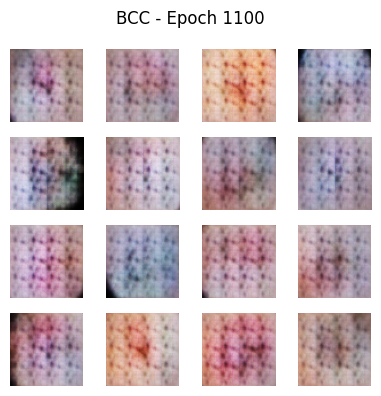

Epoch 1102 — G_loss: 0.6739, D_loss: 1.3592
Epoch 1103 — G_loss: 0.6693, D_loss: 1.3822
Epoch 1104 — G_loss: 0.6810, D_loss: 1.3960
Epoch 1105 — G_loss: 0.6693, D_loss: 1.4009
Epoch 1106 — G_loss: 0.7045, D_loss: 1.3813
Epoch 1107 — G_loss: 0.7071, D_loss: 1.3881
Epoch 1108 — G_loss: 0.7077, D_loss: 1.3937
Epoch 1109 — G_loss: 0.7168, D_loss: 1.3795
Epoch 1110 — G_loss: 0.7160, D_loss: 1.3802
Epoch 1111 — G_loss: 0.6736, D_loss: 1.3884
Epoch 1112 — G_loss: 0.6901, D_loss: 1.3941
Epoch 1113 — G_loss: 0.6840, D_loss: 1.3891
Epoch 1114 — G_loss: 0.6891, D_loss: 1.3700
Epoch 1115 — G_loss: 0.7353, D_loss: 1.3905
Epoch 1116 — G_loss: 0.6806, D_loss: 1.3813
Epoch 1117 — G_loss: 0.7158, D_loss: 1.3838
Epoch 1118 — G_loss: 0.6867, D_loss: 1.3824
Epoch 1119 — G_loss: 0.6834, D_loss: 1.3828
Epoch 1120 — G_loss: 0.6947, D_loss: 1.3921
Epoch 1121 — G_loss: 0.6965, D_loss: 1.3856
Epoch 1122 — G_loss: 0.6967, D_loss: 1.3930
Epoch 1123 — G_loss: 0.7169, D_loss: 1.3890
Epoch 1124 — G_loss: 0.6977, D_l

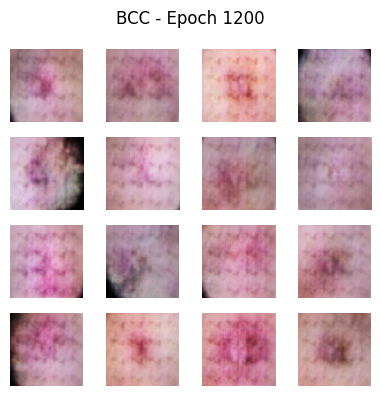

Epoch 1202 — G_loss: 0.6870, D_loss: 1.3690
Epoch 1203 — G_loss: 0.6820, D_loss: 1.3471
Epoch 1204 — G_loss: 0.7361, D_loss: 1.3937
Epoch 1205 — G_loss: 0.7076, D_loss: 1.3911
Epoch 1206 — G_loss: 0.7016, D_loss: 1.3861
Epoch 1207 — G_loss: 0.6935, D_loss: 1.3871
Epoch 1208 — G_loss: 0.6802, D_loss: 1.3761
Epoch 1209 — G_loss: 0.7260, D_loss: 1.3855
Epoch 1210 — G_loss: 0.7077, D_loss: 1.3841
Epoch 1211 — G_loss: 0.7009, D_loss: 1.3971
Epoch 1212 — G_loss: 0.6567, D_loss: 1.3623
Epoch 1213 — G_loss: 0.6815, D_loss: 1.3919
Epoch 1214 — G_loss: 0.6959, D_loss: 1.3930
Epoch 1215 — G_loss: 0.7270, D_loss: 1.3839
Epoch 1216 — G_loss: 0.7311, D_loss: 1.3226
Epoch 1217 — G_loss: 0.6983, D_loss: 1.4073
Epoch 1218 — G_loss: 0.6893, D_loss: 1.3929
Epoch 1219 — G_loss: 0.7002, D_loss: 1.3870
Epoch 1220 — G_loss: 0.7285, D_loss: 1.3878
Epoch 1221 — G_loss: 0.7114, D_loss: 1.3812
Epoch 1222 — G_loss: 0.6941, D_loss: 1.3837
Epoch 1223 — G_loss: 0.6741, D_loss: 1.3862
Epoch 1224 — G_loss: 0.6732, D_l

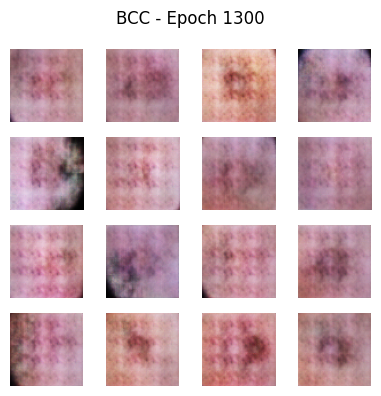

Epoch 1302 — G_loss: 0.6971, D_loss: 1.3718
Epoch 1303 — G_loss: 0.6903, D_loss: 1.3677
Epoch 1304 — G_loss: 0.7109, D_loss: 1.3794
Epoch 1305 — G_loss: 0.6987, D_loss: 1.4106
Epoch 1306 — G_loss: 0.7131, D_loss: 1.3596
Epoch 1307 — G_loss: 0.7270, D_loss: 1.3777
Epoch 1308 — G_loss: 0.7164, D_loss: 1.3948
Epoch 1309 — G_loss: 0.6736, D_loss: 1.3921
Epoch 1310 — G_loss: 0.6620, D_loss: 1.3728
Epoch 1311 — G_loss: 0.6974, D_loss: 1.3750
Epoch 1312 — G_loss: 0.7221, D_loss: 1.3956
Epoch 1313 — G_loss: 0.7078, D_loss: 1.3901
Epoch 1314 — G_loss: 0.7027, D_loss: 1.3858
Epoch 1315 — G_loss: 0.7012, D_loss: 1.3813
Epoch 1316 — G_loss: 0.6702, D_loss: 1.3997
Epoch 1317 — G_loss: 0.6603, D_loss: 1.3772
Epoch 1318 — G_loss: 0.6625, D_loss: 1.3703
Epoch 1319 — G_loss: 0.7308, D_loss: 1.4017
Epoch 1320 — G_loss: 0.7274, D_loss: 1.3945
Epoch 1321 — G_loss: 0.7263, D_loss: 1.3666
Epoch 1322 — G_loss: 0.7223, D_loss: 1.3786
Epoch 1323 — G_loss: 0.6664, D_loss: 1.3991
Epoch 1324 — G_loss: 0.6938, D_l

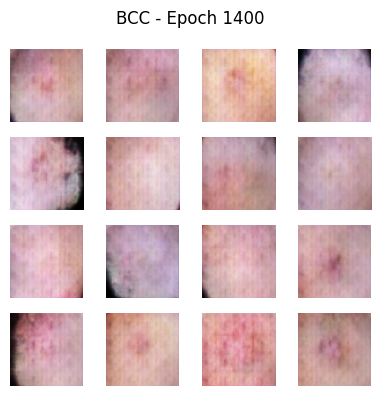

Epoch 1402 — G_loss: 0.7124, D_loss: 1.4034
Epoch 1403 — G_loss: 0.7038, D_loss: 1.4046
Epoch 1404 — G_loss: 0.6724, D_loss: 1.3701
Epoch 1405 — G_loss: 0.6763, D_loss: 1.3972
Epoch 1406 — G_loss: 0.6651, D_loss: 1.4110
Epoch 1407 — G_loss: 0.6773, D_loss: 1.3922
Epoch 1408 — G_loss: 0.6848, D_loss: 1.3918
Epoch 1409 — G_loss: 0.7155, D_loss: 1.3796
Epoch 1410 — G_loss: 0.7082, D_loss: 1.3728
Epoch 1411 — G_loss: 0.6705, D_loss: 1.3788
Epoch 1412 — G_loss: 0.6954, D_loss: 1.3808
Epoch 1413 — G_loss: 0.6977, D_loss: 1.3870
Epoch 1414 — G_loss: 0.7042, D_loss: 1.3905
Epoch 1415 — G_loss: 0.7200, D_loss: 1.3796
Epoch 1416 — G_loss: 0.6882, D_loss: 1.3826
Epoch 1417 — G_loss: 0.6949, D_loss: 1.3967
Epoch 1418 — G_loss: 0.7082, D_loss: 1.3753
Epoch 1419 — G_loss: 0.6775, D_loss: 1.3803
Epoch 1420 — G_loss: 0.7054, D_loss: 1.3700
Epoch 1421 — G_loss: 0.7501, D_loss: 1.3957
Epoch 1422 — G_loss: 0.7228, D_loss: 1.3740
Epoch 1423 — G_loss: 0.6919, D_loss: 1.3903
Epoch 1424 — G_loss: 0.6836, D_l

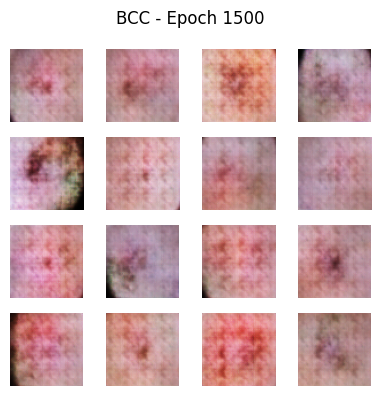

Epoch 1502 — G_loss: 0.7177, D_loss: 1.3824
Epoch 1503 — G_loss: 0.7132, D_loss: 1.3852
Epoch 1504 — G_loss: 0.6943, D_loss: 1.3840
Epoch 1505 — G_loss: 0.7075, D_loss: 1.3857
Epoch 1506 — G_loss: 0.6968, D_loss: 1.3799
Epoch 1507 — G_loss: 0.7018, D_loss: 1.3792
Epoch 1508 — G_loss: 0.7059, D_loss: 1.3780
Epoch 1509 — G_loss: 0.6823, D_loss: 1.3876
Epoch 1510 — G_loss: 0.7054, D_loss: 1.3904
Epoch 1511 — G_loss: 0.6940, D_loss: 1.3832
Epoch 1512 — G_loss: 0.6961, D_loss: 1.3880
Epoch 1513 — G_loss: 0.7035, D_loss: 1.3821
Epoch 1514 — G_loss: 0.7050, D_loss: 1.3929
Epoch 1515 — G_loss: 0.6877, D_loss: 1.3610
Epoch 1516 — G_loss: 0.7125, D_loss: 1.3859
Epoch 1517 — G_loss: 0.7130, D_loss: 1.3949
Epoch 1518 — G_loss: 0.7019, D_loss: 1.3776
Epoch 1519 — G_loss: 0.6965, D_loss: 1.3879
Epoch 1520 — G_loss: 0.6937, D_loss: 1.3828
Epoch 1521 — G_loss: 0.7329, D_loss: 1.3832
Epoch 1522 — G_loss: 0.6933, D_loss: 1.3819
Epoch 1523 — G_loss: 0.7118, D_loss: 1.3887
Epoch 1524 — G_loss: 0.6919, D_l

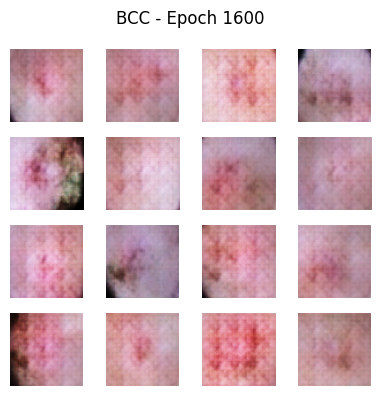

Epoch 1602 — G_loss: 0.7056, D_loss: 1.3829
Epoch 1603 — G_loss: 0.6941, D_loss: 1.3833
Epoch 1604 — G_loss: 0.6857, D_loss: 1.3821
Epoch 1605 — G_loss: 0.7071, D_loss: 1.3813
Epoch 1606 — G_loss: 0.7018, D_loss: 1.3824
Epoch 1607 — G_loss: 0.6907, D_loss: 1.3778
Epoch 1608 — G_loss: 0.7262, D_loss: 1.3910
Epoch 1609 — G_loss: 0.7040, D_loss: 1.3813
Epoch 1610 — G_loss: 0.6797, D_loss: 1.3856
Epoch 1611 — G_loss: 0.6848, D_loss: 1.3772
Epoch 1612 — G_loss: 0.7378, D_loss: 1.3856
Epoch 1613 — G_loss: 0.6918, D_loss: 1.3735
Epoch 1614 — G_loss: 0.6964, D_loss: 1.3571
Epoch 1615 — G_loss: 0.6829, D_loss: 1.4091
Epoch 1616 — G_loss: 0.7375, D_loss: 1.3558
Epoch 1617 — G_loss: 0.6860, D_loss: 1.4034
Epoch 1618 — G_loss: 0.7251, D_loss: 1.3790
Epoch 1619 — G_loss: 0.7353, D_loss: 1.3847
Epoch 1620 — G_loss: 0.6582, D_loss: 1.3706
Epoch 1621 — G_loss: 0.6816, D_loss: 1.3959
Epoch 1622 — G_loss: 0.6908, D_loss: 1.3868
Epoch 1623 — G_loss: 0.7300, D_loss: 1.3767
Epoch 1624 — G_loss: 0.7486, D_l

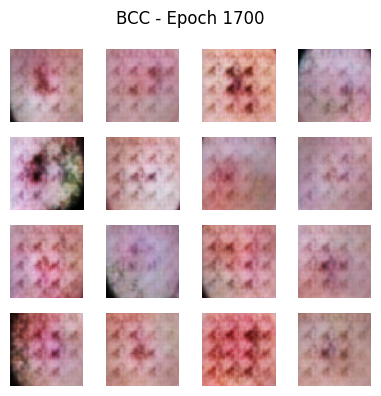

Epoch 1702 — G_loss: 0.7126, D_loss: 1.3834
Epoch 1703 — G_loss: 0.6849, D_loss: 1.3736
Epoch 1704 — G_loss: 0.6920, D_loss: 1.3836
Epoch 1705 — G_loss: 0.6991, D_loss: 1.3928
Epoch 1706 — G_loss: 0.7099, D_loss: 1.3895
Epoch 1707 — G_loss: 0.7186, D_loss: 1.3827
Epoch 1708 — G_loss: 0.6922, D_loss: 1.3782
Epoch 1709 — G_loss: 0.6984, D_loss: 1.3838
Epoch 1710 — G_loss: 0.6763, D_loss: 1.3837
Epoch 1711 — G_loss: 0.6844, D_loss: 1.3829
Epoch 1712 — G_loss: 0.7215, D_loss: 1.3855
Epoch 1713 — G_loss: 0.7108, D_loss: 1.3811
Epoch 1714 — G_loss: 0.6830, D_loss: 1.3798
Epoch 1715 — G_loss: 0.6821, D_loss: 1.3775
Epoch 1716 — G_loss: 0.6571, D_loss: 1.3879
Epoch 1717 — G_loss: 0.6931, D_loss: 1.3897
Epoch 1718 — G_loss: 0.6985, D_loss: 1.3809
Epoch 1719 — G_loss: 0.7229, D_loss: 1.3759
Epoch 1720 — G_loss: 0.7023, D_loss: 1.3912
Epoch 1721 — G_loss: 0.6822, D_loss: 1.3701
Epoch 1722 — G_loss: 0.6817, D_loss: 1.3954
Epoch 1723 — G_loss: 0.7113, D_loss: 1.3932
Epoch 1724 — G_loss: 0.7181, D_l

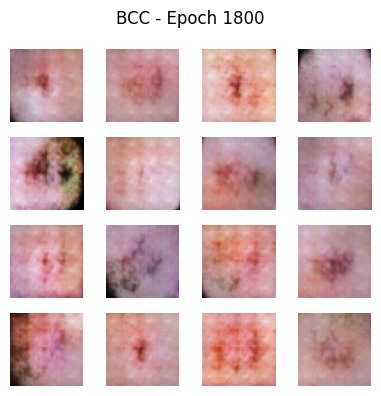

Epoch 1802 — G_loss: 0.7153, D_loss: 1.3883
Epoch 1803 — G_loss: 0.6767, D_loss: 1.3847
Epoch 1804 — G_loss: 0.6656, D_loss: 1.3892
Epoch 1805 — G_loss: 0.6941, D_loss: 1.3850
Epoch 1806 — G_loss: 0.7104, D_loss: 1.3817
Epoch 1807 — G_loss: 0.7081, D_loss: 1.3801
Epoch 1808 — G_loss: 0.7060, D_loss: 1.3809
Epoch 1809 — G_loss: 0.7119, D_loss: 1.3760
Epoch 1810 — G_loss: 0.7074, D_loss: 1.3814
Epoch 1811 — G_loss: 0.7151, D_loss: 1.3855
Epoch 1812 — G_loss: 0.7004, D_loss: 1.3847
Epoch 1813 — G_loss: 0.6912, D_loss: 1.3810
Epoch 1814 — G_loss: 0.6847, D_loss: 1.3847
Epoch 1815 — G_loss: 0.6853, D_loss: 1.3741
Epoch 1816 — G_loss: 0.7077, D_loss: 1.3831
Epoch 1817 — G_loss: 0.6941, D_loss: 1.3900
Epoch 1818 — G_loss: 0.7254, D_loss: 1.3868
Epoch 1819 — G_loss: 0.7093, D_loss: 1.3836
Epoch 1820 — G_loss: 0.7021, D_loss: 1.3836
Epoch 1821 — G_loss: 0.7082, D_loss: 1.3817
Epoch 1822 — G_loss: 0.6995, D_loss: 1.3812
Epoch 1823 — G_loss: 0.6967, D_loss: 1.3820
Epoch 1824 — G_loss: 0.6983, D_l

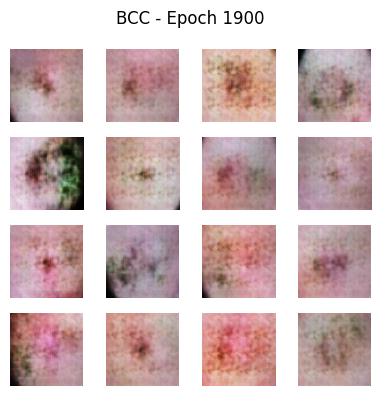

Epoch 1902 — G_loss: 0.6822, D_loss: 1.3822
Epoch 1903 — G_loss: 0.7160, D_loss: 1.3851
Epoch 1904 — G_loss: 0.7051, D_loss: 1.3812
Epoch 1905 — G_loss: 0.6888, D_loss: 1.3882
Epoch 1906 — G_loss: 0.7124, D_loss: 1.3860
Epoch 1907 — G_loss: 0.7130, D_loss: 1.3895
Epoch 1908 — G_loss: 0.7028, D_loss: 1.3916
Epoch 1909 — G_loss: 0.6833, D_loss: 1.3742
Epoch 1910 — G_loss: 0.6821, D_loss: 1.3791
Epoch 1911 — G_loss: 0.6864, D_loss: 1.3837
Epoch 1912 — G_loss: 0.6895, D_loss: 1.3876
Epoch 1913 — G_loss: 0.6995, D_loss: 1.3829
Epoch 1914 — G_loss: 0.6963, D_loss: 1.3814
Epoch 1915 — G_loss: 0.6895, D_loss: 1.3826
Epoch 1916 — G_loss: 0.6967, D_loss: 1.3720
Epoch 1917 — G_loss: 0.6625, D_loss: 1.3908
Epoch 1918 — G_loss: 0.7349, D_loss: 1.3862
Epoch 1919 — G_loss: 0.7125, D_loss: 1.3837
Epoch 1920 — G_loss: 0.7166, D_loss: 1.3760
Epoch 1921 — G_loss: 0.6813, D_loss: 1.3776
Epoch 1922 — G_loss: 0.7103, D_loss: 1.3886
Epoch 1923 — G_loss: 0.7059, D_loss: 1.3785
Epoch 1924 — G_loss: 0.7009, D_l

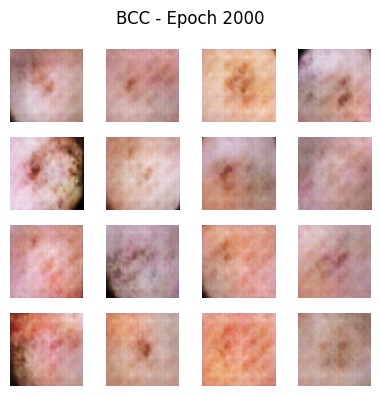

Epoch 2002 — G_loss: 0.7207, D_loss: 1.3947
Epoch 2003 — G_loss: 0.7128, D_loss: 1.3890
Epoch 2004 — G_loss: 0.7156, D_loss: 1.3859
Epoch 2005 — G_loss: 0.6967, D_loss: 1.3840
Epoch 2006 — G_loss: 0.7212, D_loss: 1.3873
Epoch 2007 — G_loss: 0.7174, D_loss: 1.3855
Epoch 2008 — G_loss: 0.7013, D_loss: 1.3821
Epoch 2009 — G_loss: 0.6668, D_loss: 1.3778
Epoch 2010 — G_loss: 0.7002, D_loss: 1.3729
Epoch 2011 — G_loss: 0.6927, D_loss: 1.3734
Epoch 2012 — G_loss: 0.7223, D_loss: 1.3797
Epoch 2013 — G_loss: 0.7036, D_loss: 1.3796
Epoch 2014 — G_loss: 0.6815, D_loss: 1.3782
Epoch 2015 — G_loss: 0.7097, D_loss: 1.3780
Epoch 2016 — G_loss: 0.6809, D_loss: 1.3862
Epoch 2017 — G_loss: 0.6908, D_loss: 1.3861
Epoch 2018 — G_loss: 0.7266, D_loss: 1.3764
Epoch 2019 — G_loss: 0.7117, D_loss: 1.3787
Epoch 2020 — G_loss: 0.7003, D_loss: 1.3825
Epoch 2021 — G_loss: 0.6605, D_loss: 1.3711
Epoch 2022 — G_loss: 0.6988, D_loss: 1.3749
Epoch 2023 — G_loss: 0.7409, D_loss: 1.3534
Epoch 2024 — G_loss: 0.6872, D_l

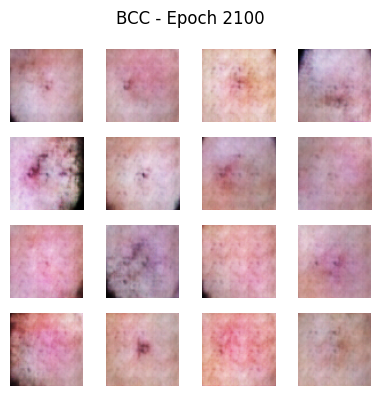

Epoch 2102 — G_loss: 0.6813, D_loss: 1.3756
Epoch 2103 — G_loss: 0.7201, D_loss: 1.3903
Epoch 2104 — G_loss: 0.7019, D_loss: 1.3762
Epoch 2105 — G_loss: 0.6856, D_loss: 1.3821
Epoch 2106 — G_loss: 0.6895, D_loss: 1.3746
Epoch 2107 — G_loss: 0.7070, D_loss: 1.3941
Epoch 2108 — G_loss: 0.7359, D_loss: 1.3618
Epoch 2109 — G_loss: 0.6857, D_loss: 1.3815
Epoch 2110 — G_loss: 0.6700, D_loss: 1.3845
Epoch 2111 — G_loss: 0.6972, D_loss: 1.3685
Epoch 2112 — G_loss: 0.7356, D_loss: 1.3889
Epoch 2113 — G_loss: 0.6795, D_loss: 1.3727
Epoch 2114 — G_loss: 0.6925, D_loss: 1.3771
Epoch 2115 — G_loss: 0.6999, D_loss: 1.3866
Epoch 2116 — G_loss: 0.6634, D_loss: 1.3731
Epoch 2117 — G_loss: 0.7117, D_loss: 1.3833
Epoch 2118 — G_loss: 0.7071, D_loss: 1.3764
Epoch 2119 — G_loss: 0.6778, D_loss: 1.3841
Epoch 2120 — G_loss: 0.6917, D_loss: 1.3838
Epoch 2121 — G_loss: 0.7358, D_loss: 1.3803
Epoch 2122 — G_loss: 0.7131, D_loss: 1.3881
Epoch 2123 — G_loss: 0.6780, D_loss: 1.3896
Epoch 2124 — G_loss: 0.6893, D_l

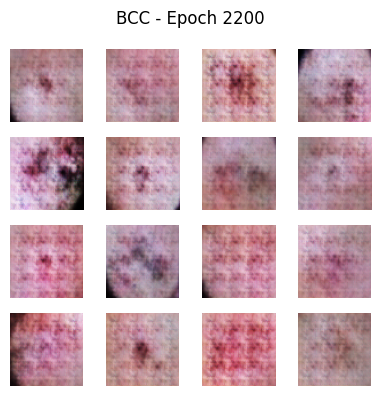

Epoch 2202 — G_loss: 0.6882, D_loss: 1.3669
Epoch 2203 — G_loss: 0.6787, D_loss: 1.3810
Epoch 2204 — G_loss: 0.7425, D_loss: 1.3725
Epoch 2205 — G_loss: 0.6897, D_loss: 1.3633
Epoch 2206 — G_loss: 0.7653, D_loss: 1.3967
Epoch 2207 — G_loss: 0.6467, D_loss: 1.3936
Epoch 2208 — G_loss: 0.6811, D_loss: 1.3767
Epoch 2209 — G_loss: 0.6988, D_loss: 1.3698
Epoch 2210 — G_loss: 0.7562, D_loss: 1.3939
Epoch 2211 — G_loss: 0.7011, D_loss: 1.3807
Epoch 2212 — G_loss: 0.6876, D_loss: 1.3723
Epoch 2213 — G_loss: 0.6876, D_loss: 1.3940
Epoch 2214 — G_loss: 0.7084, D_loss: 1.3851
Epoch 2215 — G_loss: 0.7200, D_loss: 1.3561
Epoch 2216 — G_loss: 0.7124, D_loss: 1.3876
Epoch 2217 — G_loss: 0.7218, D_loss: 1.3734
Epoch 2218 — G_loss: 0.6758, D_loss: 1.3779
Epoch 2219 — G_loss: 0.7336, D_loss: 1.3781
Epoch 2220 — G_loss: 0.6880, D_loss: 1.3758
Epoch 2221 — G_loss: 0.6729, D_loss: 1.3828
Epoch 2222 — G_loss: 0.7206, D_loss: 1.3794
Epoch 2223 — G_loss: 0.6911, D_loss: 1.3935
Epoch 2224 — G_loss: 0.7022, D_l

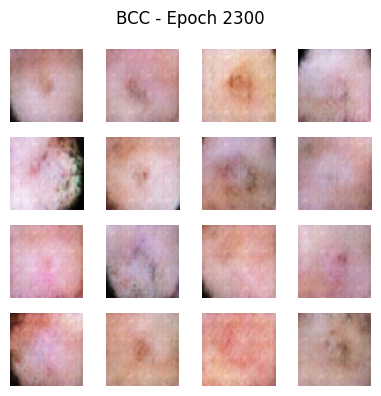

Epoch 2302 — G_loss: 0.7286, D_loss: 1.3670
Epoch 2303 — G_loss: 0.6882, D_loss: 1.3955
Epoch 2304 — G_loss: 0.7004, D_loss: 1.3849
Epoch 2305 — G_loss: 0.6916, D_loss: 1.3808
Epoch 2306 — G_loss: 0.6915, D_loss: 1.3743
Epoch 2307 — G_loss: 0.6613, D_loss: 1.3682
Epoch 2308 — G_loss: 0.7146, D_loss: 1.3851
Epoch 2309 — G_loss: 0.7069, D_loss: 1.3780
Epoch 2310 — G_loss: 0.7007, D_loss: 1.3803
Epoch 2311 — G_loss: 0.6992, D_loss: 1.3914
Epoch 2312 — G_loss: 0.7354, D_loss: 1.3856
Epoch 2313 — G_loss: 0.6679, D_loss: 1.3722
Epoch 2314 — G_loss: 0.6964, D_loss: 1.3638
Epoch 2315 — G_loss: 0.7036, D_loss: 1.4064
Epoch 2316 — G_loss: 0.7550, D_loss: 1.3634
Epoch 2317 — G_loss: 0.6595, D_loss: 1.3953
Epoch 2318 — G_loss: 0.6997, D_loss: 1.3834
Epoch 2319 — G_loss: 0.6864, D_loss: 1.3794
Epoch 2320 — G_loss: 0.6878, D_loss: 1.3925
Epoch 2321 — G_loss: 0.7133, D_loss: 1.3726
Epoch 2322 — G_loss: 0.7001, D_loss: 1.3854
Epoch 2323 — G_loss: 0.7292, D_loss: 1.3816
Epoch 2324 — G_loss: 0.7335, D_l

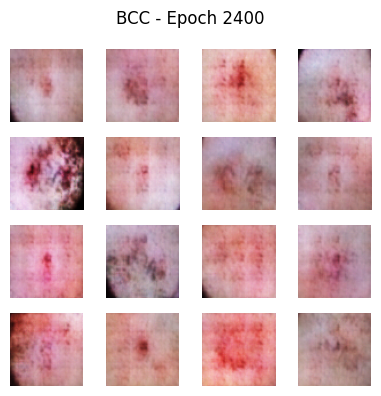

Epoch 2402 — G_loss: 0.6898, D_loss: 1.3801
Epoch 2403 — G_loss: 0.7033, D_loss: 1.3819
Epoch 2404 — G_loss: 0.7012, D_loss: 1.3794
Epoch 2405 — G_loss: 0.7215, D_loss: 1.3725
Epoch 2406 — G_loss: 0.6878, D_loss: 1.3837
Epoch 2407 — G_loss: 0.7126, D_loss: 1.3870
Epoch 2408 — G_loss: 0.7083, D_loss: 1.3821
Epoch 2409 — G_loss: 0.7074, D_loss: 1.3779
Epoch 2410 — G_loss: 0.7044, D_loss: 1.3899
Epoch 2411 — G_loss: 0.6712, D_loss: 1.3768
Epoch 2412 — G_loss: 0.6995, D_loss: 1.3754
Epoch 2413 — G_loss: 0.7087, D_loss: 1.3965
Epoch 2414 — G_loss: 0.6922, D_loss: 1.3610
Epoch 2415 — G_loss: 0.6767, D_loss: 1.3923
Epoch 2416 — G_loss: 0.7345, D_loss: 1.3829
Epoch 2417 — G_loss: 0.7025, D_loss: 1.3928
Epoch 2418 — G_loss: 0.6748, D_loss: 1.3744
Epoch 2419 — G_loss: 0.7068, D_loss: 1.3870
Epoch 2420 — G_loss: 0.7032, D_loss: 1.3782
Epoch 2421 — G_loss: 0.6764, D_loss: 1.3849
Epoch 2422 — G_loss: 0.6678, D_loss: 1.3601
Epoch 2423 — G_loss: 0.7275, D_loss: 1.3983
Epoch 2424 — G_loss: 0.7330, D_l

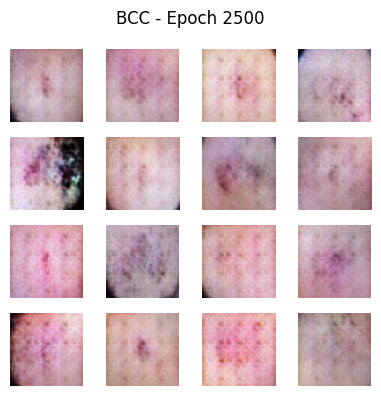

Epoch 2502 — G_loss: 0.7010, D_loss: 1.3974
Epoch 2503 — G_loss: 0.6535, D_loss: 1.3691
Epoch 2504 — G_loss: 0.6989, D_loss: 1.3807
Epoch 2505 — G_loss: 0.7414, D_loss: 1.3817
Epoch 2506 — G_loss: 0.6905, D_loss: 1.3844
Epoch 2507 — G_loss: 0.7177, D_loss: 1.3653
Epoch 2508 — G_loss: 0.7045, D_loss: 1.3892
Epoch 2509 — G_loss: 0.7074, D_loss: 1.3929
Epoch 2510 — G_loss: 0.6839, D_loss: 1.3878
Epoch 2511 — G_loss: 0.6805, D_loss: 1.3729
Epoch 2512 — G_loss: 0.7230, D_loss: 1.3744
Epoch 2513 — G_loss: 0.7180, D_loss: 1.3729
Epoch 2514 — G_loss: 0.7052, D_loss: 1.3841
Epoch 2515 — G_loss: 0.7027, D_loss: 1.3813
Epoch 2516 — G_loss: 0.6913, D_loss: 1.3843
Epoch 2517 — G_loss: 0.7037, D_loss: 1.3867
Epoch 2518 — G_loss: 0.7057, D_loss: 1.3720
Epoch 2519 — G_loss: 0.6934, D_loss: 1.3784
Epoch 2520 — G_loss: 0.7028, D_loss: 1.3867
Epoch 2521 — G_loss: 0.6824, D_loss: 1.3797
Epoch 2522 — G_loss: 0.6876, D_loss: 1.3856
Epoch 2523 — G_loss: 0.7139, D_loss: 1.3822
Epoch 2524 — G_loss: 0.6997, D_l

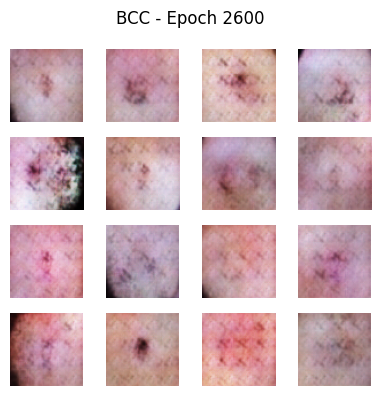

Epoch 2602 — G_loss: 0.7095, D_loss: 1.3705
Epoch 2603 — G_loss: 0.6970, D_loss: 1.3850
Epoch 2604 — G_loss: 0.7132, D_loss: 1.3809
Epoch 2605 — G_loss: 0.6983, D_loss: 1.3763
Epoch 2606 — G_loss: 0.6919, D_loss: 1.3790
Epoch 2607 — G_loss: 0.7066, D_loss: 1.3741
Epoch 2608 — G_loss: 0.7077, D_loss: 1.3850
Epoch 2609 — G_loss: 0.6838, D_loss: 1.3725
Epoch 2610 — G_loss: 0.6968, D_loss: 1.3889
Epoch 2611 — G_loss: 0.7036, D_loss: 1.3604
Epoch 2612 — G_loss: 0.7275, D_loss: 1.3811
Epoch 2613 — G_loss: 0.7066, D_loss: 1.3835
Epoch 2614 — G_loss: 0.6978, D_loss: 1.3824
Epoch 2615 — G_loss: 0.6868, D_loss: 1.3822
Epoch 2616 — G_loss: 0.6941, D_loss: 1.3719
Epoch 2617 — G_loss: 0.7596, D_loss: 1.3773
Epoch 2618 — G_loss: 0.6980, D_loss: 1.3836
Epoch 2619 — G_loss: 0.6714, D_loss: 1.3820
Epoch 2620 — G_loss: 0.6788, D_loss: 1.3884
Epoch 2621 — G_loss: 0.7159, D_loss: 1.3753
Epoch 2622 — G_loss: 0.6709, D_loss: 1.4052
Epoch 2623 — G_loss: 0.6851, D_loss: 1.3835
Epoch 2624 — G_loss: 0.7259, D_l

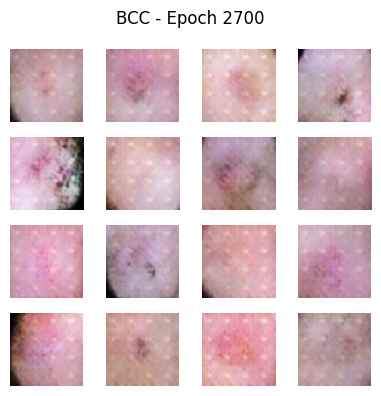

Epoch 2702 — G_loss: 0.6727, D_loss: 1.3885
Epoch 2703 — G_loss: 0.7190, D_loss: 1.3723
Epoch 2704 — G_loss: 0.6933, D_loss: 1.3833
Epoch 2705 — G_loss: 0.6848, D_loss: 1.4006
Epoch 2706 — G_loss: 0.6806, D_loss: 1.3937
Epoch 2707 — G_loss: 0.7104, D_loss: 1.3649
Epoch 2708 — G_loss: 0.6751, D_loss: 1.3936
Epoch 2709 — G_loss: 0.7107, D_loss: 1.3721
Epoch 2710 — G_loss: 0.6982, D_loss: 1.3854
Epoch 2711 — G_loss: 0.7274, D_loss: 1.3932
Epoch 2712 — G_loss: 0.6984, D_loss: 1.3783
Epoch 2713 — G_loss: 0.6942, D_loss: 1.3857
Epoch 2714 — G_loss: 0.7341, D_loss: 1.3843
Epoch 2715 — G_loss: 0.6916, D_loss: 1.3720
Epoch 2716 — G_loss: 0.6767, D_loss: 1.3728
Epoch 2717 — G_loss: 0.7239, D_loss: 1.3858
Epoch 2718 — G_loss: 0.7154, D_loss: 1.3811
Epoch 2719 — G_loss: 0.6935, D_loss: 1.3777
Epoch 2720 — G_loss: 0.7199, D_loss: 1.3838
Epoch 2721 — G_loss: 0.6712, D_loss: 1.3700
Epoch 2722 — G_loss: 0.6998, D_loss: 1.3863
Epoch 2723 — G_loss: 0.6941, D_loss: 1.3935
Epoch 2724 — G_loss: 0.6711, D_l

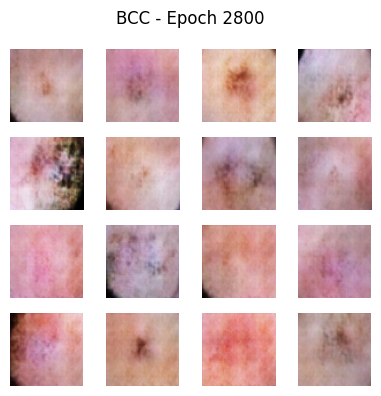

Epoch 2802 — G_loss: 0.7247, D_loss: 1.3794
Epoch 2803 — G_loss: 0.7037, D_loss: 1.3787
Epoch 2804 — G_loss: 0.6810, D_loss: 1.3921
Epoch 2805 — G_loss: 0.7069, D_loss: 1.3814
Epoch 2806 — G_loss: 0.6900, D_loss: 1.3858
Epoch 2807 — G_loss: 0.7174, D_loss: 1.3701
Epoch 2808 — G_loss: 0.7238, D_loss: 1.3829
Epoch 2809 — G_loss: 0.6982, D_loss: 1.3797
Epoch 2810 — G_loss: 0.6824, D_loss: 1.3775
Epoch 2811 — G_loss: 0.7070, D_loss: 1.3782
Epoch 2812 — G_loss: 0.6973, D_loss: 1.3810
Epoch 2813 — G_loss: 0.7066, D_loss: 1.3762
Epoch 2814 — G_loss: 0.6901, D_loss: 1.3802
Epoch 2815 — G_loss: 0.6632, D_loss: 1.3796
Epoch 2816 — G_loss: 0.7270, D_loss: 1.3822
Epoch 2817 — G_loss: 0.7139, D_loss: 1.3792
Epoch 2818 — G_loss: 0.7061, D_loss: 1.3746
Epoch 2819 — G_loss: 0.6927, D_loss: 1.3842
Epoch 2820 — G_loss: 0.6926, D_loss: 1.3842
Epoch 2821 — G_loss: 0.6873, D_loss: 1.3616
Epoch 2822 — G_loss: 0.7065, D_loss: 1.3933
Epoch 2823 — G_loss: 0.6695, D_loss: 1.3852
Epoch 2824 — G_loss: 0.7269, D_l

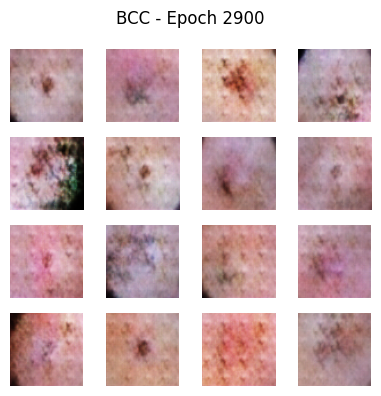

Epoch 2902 — G_loss: 0.6991, D_loss: 1.3860
Epoch 2903 — G_loss: 0.7059, D_loss: 1.3729
Epoch 2904 — G_loss: 0.6873, D_loss: 1.3889
Epoch 2905 — G_loss: 0.7025, D_loss: 1.3830
Epoch 2906 — G_loss: 0.6736, D_loss: 1.3738
Epoch 2907 — G_loss: 0.7308, D_loss: 1.3819
Epoch 2908 — G_loss: 0.7062, D_loss: 1.3847
Epoch 2909 — G_loss: 0.7043, D_loss: 1.3743
Epoch 2910 — G_loss: 0.6914, D_loss: 1.3933
Epoch 2911 — G_loss: 0.7059, D_loss: 1.3690
Epoch 2912 — G_loss: 0.6916, D_loss: 1.3843
Epoch 2913 — G_loss: 0.7045, D_loss: 1.3730
Epoch 2914 — G_loss: 0.6910, D_loss: 1.3740
Epoch 2915 — G_loss: 0.6962, D_loss: 1.3782
Epoch 2916 — G_loss: 0.7204, D_loss: 1.3958
Epoch 2917 — G_loss: 0.6923, D_loss: 1.3671
Epoch 2918 — G_loss: 0.6857, D_loss: 1.3891
Epoch 2919 — G_loss: 0.7037, D_loss: 1.3863
Epoch 2920 — G_loss: 0.7079, D_loss: 1.3791
Epoch 2921 — G_loss: 0.7041, D_loss: 1.3526
Epoch 2922 — G_loss: 0.7154, D_loss: 1.3933
Epoch 2923 — G_loss: 0.7049, D_loss: 1.3749
Epoch 2924 — G_loss: 0.6682, D_l

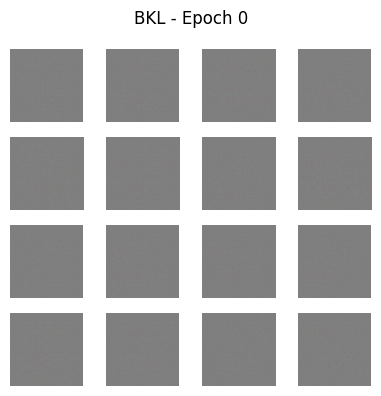

Epoch 2 — G_loss: 1.0770, D_loss: 0.7162
Epoch 3 — G_loss: 1.3448, D_loss: 0.5711
Epoch 4 — G_loss: 1.3708, D_loss: 0.6332
Epoch 5 — G_loss: 1.4963, D_loss: 0.6379
Epoch 6 — G_loss: 1.5578, D_loss: 0.6792
Epoch 7 — G_loss: 1.4860, D_loss: 0.7483
Epoch 8 — G_loss: 1.6716, D_loss: 0.6170
Epoch 9 — G_loss: 1.9044, D_loss: 0.4685
Epoch 10 — G_loss: 1.9851, D_loss: 0.4320
Epoch 11 — G_loss: 2.0985, D_loss: 0.3973
Epoch 12 — G_loss: 1.8995, D_loss: 0.6086
Epoch 13 — G_loss: 1.9347, D_loss: 0.5117
Epoch 14 — G_loss: 1.6023, D_loss: 0.8511
Epoch 15 — G_loss: 0.9751, D_loss: 1.5179
Epoch 16 — G_loss: 0.8184, D_loss: 1.5522
Epoch 17 — G_loss: 0.7686, D_loss: 1.5141
Epoch 18 — G_loss: 0.7050, D_loss: 1.4896
Epoch 19 — G_loss: 0.6963, D_loss: 1.4321
Epoch 20 — G_loss: 0.7199, D_loss: 1.3964
Epoch 21 — G_loss: 0.7603, D_loss: 1.2853
Epoch 22 — G_loss: 0.7702, D_loss: 1.2701
Epoch 23 — G_loss: 0.7717, D_loss: 1.2633
Epoch 24 — G_loss: 0.8001, D_loss: 1.2356
Epoch 25 — G_loss: 0.7885, D_loss: 1.2583


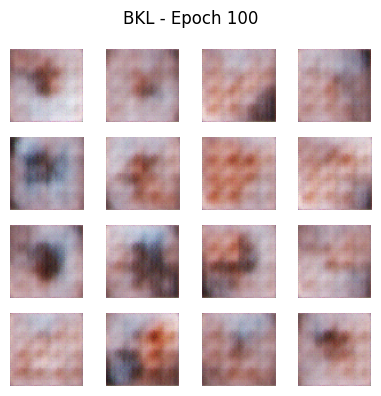

Epoch 102 — G_loss: 0.7443, D_loss: 1.3634
Epoch 103 — G_loss: 0.7624, D_loss: 1.3308
Epoch 104 — G_loss: 0.7172, D_loss: 1.3845
Epoch 105 — G_loss: 0.7247, D_loss: 1.3376
Epoch 106 — G_loss: 0.7762, D_loss: 1.3230
Epoch 107 — G_loss: 0.7364, D_loss: 1.3718
Epoch 108 — G_loss: 0.7357, D_loss: 1.3115
Epoch 109 — G_loss: 0.7067, D_loss: 1.4045
Epoch 110 — G_loss: 0.7545, D_loss: 1.3331
Epoch 111 — G_loss: 0.7279, D_loss: 1.3218
Epoch 112 — G_loss: 0.7184, D_loss: 1.4023
Epoch 113 — G_loss: 0.7667, D_loss: 1.3387
Epoch 114 — G_loss: 0.7332, D_loss: 1.3465
Epoch 115 — G_loss: 0.7103, D_loss: 1.3570
Epoch 116 — G_loss: 0.7557, D_loss: 1.3266
Epoch 117 — G_loss: 0.7197, D_loss: 1.3654
Epoch 118 — G_loss: 0.7294, D_loss: 1.3329
Epoch 119 — G_loss: 0.7596, D_loss: 1.3349
Epoch 120 — G_loss: 0.7330, D_loss: 1.3648
Epoch 121 — G_loss: 0.7326, D_loss: 1.3176
Epoch 122 — G_loss: 0.7486, D_loss: 1.3667
Epoch 123 — G_loss: 0.7637, D_loss: 1.3475
Epoch 124 — G_loss: 0.7317, D_loss: 1.2991
Epoch 125 —

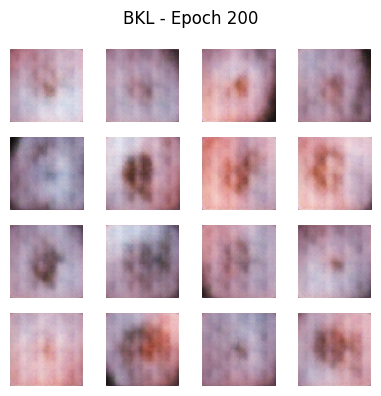

Epoch 202 — G_loss: 0.7495, D_loss: 1.3548
Epoch 203 — G_loss: 0.7112, D_loss: 1.3481
Epoch 204 — G_loss: 0.7442, D_loss: 1.3164
Epoch 205 — G_loss: 0.7579, D_loss: 1.3562
Epoch 206 — G_loss: 0.7045, D_loss: 1.3596
Epoch 207 — G_loss: 0.7310, D_loss: 1.3505
Epoch 208 — G_loss: 0.7493, D_loss: 1.3282
Epoch 209 — G_loss: 0.6937, D_loss: 1.3018
Epoch 210 — G_loss: 0.8290, D_loss: 1.3466
Epoch 211 — G_loss: 0.7211, D_loss: 1.3760
Epoch 212 — G_loss: 0.7440, D_loss: 1.2440
Epoch 213 — G_loss: 0.8339, D_loss: 1.3959
Epoch 214 — G_loss: 0.7953, D_loss: 1.3644
Epoch 215 — G_loss: 0.7384, D_loss: 1.3587
Epoch 216 — G_loss: 0.6822, D_loss: 1.3963
Epoch 217 — G_loss: 0.7846, D_loss: 1.3283
Epoch 218 — G_loss: 0.7479, D_loss: 1.4125
Epoch 219 — G_loss: 0.7305, D_loss: 1.3213
Epoch 220 — G_loss: 0.6762, D_loss: 1.3937
Epoch 221 — G_loss: 0.7787, D_loss: 1.3781
Epoch 222 — G_loss: 0.7240, D_loss: 1.3767
Epoch 223 — G_loss: 0.7059, D_loss: 1.3888
Epoch 224 — G_loss: 0.6770, D_loss: 1.3482
Epoch 225 —

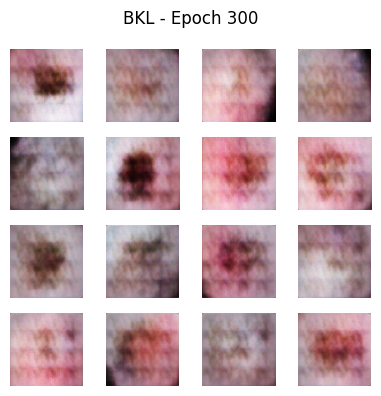

Epoch 302 — G_loss: 0.6732, D_loss: 1.3586
Epoch 303 — G_loss: 0.7135, D_loss: 1.3534
Epoch 304 — G_loss: 0.6913, D_loss: 1.3437
Epoch 305 — G_loss: 0.7086, D_loss: 1.3909
Epoch 306 — G_loss: 0.7129, D_loss: 1.3897
Epoch 307 — G_loss: 0.7152, D_loss: 1.3764
Epoch 308 — G_loss: 0.7333, D_loss: 1.3627
Epoch 309 — G_loss: 0.7233, D_loss: 1.3847
Epoch 310 — G_loss: 0.6822, D_loss: 1.3831
Epoch 311 — G_loss: 0.7024, D_loss: 1.3784
Epoch 312 — G_loss: 0.6822, D_loss: 1.3772
Epoch 313 — G_loss: 0.7021, D_loss: 1.3932
Epoch 314 — G_loss: 0.7136, D_loss: 1.3735
Epoch 315 — G_loss: 0.7021, D_loss: 1.3599
Epoch 316 — G_loss: 0.7190, D_loss: 1.3829
Epoch 317 — G_loss: 0.6766, D_loss: 1.3561
Epoch 318 — G_loss: 0.7539, D_loss: 1.3719
Epoch 319 — G_loss: 0.6716, D_loss: 1.3727
Epoch 320 — G_loss: 0.7609, D_loss: 1.3826
Epoch 321 — G_loss: 0.6940, D_loss: 1.3294
Epoch 322 — G_loss: 0.8051, D_loss: 1.3910
Epoch 323 — G_loss: 0.6586, D_loss: 1.3926
Epoch 324 — G_loss: 0.7584, D_loss: 1.3825
Epoch 325 —

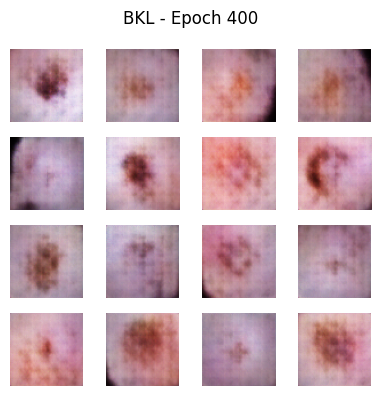

Epoch 402 — G_loss: 0.7093, D_loss: 1.3977
Epoch 403 — G_loss: 0.7066, D_loss: 1.3789
Epoch 404 — G_loss: 0.7105, D_loss: 1.3696
Epoch 405 — G_loss: 0.6901, D_loss: 1.3830
Epoch 406 — G_loss: 0.7028, D_loss: 1.3865
Epoch 407 — G_loss: 0.7094, D_loss: 1.3794
Epoch 408 — G_loss: 0.6977, D_loss: 1.3729
Epoch 409 — G_loss: 0.6790, D_loss: 1.3411
Epoch 410 — G_loss: 0.7030, D_loss: 1.4199
Epoch 411 — G_loss: 0.6890, D_loss: 1.3959
Epoch 412 — G_loss: 0.6905, D_loss: 1.3850
Epoch 413 — G_loss: 0.7070, D_loss: 1.3827
Epoch 414 — G_loss: 0.7109, D_loss: 1.3825
Epoch 415 — G_loss: 0.7276, D_loss: 1.3575
Epoch 416 — G_loss: 0.6878, D_loss: 1.3869
Epoch 417 — G_loss: 0.6980, D_loss: 1.3962
Epoch 418 — G_loss: 0.7088, D_loss: 1.3851
Epoch 419 — G_loss: 0.6903, D_loss: 1.3860
Epoch 420 — G_loss: 0.7227, D_loss: 1.3780
Epoch 421 — G_loss: 0.6754, D_loss: 1.3719
Epoch 422 — G_loss: 0.7291, D_loss: 1.3805
Epoch 423 — G_loss: 0.6916, D_loss: 1.3790
Epoch 424 — G_loss: 0.7082, D_loss: 1.3812
Epoch 425 —

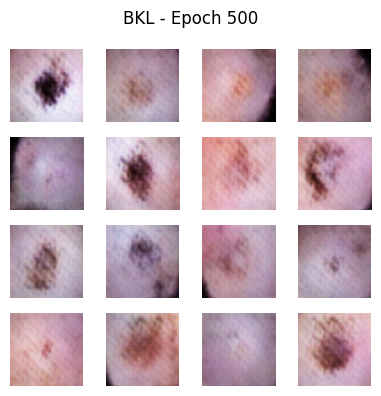

Epoch 502 — G_loss: 0.7214, D_loss: 1.3847
Epoch 503 — G_loss: 0.6993, D_loss: 1.3775
Epoch 504 — G_loss: 0.7171, D_loss: 1.3795
Epoch 505 — G_loss: 0.7023, D_loss: 1.3778
Epoch 506 — G_loss: 0.6886, D_loss: 1.3879
Epoch 507 — G_loss: 0.7093, D_loss: 1.3901
Epoch 508 — G_loss: 0.7025, D_loss: 1.3898
Epoch 509 — G_loss: 0.6868, D_loss: 1.3756
Epoch 510 — G_loss: 0.6942, D_loss: 1.3712
Epoch 511 — G_loss: 0.7056, D_loss: 1.3895
Epoch 512 — G_loss: 0.7081, D_loss: 1.3793
Epoch 513 — G_loss: 0.6737, D_loss: 1.3793
Epoch 514 — G_loss: 0.7309, D_loss: 1.3833
Epoch 515 — G_loss: 0.7016, D_loss: 1.3866
Epoch 516 — G_loss: 0.7148, D_loss: 1.3834
Epoch 517 — G_loss: 0.7036, D_loss: 1.3799
Epoch 518 — G_loss: 0.6730, D_loss: 1.3738
Epoch 519 — G_loss: 0.7035, D_loss: 1.3877
Epoch 520 — G_loss: 0.6910, D_loss: 1.3879
Epoch 521 — G_loss: 0.6938, D_loss: 1.3833
Epoch 522 — G_loss: 0.7250, D_loss: 1.3730
Epoch 523 — G_loss: 0.7060, D_loss: 1.3865
Epoch 524 — G_loss: 0.6946, D_loss: 1.3900
Epoch 525 —

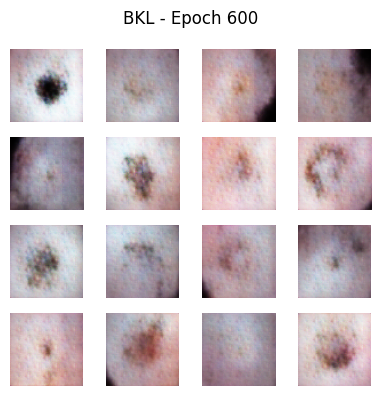

Epoch 602 — G_loss: 0.6770, D_loss: 1.3693
Epoch 603 — G_loss: 0.7255, D_loss: 1.3902
Epoch 604 — G_loss: 0.6696, D_loss: 1.3675
Epoch 605 — G_loss: 0.7592, D_loss: 1.3779
Epoch 606 — G_loss: 0.6712, D_loss: 1.3913
Epoch 607 — G_loss: 0.7076, D_loss: 1.3761
Epoch 608 — G_loss: 0.7166, D_loss: 1.3820
Epoch 609 — G_loss: 0.7205, D_loss: 1.3772
Epoch 610 — G_loss: 0.6750, D_loss: 1.3712
Epoch 611 — G_loss: 0.7152, D_loss: 1.3754
Epoch 612 — G_loss: 0.6786, D_loss: 1.3888
Epoch 613 — G_loss: 0.7221, D_loss: 1.3921
Epoch 614 — G_loss: 0.6848, D_loss: 1.3779
Epoch 615 — G_loss: 0.7407, D_loss: 1.3810
Epoch 616 — G_loss: 0.6714, D_loss: 1.3985
Epoch 617 — G_loss: 0.7345, D_loss: 1.3819
Epoch 618 — G_loss: 0.7022, D_loss: 1.3865
Epoch 619 — G_loss: 0.7041, D_loss: 1.3715
Epoch 620 — G_loss: 0.6838, D_loss: 1.3872
Epoch 621 — G_loss: 0.7135, D_loss: 1.3779
Epoch 622 — G_loss: 0.7046, D_loss: 1.3875
Epoch 623 — G_loss: 0.6989, D_loss: 1.3888
Epoch 624 — G_loss: 0.7113, D_loss: 1.3823
Epoch 625 —

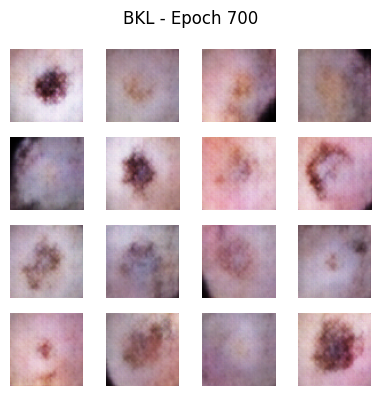

Epoch 702 — G_loss: 0.6720, D_loss: 1.3810
Epoch 703 — G_loss: 0.7146, D_loss: 1.3862
Epoch 704 — G_loss: 0.7000, D_loss: 1.3839
Epoch 705 — G_loss: 0.6913, D_loss: 1.3871
Epoch 706 — G_loss: 0.7176, D_loss: 1.3802
Epoch 707 — G_loss: 0.6901, D_loss: 1.3842
Epoch 708 — G_loss: 0.6827, D_loss: 1.3829
Epoch 709 — G_loss: 0.7213, D_loss: 1.3764
Epoch 710 — G_loss: 0.6897, D_loss: 1.3830
Epoch 711 — G_loss: 0.6794, D_loss: 1.3870
Epoch 712 — G_loss: 0.7223, D_loss: 1.3793
Epoch 713 — G_loss: 0.6962, D_loss: 1.3852
Epoch 714 — G_loss: 0.6865, D_loss: 1.3863
Epoch 715 — G_loss: 0.7084, D_loss: 1.3788
Epoch 716 — G_loss: 0.6979, D_loss: 1.3888
Epoch 717 — G_loss: 0.7006, D_loss: 1.3821
Epoch 718 — G_loss: 0.6924, D_loss: 1.3838
Epoch 719 — G_loss: 0.6949, D_loss: 1.3833
Epoch 720 — G_loss: 0.7068, D_loss: 1.3855
Epoch 721 — G_loss: 0.6973, D_loss: 1.3879
Epoch 722 — G_loss: 0.6793, D_loss: 1.3793
Epoch 723 — G_loss: 0.7033, D_loss: 1.3828
Epoch 724 — G_loss: 0.7098, D_loss: 1.3793
Epoch 725 —

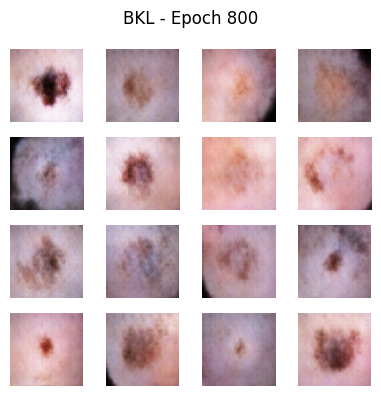

Epoch 802 — G_loss: 0.6923, D_loss: 1.3721
Epoch 803 — G_loss: 0.6877, D_loss: 1.3789
Epoch 804 — G_loss: 0.7173, D_loss: 1.3913
Epoch 805 — G_loss: 0.6864, D_loss: 1.3957
Epoch 806 — G_loss: 0.6996, D_loss: 1.3820
Epoch 807 — G_loss: 0.6861, D_loss: 1.3855
Epoch 808 — G_loss: 0.7230, D_loss: 1.3758
Epoch 809 — G_loss: 0.7015, D_loss: 1.3840
Epoch 810 — G_loss: 0.7272, D_loss: 1.3686
Epoch 811 — G_loss: 0.6763, D_loss: 1.3844
Epoch 812 — G_loss: 0.7140, D_loss: 1.3771
Epoch 813 — G_loss: 0.7113, D_loss: 1.3751
Epoch 814 — G_loss: 0.7116, D_loss: 1.3582
Epoch 815 — G_loss: 0.6929, D_loss: 1.3818
Epoch 816 — G_loss: 0.7048, D_loss: 1.3864
Epoch 817 — G_loss: 0.7015, D_loss: 1.3736
Epoch 818 — G_loss: 0.6912, D_loss: 1.3924
Epoch 819 — G_loss: 0.7046, D_loss: 1.3872
Epoch 820 — G_loss: 0.7265, D_loss: 1.3818
Epoch 821 — G_loss: 0.7013, D_loss: 1.3887
Epoch 822 — G_loss: 0.6953, D_loss: 1.3772
Epoch 823 — G_loss: 0.6845, D_loss: 1.3707
Epoch 824 — G_loss: 0.6997, D_loss: 1.3874
Epoch 825 —

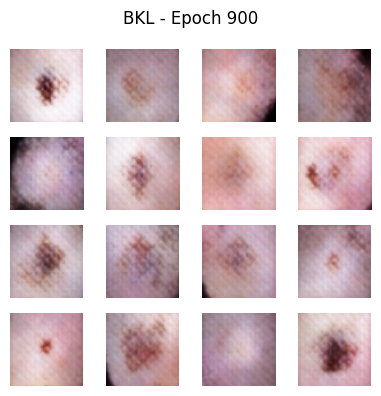

Epoch 902 — G_loss: 0.6883, D_loss: 1.3805
Epoch 903 — G_loss: 0.6915, D_loss: 1.3831
Epoch 904 — G_loss: 0.7192, D_loss: 1.3772
Epoch 905 — G_loss: 0.7027, D_loss: 1.3761
Epoch 906 — G_loss: 0.7022, D_loss: 1.3784
Epoch 907 — G_loss: 0.6844, D_loss: 1.3853
Epoch 908 — G_loss: 0.7088, D_loss: 1.3756
Epoch 909 — G_loss: 0.6919, D_loss: 1.3839
Epoch 910 — G_loss: 0.6952, D_loss: 1.3819
Epoch 911 — G_loss: 0.6989, D_loss: 1.3781
Epoch 912 — G_loss: 0.7128, D_loss: 1.3825
Epoch 913 — G_loss: 0.6894, D_loss: 1.3826
Epoch 914 — G_loss: 0.6978, D_loss: 1.3838
Epoch 915 — G_loss: 0.6890, D_loss: 1.3776
Epoch 916 — G_loss: 0.7359, D_loss: 1.3714
Epoch 917 — G_loss: 0.6801, D_loss: 1.3767
Epoch 918 — G_loss: 0.7138, D_loss: 1.3889
Epoch 919 — G_loss: 0.6677, D_loss: 1.3733
Epoch 920 — G_loss: 0.7188, D_loss: 1.3785
Epoch 921 — G_loss: 0.7348, D_loss: 1.3766
Epoch 922 — G_loss: 0.7036, D_loss: 1.3774
Epoch 923 — G_loss: 0.6774, D_loss: 1.3852
Epoch 924 — G_loss: 0.7080, D_loss: 1.3846
Epoch 925 —

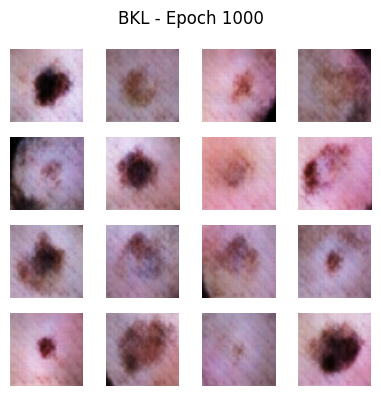

Epoch 1002 — G_loss: 0.6948, D_loss: 1.3772
Epoch 1003 — G_loss: 0.7194, D_loss: 1.3780
Epoch 1004 — G_loss: 0.7206, D_loss: 1.3759
Epoch 1005 — G_loss: 0.6776, D_loss: 1.3759
Epoch 1006 — G_loss: 0.7194, D_loss: 1.3797
Epoch 1007 — G_loss: 0.6988, D_loss: 1.3860
Epoch 1008 — G_loss: 0.7215, D_loss: 1.3814
Epoch 1009 — G_loss: 0.6957, D_loss: 1.3748
Epoch 1010 — G_loss: 0.6839, D_loss: 1.3801
Epoch 1011 — G_loss: 0.7277, D_loss: 1.3871
Epoch 1012 — G_loss: 0.7017, D_loss: 1.3831
Epoch 1013 — G_loss: 0.6938, D_loss: 1.3776
Epoch 1014 — G_loss: 0.6912, D_loss: 1.3761
Epoch 1015 — G_loss: 0.7159, D_loss: 1.3823
Epoch 1016 — G_loss: 0.6935, D_loss: 1.3792
Epoch 1017 — G_loss: 0.6877, D_loss: 1.3775
Epoch 1018 — G_loss: 0.7112, D_loss: 1.3852
Epoch 1019 — G_loss: 0.7096, D_loss: 1.3790
Epoch 1020 — G_loss: 0.6817, D_loss: 1.3780
Epoch 1021 — G_loss: 0.7196, D_loss: 1.3774
Epoch 1022 — G_loss: 0.6979, D_loss: 1.3815
Epoch 1023 — G_loss: 0.7023, D_loss: 1.3753
Epoch 1024 — G_loss: 0.6959, D_l

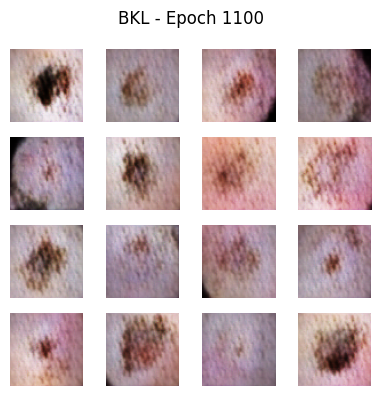

Epoch 1102 — G_loss: 0.6949, D_loss: 1.3836
Epoch 1103 — G_loss: 0.7135, D_loss: 1.3756
Epoch 1104 — G_loss: 0.7002, D_loss: 1.3732
Epoch 1105 — G_loss: 0.7043, D_loss: 1.3803
Epoch 1106 — G_loss: 0.6914, D_loss: 1.3762
Epoch 1107 — G_loss: 0.7106, D_loss: 1.3805
Epoch 1108 — G_loss: 0.6966, D_loss: 1.3955
Epoch 1109 — G_loss: 0.7026, D_loss: 1.3726
Epoch 1110 — G_loss: 0.7089, D_loss: 1.3819
Epoch 1111 — G_loss: 0.7259, D_loss: 1.3565
Epoch 1112 — G_loss: 0.6853, D_loss: 1.3851
Epoch 1113 — G_loss: 0.7052, D_loss: 1.3805
Epoch 1114 — G_loss: 0.7091, D_loss: 1.3767
Epoch 1115 — G_loss: 0.6835, D_loss: 1.3734
Epoch 1116 — G_loss: 0.7150, D_loss: 1.3920
Epoch 1117 — G_loss: 0.7145, D_loss: 1.3794
Epoch 1118 — G_loss: 0.7001, D_loss: 1.3812
Epoch 1119 — G_loss: 0.7060, D_loss: 1.3790
Epoch 1120 — G_loss: 0.7035, D_loss: 1.3733
Epoch 1121 — G_loss: 0.7164, D_loss: 1.3837
Epoch 1122 — G_loss: 0.6783, D_loss: 1.3732
Epoch 1123 — G_loss: 0.7173, D_loss: 1.3765
Epoch 1124 — G_loss: 0.7264, D_l

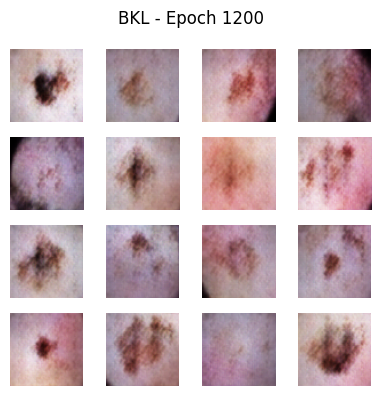

Epoch 1202 — G_loss: 0.7022, D_loss: 1.3752
Epoch 1203 — G_loss: 0.6977, D_loss: 1.3777
Epoch 1204 — G_loss: 0.7042, D_loss: 1.3739
Epoch 1205 — G_loss: 0.6998, D_loss: 1.3777
Epoch 1206 — G_loss: 0.6936, D_loss: 1.3762
Epoch 1207 — G_loss: 0.7095, D_loss: 1.3850
Epoch 1208 — G_loss: 0.7032, D_loss: 1.3783
Epoch 1209 — G_loss: 0.7035, D_loss: 1.3821
Epoch 1210 — G_loss: 0.6790, D_loss: 1.3808
Epoch 1211 — G_loss: 0.7240, D_loss: 1.3820
Epoch 1212 — G_loss: 0.7167, D_loss: 1.3722
Epoch 1213 — G_loss: 0.6828, D_loss: 1.3745
Epoch 1214 — G_loss: 0.7115, D_loss: 1.3822
Epoch 1215 — G_loss: 0.7083, D_loss: 1.3795
Epoch 1216 — G_loss: 0.7023, D_loss: 1.3828
Epoch 1217 — G_loss: 0.7085, D_loss: 1.3726
Epoch 1218 — G_loss: 0.6898, D_loss: 1.3764
Epoch 1219 — G_loss: 0.7073, D_loss: 1.3828
Epoch 1220 — G_loss: 0.7083, D_loss: 1.3729
Epoch 1221 — G_loss: 0.6943, D_loss: 1.3845
Epoch 1222 — G_loss: 0.6992, D_loss: 1.3735
Epoch 1223 — G_loss: 0.7095, D_loss: 1.3815
Epoch 1224 — G_loss: 0.6935, D_l

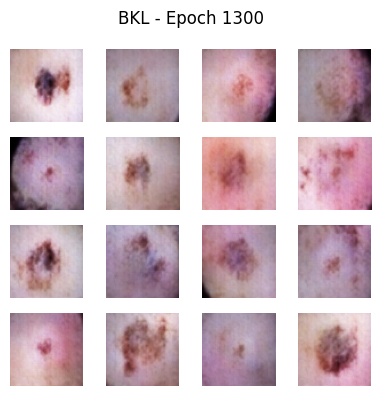

Epoch 1302 — G_loss: 0.7062, D_loss: 1.3780
Epoch 1303 — G_loss: 0.6876, D_loss: 1.3789
Epoch 1304 — G_loss: 0.7148, D_loss: 1.3803
Epoch 1305 — G_loss: 0.6985, D_loss: 1.3708
Epoch 1306 — G_loss: 0.6959, D_loss: 1.3725
Epoch 1307 — G_loss: 0.7130, D_loss: 1.3808
Epoch 1308 — G_loss: 0.7092, D_loss: 1.3801
Epoch 1309 — G_loss: 0.6920, D_loss: 1.3676
Epoch 1310 — G_loss: 0.7186, D_loss: 1.3844
Epoch 1311 — G_loss: 0.6923, D_loss: 1.3827
Epoch 1312 — G_loss: 0.6894, D_loss: 1.3599
Epoch 1313 — G_loss: 0.7117, D_loss: 1.3955
Epoch 1314 — G_loss: 0.7231, D_loss: 1.3764
Epoch 1315 — G_loss: 0.7051, D_loss: 1.3797
Epoch 1316 — G_loss: 0.6925, D_loss: 1.3744
Epoch 1317 — G_loss: 0.7261, D_loss: 1.3717
Epoch 1318 — G_loss: 0.6992, D_loss: 1.3740
Epoch 1319 — G_loss: 0.6761, D_loss: 1.3779
Epoch 1320 — G_loss: 0.7239, D_loss: 1.3838
Epoch 1321 — G_loss: 0.7179, D_loss: 1.3835
Epoch 1322 — G_loss: 0.6848, D_loss: 1.3727
Epoch 1323 — G_loss: 0.7167, D_loss: 1.3742
Epoch 1324 — G_loss: 0.6940, D_l

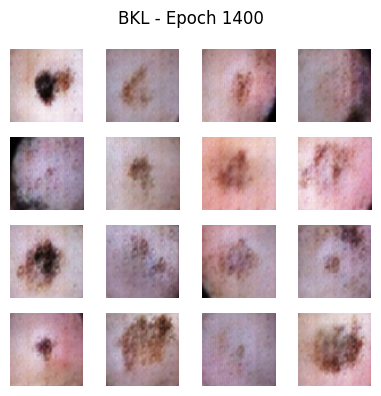

Epoch 1402 — G_loss: 0.6992, D_loss: 1.3874
Epoch 1403 — G_loss: 0.7136, D_loss: 1.3800
Epoch 1404 — G_loss: 0.6945, D_loss: 1.3765
Epoch 1405 — G_loss: 0.7120, D_loss: 1.3627
Epoch 1406 — G_loss: 0.7054, D_loss: 1.3840
Epoch 1407 — G_loss: 0.7173, D_loss: 1.3900
Epoch 1408 — G_loss: 0.7040, D_loss: 1.3683
Epoch 1409 — G_loss: 0.7074, D_loss: 1.3766
Epoch 1410 — G_loss: 0.6662, D_loss: 1.3760
Epoch 1411 — G_loss: 0.7103, D_loss: 1.3837
Epoch 1412 — G_loss: 0.7191, D_loss: 1.3836
Epoch 1413 — G_loss: 0.6790, D_loss: 1.3698
Epoch 1414 — G_loss: 0.7240, D_loss: 1.3715
Epoch 1415 — G_loss: 0.6943, D_loss: 1.3701
Epoch 1416 — G_loss: 0.7107, D_loss: 1.3795
Epoch 1417 — G_loss: 0.7085, D_loss: 1.3897
Epoch 1418 — G_loss: 0.6906, D_loss: 1.3634
Epoch 1419 — G_loss: 0.7112, D_loss: 1.3944
Epoch 1420 — G_loss: 0.7130, D_loss: 1.3769
Epoch 1421 — G_loss: 0.7088, D_loss: 1.3719
Epoch 1422 — G_loss: 0.6957, D_loss: 1.3723
Epoch 1423 — G_loss: 0.7206, D_loss: 1.3711
Epoch 1424 — G_loss: 0.7130, D_l

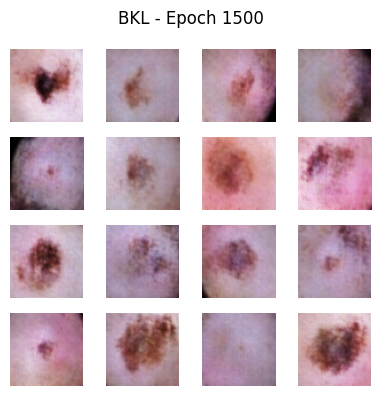

Epoch 1502 — G_loss: 0.7014, D_loss: 1.3742
Epoch 1503 — G_loss: 0.7080, D_loss: 1.3844
Epoch 1504 — G_loss: 0.7063, D_loss: 1.3808
Epoch 1505 — G_loss: 0.6956, D_loss: 1.3768
Epoch 1506 — G_loss: 0.7151, D_loss: 1.3744
Epoch 1507 — G_loss: 0.6936, D_loss: 1.3742
Epoch 1508 — G_loss: 0.7092, D_loss: 1.3786
Epoch 1509 — G_loss: 0.7171, D_loss: 1.3759
Epoch 1510 — G_loss: 0.7090, D_loss: 1.3744
Epoch 1511 — G_loss: 0.7007, D_loss: 1.3821
Epoch 1512 — G_loss: 0.6949, D_loss: 1.3780
Epoch 1513 — G_loss: 0.7133, D_loss: 1.3796
Epoch 1514 — G_loss: 0.6967, D_loss: 1.3709
Epoch 1515 — G_loss: 0.7053, D_loss: 1.3808
Epoch 1516 — G_loss: 0.6989, D_loss: 1.3788
Epoch 1517 — G_loss: 0.7017, D_loss: 1.3686
Epoch 1518 — G_loss: 0.7278, D_loss: 1.3855
Epoch 1519 — G_loss: 0.7047, D_loss: 1.3782
Epoch 1520 — G_loss: 0.7039, D_loss: 1.3726
Epoch 1521 — G_loss: 0.6963, D_loss: 1.3724
Epoch 1522 — G_loss: 0.6967, D_loss: 1.3856
Epoch 1523 — G_loss: 0.6963, D_loss: 1.3774
Epoch 1524 — G_loss: 0.7118, D_l

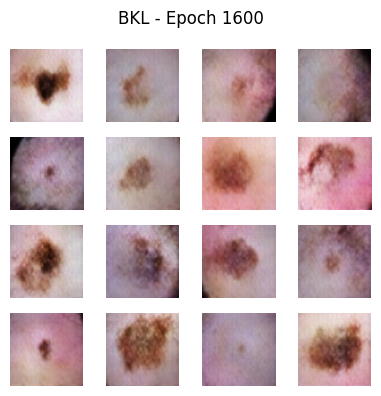

Epoch 1602 — G_loss: 0.7233, D_loss: 1.3856
Epoch 1603 — G_loss: 0.7098, D_loss: 1.3777
Epoch 1604 — G_loss: 0.6927, D_loss: 1.3720
Epoch 1605 — G_loss: 0.7200, D_loss: 1.3769
Epoch 1606 — G_loss: 0.7170, D_loss: 1.3758
Epoch 1607 — G_loss: 0.6858, D_loss: 1.3738
Epoch 1608 — G_loss: 0.7161, D_loss: 1.3784
Epoch 1609 — G_loss: 0.7054, D_loss: 1.3740
Epoch 1610 — G_loss: 0.6870, D_loss: 1.3728
Epoch 1611 — G_loss: 0.7219, D_loss: 1.3843
Epoch 1612 — G_loss: 0.7057, D_loss: 1.3675
Epoch 1613 — G_loss: 0.6995, D_loss: 1.3745
Epoch 1614 — G_loss: 0.7108, D_loss: 1.3843
Epoch 1615 — G_loss: 0.7067, D_loss: 1.3725
Epoch 1616 — G_loss: 0.6968, D_loss: 1.3731
Epoch 1617 — G_loss: 0.7082, D_loss: 1.3778
Epoch 1618 — G_loss: 0.7044, D_loss: 1.3786
Epoch 1619 — G_loss: 0.7194, D_loss: 1.3670
Epoch 1620 — G_loss: 0.6989, D_loss: 1.3779
Epoch 1621 — G_loss: 0.7179, D_loss: 1.3703
Epoch 1622 — G_loss: 0.7105, D_loss: 1.3676
Epoch 1623 — G_loss: 0.6983, D_loss: 1.3795
Epoch 1624 — G_loss: 0.7062, D_l

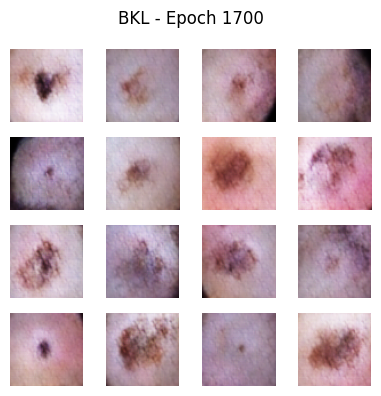

Epoch 1702 — G_loss: 0.6962, D_loss: 1.3693
Epoch 1703 — G_loss: 0.7075, D_loss: 1.3788
Epoch 1704 — G_loss: 0.7105, D_loss: 1.3775
Epoch 1705 — G_loss: 0.7107, D_loss: 1.3663
Epoch 1706 — G_loss: 0.7146, D_loss: 1.3777
Epoch 1707 — G_loss: 0.6942, D_loss: 1.3677
Epoch 1708 — G_loss: 0.7359, D_loss: 1.3630
Epoch 1709 — G_loss: 0.6793, D_loss: 1.3805
Epoch 1710 — G_loss: 0.7180, D_loss: 1.3784
Epoch 1711 — G_loss: 0.7336, D_loss: 1.3578
Epoch 1712 — G_loss: 0.6909, D_loss: 1.3810
Epoch 1713 — G_loss: 0.7149, D_loss: 1.3702
Epoch 1714 — G_loss: 0.7015, D_loss: 1.3800
Epoch 1715 — G_loss: 0.7126, D_loss: 1.3718
Epoch 1716 — G_loss: 0.7075, D_loss: 1.3729
Epoch 1717 — G_loss: 0.7100, D_loss: 1.3718
Epoch 1718 — G_loss: 0.7083, D_loss: 1.3752
Epoch 1719 — G_loss: 0.6904, D_loss: 1.3690
Epoch 1720 — G_loss: 0.7150, D_loss: 1.3792
Epoch 1721 — G_loss: 0.7099, D_loss: 1.3727
Epoch 1722 — G_loss: 0.6886, D_loss: 1.3792
Epoch 1723 — G_loss: 0.7073, D_loss: 1.3642
Epoch 1724 — G_loss: 0.7252, D_l

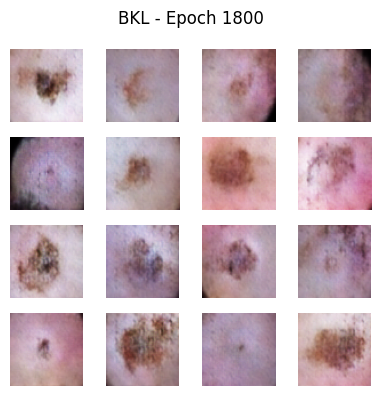

Epoch 1802 — G_loss: 0.6954, D_loss: 1.3597
Epoch 1803 — G_loss: 0.7155, D_loss: 1.3748
Epoch 1804 — G_loss: 0.7218, D_loss: 1.3765
Epoch 1805 — G_loss: 0.7018, D_loss: 1.3730
Epoch 1806 — G_loss: 0.7123, D_loss: 1.3634
Epoch 1807 — G_loss: 0.7122, D_loss: 1.3777
Epoch 1808 — G_loss: 0.7106, D_loss: 1.3705
Epoch 1809 — G_loss: 0.7080, D_loss: 1.3874
Epoch 1810 — G_loss: 0.7014, D_loss: 1.3781
Epoch 1811 — G_loss: 0.7060, D_loss: 1.3707
Epoch 1812 — G_loss: 0.7182, D_loss: 1.3717
Epoch 1813 — G_loss: 0.7077, D_loss: 1.3765
Epoch 1814 — G_loss: 0.7036, D_loss: 1.3660
Epoch 1815 — G_loss: 0.7262, D_loss: 1.3775
Epoch 1816 — G_loss: 0.6871, D_loss: 1.3835
Epoch 1817 — G_loss: 0.7114, D_loss: 1.3686
Epoch 1818 — G_loss: 0.7183, D_loss: 1.3625
Epoch 1819 — G_loss: 0.7072, D_loss: 1.3689
Epoch 1820 — G_loss: 0.6922, D_loss: 1.3727
Epoch 1821 — G_loss: 0.7315, D_loss: 1.3675
Epoch 1822 — G_loss: 0.6961, D_loss: 1.3705
Epoch 1823 — G_loss: 0.7037, D_loss: 1.3754
Epoch 1824 — G_loss: 0.7205, D_l

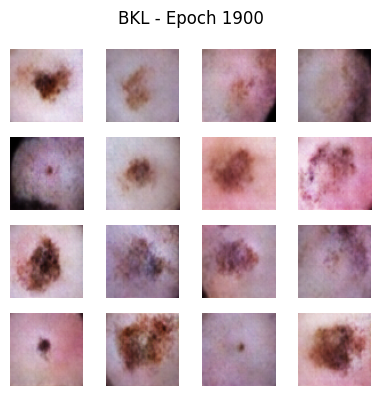

Epoch 1902 — G_loss: 0.7071, D_loss: 1.3792
Epoch 1903 — G_loss: 0.7074, D_loss: 1.3719
Epoch 1904 — G_loss: 0.7179, D_loss: 1.3731
Epoch 1905 — G_loss: 0.7031, D_loss: 1.3741
Epoch 1906 — G_loss: 0.7202, D_loss: 1.3704
Epoch 1907 — G_loss: 0.7034, D_loss: 1.3729
Epoch 1908 — G_loss: 0.7066, D_loss: 1.3731
Epoch 1909 — G_loss: 0.6884, D_loss: 1.3660
Epoch 1910 — G_loss: 0.7306, D_loss: 1.3827
Epoch 1911 — G_loss: 0.7140, D_loss: 1.3675
Epoch 1912 — G_loss: 0.6938, D_loss: 1.3815
Epoch 1913 — G_loss: 0.7010, D_loss: 1.3777
Epoch 1914 — G_loss: 0.7268, D_loss: 1.3729
Epoch 1915 — G_loss: 0.7063, D_loss: 1.3718
Epoch 1916 — G_loss: 0.6942, D_loss: 1.3734
Epoch 1917 — G_loss: 0.7183, D_loss: 1.3665
Epoch 1918 — G_loss: 0.7131, D_loss: 1.3724
Epoch 1919 — G_loss: 0.6905, D_loss: 1.3669
Epoch 1920 — G_loss: 0.7281, D_loss: 1.3743
Epoch 1921 — G_loss: 0.7041, D_loss: 1.3618
Epoch 1922 — G_loss: 0.7058, D_loss: 1.3767
Epoch 1923 — G_loss: 0.7105, D_loss: 1.3799
Epoch 1924 — G_loss: 0.7071, D_l

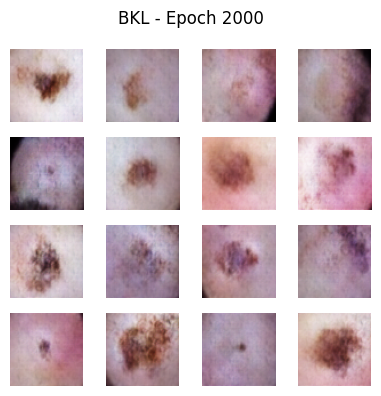

Epoch 2002 — G_loss: 0.7099, D_loss: 1.3742
Epoch 2003 — G_loss: 0.7022, D_loss: 1.3701
Epoch 2004 — G_loss: 0.7105, D_loss: 1.3828
Epoch 2005 — G_loss: 0.6967, D_loss: 1.3656
Epoch 2006 — G_loss: 0.7144, D_loss: 1.3686
Epoch 2007 — G_loss: 0.7071, D_loss: 1.3784
Epoch 2008 — G_loss: 0.6983, D_loss: 1.3549
Epoch 2009 — G_loss: 0.7288, D_loss: 1.3843
Epoch 2010 — G_loss: 0.7046, D_loss: 1.3692
Epoch 2011 — G_loss: 0.7334, D_loss: 1.3595
Epoch 2012 — G_loss: 0.7013, D_loss: 1.3704
Epoch 2013 — G_loss: 0.7257, D_loss: 1.3741
Epoch 2014 — G_loss: 0.6854, D_loss: 1.3757
Epoch 2015 — G_loss: 0.7214, D_loss: 1.3742
Epoch 2016 — G_loss: 0.7121, D_loss: 1.3701
Epoch 2017 — G_loss: 0.6950, D_loss: 1.3637
Epoch 2018 — G_loss: 0.7246, D_loss: 1.3805
Epoch 2019 — G_loss: 0.7080, D_loss: 1.3684
Epoch 2020 — G_loss: 0.7103, D_loss: 1.3682
Epoch 2021 — G_loss: 0.7074, D_loss: 1.3746
Epoch 2022 — G_loss: 0.7253, D_loss: 1.3622
Epoch 2023 — G_loss: 0.7076, D_loss: 1.3681
Epoch 2024 — G_loss: 0.7108, D_l

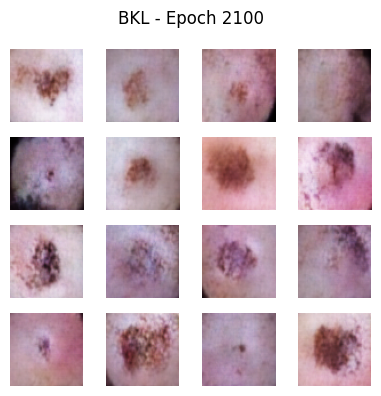

Epoch 2102 — G_loss: 0.7248, D_loss: 1.3683
Epoch 2103 — G_loss: 0.7010, D_loss: 1.3682
Epoch 2104 — G_loss: 0.7075, D_loss: 1.3681
Epoch 2105 — G_loss: 0.7127, D_loss: 1.3767
Epoch 2106 — G_loss: 0.7158, D_loss: 1.3664
Epoch 2107 — G_loss: 0.7011, D_loss: 1.3718
Epoch 2108 — G_loss: 0.7059, D_loss: 1.3786
Epoch 2109 — G_loss: 0.7171, D_loss: 1.3776
Epoch 2110 — G_loss: 0.7008, D_loss: 1.3693
Epoch 2111 — G_loss: 0.7181, D_loss: 1.3735
Epoch 2112 — G_loss: 0.7313, D_loss: 1.3651
Epoch 2113 — G_loss: 0.6898, D_loss: 1.3610
Epoch 2114 — G_loss: 0.7314, D_loss: 1.3725
Epoch 2115 — G_loss: 0.7109, D_loss: 1.3702
Epoch 2116 — G_loss: 0.7089, D_loss: 1.3697
Epoch 2117 — G_loss: 0.7350, D_loss: 1.3585
Epoch 2118 — G_loss: 0.6992, D_loss: 1.3798
Epoch 2119 — G_loss: 0.6997, D_loss: 1.3608
Epoch 2120 — G_loss: 0.7352, D_loss: 1.3639
Epoch 2121 — G_loss: 0.7056, D_loss: 1.3788
Epoch 2122 — G_loss: 0.7144, D_loss: 1.3579
Epoch 2123 — G_loss: 0.7199, D_loss: 1.3735
Epoch 2124 — G_loss: 0.7134, D_l

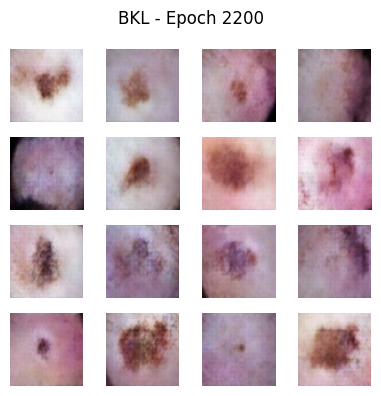

Epoch 2202 — G_loss: 0.7343, D_loss: 1.3760
Epoch 2203 — G_loss: 0.6878, D_loss: 1.3662
Epoch 2204 — G_loss: 0.7346, D_loss: 1.3645
Epoch 2205 — G_loss: 0.7354, D_loss: 1.3711
Epoch 2206 — G_loss: 0.6804, D_loss: 1.3755
Epoch 2207 — G_loss: 0.7204, D_loss: 1.3679
Epoch 2208 — G_loss: 0.7446, D_loss: 1.3680
Epoch 2209 — G_loss: 0.6967, D_loss: 1.3644
Epoch 2210 — G_loss: 0.7194, D_loss: 1.3622
Epoch 2211 — G_loss: 0.7226, D_loss: 1.3743
Epoch 2212 — G_loss: 0.7132, D_loss: 1.3583
Epoch 2213 — G_loss: 0.7150, D_loss: 1.3604
Epoch 2214 — G_loss: 0.7152, D_loss: 1.3671
Epoch 2215 — G_loss: 0.7249, D_loss: 1.3660
Epoch 2216 — G_loss: 0.7152, D_loss: 1.3658
Epoch 2217 — G_loss: 0.7152, D_loss: 1.3697
Epoch 2218 — G_loss: 0.7179, D_loss: 1.3701
Epoch 2219 — G_loss: 0.7113, D_loss: 1.3618
Epoch 2220 — G_loss: 0.7154, D_loss: 1.3670
Epoch 2221 — G_loss: 0.7168, D_loss: 1.3700
Epoch 2222 — G_loss: 0.7016, D_loss: 1.3653
Epoch 2223 — G_loss: 0.7110, D_loss: 1.3705
Epoch 2224 — G_loss: 0.7331, D_l

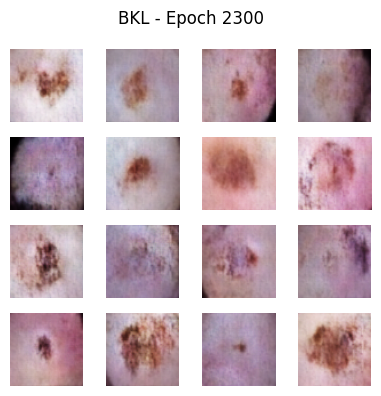

Epoch 2302 — G_loss: 0.7234, D_loss: 1.3573
Epoch 2303 — G_loss: 0.7272, D_loss: 1.3670
Epoch 2304 — G_loss: 0.6999, D_loss: 1.3616
Epoch 2305 — G_loss: 0.7278, D_loss: 1.3683
Epoch 2306 — G_loss: 0.7046, D_loss: 1.3581
Epoch 2307 — G_loss: 0.7238, D_loss: 1.3729
Epoch 2308 — G_loss: 0.7264, D_loss: 1.3629
Epoch 2309 — G_loss: 0.7086, D_loss: 1.3558
Epoch 2310 — G_loss: 0.7189, D_loss: 1.3712
Epoch 2311 — G_loss: 0.7163, D_loss: 1.3651
Epoch 2312 — G_loss: 0.7176, D_loss: 1.3665
Epoch 2313 — G_loss: 0.7112, D_loss: 1.3672
Epoch 2314 — G_loss: 0.7306, D_loss: 1.3528
Epoch 2315 — G_loss: 0.7052, D_loss: 1.3659
Epoch 2316 — G_loss: 0.7169, D_loss: 1.3668
Epoch 2317 — G_loss: 0.7141, D_loss: 1.3684
Epoch 2318 — G_loss: 0.7101, D_loss: 1.3608
Epoch 2319 — G_loss: 0.7156, D_loss: 1.3680
Epoch 2320 — G_loss: 0.7241, D_loss: 1.3586
Epoch 2321 — G_loss: 0.7206, D_loss: 1.3629
Epoch 2322 — G_loss: 0.7145, D_loss: 1.3643
Epoch 2323 — G_loss: 0.7022, D_loss: 1.3743
Epoch 2324 — G_loss: 0.7278, D_l

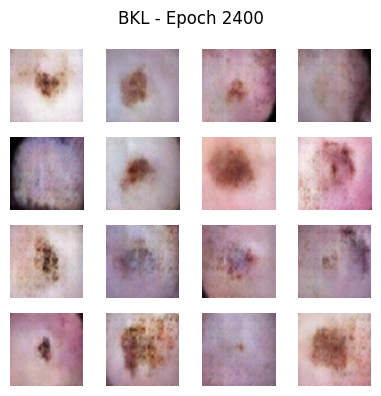

Epoch 2402 — G_loss: 0.7406, D_loss: 1.3665
Epoch 2403 — G_loss: 0.7127, D_loss: 1.3570
Epoch 2404 — G_loss: 0.7338, D_loss: 1.3667
Epoch 2405 — G_loss: 0.7156, D_loss: 1.3545
Epoch 2406 — G_loss: 0.7169, D_loss: 1.3531
Epoch 2407 — G_loss: 0.7394, D_loss: 1.3700
Epoch 2408 — G_loss: 0.7129, D_loss: 1.3551
Epoch 2409 — G_loss: 0.7169, D_loss: 1.3758
Epoch 2410 — G_loss: 0.7156, D_loss: 1.3558
Epoch 2411 — G_loss: 0.7395, D_loss: 1.3561
Epoch 2412 — G_loss: 0.7119, D_loss: 1.3653
Epoch 2413 — G_loss: 0.7272, D_loss: 1.3602
Epoch 2414 — G_loss: 0.7212, D_loss: 1.3667
Epoch 2415 — G_loss: 0.6974, D_loss: 1.3603
Epoch 2416 — G_loss: 0.7361, D_loss: 1.3573
Epoch 2417 — G_loss: 0.7096, D_loss: 1.3650
Epoch 2418 — G_loss: 0.7326, D_loss: 1.3556
Epoch 2419 — G_loss: 0.7292, D_loss: 1.3547
Epoch 2420 — G_loss: 0.7051, D_loss: 1.3581
Epoch 2421 — G_loss: 0.7387, D_loss: 1.3631
Epoch 2422 — G_loss: 0.7075, D_loss: 1.3569
Epoch 2423 — G_loss: 0.7147, D_loss: 1.3663
Epoch 2424 — G_loss: 0.7293, D_l

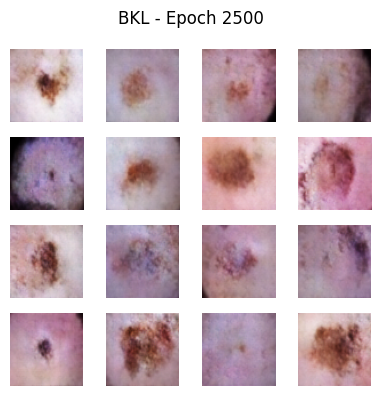

Epoch 2502 — G_loss: 0.7102, D_loss: 1.3635
Epoch 2503 — G_loss: 0.7211, D_loss: 1.3519
Epoch 2504 — G_loss: 0.7270, D_loss: 1.3582
Epoch 2505 — G_loss: 0.7307, D_loss: 1.3559
Epoch 2506 — G_loss: 0.7100, D_loss: 1.3610
Epoch 2507 — G_loss: 0.7213, D_loss: 1.3596
Epoch 2508 — G_loss: 0.7223, D_loss: 1.3536
Epoch 2509 — G_loss: 0.7177, D_loss: 1.3607
Epoch 2510 — G_loss: 0.7393, D_loss: 1.3498
Epoch 2511 — G_loss: 0.7163, D_loss: 1.3602
Epoch 2512 — G_loss: 0.7445, D_loss: 1.3541
Epoch 2513 — G_loss: 0.7076, D_loss: 1.3610
Epoch 2514 — G_loss: 0.7249, D_loss: 1.3568
Epoch 2515 — G_loss: 0.7307, D_loss: 1.3496
Epoch 2516 — G_loss: 0.7057, D_loss: 1.3629
Epoch 2517 — G_loss: 0.7328, D_loss: 1.3450
Epoch 2518 — G_loss: 0.7204, D_loss: 1.3512
Epoch 2519 — G_loss: 0.7415, D_loss: 1.3556
Epoch 2520 — G_loss: 0.7092, D_loss: 1.3639
Epoch 2521 — G_loss: 0.7172, D_loss: 1.3558
Epoch 2522 — G_loss: 0.7294, D_loss: 1.3618
Epoch 2523 — G_loss: 0.7192, D_loss: 1.3591
Epoch 2524 — G_loss: 0.7248, D_l

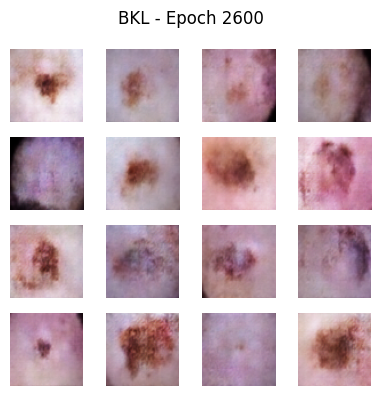

Epoch 2602 — G_loss: 0.7314, D_loss: 1.3527
Epoch 2603 — G_loss: 0.7189, D_loss: 1.3525
Epoch 2604 — G_loss: 0.7361, D_loss: 1.3562
Epoch 2605 — G_loss: 0.7048, D_loss: 1.3584
Epoch 2606 — G_loss: 0.7469, D_loss: 1.3463
Epoch 2607 — G_loss: 0.7149, D_loss: 1.3521
Epoch 2608 — G_loss: 0.7350, D_loss: 1.3524
Epoch 2609 — G_loss: 0.7141, D_loss: 1.3678
Epoch 2610 — G_loss: 0.7361, D_loss: 1.3546
Epoch 2611 — G_loss: 0.7267, D_loss: 1.3492
Epoch 2612 — G_loss: 0.7210, D_loss: 1.3564
Epoch 2613 — G_loss: 0.7266, D_loss: 1.3622
Epoch 2614 — G_loss: 0.7351, D_loss: 1.3621
Epoch 2615 — G_loss: 0.7139, D_loss: 1.3437
Epoch 2616 — G_loss: 0.7275, D_loss: 1.3526
Epoch 2617 — G_loss: 0.7352, D_loss: 1.3581
Epoch 2618 — G_loss: 0.7242, D_loss: 1.3487
Epoch 2619 — G_loss: 0.7262, D_loss: 1.3449
Epoch 2620 — G_loss: 0.7387, D_loss: 1.3596
Epoch 2621 — G_loss: 0.7216, D_loss: 1.3531
Epoch 2622 — G_loss: 0.7239, D_loss: 1.3555
Epoch 2623 — G_loss: 0.7322, D_loss: 1.3522
Epoch 2624 — G_loss: 0.7171, D_l

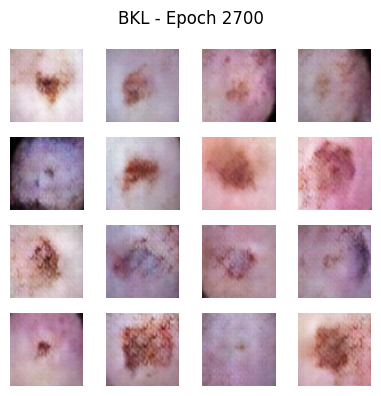

Epoch 2702 — G_loss: 0.7268, D_loss: 1.3482
Epoch 2703 — G_loss: 0.7306, D_loss: 1.3564
Epoch 2704 — G_loss: 0.7102, D_loss: 1.3512
Epoch 2705 — G_loss: 0.7540, D_loss: 1.3558
Epoch 2706 — G_loss: 0.7241, D_loss: 1.3354
Epoch 2707 — G_loss: 0.7296, D_loss: 1.3711
Epoch 2708 — G_loss: 0.7281, D_loss: 1.3538
Epoch 2709 — G_loss: 0.7340, D_loss: 1.3572
Epoch 2710 — G_loss: 0.7229, D_loss: 1.3578
Epoch 2711 — G_loss: 0.7312, D_loss: 1.3456
Epoch 2712 — G_loss: 0.7389, D_loss: 1.3386
Epoch 2713 — G_loss: 0.7413, D_loss: 1.3446
Epoch 2714 — G_loss: 0.7298, D_loss: 1.3522
Epoch 2715 — G_loss: 0.7233, D_loss: 1.3476
Epoch 2716 — G_loss: 0.7622, D_loss: 1.3355
Epoch 2717 — G_loss: 0.7167, D_loss: 1.3558
Epoch 2718 — G_loss: 0.7329, D_loss: 1.3567
Epoch 2719 — G_loss: 0.7231, D_loss: 1.3504
Epoch 2720 — G_loss: 0.7363, D_loss: 1.3560
Epoch 2721 — G_loss: 0.7183, D_loss: 1.3555
Epoch 2722 — G_loss: 0.7682, D_loss: 1.3422
Epoch 2723 — G_loss: 0.7244, D_loss: 1.3495
Epoch 2724 — G_loss: 0.7258, D_l

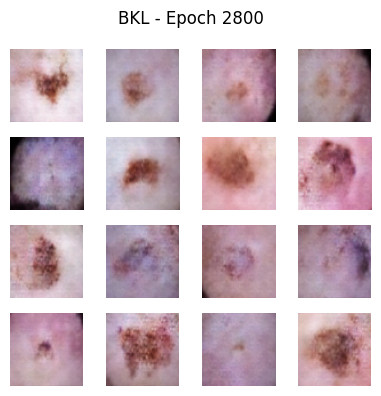

Epoch 2802 — G_loss: 0.7317, D_loss: 1.3539
Epoch 2803 — G_loss: 0.7190, D_loss: 1.3561
Epoch 2804 — G_loss: 0.7593, D_loss: 1.3410
Epoch 2805 — G_loss: 0.7366, D_loss: 1.3433
Epoch 2806 — G_loss: 0.7330, D_loss: 1.3455
Epoch 2807 — G_loss: 0.7421, D_loss: 1.3370
Epoch 2808 — G_loss: 0.7528, D_loss: 1.3557
Epoch 2809 — G_loss: 0.7025, D_loss: 1.3509
Epoch 2810 — G_loss: 0.7468, D_loss: 1.3540
Epoch 2811 — G_loss: 0.7179, D_loss: 1.3374
Epoch 2812 — G_loss: 0.7462, D_loss: 1.3460
Epoch 2813 — G_loss: 0.7311, D_loss: 1.3672
Epoch 2814 — G_loss: 0.7139, D_loss: 1.3449
Epoch 2815 — G_loss: 0.7364, D_loss: 1.3394
Epoch 2816 — G_loss: 0.7697, D_loss: 1.3443
Epoch 2817 — G_loss: 0.7150, D_loss: 1.3525
Epoch 2818 — G_loss: 0.7430, D_loss: 1.3521
Epoch 2819 — G_loss: 0.7421, D_loss: 1.3364
Epoch 2820 — G_loss: 0.7189, D_loss: 1.3521
Epoch 2821 — G_loss: 0.7394, D_loss: 1.3482
Epoch 2822 — G_loss: 0.7295, D_loss: 1.3533
Epoch 2823 — G_loss: 0.7411, D_loss: 1.3464
Epoch 2824 — G_loss: 0.7275, D_l

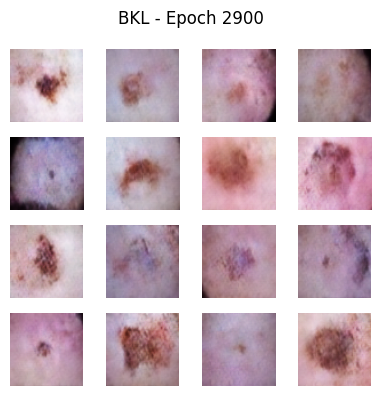

Epoch 2902 — G_loss: 0.7327, D_loss: 1.3518
Epoch 2903 — G_loss: 0.7316, D_loss: 1.3496
Epoch 2904 — G_loss: 0.7502, D_loss: 1.3567
Epoch 2905 — G_loss: 0.7279, D_loss: 1.3489
Epoch 2906 — G_loss: 0.7599, D_loss: 1.3269
Epoch 2907 — G_loss: 0.7205, D_loss: 1.3434
Epoch 2908 — G_loss: 0.7473, D_loss: 1.3422
Epoch 2909 — G_loss: 0.7364, D_loss: 1.3338
Epoch 2910 — G_loss: 0.7403, D_loss: 1.3425
Epoch 2911 — G_loss: 0.7314, D_loss: 1.3420
Epoch 2912 — G_loss: 0.7486, D_loss: 1.3432
Epoch 2913 — G_loss: 0.7287, D_loss: 1.3415
Epoch 2914 — G_loss: 0.7309, D_loss: 1.3527
Epoch 2915 — G_loss: 0.7287, D_loss: 1.3374
Epoch 2916 — G_loss: 0.7559, D_loss: 1.3400
Epoch 2917 — G_loss: 0.7360, D_loss: 1.3517
Epoch 2918 — G_loss: 0.7342, D_loss: 1.3363
Epoch 2919 — G_loss: 0.7425, D_loss: 1.3599
Epoch 2920 — G_loss: 0.7260, D_loss: 1.3461
Epoch 2921 — G_loss: 0.7478, D_loss: 1.3378
Epoch 2922 — G_loss: 0.7455, D_loss: 1.3315
Epoch 2923 — G_loss: 0.7274, D_loss: 1.3442
Epoch 2924 — G_loss: 0.7523, D_l

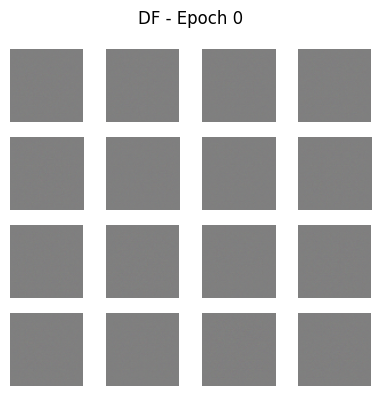

Epoch 2 — G_loss: 0.7045, D_loss: 1.3180
Epoch 3 — G_loss: 0.6878, D_loss: 1.2894
Epoch 4 — G_loss: 0.6812, D_loss: 1.2324
Epoch 5 — G_loss: 0.6841, D_loss: 1.1753
Epoch 6 — G_loss: 0.6915, D_loss: 1.1033
Epoch 7 — G_loss: 0.7171, D_loss: 1.0327
Epoch 8 — G_loss: 0.7388, D_loss: 0.9536
Epoch 9 — G_loss: 0.7778, D_loss: 0.8713
Epoch 10 — G_loss: 0.8208, D_loss: 0.8033
Epoch 11 — G_loss: 0.8809, D_loss: 0.7342
Epoch 12 — G_loss: 0.9429, D_loss: 0.6716
Epoch 13 — G_loss: 0.9879, D_loss: 0.6356
Epoch 14 — G_loss: 1.0449, D_loss: 0.5896
Epoch 15 — G_loss: 1.1022, D_loss: 0.5464
Epoch 16 — G_loss: 1.1757, D_loss: 0.5120
Epoch 17 — G_loss: 1.3066, D_loss: 0.4519
Epoch 18 — G_loss: 1.3735, D_loss: 0.4255
Epoch 19 — G_loss: 1.4351, D_loss: 0.4039
Epoch 20 — G_loss: 1.4785, D_loss: 0.3920
Epoch 21 — G_loss: 1.4949, D_loss: 0.3982
Epoch 22 — G_loss: 1.5320, D_loss: 0.3861
Epoch 23 — G_loss: 1.5395, D_loss: 0.3996
Epoch 24 — G_loss: 1.5844, D_loss: 0.4253
Epoch 25 — G_loss: 1.4967, D_loss: 0.4122


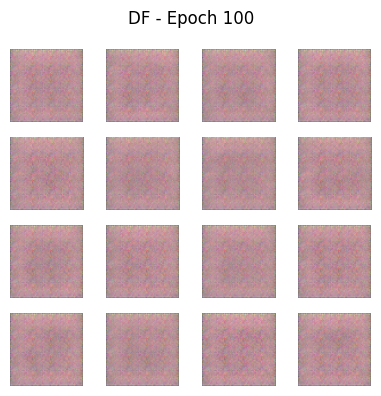

Epoch 102 — G_loss: 0.8655, D_loss: 1.3602
Epoch 103 — G_loss: 0.8788, D_loss: 1.3385
Epoch 104 — G_loss: 0.8720, D_loss: 1.3479
Epoch 105 — G_loss: 0.9748, D_loss: 1.3643
Epoch 106 — G_loss: 0.8349, D_loss: 1.3336
Epoch 107 — G_loss: 0.9049, D_loss: 1.2716
Epoch 108 — G_loss: 0.9514, D_loss: 1.3423
Epoch 109 — G_loss: 0.8672, D_loss: 1.3291
Epoch 110 — G_loss: 0.9105, D_loss: 1.2627
Epoch 111 — G_loss: 0.8926, D_loss: 1.3023
Epoch 112 — G_loss: 0.8322, D_loss: 1.3939
Epoch 113 — G_loss: 0.9762, D_loss: 1.2877
Epoch 114 — G_loss: 0.8503, D_loss: 1.2920
Epoch 115 — G_loss: 0.8798, D_loss: 1.2984
Epoch 116 — G_loss: 0.8986, D_loss: 1.3530
Epoch 117 — G_loss: 0.8969, D_loss: 1.3099
Epoch 118 — G_loss: 0.9243, D_loss: 1.2796
Epoch 119 — G_loss: 0.8813, D_loss: 1.3051
Epoch 120 — G_loss: 0.9673, D_loss: 1.2559
Epoch 121 — G_loss: 0.8555, D_loss: 1.3143
Epoch 122 — G_loss: 0.9463, D_loss: 1.2502
Epoch 123 — G_loss: 0.8804, D_loss: 1.3193
Epoch 124 — G_loss: 0.8734, D_loss: 1.2250
Epoch 125 —

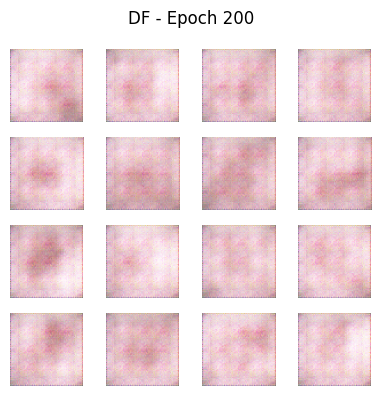

Epoch 202 — G_loss: 0.8744, D_loss: 1.3582
Epoch 203 — G_loss: 0.8448, D_loss: 1.3359
Epoch 204 — G_loss: 0.8258, D_loss: 1.3923
Epoch 205 — G_loss: 0.8396, D_loss: 1.3832
Epoch 206 — G_loss: 0.8465, D_loss: 1.3641
Epoch 207 — G_loss: 0.7988, D_loss: 1.3790
Epoch 208 — G_loss: 0.8817, D_loss: 1.3547
Epoch 209 — G_loss: 0.8120, D_loss: 1.3383
Epoch 210 — G_loss: 0.8740, D_loss: 1.2918
Epoch 211 — G_loss: 0.8819, D_loss: 1.3191
Epoch 212 — G_loss: 0.8894, D_loss: 1.2577
Epoch 213 — G_loss: 0.8439, D_loss: 1.2850
Epoch 214 — G_loss: 0.9366, D_loss: 1.2716
Epoch 215 — G_loss: 0.7967, D_loss: 1.3446
Epoch 216 — G_loss: 0.8275, D_loss: 1.2798
Epoch 217 — G_loss: 0.9727, D_loss: 1.2896
Epoch 218 — G_loss: 0.7635, D_loss: 1.2996
Epoch 219 — G_loss: 0.8698, D_loss: 1.2961
Epoch 220 — G_loss: 0.9042, D_loss: 1.3026
Epoch 221 — G_loss: 0.7672, D_loss: 1.3059
Epoch 222 — G_loss: 0.8846, D_loss: 1.2911
Epoch 223 — G_loss: 0.8506, D_loss: 1.2937
Epoch 224 — G_loss: 0.8000, D_loss: 1.2782
Epoch 225 —

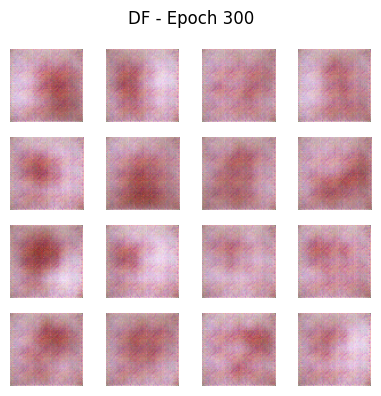

Epoch 302 — G_loss: 0.7408, D_loss: 1.3303
Epoch 303 — G_loss: 0.7954, D_loss: 1.2691
Epoch 304 — G_loss: 0.7774, D_loss: 1.2975
Epoch 305 — G_loss: 0.7612, D_loss: 1.3252
Epoch 306 — G_loss: 0.7111, D_loss: 1.3151
Epoch 307 — G_loss: 0.8424, D_loss: 1.3182
Epoch 308 — G_loss: 0.6674, D_loss: 1.3228
Epoch 309 — G_loss: 0.8353, D_loss: 1.3250
Epoch 310 — G_loss: 0.7122, D_loss: 1.3321
Epoch 311 — G_loss: 0.7753, D_loss: 1.3130
Epoch 312 — G_loss: 0.7192, D_loss: 1.3273
Epoch 313 — G_loss: 0.7789, D_loss: 1.3027
Epoch 314 — G_loss: 0.7443, D_loss: 1.3075
Epoch 315 — G_loss: 0.7671, D_loss: 1.3224
Epoch 316 — G_loss: 0.7176, D_loss: 1.3309
Epoch 317 — G_loss: 0.7632, D_loss: 1.3051
Epoch 318 — G_loss: 0.7871, D_loss: 1.3228
Epoch 319 — G_loss: 0.7130, D_loss: 1.3031
Epoch 320 — G_loss: 0.7300, D_loss: 1.3170
Epoch 321 — G_loss: 0.7882, D_loss: 1.3254
Epoch 322 — G_loss: 0.7294, D_loss: 1.2969
Epoch 323 — G_loss: 0.7454, D_loss: 1.3311
Epoch 324 — G_loss: 0.7370, D_loss: 1.2877
Epoch 325 —

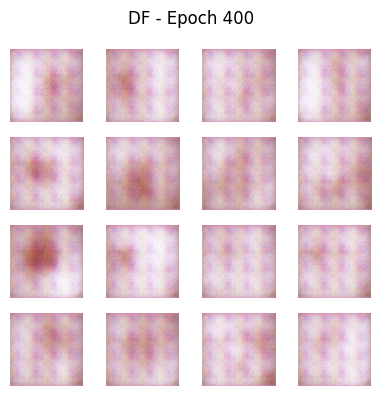

Epoch 402 — G_loss: 0.8200, D_loss: 1.2464
Epoch 403 — G_loss: 0.7619, D_loss: 1.2783
Epoch 404 — G_loss: 0.7567, D_loss: 1.2196
Epoch 405 — G_loss: 0.8171, D_loss: 1.2226
Epoch 406 — G_loss: 0.7619, D_loss: 1.2788
Epoch 407 — G_loss: 0.8329, D_loss: 1.2462
Epoch 408 — G_loss: 0.7559, D_loss: 1.2867
Epoch 409 — G_loss: 0.7815, D_loss: 1.2660
Epoch 410 — G_loss: 0.7960, D_loss: 1.2788
Epoch 411 — G_loss: 0.7912, D_loss: 1.2738
Epoch 412 — G_loss: 0.7851, D_loss: 1.2509
Epoch 413 — G_loss: 0.7868, D_loss: 1.2536
Epoch 414 — G_loss: 0.8330, D_loss: 1.3050
Epoch 415 — G_loss: 0.8187, D_loss: 1.3081
Epoch 416 — G_loss: 0.7467, D_loss: 1.2902
Epoch 417 — G_loss: 0.7695, D_loss: 1.2982
Epoch 418 — G_loss: 0.7322, D_loss: 1.3539
Epoch 419 — G_loss: 0.7271, D_loss: 1.3483
Epoch 420 — G_loss: 0.7948, D_loss: 1.3246
Epoch 421 — G_loss: 0.7031, D_loss: 1.3033
Epoch 422 — G_loss: 0.7944, D_loss: 1.2613
Epoch 423 — G_loss: 0.8004, D_loss: 1.1897
Epoch 424 — G_loss: 0.8378, D_loss: 1.2046
Epoch 425 —

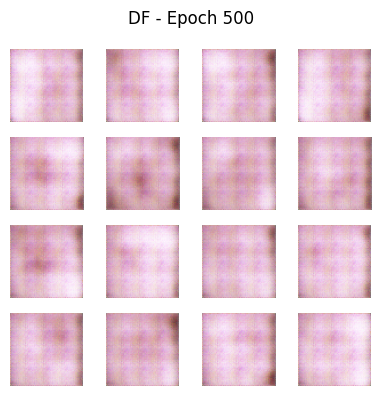

Epoch 502 — G_loss: 0.6826, D_loss: 1.4124
Epoch 503 — G_loss: 0.8116, D_loss: 1.3591
Epoch 504 — G_loss: 0.7269, D_loss: 1.2630
Epoch 505 — G_loss: 0.8667, D_loss: 1.1086
Epoch 506 — G_loss: 0.9625, D_loss: 1.0115
Epoch 507 — G_loss: 0.9991, D_loss: 0.9630
Epoch 508 — G_loss: 1.0134, D_loss: 0.9481
Epoch 509 — G_loss: 0.9755, D_loss: 1.0209
Epoch 510 — G_loss: 0.9017, D_loss: 1.1727
Epoch 511 — G_loss: 0.8400, D_loss: 1.3255
Epoch 512 — G_loss: 0.8103, D_loss: 1.4086
Epoch 513 — G_loss: 0.7630, D_loss: 1.4243
Epoch 514 — G_loss: 0.8551, D_loss: 1.3137
Epoch 515 — G_loss: 0.9127, D_loss: 1.2770
Epoch 516 — G_loss: 0.9294, D_loss: 1.1865
Epoch 517 — G_loss: 0.9689, D_loss: 1.1448
Epoch 518 — G_loss: 0.8939, D_loss: 1.1370
Epoch 519 — G_loss: 1.0172, D_loss: 1.1451
Epoch 520 — G_loss: 0.9106, D_loss: 1.1778
Epoch 521 — G_loss: 0.8172, D_loss: 1.3085
Epoch 522 — G_loss: 0.7066, D_loss: 1.4432
Epoch 523 — G_loss: 0.6906, D_loss: 1.4319
Epoch 524 — G_loss: 0.6940, D_loss: 1.3070
Epoch 525 —

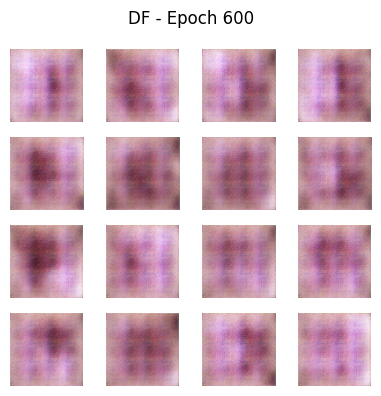

Epoch 602 — G_loss: 0.8099, D_loss: 1.3160
Epoch 603 — G_loss: 0.7701, D_loss: 1.2778
Epoch 604 — G_loss: 0.8283, D_loss: 1.3001
Epoch 605 — G_loss: 0.7807, D_loss: 1.2884
Epoch 606 — G_loss: 0.8799, D_loss: 1.2529
Epoch 607 — G_loss: 0.8478, D_loss: 1.2433
Epoch 608 — G_loss: 0.8789, D_loss: 1.2336
Epoch 609 — G_loss: 0.7990, D_loss: 1.2174
Epoch 610 — G_loss: 0.9109, D_loss: 1.1915
Epoch 611 — G_loss: 0.8573, D_loss: 1.2259
Epoch 612 — G_loss: 0.7886, D_loss: 1.2569
Epoch 613 — G_loss: 0.7845, D_loss: 1.2701
Epoch 614 — G_loss: 0.8158, D_loss: 1.2883
Epoch 615 — G_loss: 0.7386, D_loss: 1.3067
Epoch 616 — G_loss: 0.7670, D_loss: 1.3204
Epoch 617 — G_loss: 0.7737, D_loss: 1.3275
Epoch 618 — G_loss: 0.7041, D_loss: 1.2943
Epoch 619 — G_loss: 0.7968, D_loss: 1.2591
Epoch 620 — G_loss: 0.7935, D_loss: 1.2074
Epoch 621 — G_loss: 0.8102, D_loss: 1.2163
Epoch 622 — G_loss: 0.7666, D_loss: 1.2073
Epoch 623 — G_loss: 0.8928, D_loss: 1.2040
Epoch 624 — G_loss: 0.8006, D_loss: 1.1929
Epoch 625 —

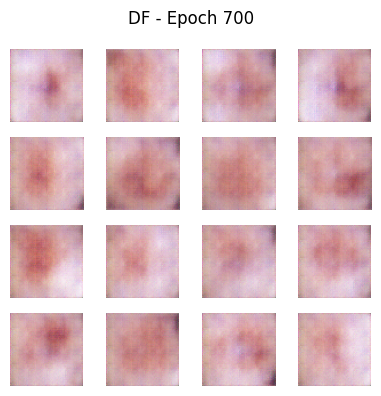

Epoch 702 — G_loss: 0.8127, D_loss: 1.3490
Epoch 703 — G_loss: 0.6777, D_loss: 1.3322
Epoch 704 — G_loss: 0.8125, D_loss: 1.3301
Epoch 705 — G_loss: 0.7405, D_loss: 1.3312
Epoch 706 — G_loss: 0.7445, D_loss: 1.3342
Epoch 707 — G_loss: 0.7995, D_loss: 1.3115
Epoch 708 — G_loss: 0.7582, D_loss: 1.3474
Epoch 709 — G_loss: 0.7461, D_loss: 1.3198
Epoch 710 — G_loss: 0.7613, D_loss: 1.3137
Epoch 711 — G_loss: 0.7587, D_loss: 1.2892
Epoch 712 — G_loss: 0.7460, D_loss: 1.3190
Epoch 713 — G_loss: 0.7750, D_loss: 1.3034
Epoch 714 — G_loss: 0.7648, D_loss: 1.2984
Epoch 715 — G_loss: 0.7926, D_loss: 1.2834
Epoch 716 — G_loss: 0.7703, D_loss: 1.2889
Epoch 717 — G_loss: 0.8004, D_loss: 1.2811
Epoch 718 — G_loss: 0.7724, D_loss: 1.2896
Epoch 719 — G_loss: 0.8222, D_loss: 1.3059
Epoch 720 — G_loss: 0.7413, D_loss: 1.2698
Epoch 721 — G_loss: 0.8405, D_loss: 1.3116
Epoch 722 — G_loss: 0.7524, D_loss: 1.3241
Epoch 723 — G_loss: 0.7968, D_loss: 1.2946
Epoch 724 — G_loss: 0.7940, D_loss: 1.3042
Epoch 725 —

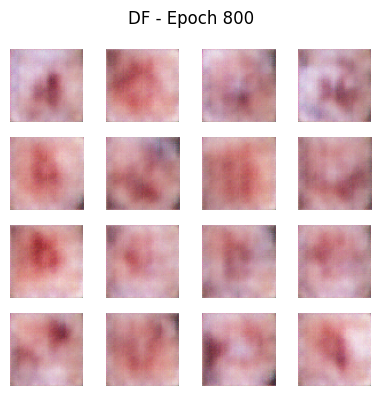

Epoch 802 — G_loss: 0.6851, D_loss: 1.3501
Epoch 803 — G_loss: 0.7733, D_loss: 1.3910
Epoch 804 — G_loss: 0.6915, D_loss: 1.3434
Epoch 805 — G_loss: 0.7396, D_loss: 1.3387
Epoch 806 — G_loss: 0.7738, D_loss: 1.3480
Epoch 807 — G_loss: 0.6616, D_loss: 1.3627
Epoch 808 — G_loss: 0.7719, D_loss: 1.3379
Epoch 809 — G_loss: 0.6808, D_loss: 1.3573
Epoch 810 — G_loss: 0.7850, D_loss: 1.3372
Epoch 811 — G_loss: 0.7052, D_loss: 1.3529
Epoch 812 — G_loss: 0.7134, D_loss: 1.3540
Epoch 813 — G_loss: 0.7410, D_loss: 1.3362
Epoch 814 — G_loss: 0.7077, D_loss: 1.3169
Epoch 815 — G_loss: 0.7695, D_loss: 1.3238
Epoch 816 — G_loss: 0.7310, D_loss: 1.3282
Epoch 817 — G_loss: 0.7504, D_loss: 1.3267
Epoch 818 — G_loss: 0.7159, D_loss: 1.3059
Epoch 819 — G_loss: 0.7561, D_loss: 1.3130
Epoch 820 — G_loss: 0.7443, D_loss: 1.2776
Epoch 821 — G_loss: 0.8091, D_loss: 1.3088
Epoch 822 — G_loss: 0.6979, D_loss: 1.3109
Epoch 823 — G_loss: 0.7575, D_loss: 1.3281
Epoch 824 — G_loss: 0.7255, D_loss: 1.3204
Epoch 825 —

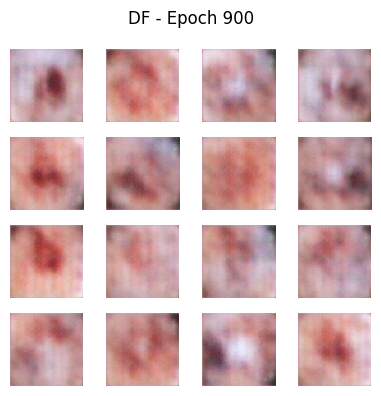

Epoch 902 — G_loss: 0.7435, D_loss: 1.3430
Epoch 903 — G_loss: 0.8079, D_loss: 1.3020
Epoch 904 — G_loss: 0.7374, D_loss: 1.3286
Epoch 905 — G_loss: 0.7321, D_loss: 1.3164
Epoch 906 — G_loss: 0.7412, D_loss: 1.3171
Epoch 907 — G_loss: 0.7715, D_loss: 1.3331
Epoch 908 — G_loss: 0.7334, D_loss: 1.3420
Epoch 909 — G_loss: 0.7403, D_loss: 1.3259
Epoch 910 — G_loss: 0.7280, D_loss: 1.3784
Epoch 911 — G_loss: 0.6640, D_loss: 1.3530
Epoch 912 — G_loss: 0.7458, D_loss: 1.3403
Epoch 913 — G_loss: 0.7210, D_loss: 1.3369
Epoch 914 — G_loss: 0.8021, D_loss: 1.3385
Epoch 915 — G_loss: 0.6848, D_loss: 1.3439
Epoch 916 — G_loss: 0.7456, D_loss: 1.3035
Epoch 917 — G_loss: 0.7478, D_loss: 1.3165
Epoch 918 — G_loss: 0.7506, D_loss: 1.3310
Epoch 919 — G_loss: 0.7219, D_loss: 1.3411
Epoch 920 — G_loss: 0.7457, D_loss: 1.3267
Epoch 921 — G_loss: 0.6893, D_loss: 1.3445
Epoch 922 — G_loss: 0.7376, D_loss: 1.3424
Epoch 923 — G_loss: 0.7743, D_loss: 1.3584
Epoch 924 — G_loss: 0.7046, D_loss: 1.3744
Epoch 925 —

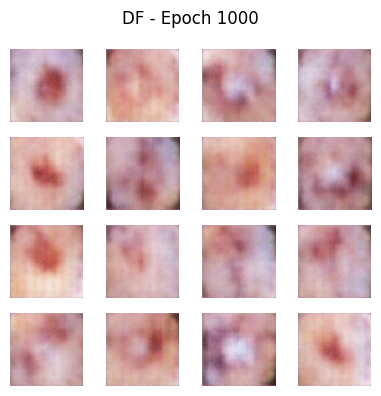

Epoch 1002 — G_loss: 0.8142, D_loss: 1.3127
Epoch 1003 — G_loss: 0.6898, D_loss: 1.3253
Epoch 1004 — G_loss: 0.7287, D_loss: 1.3521
Epoch 1005 — G_loss: 0.7122, D_loss: 1.3728
Epoch 1006 — G_loss: 0.7280, D_loss: 1.3555
Epoch 1007 — G_loss: 0.7257, D_loss: 1.3528
Epoch 1008 — G_loss: 0.7089, D_loss: 1.3594
Epoch 1009 — G_loss: 0.7622, D_loss: 1.3540
Epoch 1010 — G_loss: 0.6865, D_loss: 1.3539
Epoch 1011 — G_loss: 0.7880, D_loss: 1.3578
Epoch 1012 — G_loss: 0.7470, D_loss: 1.3175
Epoch 1013 — G_loss: 0.6903, D_loss: 1.3406
Epoch 1014 — G_loss: 0.7639, D_loss: 1.3468
Epoch 1015 — G_loss: 0.6770, D_loss: 1.3734
Epoch 1016 — G_loss: 0.7305, D_loss: 1.3667
Epoch 1017 — G_loss: 0.7372, D_loss: 1.3662
Epoch 1018 — G_loss: 0.7419, D_loss: 1.3561
Epoch 1019 — G_loss: 0.6921, D_loss: 1.3646
Epoch 1020 — G_loss: 0.7225, D_loss: 1.3738
Epoch 1021 — G_loss: 0.6973, D_loss: 1.3596
Epoch 1022 — G_loss: 0.7532, D_loss: 1.3345
Epoch 1023 — G_loss: 0.7847, D_loss: 1.3195
Epoch 1024 — G_loss: 0.7056, D_l

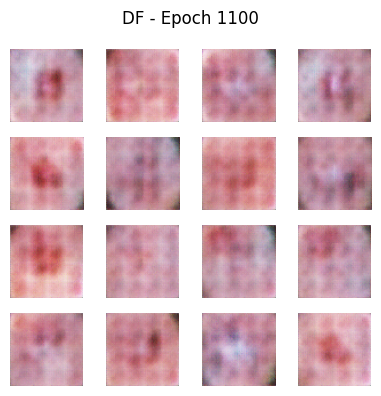

Epoch 1102 — G_loss: 0.7715, D_loss: 1.3101
Epoch 1103 — G_loss: 0.7419, D_loss: 1.3161
Epoch 1104 — G_loss: 0.7269, D_loss: 1.3595
Epoch 1105 — G_loss: 0.7512, D_loss: 1.3604
Epoch 1106 — G_loss: 0.6956, D_loss: 1.3908
Epoch 1107 — G_loss: 0.7737, D_loss: 1.3765
Epoch 1108 — G_loss: 0.6842, D_loss: 1.3484
Epoch 1109 — G_loss: 0.7677, D_loss: 1.3242
Epoch 1110 — G_loss: 0.7511, D_loss: 1.3182
Epoch 1111 — G_loss: 0.7769, D_loss: 1.3166
Epoch 1112 — G_loss: 0.7558, D_loss: 1.3312
Epoch 1113 — G_loss: 0.7103, D_loss: 1.3164
Epoch 1114 — G_loss: 0.7753, D_loss: 1.3286
Epoch 1115 — G_loss: 0.7466, D_loss: 1.3866
Epoch 1116 — G_loss: 0.7716, D_loss: 1.3627
Epoch 1117 — G_loss: 0.6751, D_loss: 1.4090
Epoch 1118 — G_loss: 0.7675, D_loss: 1.3986
Epoch 1119 — G_loss: 0.6943, D_loss: 1.4152
Epoch 1120 — G_loss: 0.7250, D_loss: 1.4102
Epoch 1121 — G_loss: 0.7645, D_loss: 1.3506
Epoch 1122 — G_loss: 0.8149, D_loss: 1.3178
Epoch 1123 — G_loss: 0.6966, D_loss: 1.3084
Epoch 1124 — G_loss: 0.7787, D_l

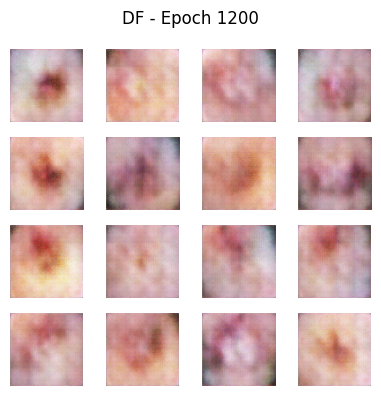

Epoch 1202 — G_loss: 0.7108, D_loss: 1.3731
Epoch 1203 — G_loss: 0.7177, D_loss: 1.3709
Epoch 1204 — G_loss: 0.7537, D_loss: 1.3415
Epoch 1205 — G_loss: 0.6990, D_loss: 1.3497
Epoch 1206 — G_loss: 0.7140, D_loss: 1.3662
Epoch 1207 — G_loss: 0.7011, D_loss: 1.3726
Epoch 1208 — G_loss: 0.7018, D_loss: 1.3965
Epoch 1209 — G_loss: 0.7122, D_loss: 1.3586
Epoch 1210 — G_loss: 0.7150, D_loss: 1.3788
Epoch 1211 — G_loss: 0.7234, D_loss: 1.3764
Epoch 1212 — G_loss: 0.7179, D_loss: 1.3806
Epoch 1213 — G_loss: 0.7492, D_loss: 1.3734
Epoch 1214 — G_loss: 0.7040, D_loss: 1.3442
Epoch 1215 — G_loss: 0.7194, D_loss: 1.3651
Epoch 1216 — G_loss: 0.7459, D_loss: 1.3716
Epoch 1217 — G_loss: 0.7343, D_loss: 1.3562
Epoch 1218 — G_loss: 0.6863, D_loss: 1.3554
Epoch 1219 — G_loss: 0.7090, D_loss: 1.3511
Epoch 1220 — G_loss: 0.7045, D_loss: 1.3864
Epoch 1221 — G_loss: 0.7492, D_loss: 1.3818
Epoch 1222 — G_loss: 0.7323, D_loss: 1.3549
Epoch 1223 — G_loss: 0.7361, D_loss: 1.3619
Epoch 1224 — G_loss: 0.7337, D_l

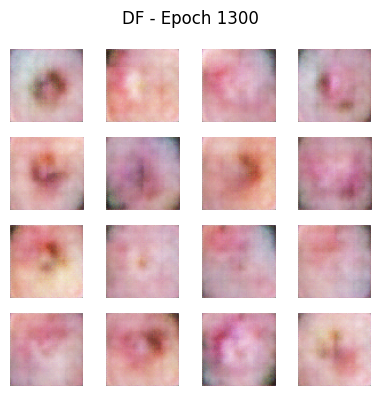

Epoch 1302 — G_loss: 0.7214, D_loss: 1.3501
Epoch 1303 — G_loss: 0.7136, D_loss: 1.3756
Epoch 1304 — G_loss: 0.7083, D_loss: 1.3791
Epoch 1305 — G_loss: 0.7462, D_loss: 1.3685
Epoch 1306 — G_loss: 0.6837, D_loss: 1.3839
Epoch 1307 — G_loss: 0.7071, D_loss: 1.3745
Epoch 1308 — G_loss: 0.7086, D_loss: 1.3982
Epoch 1309 — G_loss: 0.7727, D_loss: 1.3867
Epoch 1310 — G_loss: 0.7043, D_loss: 1.3853
Epoch 1311 — G_loss: 0.6952, D_loss: 1.3961
Epoch 1312 — G_loss: 0.7259, D_loss: 1.3439
Epoch 1313 — G_loss: 0.7479, D_loss: 1.3611
Epoch 1314 — G_loss: 0.7516, D_loss: 1.3660
Epoch 1315 — G_loss: 0.7325, D_loss: 1.3634
Epoch 1316 — G_loss: 0.7165, D_loss: 1.3708
Epoch 1317 — G_loss: 0.7028, D_loss: 1.3562
Epoch 1318 — G_loss: 0.7145, D_loss: 1.3692
Epoch 1319 — G_loss: 0.6952, D_loss: 1.4108
Epoch 1320 — G_loss: 0.6969, D_loss: 1.3922
Epoch 1321 — G_loss: 0.7150, D_loss: 1.3695
Epoch 1322 — G_loss: 0.6974, D_loss: 1.3877
Epoch 1323 — G_loss: 0.6739, D_loss: 1.3693
Epoch 1324 — G_loss: 0.7228, D_l

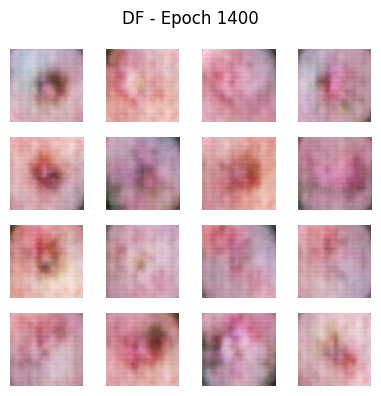

Epoch 1402 — G_loss: 0.7110, D_loss: 1.3753
Epoch 1403 — G_loss: 0.7233, D_loss: 1.3650
Epoch 1404 — G_loss: 0.7407, D_loss: 1.3676
Epoch 1405 — G_loss: 0.7200, D_loss: 1.3583
Epoch 1406 — G_loss: 0.6994, D_loss: 1.3607
Epoch 1407 — G_loss: 0.7245, D_loss: 1.3667
Epoch 1408 — G_loss: 0.7083, D_loss: 1.3563
Epoch 1409 — G_loss: 0.6903, D_loss: 1.3809
Epoch 1410 — G_loss: 0.7520, D_loss: 1.3651
Epoch 1411 — G_loss: 0.6999, D_loss: 1.3717
Epoch 1412 — G_loss: 0.6934, D_loss: 1.3634
Epoch 1413 — G_loss: 0.7255, D_loss: 1.3701
Epoch 1414 — G_loss: 0.7074, D_loss: 1.3732
Epoch 1415 — G_loss: 0.7248, D_loss: 1.3766
Epoch 1416 — G_loss: 0.7054, D_loss: 1.3771
Epoch 1417 — G_loss: 0.7336, D_loss: 1.3816
Epoch 1418 — G_loss: 0.6919, D_loss: 1.3652
Epoch 1419 — G_loss: 0.6983, D_loss: 1.3717
Epoch 1420 — G_loss: 0.7212, D_loss: 1.3713
Epoch 1421 — G_loss: 0.7414, D_loss: 1.3701
Epoch 1422 — G_loss: 0.7393, D_loss: 1.3634
Epoch 1423 — G_loss: 0.7323, D_loss: 1.3767
Epoch 1424 — G_loss: 0.7058, D_l

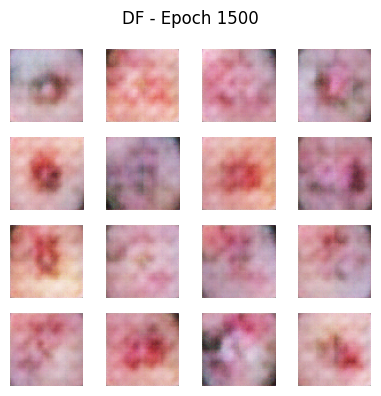

Epoch 1502 — G_loss: 0.7407, D_loss: 1.3790
Epoch 1503 — G_loss: 0.7159, D_loss: 1.3763
Epoch 1504 — G_loss: 0.7446, D_loss: 1.3698
Epoch 1505 — G_loss: 0.6743, D_loss: 1.3775
Epoch 1506 — G_loss: 0.7394, D_loss: 1.3701
Epoch 1507 — G_loss: 0.6864, D_loss: 1.3711
Epoch 1508 — G_loss: 0.7560, D_loss: 1.3618
Epoch 1509 — G_loss: 0.7035, D_loss: 1.3831
Epoch 1510 — G_loss: 0.7018, D_loss: 1.3750
Epoch 1511 — G_loss: 0.7138, D_loss: 1.3805
Epoch 1512 — G_loss: 0.7269, D_loss: 1.3786
Epoch 1513 — G_loss: 0.7264, D_loss: 1.3832
Epoch 1514 — G_loss: 0.7550, D_loss: 1.3635
Epoch 1515 — G_loss: 0.6687, D_loss: 1.3629
Epoch 1516 — G_loss: 0.7252, D_loss: 1.3529
Epoch 1517 — G_loss: 0.7121, D_loss: 1.3736
Epoch 1518 — G_loss: 0.6979, D_loss: 1.3462
Epoch 1519 — G_loss: 0.7351, D_loss: 1.3483
Epoch 1520 — G_loss: 0.6757, D_loss: 1.3761
Epoch 1521 — G_loss: 0.7271, D_loss: 1.3637
Epoch 1522 — G_loss: 0.6991, D_loss: 1.3846
Epoch 1523 — G_loss: 0.7422, D_loss: 1.3678
Epoch 1524 — G_loss: 0.7309, D_l

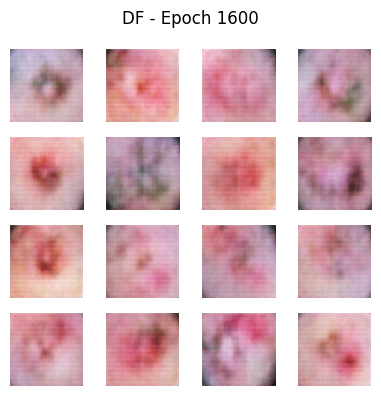

Epoch 1602 — G_loss: 0.7373, D_loss: 1.3932
Epoch 1603 — G_loss: 0.6965, D_loss: 1.3667
Epoch 1604 — G_loss: 0.7103, D_loss: 1.3503
Epoch 1605 — G_loss: 0.7002, D_loss: 1.3739
Epoch 1606 — G_loss: 0.7102, D_loss: 1.3520
Epoch 1607 — G_loss: 0.7259, D_loss: 1.3871
Epoch 1608 — G_loss: 0.7146, D_loss: 1.3915
Epoch 1609 — G_loss: 0.7551, D_loss: 1.3791
Epoch 1610 — G_loss: 0.6907, D_loss: 1.3530
Epoch 1611 — G_loss: 0.7145, D_loss: 1.3616
Epoch 1612 — G_loss: 0.6863, D_loss: 1.3677
Epoch 1613 — G_loss: 0.7249, D_loss: 1.3518
Epoch 1614 — G_loss: 0.7501, D_loss: 1.3677
Epoch 1615 — G_loss: 0.6741, D_loss: 1.3784
Epoch 1616 — G_loss: 0.6813, D_loss: 1.3905
Epoch 1617 — G_loss: 0.7326, D_loss: 1.3656
Epoch 1618 — G_loss: 0.7393, D_loss: 1.3538
Epoch 1619 — G_loss: 0.7467, D_loss: 1.3407
Epoch 1620 — G_loss: 0.6747, D_loss: 1.3521
Epoch 1621 — G_loss: 0.7190, D_loss: 1.3648
Epoch 1622 — G_loss: 0.7176, D_loss: 1.3740
Epoch 1623 — G_loss: 0.6959, D_loss: 1.3712
Epoch 1624 — G_loss: 0.7369, D_l

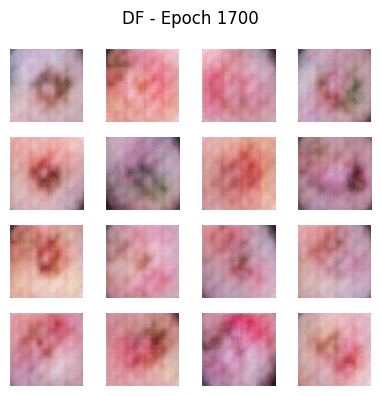

Epoch 1702 — G_loss: 0.7245, D_loss: 1.3673
Epoch 1703 — G_loss: 0.6842, D_loss: 1.3750
Epoch 1704 — G_loss: 0.6830, D_loss: 1.3718
Epoch 1705 — G_loss: 0.7383, D_loss: 1.3523
Epoch 1706 — G_loss: 0.7234, D_loss: 1.3673
Epoch 1707 — G_loss: 0.7204, D_loss: 1.3786
Epoch 1708 — G_loss: 0.7249, D_loss: 1.3823
Epoch 1709 — G_loss: 0.6947, D_loss: 1.3832
Epoch 1710 — G_loss: 0.7485, D_loss: 1.3646
Epoch 1711 — G_loss: 0.7181, D_loss: 1.3741
Epoch 1712 — G_loss: 0.7217, D_loss: 1.3673
Epoch 1713 — G_loss: 0.7024, D_loss: 1.3778
Epoch 1714 — G_loss: 0.6693, D_loss: 1.3776
Epoch 1715 — G_loss: 0.6977, D_loss: 1.3647
Epoch 1716 — G_loss: 0.7015, D_loss: 1.3701
Epoch 1717 — G_loss: 0.6949, D_loss: 1.3872
Epoch 1718 — G_loss: 0.7163, D_loss: 1.3708
Epoch 1719 — G_loss: 0.6717, D_loss: 1.3688
Epoch 1720 — G_loss: 0.7290, D_loss: 1.3544
Epoch 1721 — G_loss: 0.7376, D_loss: 1.3888
Epoch 1722 — G_loss: 0.6830, D_loss: 1.3758
Epoch 1723 — G_loss: 0.6889, D_loss: 1.3773
Epoch 1724 — G_loss: 0.7029, D_l

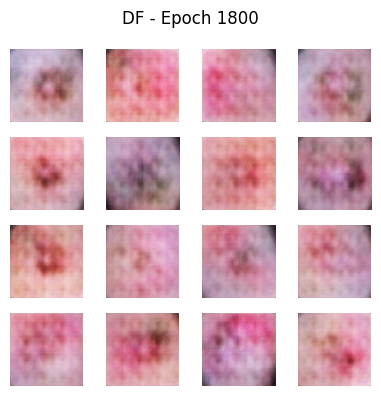

Epoch 1802 — G_loss: 0.7431, D_loss: 1.3778
Epoch 1803 — G_loss: 0.7113, D_loss: 1.3834
Epoch 1804 — G_loss: 0.6934, D_loss: 1.3648
Epoch 1805 — G_loss: 0.7145, D_loss: 1.3723
Epoch 1806 — G_loss: 0.6864, D_loss: 1.3577
Epoch 1807 — G_loss: 0.6817, D_loss: 1.3675
Epoch 1808 — G_loss: 0.7026, D_loss: 1.3594
Epoch 1809 — G_loss: 0.7034, D_loss: 1.3587
Epoch 1810 — G_loss: 0.7007, D_loss: 1.3695
Epoch 1811 — G_loss: 0.6776, D_loss: 1.3691
Epoch 1812 — G_loss: 0.7487, D_loss: 1.3473
Epoch 1813 — G_loss: 0.6878, D_loss: 1.3668
Epoch 1814 — G_loss: 0.7019, D_loss: 1.3715
Epoch 1815 — G_loss: 0.7267, D_loss: 1.3753
Epoch 1816 — G_loss: 0.7086, D_loss: 1.3632
Epoch 1817 — G_loss: 0.7340, D_loss: 1.3546
Epoch 1818 — G_loss: 0.7190, D_loss: 1.3690
Epoch 1819 — G_loss: 0.7166, D_loss: 1.3684
Epoch 1820 — G_loss: 0.7502, D_loss: 1.3824
Epoch 1821 — G_loss: 0.7404, D_loss: 1.3860
Epoch 1822 — G_loss: 0.7795, D_loss: 1.3692
Epoch 1823 — G_loss: 0.6930, D_loss: 1.3702
Epoch 1824 — G_loss: 0.7359, D_l

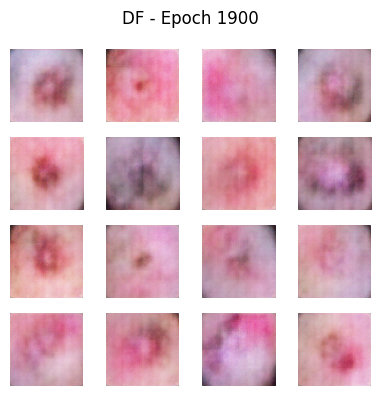

Epoch 1902 — G_loss: 0.7410, D_loss: 1.3780
Epoch 1903 — G_loss: 0.6851, D_loss: 1.3725
Epoch 1904 — G_loss: 0.7013, D_loss: 1.3769
Epoch 1905 — G_loss: 0.6953, D_loss: 1.3910
Epoch 1906 — G_loss: 0.6987, D_loss: 1.3779
Epoch 1907 — G_loss: 0.6648, D_loss: 1.3661
Epoch 1908 — G_loss: 0.7237, D_loss: 1.3654
Epoch 1909 — G_loss: 0.6795, D_loss: 1.3710
Epoch 1910 — G_loss: 0.6955, D_loss: 1.3784
Epoch 1911 — G_loss: 0.7401, D_loss: 1.3886
Epoch 1912 — G_loss: 0.7223, D_loss: 1.3541
Epoch 1913 — G_loss: 0.7195, D_loss: 1.3624
Epoch 1914 — G_loss: 0.7112, D_loss: 1.3530
Epoch 1915 — G_loss: 0.7166, D_loss: 1.3870
Epoch 1916 — G_loss: 0.6817, D_loss: 1.3920
Epoch 1917 — G_loss: 0.7320, D_loss: 1.3770
Epoch 1918 — G_loss: 0.7248, D_loss: 1.3544
Epoch 1919 — G_loss: 0.7080, D_loss: 1.3523
Epoch 1920 — G_loss: 0.6930, D_loss: 1.3714
Epoch 1921 — G_loss: 0.7339, D_loss: 1.3850
Epoch 1922 — G_loss: 0.6979, D_loss: 1.3646
Epoch 1923 — G_loss: 0.7179, D_loss: 1.3709
Epoch 1924 — G_loss: 0.7005, D_l

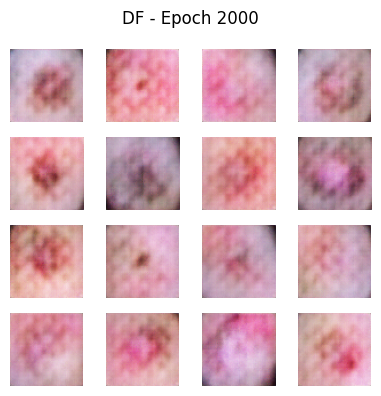

Epoch 2002 — G_loss: 0.7132, D_loss: 1.3533
Epoch 2003 — G_loss: 0.6959, D_loss: 1.3667
Epoch 2004 — G_loss: 0.7163, D_loss: 1.3862
Epoch 2005 — G_loss: 0.7023, D_loss: 1.4075
Epoch 2006 — G_loss: 0.7483, D_loss: 1.3687
Epoch 2007 — G_loss: 0.7009, D_loss: 1.3590
Epoch 2008 — G_loss: 0.7510, D_loss: 1.3594
Epoch 2009 — G_loss: 0.6943, D_loss: 1.3816
Epoch 2010 — G_loss: 0.7131, D_loss: 1.3816
Epoch 2011 — G_loss: 0.7017, D_loss: 1.3513
Epoch 2012 — G_loss: 0.7318, D_loss: 1.3714
Epoch 2013 — G_loss: 0.6986, D_loss: 1.3773
Epoch 2014 — G_loss: 0.6791, D_loss: 1.3975
Epoch 2015 — G_loss: 0.7200, D_loss: 1.3789
Epoch 2016 — G_loss: 0.7047, D_loss: 1.3725
Epoch 2017 — G_loss: 0.7122, D_loss: 1.3751
Epoch 2018 — G_loss: 0.6943, D_loss: 1.3840
Epoch 2019 — G_loss: 0.6952, D_loss: 1.3804
Epoch 2020 — G_loss: 0.6842, D_loss: 1.3295
Epoch 2021 — G_loss: 0.7016, D_loss: 1.3572
Epoch 2022 — G_loss: 0.7240, D_loss: 1.3793
Epoch 2023 — G_loss: 0.7290, D_loss: 1.3875
Epoch 2024 — G_loss: 0.7321, D_l

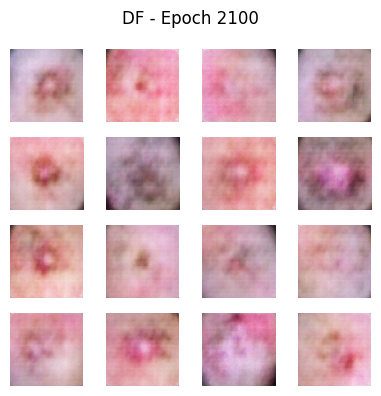

Epoch 2102 — G_loss: 0.7116, D_loss: 1.3810
Epoch 2103 — G_loss: 0.6744, D_loss: 1.3774
Epoch 2104 — G_loss: 0.7057, D_loss: 1.3888
Epoch 2105 — G_loss: 0.7301, D_loss: 1.3594
Epoch 2106 — G_loss: 0.6814, D_loss: 1.3728
Epoch 2107 — G_loss: 0.7297, D_loss: 1.3709
Epoch 2108 — G_loss: 0.7277, D_loss: 1.3822
Epoch 2109 — G_loss: 0.6940, D_loss: 1.3758
Epoch 2110 — G_loss: 0.6957, D_loss: 1.3606
Epoch 2111 — G_loss: 0.7255, D_loss: 1.3607
Epoch 2112 — G_loss: 0.7106, D_loss: 1.3785
Epoch 2113 — G_loss: 0.7061, D_loss: 1.3730
Epoch 2114 — G_loss: 0.7371, D_loss: 1.3706
Epoch 2115 — G_loss: 0.7404, D_loss: 1.3827
Epoch 2116 — G_loss: 0.6702, D_loss: 1.4013
Epoch 2117 — G_loss: 0.6876, D_loss: 1.3938
Epoch 2118 — G_loss: 0.7025, D_loss: 1.3672
Epoch 2119 — G_loss: 0.7190, D_loss: 1.3661
Epoch 2120 — G_loss: 0.6915, D_loss: 1.3774
Epoch 2121 — G_loss: 0.7153, D_loss: 1.3896
Epoch 2122 — G_loss: 0.7037, D_loss: 1.3838
Epoch 2123 — G_loss: 0.7456, D_loss: 1.3524
Epoch 2124 — G_loss: 0.6925, D_l

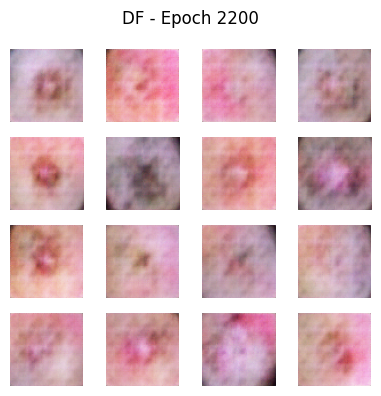

Epoch 2202 — G_loss: 0.6947, D_loss: 1.3966
Epoch 2203 — G_loss: 0.7147, D_loss: 1.3798
Epoch 2204 — G_loss: 0.6939, D_loss: 1.3681
Epoch 2205 — G_loss: 0.6893, D_loss: 1.3562
Epoch 2206 — G_loss: 0.6817, D_loss: 1.3734
Epoch 2207 — G_loss: 0.6861, D_loss: 1.3647
Epoch 2208 — G_loss: 0.6958, D_loss: 1.3785
Epoch 2209 — G_loss: 0.6873, D_loss: 1.3825
Epoch 2210 — G_loss: 0.6967, D_loss: 1.3807
Epoch 2211 — G_loss: 0.6974, D_loss: 1.3828
Epoch 2212 — G_loss: 0.7326, D_loss: 1.3696
Epoch 2213 — G_loss: 0.7204, D_loss: 1.3628
Epoch 2214 — G_loss: 0.7108, D_loss: 1.3824
Epoch 2215 — G_loss: 0.7401, D_loss: 1.3932
Epoch 2216 — G_loss: 0.6821, D_loss: 1.3824
Epoch 2217 — G_loss: 0.7504, D_loss: 1.3803
Epoch 2218 — G_loss: 0.6890, D_loss: 1.3832
Epoch 2219 — G_loss: 0.7033, D_loss: 1.3958
Epoch 2220 — G_loss: 0.7193, D_loss: 1.3666
Epoch 2221 — G_loss: 0.7202, D_loss: 1.3630
Epoch 2222 — G_loss: 0.7163, D_loss: 1.3436
Epoch 2223 — G_loss: 0.6842, D_loss: 1.3764
Epoch 2224 — G_loss: 0.7122, D_l

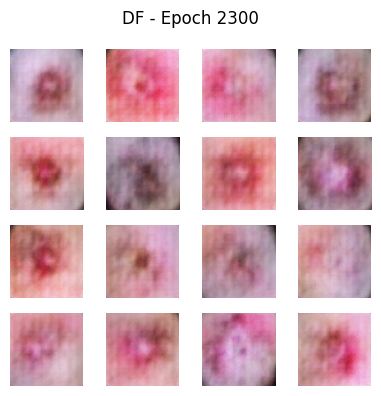

Epoch 2302 — G_loss: 0.7460, D_loss: 1.3550
Epoch 2303 — G_loss: 0.6964, D_loss: 1.3702
Epoch 2304 — G_loss: 0.7134, D_loss: 1.3799
Epoch 2305 — G_loss: 0.6871, D_loss: 1.3799
Epoch 2306 — G_loss: 0.7058, D_loss: 1.3681
Epoch 2307 — G_loss: 0.6792, D_loss: 1.3767
Epoch 2308 — G_loss: 0.6844, D_loss: 1.3732
Epoch 2309 — G_loss: 0.7141, D_loss: 1.3811
Epoch 2310 — G_loss: 0.7216, D_loss: 1.3676
Epoch 2311 — G_loss: 0.7019, D_loss: 1.3602
Epoch 2312 — G_loss: 0.6418, D_loss: 1.3786
Epoch 2313 — G_loss: 0.6936, D_loss: 1.3877
Epoch 2314 — G_loss: 0.7001, D_loss: 1.3741
Epoch 2315 — G_loss: 0.6997, D_loss: 1.3763
Epoch 2316 — G_loss: 0.7047, D_loss: 1.3844
Epoch 2317 — G_loss: 0.7341, D_loss: 1.3822
Epoch 2318 — G_loss: 0.7150, D_loss: 1.3843
Epoch 2319 — G_loss: 0.7304, D_loss: 1.3550
Epoch 2320 — G_loss: 0.7267, D_loss: 1.3560
Epoch 2321 — G_loss: 0.6943, D_loss: 1.3705
Epoch 2322 — G_loss: 0.7324, D_loss: 1.3666
Epoch 2323 — G_loss: 0.6985, D_loss: 1.3784
Epoch 2324 — G_loss: 0.6872, D_l

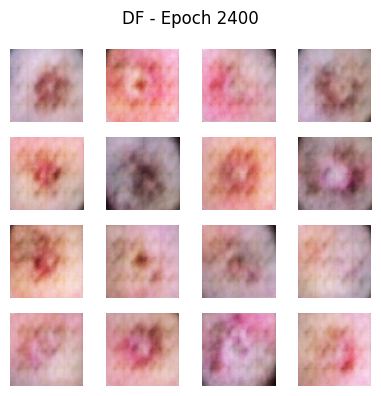

Epoch 2402 — G_loss: 0.6904, D_loss: 1.3893
Epoch 2403 — G_loss: 0.6954, D_loss: 1.3870
Epoch 2404 — G_loss: 0.7389, D_loss: 1.3643
Epoch 2405 — G_loss: 0.7529, D_loss: 1.3679
Epoch 2406 — G_loss: 0.7225, D_loss: 1.3759
Epoch 2407 — G_loss: 0.7145, D_loss: 1.3839
Epoch 2408 — G_loss: 0.7152, D_loss: 1.3843
Epoch 2409 — G_loss: 0.6890, D_loss: 1.3824
Epoch 2410 — G_loss: 0.6996, D_loss: 1.3694
Epoch 2411 — G_loss: 0.7045, D_loss: 1.3813
Epoch 2412 — G_loss: 0.7184, D_loss: 1.3689
Epoch 2413 — G_loss: 0.6826, D_loss: 1.3572
Epoch 2414 — G_loss: 0.7052, D_loss: 1.3566
Epoch 2415 — G_loss: 0.6489, D_loss: 1.3582
Epoch 2416 — G_loss: 0.6861, D_loss: 1.3652
Epoch 2417 — G_loss: 0.7054, D_loss: 1.3673
Epoch 2418 — G_loss: 0.6793, D_loss: 1.3726
Epoch 2419 — G_loss: 0.6884, D_loss: 1.3904
Epoch 2420 — G_loss: 0.7090, D_loss: 1.4006
Epoch 2421 — G_loss: 0.7176, D_loss: 1.3889
Epoch 2422 — G_loss: 0.7542, D_loss: 1.3688
Epoch 2423 — G_loss: 0.7422, D_loss: 1.3668
Epoch 2424 — G_loss: 0.7437, D_l

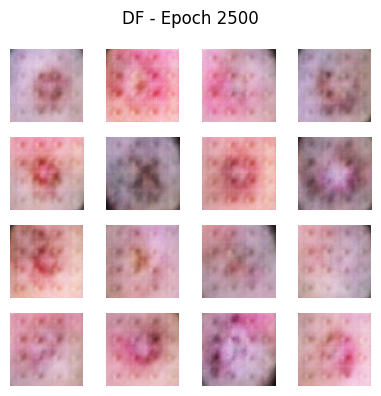

Epoch 2502 — G_loss: 0.6783, D_loss: 1.3951
Epoch 2503 — G_loss: 0.7165, D_loss: 1.4008
Epoch 2504 — G_loss: 0.6911, D_loss: 1.3847
Epoch 2505 — G_loss: 0.6764, D_loss: 1.3804
Epoch 2506 — G_loss: 0.7236, D_loss: 1.3696
Epoch 2507 — G_loss: 0.6503, D_loss: 1.3648
Epoch 2508 — G_loss: 0.6626, D_loss: 1.3493
Epoch 2509 — G_loss: 0.7097, D_loss: 1.3310
Epoch 2510 — G_loss: 0.6766, D_loss: 1.3452
Epoch 2511 — G_loss: 0.6973, D_loss: 1.3534
Epoch 2512 — G_loss: 0.6862, D_loss: 1.3763
Epoch 2513 — G_loss: 0.6826, D_loss: 1.3818
Epoch 2514 — G_loss: 0.6843, D_loss: 1.4044
Epoch 2515 — G_loss: 0.6932, D_loss: 1.4006
Epoch 2516 — G_loss: 0.7252, D_loss: 1.3634
Epoch 2517 — G_loss: 0.7477, D_loss: 1.3607
Epoch 2518 — G_loss: 0.7377, D_loss: 1.3456
Epoch 2519 — G_loss: 0.7479, D_loss: 1.3477
Epoch 2520 — G_loss: 0.7198, D_loss: 1.4020
Epoch 2521 — G_loss: 0.7318, D_loss: 1.3678
Epoch 2522 — G_loss: 0.7104, D_loss: 1.3911
Epoch 2523 — G_loss: 0.7307, D_loss: 1.3822
Epoch 2524 — G_loss: 0.7051, D_l

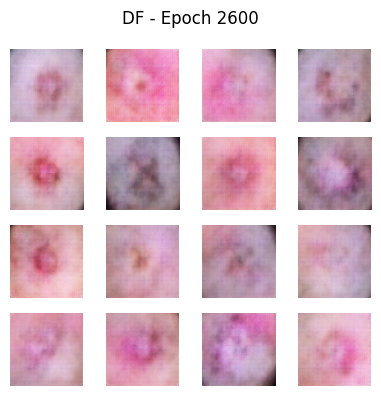

Epoch 2602 — G_loss: 0.6937, D_loss: 1.3584
Epoch 2603 — G_loss: 0.7593, D_loss: 1.3400
Epoch 2604 — G_loss: 0.7163, D_loss: 1.3517
Epoch 2605 — G_loss: 0.6413, D_loss: 1.3713
Epoch 2606 — G_loss: 0.7053, D_loss: 1.3806
Epoch 2607 — G_loss: 0.7205, D_loss: 1.3631
Epoch 2608 — G_loss: 0.6758, D_loss: 1.3612
Epoch 2609 — G_loss: 0.6572, D_loss: 1.3552
Epoch 2610 — G_loss: 0.7450, D_loss: 1.3634
Epoch 2611 — G_loss: 0.7160, D_loss: 1.3604
Epoch 2612 — G_loss: 0.7203, D_loss: 1.3964
Epoch 2613 — G_loss: 0.7747, D_loss: 1.3866
Epoch 2614 — G_loss: 0.7603, D_loss: 1.3898
Epoch 2615 — G_loss: 0.7344, D_loss: 1.3792
Epoch 2616 — G_loss: 0.8118, D_loss: 1.3735
Epoch 2617 — G_loss: 0.7908, D_loss: 1.3482
Epoch 2618 — G_loss: 0.7348, D_loss: 1.3563
Epoch 2619 — G_loss: 0.6745, D_loss: 1.4036
Epoch 2620 — G_loss: 0.6536, D_loss: 1.4178
Epoch 2621 — G_loss: 0.6656, D_loss: 1.4087
Epoch 2622 — G_loss: 0.6498, D_loss: 1.3569
Epoch 2623 — G_loss: 0.6873, D_loss: 1.3228
Epoch 2624 — G_loss: 0.6972, D_l

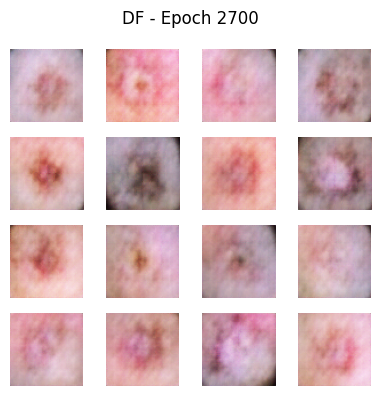

Epoch 2702 — G_loss: 0.7069, D_loss: 1.3554
Epoch 2703 — G_loss: 0.6984, D_loss: 1.3345
Epoch 2704 — G_loss: 0.7174, D_loss: 1.3420
Epoch 2705 — G_loss: 0.7120, D_loss: 1.3645
Epoch 2706 — G_loss: 0.7032, D_loss: 1.3875
Epoch 2707 — G_loss: 0.7381, D_loss: 1.4085
Epoch 2708 — G_loss: 0.7623, D_loss: 1.3893
Epoch 2709 — G_loss: 0.7612, D_loss: 1.3694
Epoch 2710 — G_loss: 0.7732, D_loss: 1.3470
Epoch 2711 — G_loss: 0.7508, D_loss: 1.3352
Epoch 2712 — G_loss: 0.7216, D_loss: 1.3513
Epoch 2713 — G_loss: 0.6837, D_loss: 1.3771
Epoch 2714 — G_loss: 0.6721, D_loss: 1.4040
Epoch 2715 — G_loss: 0.6703, D_loss: 1.4096
Epoch 2716 — G_loss: 0.6619, D_loss: 1.3806
Epoch 2717 — G_loss: 0.7064, D_loss: 1.3495
Epoch 2718 — G_loss: 0.6824, D_loss: 1.3424
Epoch 2719 — G_loss: 0.7009, D_loss: 1.3454
Epoch 2720 — G_loss: 0.7465, D_loss: 1.3422
Epoch 2721 — G_loss: 0.6998, D_loss: 1.3594
Epoch 2722 — G_loss: 0.7042, D_loss: 1.3930
Epoch 2723 — G_loss: 0.7484, D_loss: 1.4100
Epoch 2724 — G_loss: 0.7466, D_l

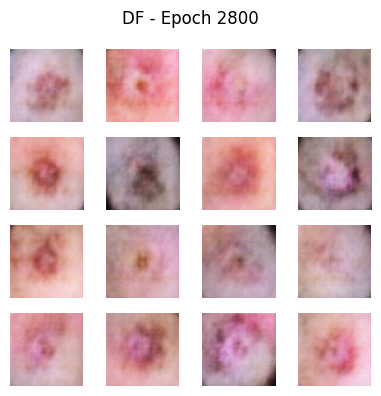

Epoch 2802 — G_loss: 0.7120, D_loss: 1.3459
Epoch 2803 — G_loss: 0.7059, D_loss: 1.3510
Epoch 2804 — G_loss: 0.7158, D_loss: 1.3521
Epoch 2805 — G_loss: 0.7442, D_loss: 1.3554
Epoch 2806 — G_loss: 0.7077, D_loss: 1.3974
Epoch 2807 — G_loss: 0.6992, D_loss: 1.3985
Epoch 2808 — G_loss: 0.7524, D_loss: 1.3928
Epoch 2809 — G_loss: 0.7546, D_loss: 1.3659
Epoch 2810 — G_loss: 0.7120, D_loss: 1.3525
Epoch 2811 — G_loss: 0.7029, D_loss: 1.3771
Epoch 2812 — G_loss: 0.7024, D_loss: 1.3839
Epoch 2813 — G_loss: 0.6641, D_loss: 1.3970
Epoch 2814 — G_loss: 0.6593, D_loss: 1.3935
Epoch 2815 — G_loss: 0.6549, D_loss: 1.3844
Epoch 2816 — G_loss: 0.6893, D_loss: 1.3610
Epoch 2817 — G_loss: 0.6700, D_loss: 1.3486
Epoch 2818 — G_loss: 0.7251, D_loss: 1.3268
Epoch 2819 — G_loss: 0.7395, D_loss: 1.3323
Epoch 2820 — G_loss: 0.7043, D_loss: 1.3458
Epoch 2821 — G_loss: 0.7319, D_loss: 1.3795
Epoch 2822 — G_loss: 0.7464, D_loss: 1.3955
Epoch 2823 — G_loss: 0.7315, D_loss: 1.3981
Epoch 2824 — G_loss: 0.7572, D_l

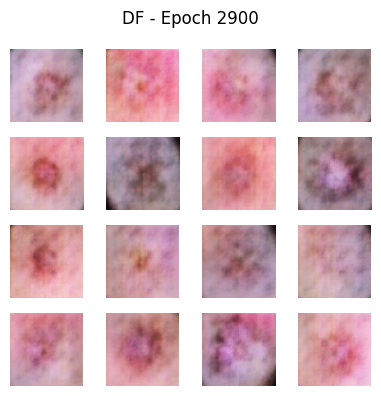

Epoch 2902 — G_loss: 0.7519, D_loss: 1.4296
Epoch 2903 — G_loss: 0.7641, D_loss: 1.4382
Epoch 2904 — G_loss: 0.7366, D_loss: 1.3985
Epoch 2905 — G_loss: 0.7638, D_loss: 1.3302
Epoch 2906 — G_loss: 0.7696, D_loss: 1.3363
Epoch 2907 — G_loss: 0.7518, D_loss: 1.3111
Epoch 2908 — G_loss: 0.7169, D_loss: 1.3508
Epoch 2909 — G_loss: 0.6644, D_loss: 1.3974
Epoch 2910 — G_loss: 0.6560, D_loss: 1.4112
Epoch 2911 — G_loss: 0.6485, D_loss: 1.4130
Epoch 2912 — G_loss: 0.6908, D_loss: 1.3826
Epoch 2913 — G_loss: 0.7109, D_loss: 1.3416
Epoch 2914 — G_loss: 0.7003, D_loss: 1.3226
Epoch 2915 — G_loss: 0.7342, D_loss: 1.2981
Epoch 2916 — G_loss: 0.7008, D_loss: 1.3522
Epoch 2917 — G_loss: 0.7329, D_loss: 1.3845
Epoch 2918 — G_loss: 0.7223, D_loss: 1.4311
Epoch 2919 — G_loss: 0.7440, D_loss: 1.4330
Epoch 2920 — G_loss: 0.7470, D_loss: 1.4174
Epoch 2921 — G_loss: 0.7829, D_loss: 1.3568
Epoch 2922 — G_loss: 0.7696, D_loss: 1.3244
Epoch 2923 — G_loss: 0.7575, D_loss: 1.2993
Epoch 2924 — G_loss: 0.7245, D_l

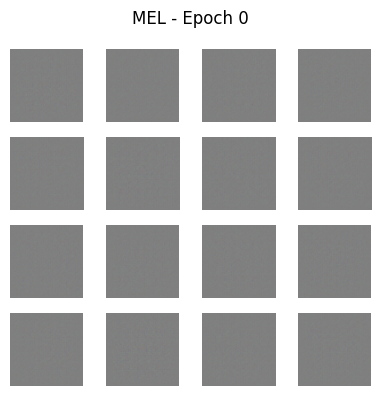

Epoch 2 — G_loss: 1.3300, D_loss: 0.5749
Epoch 3 — G_loss: 1.5465, D_loss: 0.4393
Epoch 4 — G_loss: 1.8116, D_loss: 0.4199
Epoch 5 — G_loss: 2.0379, D_loss: 0.3379
Epoch 6 — G_loss: 2.1697, D_loss: 0.2828
Epoch 7 — G_loss: 2.3641, D_loss: 0.2497
Epoch 8 — G_loss: 2.5225, D_loss: 0.2732
Epoch 9 — G_loss: 1.9558, D_loss: 0.4881
Epoch 10 — G_loss: 2.0686, D_loss: 0.5352
Epoch 11 — G_loss: 1.9439, D_loss: 0.8253
Epoch 12 — G_loss: 1.4190, D_loss: 1.4730
Epoch 13 — G_loss: 1.0894, D_loss: 1.4150
Epoch 14 — G_loss: 1.1299, D_loss: 1.3375
Epoch 15 — G_loss: 1.1050, D_loss: 1.2815
Epoch 16 — G_loss: 0.9939, D_loss: 1.3193
Epoch 17 — G_loss: 0.9636, D_loss: 1.2692
Epoch 18 — G_loss: 0.9898, D_loss: 1.1847
Epoch 19 — G_loss: 0.9793, D_loss: 1.1682
Epoch 20 — G_loss: 0.8713, D_loss: 1.2987
Epoch 21 — G_loss: 0.8088, D_loss: 1.3258
Epoch 22 — G_loss: 0.8154, D_loss: 1.2908
Epoch 23 — G_loss: 0.7933, D_loss: 1.3030
Epoch 24 — G_loss: 0.8352, D_loss: 1.2576
Epoch 25 — G_loss: 0.8440, D_loss: 1.2347


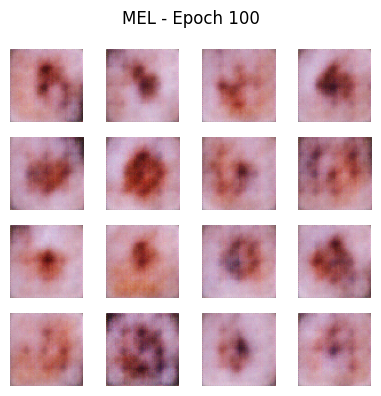

Epoch 102 — G_loss: 0.7976, D_loss: 1.3533
Epoch 103 — G_loss: 0.7825, D_loss: 1.2590
Epoch 104 — G_loss: 0.7705, D_loss: 1.3384
Epoch 105 — G_loss: 0.7884, D_loss: 1.3333
Epoch 106 — G_loss: 0.7389, D_loss: 1.3049
Epoch 107 — G_loss: 0.7206, D_loss: 1.3483
Epoch 108 — G_loss: 0.7858, D_loss: 1.3087
Epoch 109 — G_loss: 0.7205, D_loss: 1.3873
Epoch 110 — G_loss: 0.7171, D_loss: 1.3089
Epoch 111 — G_loss: 0.7697, D_loss: 1.3444
Epoch 112 — G_loss: 0.7670, D_loss: 1.3606
Epoch 113 — G_loss: 0.7294, D_loss: 1.3072
Epoch 114 — G_loss: 0.7498, D_loss: 1.3486
Epoch 115 — G_loss: 0.7688, D_loss: 1.3515
Epoch 116 — G_loss: 0.7322, D_loss: 1.3081
Epoch 117 — G_loss: 0.7463, D_loss: 1.3425
Epoch 118 — G_loss: 0.7755, D_loss: 1.3330
Epoch 119 — G_loss: 0.7210, D_loss: 1.3205
Epoch 120 — G_loss: 0.7730, D_loss: 1.3261
Epoch 121 — G_loss: 0.7855, D_loss: 1.3284
Epoch 122 — G_loss: 0.7103, D_loss: 1.3174
Epoch 123 — G_loss: 0.7851, D_loss: 1.3368
Epoch 124 — G_loss: 0.7908, D_loss: 1.3574
Epoch 125 —

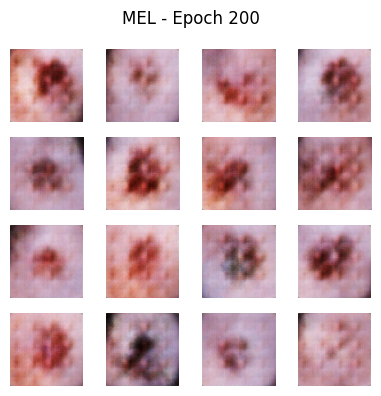

Epoch 202 — G_loss: 0.7583, D_loss: 1.3242
Epoch 203 — G_loss: 0.7604, D_loss: 1.3100
Epoch 204 — G_loss: 0.8970, D_loss: 1.1131
Epoch 205 — G_loss: 0.7406, D_loss: 1.3994
Epoch 206 — G_loss: 0.8036, D_loss: 1.3623
Epoch 207 — G_loss: 0.8072, D_loss: 1.2408
Epoch 208 — G_loss: 0.8373, D_loss: 1.3298
Epoch 209 — G_loss: 0.7476, D_loss: 1.5269
Epoch 210 — G_loss: 0.7277, D_loss: 1.3123
Epoch 211 — G_loss: 0.7543, D_loss: 1.3857
Epoch 212 — G_loss: 0.7652, D_loss: 1.3259
Epoch 213 — G_loss: 0.7511, D_loss: 1.3217
Epoch 214 — G_loss: 0.7294, D_loss: 1.3742
Epoch 215 — G_loss: 0.7720, D_loss: 1.2803
Epoch 216 — G_loss: 0.7333, D_loss: 1.4257
Epoch 217 — G_loss: 0.7552, D_loss: 1.3129
Epoch 218 — G_loss: 0.7212, D_loss: 1.3403
Epoch 219 — G_loss: 0.7692, D_loss: 1.3478
Epoch 220 — G_loss: 0.7601, D_loss: 1.3499
Epoch 221 — G_loss: 0.7153, D_loss: 1.3494
Epoch 222 — G_loss: 0.7398, D_loss: 1.3555
Epoch 223 — G_loss: 0.7361, D_loss: 1.3891
Epoch 224 — G_loss: 0.7169, D_loss: 1.3936
Epoch 225 —

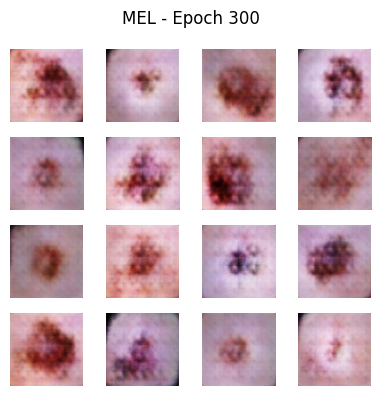

Epoch 302 — G_loss: 0.7215, D_loss: 1.3751
Epoch 303 — G_loss: 0.7041, D_loss: 1.3838
Epoch 304 — G_loss: 0.7084, D_loss: 1.3658
Epoch 305 — G_loss: 0.7153, D_loss: 1.3931
Epoch 306 — G_loss: 0.7031, D_loss: 1.3726
Epoch 307 — G_loss: 0.7093, D_loss: 1.3786
Epoch 308 — G_loss: 0.7174, D_loss: 1.3903
Epoch 309 — G_loss: 0.6926, D_loss: 1.3539
Epoch 310 — G_loss: 0.7039, D_loss: 1.3839
Epoch 311 — G_loss: 0.7143, D_loss: 1.4123
Epoch 312 — G_loss: 0.6897, D_loss: 1.3779
Epoch 313 — G_loss: 0.7237, D_loss: 1.3717
Epoch 314 — G_loss: 0.7165, D_loss: 1.3875
Epoch 315 — G_loss: 0.6969, D_loss: 1.3681
Epoch 316 — G_loss: 0.7091, D_loss: 1.3953
Epoch 317 — G_loss: 0.7129, D_loss: 1.3757
Epoch 318 — G_loss: 0.6987, D_loss: 1.3792
Epoch 319 — G_loss: 0.6917, D_loss: 1.3839
Epoch 320 — G_loss: 0.7109, D_loss: 1.3716
Epoch 321 — G_loss: 0.7006, D_loss: 1.3875
Epoch 322 — G_loss: 0.6893, D_loss: 1.3693
Epoch 323 — G_loss: 0.7193, D_loss: 1.3726
Epoch 324 — G_loss: 0.7170, D_loss: 1.3787
Epoch 325 —

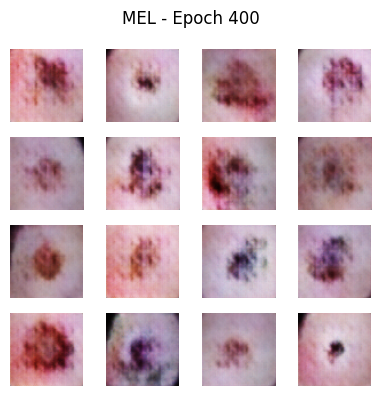

Epoch 402 — G_loss: 0.7089, D_loss: 1.3752
Epoch 403 — G_loss: 0.7078, D_loss: 1.3767
Epoch 404 — G_loss: 0.6968, D_loss: 1.3765
Epoch 405 — G_loss: 0.7011, D_loss: 1.3784
Epoch 406 — G_loss: 0.6966, D_loss: 1.3708
Epoch 407 — G_loss: 0.7145, D_loss: 1.3904
Epoch 408 — G_loss: 0.7112, D_loss: 1.3720
Epoch 409 — G_loss: 0.7070, D_loss: 1.3943
Epoch 410 — G_loss: 0.7030, D_loss: 1.3808
Epoch 411 — G_loss: 0.7081, D_loss: 1.3620
Epoch 412 — G_loss: 0.6891, D_loss: 1.3987
Epoch 413 — G_loss: 0.6938, D_loss: 1.3638
Epoch 414 — G_loss: 0.7316, D_loss: 1.3994
Epoch 415 — G_loss: 0.6900, D_loss: 1.3950
Epoch 416 — G_loss: 0.6980, D_loss: 1.3616
Epoch 417 — G_loss: 0.7121, D_loss: 1.4068
Epoch 418 — G_loss: 0.6852, D_loss: 1.3829
Epoch 419 — G_loss: 0.7160, D_loss: 1.3805
Epoch 420 — G_loss: 0.7055, D_loss: 1.3859
Epoch 421 — G_loss: 0.7005, D_loss: 1.3722
Epoch 422 — G_loss: 0.7214, D_loss: 1.3704
Epoch 423 — G_loss: 0.6909, D_loss: 1.3763
Epoch 424 — G_loss: 0.6999, D_loss: 1.3804
Epoch 425 —

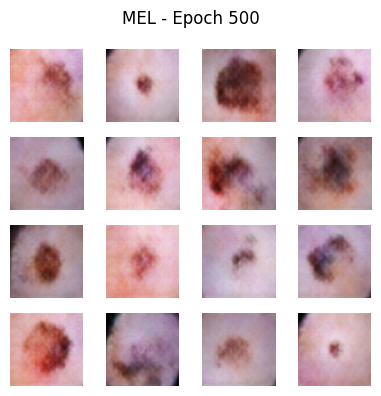

Epoch 502 — G_loss: 0.6930, D_loss: 1.3669
Epoch 503 — G_loss: 0.7164, D_loss: 1.3789
Epoch 504 — G_loss: 0.7008, D_loss: 1.3556
Epoch 505 — G_loss: 0.7162, D_loss: 1.4003
Epoch 506 — G_loss: 0.7004, D_loss: 1.3726
Epoch 507 — G_loss: 0.7145, D_loss: 1.3808
Epoch 508 — G_loss: 0.7119, D_loss: 1.3744
Epoch 509 — G_loss: 0.6998, D_loss: 1.3796
Epoch 510 — G_loss: 0.7091, D_loss: 1.3757
Epoch 511 — G_loss: 0.7152, D_loss: 1.3776
Epoch 512 — G_loss: 0.7012, D_loss: 1.3789
Epoch 513 — G_loss: 0.6904, D_loss: 1.3598
Epoch 514 — G_loss: 0.7208, D_loss: 1.3953
Epoch 515 — G_loss: 0.6952, D_loss: 1.3715
Epoch 516 — G_loss: 0.6987, D_loss: 1.3788
Epoch 517 — G_loss: 0.7070, D_loss: 1.3778
Epoch 518 — G_loss: 0.7180, D_loss: 1.3762
Epoch 519 — G_loss: 0.6969, D_loss: 1.3848
Epoch 520 — G_loss: 0.7123, D_loss: 1.3852
Epoch 521 — G_loss: 0.6965, D_loss: 1.3801
Epoch 522 — G_loss: 0.7238, D_loss: 1.3698
Epoch 523 — G_loss: 0.7058, D_loss: 1.3796
Epoch 524 — G_loss: 0.7000, D_loss: 1.3747
Epoch 525 —

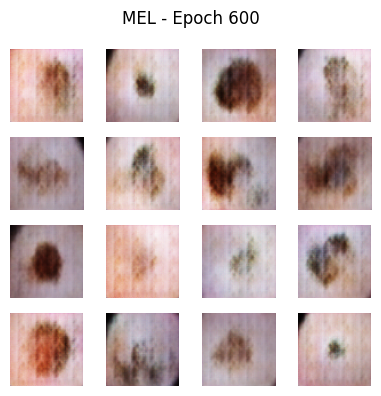

Epoch 602 — G_loss: 0.7306, D_loss: 1.3621
Epoch 603 — G_loss: 0.6853, D_loss: 1.3923
Epoch 604 — G_loss: 0.7206, D_loss: 1.3779
Epoch 605 — G_loss: 0.6870, D_loss: 1.3679
Epoch 606 — G_loss: 0.7210, D_loss: 1.3717
Epoch 607 — G_loss: 0.7097, D_loss: 1.3745
Epoch 608 — G_loss: 0.7297, D_loss: 1.3730
Epoch 609 — G_loss: 0.6927, D_loss: 1.3750
Epoch 610 — G_loss: 0.6933, D_loss: 1.3882
Epoch 611 — G_loss: 0.7145, D_loss: 1.3817
Epoch 612 — G_loss: 0.6931, D_loss: 1.3680
Epoch 613 — G_loss: 0.7101, D_loss: 1.3876
Epoch 614 — G_loss: 0.7017, D_loss: 1.3770
Epoch 615 — G_loss: 0.7056, D_loss: 1.3891
Epoch 616 — G_loss: 0.7097, D_loss: 1.3741
Epoch 617 — G_loss: 0.6900, D_loss: 1.3790
Epoch 618 — G_loss: 0.7230, D_loss: 1.3784
Epoch 619 — G_loss: 0.6878, D_loss: 1.3685
Epoch 620 — G_loss: 0.7289, D_loss: 1.3727
Epoch 621 — G_loss: 0.7011, D_loss: 1.3779
Epoch 622 — G_loss: 0.6978, D_loss: 1.3685
Epoch 623 — G_loss: 0.7194, D_loss: 1.3692
Epoch 624 — G_loss: 0.7054, D_loss: 1.3785
Epoch 625 —

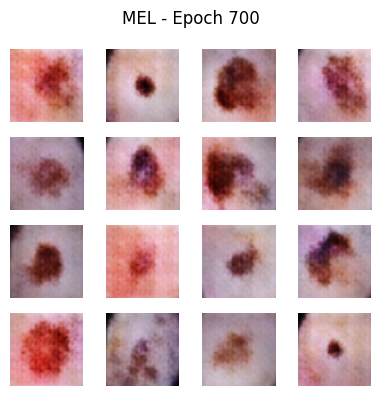

Epoch 702 — G_loss: 0.6976, D_loss: 1.3792
Epoch 703 — G_loss: 0.7222, D_loss: 1.3774
Epoch 704 — G_loss: 0.7020, D_loss: 1.3782
Epoch 705 — G_loss: 0.6996, D_loss: 1.3690
Epoch 706 — G_loss: 0.7205, D_loss: 1.3795
Epoch 707 — G_loss: 0.6942, D_loss: 1.3632
Epoch 708 — G_loss: 0.7198, D_loss: 1.3733
Epoch 709 — G_loss: 0.7053, D_loss: 1.3815
Epoch 710 — G_loss: 0.7129, D_loss: 1.3560
Epoch 711 — G_loss: 0.7132, D_loss: 1.3814
Epoch 712 — G_loss: 0.7198, D_loss: 1.3792
Epoch 713 — G_loss: 0.7113, D_loss: 1.3728
Epoch 714 — G_loss: 0.6957, D_loss: 1.3514
Epoch 715 — G_loss: 0.7219, D_loss: 1.3969
Epoch 716 — G_loss: 0.7071, D_loss: 1.3770
Epoch 717 — G_loss: 0.6874, D_loss: 1.3691
Epoch 718 — G_loss: 0.7243, D_loss: 1.3775
Epoch 719 — G_loss: 0.7005, D_loss: 1.3811
Epoch 720 — G_loss: 0.6876, D_loss: 1.3615
Epoch 721 — G_loss: 0.7443, D_loss: 1.3682
Epoch 722 — G_loss: 0.7022, D_loss: 1.3832
Epoch 723 — G_loss: 0.7194, D_loss: 1.3581
Epoch 724 — G_loss: 0.7285, D_loss: 1.3777
Epoch 725 —

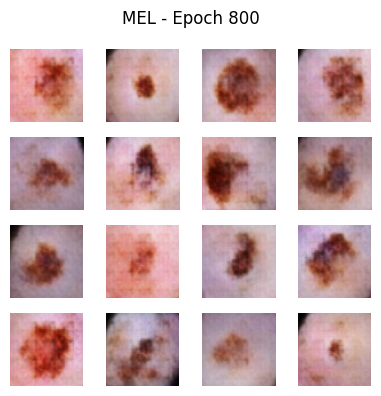

Epoch 802 — G_loss: 0.7200, D_loss: 1.3754
Epoch 803 — G_loss: 0.7003, D_loss: 1.3671
Epoch 804 — G_loss: 0.7074, D_loss: 1.3821
Epoch 805 — G_loss: 0.7230, D_loss: 1.3664
Epoch 806 — G_loss: 0.6840, D_loss: 1.3689
Epoch 807 — G_loss: 0.7161, D_loss: 1.3845
Epoch 808 — G_loss: 0.7196, D_loss: 1.3739
Epoch 809 — G_loss: 0.7127, D_loss: 1.3692
Epoch 810 — G_loss: 0.7100, D_loss: 1.3692
Epoch 811 — G_loss: 0.7303, D_loss: 1.3753
Epoch 812 — G_loss: 0.6849, D_loss: 1.3708
Epoch 813 — G_loss: 0.7332, D_loss: 1.3661
Epoch 814 — G_loss: 0.6872, D_loss: 1.3679
Epoch 815 — G_loss: 0.7325, D_loss: 1.3843
Epoch 816 — G_loss: 0.6952, D_loss: 1.3731
Epoch 817 — G_loss: 0.7060, D_loss: 1.3757
Epoch 818 — G_loss: 0.7176, D_loss: 1.3726
Epoch 819 — G_loss: 0.6961, D_loss: 1.3604
Epoch 820 — G_loss: 0.7209, D_loss: 1.3740
Epoch 821 — G_loss: 0.7167, D_loss: 1.3622
Epoch 822 — G_loss: 0.7131, D_loss: 1.3796
Epoch 823 — G_loss: 0.6849, D_loss: 1.3645
Epoch 824 — G_loss: 0.7542, D_loss: 1.3705
Epoch 825 —

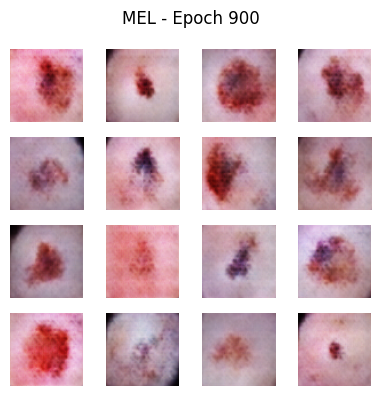

Epoch 902 — G_loss: 0.7176, D_loss: 1.3574
Epoch 903 — G_loss: 0.7035, D_loss: 1.3753
Epoch 904 — G_loss: 0.7286, D_loss: 1.3650
Epoch 905 — G_loss: 0.6968, D_loss: 1.3772
Epoch 906 — G_loss: 0.7209, D_loss: 1.3676
Epoch 907 — G_loss: 0.7047, D_loss: 1.3585
Epoch 908 — G_loss: 0.7188, D_loss: 1.3819
Epoch 909 — G_loss: 0.7022, D_loss: 1.3622
Epoch 910 — G_loss: 0.7478, D_loss: 1.3696
Epoch 911 — G_loss: 0.6695, D_loss: 1.3645
Epoch 912 — G_loss: 0.7590, D_loss: 1.3718
Epoch 913 — G_loss: 0.6955, D_loss: 1.3743
Epoch 914 — G_loss: 0.7335, D_loss: 1.3591
Epoch 915 — G_loss: 0.6955, D_loss: 1.3726
Epoch 916 — G_loss: 0.7434, D_loss: 1.3496
Epoch 917 — G_loss: 0.6941, D_loss: 1.3721
Epoch 918 — G_loss: 0.7149, D_loss: 1.3921
Epoch 919 — G_loss: 0.7054, D_loss: 1.3732
Epoch 920 — G_loss: 0.7046, D_loss: 1.3755
Epoch 921 — G_loss: 0.7294, D_loss: 1.3762
Epoch 922 — G_loss: 0.6859, D_loss: 1.3761
Epoch 923 — G_loss: 0.7186, D_loss: 1.3655
Epoch 924 — G_loss: 0.7105, D_loss: 1.3703
Epoch 925 —

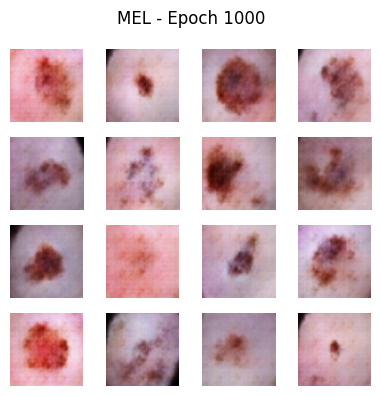

Epoch 1002 — G_loss: 0.7357, D_loss: 1.3692
Epoch 1003 — G_loss: 0.6879, D_loss: 1.3643
Epoch 1004 — G_loss: 0.7422, D_loss: 1.3746
Epoch 1005 — G_loss: 0.7046, D_loss: 1.3667
Epoch 1006 — G_loss: 0.7071, D_loss: 1.3617
Epoch 1007 — G_loss: 0.7307, D_loss: 1.3709
Epoch 1008 — G_loss: 0.6927, D_loss: 1.3627
Epoch 1009 — G_loss: 0.7204, D_loss: 1.3629
Epoch 1010 — G_loss: 0.7211, D_loss: 1.3649
Epoch 1011 — G_loss: 0.7179, D_loss: 1.3562
Epoch 1012 — G_loss: 0.7184, D_loss: 1.3658
Epoch 1013 — G_loss: 0.6989, D_loss: 1.3778
Epoch 1014 — G_loss: 0.7275, D_loss: 1.3693
Epoch 1015 — G_loss: 0.7123, D_loss: 1.3577
Epoch 1016 — G_loss: 0.7114, D_loss: 1.3786
Epoch 1017 — G_loss: 0.7151, D_loss: 1.3736
Epoch 1018 — G_loss: 0.7127, D_loss: 1.3534
Epoch 1019 — G_loss: 0.7091, D_loss: 1.3920
Epoch 1020 — G_loss: 0.7222, D_loss: 1.3643
Epoch 1021 — G_loss: 0.7015, D_loss: 1.3564
Epoch 1022 — G_loss: 0.7161, D_loss: 1.3771
Epoch 1023 — G_loss: 0.7322, D_loss: 1.3606
Epoch 1024 — G_loss: 0.7183, D_l

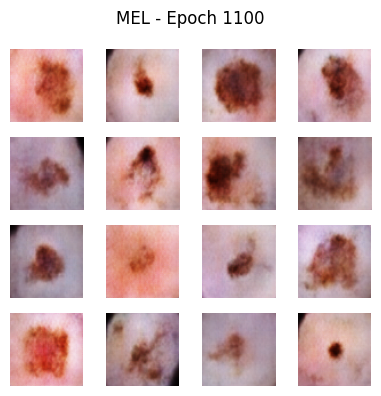

Epoch 1102 — G_loss: 0.7149, D_loss: 1.3765
Epoch 1103 — G_loss: 0.7174, D_loss: 1.3581
Epoch 1104 — G_loss: 0.7097, D_loss: 1.3706
Epoch 1105 — G_loss: 0.7461, D_loss: 1.3652
Epoch 1106 — G_loss: 0.6940, D_loss: 1.3605
Epoch 1107 — G_loss: 0.7246, D_loss: 1.3693
Epoch 1108 — G_loss: 0.7300, D_loss: 1.3717
Epoch 1109 — G_loss: 0.7014, D_loss: 1.3642
Epoch 1110 — G_loss: 0.7260, D_loss: 1.3593
Epoch 1111 — G_loss: 0.7167, D_loss: 1.3708
Epoch 1112 — G_loss: 0.7221, D_loss: 1.3642
Epoch 1113 — G_loss: 0.7081, D_loss: 1.3637
Epoch 1114 — G_loss: 0.7312, D_loss: 1.3621
Epoch 1115 — G_loss: 0.7007, D_loss: 1.3730
Epoch 1116 — G_loss: 0.7193, D_loss: 1.3665
Epoch 1117 — G_loss: 0.7269, D_loss: 1.3670
Epoch 1118 — G_loss: 0.7061, D_loss: 1.3687
Epoch 1119 — G_loss: 0.7085, D_loss: 1.3621
Epoch 1120 — G_loss: 0.7310, D_loss: 1.3654
Epoch 1121 — G_loss: 0.7181, D_loss: 1.3666
Epoch 1122 — G_loss: 0.7019, D_loss: 1.3708
Epoch 1123 — G_loss: 0.7119, D_loss: 1.3590
Epoch 1124 — G_loss: 0.7688, D_l

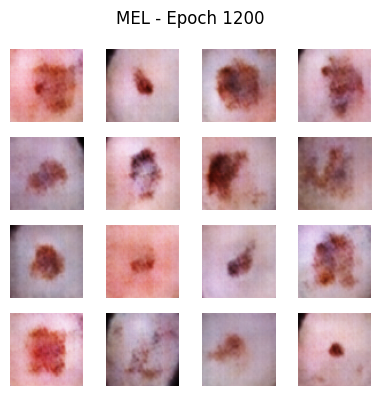

Epoch 1202 — G_loss: 0.7088, D_loss: 1.3640
Epoch 1203 — G_loss: 0.7394, D_loss: 1.3596
Epoch 1204 — G_loss: 0.6894, D_loss: 1.3600
Epoch 1205 — G_loss: 0.7427, D_loss: 1.3657
Epoch 1206 — G_loss: 0.7322, D_loss: 1.3468
Epoch 1207 — G_loss: 0.6990, D_loss: 1.3761
Epoch 1208 — G_loss: 0.7465, D_loss: 1.3524
Epoch 1209 — G_loss: 0.7204, D_loss: 1.3543
Epoch 1210 — G_loss: 0.7008, D_loss: 1.3687
Epoch 1211 — G_loss: 0.7282, D_loss: 1.3640
Epoch 1212 — G_loss: 0.7330, D_loss: 1.3439
Epoch 1213 — G_loss: 0.7169, D_loss: 1.3657
Epoch 1214 — G_loss: 0.7111, D_loss: 1.3641
Epoch 1215 — G_loss: 0.7266, D_loss: 1.3498
Epoch 1216 — G_loss: 0.7083, D_loss: 1.3679
Epoch 1217 — G_loss: 0.7386, D_loss: 1.3635
Epoch 1218 — G_loss: 0.7199, D_loss: 1.3577
Epoch 1219 — G_loss: 0.7097, D_loss: 1.3545
Epoch 1220 — G_loss: 0.7219, D_loss: 1.3784
Epoch 1221 — G_loss: 0.7305, D_loss: 1.3612
Epoch 1222 — G_loss: 0.7065, D_loss: 1.3581
Epoch 1223 — G_loss: 0.7331, D_loss: 1.3617
Epoch 1224 — G_loss: 0.7165, D_l

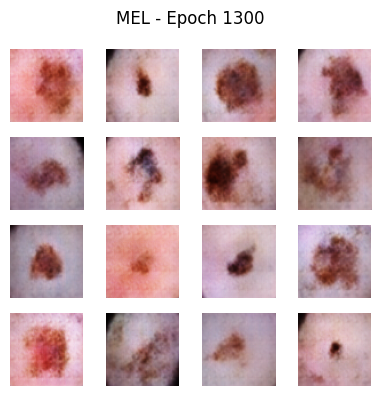

Epoch 1302 — G_loss: 0.7200, D_loss: 1.3541
Epoch 1303 — G_loss: 0.7331, D_loss: 1.3552
Epoch 1304 — G_loss: 0.7204, D_loss: 1.3599
Epoch 1305 — G_loss: 0.7218, D_loss: 1.3531
Epoch 1306 — G_loss: 0.7208, D_loss: 1.3517
Epoch 1307 — G_loss: 0.7358, D_loss: 1.3531
Epoch 1308 — G_loss: 0.7184, D_loss: 1.3541
Epoch 1309 — G_loss: 0.7168, D_loss: 1.3568
Epoch 1310 — G_loss: 0.7510, D_loss: 1.3414
Epoch 1311 — G_loss: 0.7289, D_loss: 1.3551
Epoch 1312 — G_loss: 0.7224, D_loss: 1.3469
Epoch 1313 — G_loss: 0.7379, D_loss: 1.3674
Epoch 1314 — G_loss: 0.7108, D_loss: 1.3556
Epoch 1315 — G_loss: 0.7373, D_loss: 1.3680
Epoch 1316 — G_loss: 0.7203, D_loss: 1.3585
Epoch 1317 — G_loss: 0.7256, D_loss: 1.3559
Epoch 1318 — G_loss: 0.7496, D_loss: 1.3568
Epoch 1319 — G_loss: 0.7208, D_loss: 1.3476
Epoch 1320 — G_loss: 0.7213, D_loss: 1.3748
Epoch 1321 — G_loss: 0.7368, D_loss: 1.3501
Epoch 1322 — G_loss: 0.7122, D_loss: 1.3454
Epoch 1323 — G_loss: 0.7347, D_loss: 1.3534
Epoch 1324 — G_loss: 0.7376, D_l

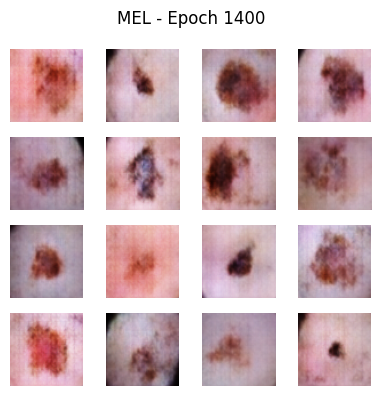

Epoch 1402 — G_loss: 0.7382, D_loss: 1.3569
Epoch 1403 — G_loss: 0.7403, D_loss: 1.3530
Epoch 1404 — G_loss: 0.7375, D_loss: 1.3463
Epoch 1405 — G_loss: 0.7239, D_loss: 1.3483
Epoch 1406 — G_loss: 0.7262, D_loss: 1.3497
Epoch 1407 — G_loss: 0.7316, D_loss: 1.3572
Epoch 1408 — G_loss: 0.7312, D_loss: 1.3500
Epoch 1409 — G_loss: 0.7219, D_loss: 1.3376
Epoch 1410 — G_loss: 0.7400, D_loss: 1.3497
Epoch 1411 — G_loss: 0.7318, D_loss: 1.3481
Epoch 1412 — G_loss: 0.7208, D_loss: 1.3534
Epoch 1413 — G_loss: 0.7365, D_loss: 1.3464
Epoch 1414 — G_loss: 0.7242, D_loss: 1.3488
Epoch 1415 — G_loss: 0.7343, D_loss: 1.3392
Epoch 1416 — G_loss: 0.7341, D_loss: 1.3592
Epoch 1417 — G_loss: 0.7235, D_loss: 1.3362
Epoch 1418 — G_loss: 0.7419, D_loss: 1.3564
Epoch 1419 — G_loss: 0.7539, D_loss: 1.3391
Epoch 1420 — G_loss: 0.7216, D_loss: 1.3605
Epoch 1421 — G_loss: 0.7156, D_loss: 1.3417
Epoch 1422 — G_loss: 0.7655, D_loss: 1.3410
Epoch 1423 — G_loss: 0.7261, D_loss: 1.3528
Epoch 1424 — G_loss: 0.7500, D_l

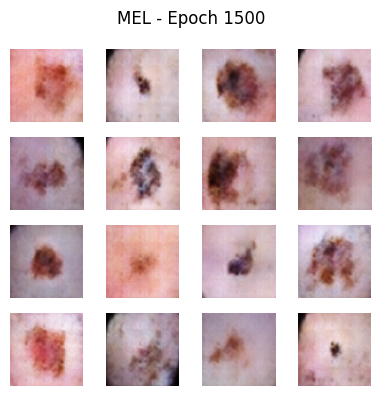

Epoch 1502 — G_loss: 0.7212, D_loss: 1.3433
Epoch 1503 — G_loss: 0.7442, D_loss: 1.3452
Epoch 1504 — G_loss: 0.7269, D_loss: 1.3442
Epoch 1505 — G_loss: 0.7403, D_loss: 1.3512
Epoch 1506 — G_loss: 0.7356, D_loss: 1.3420
Epoch 1507 — G_loss: 0.7451, D_loss: 1.3497
Epoch 1508 — G_loss: 0.7302, D_loss: 1.3546
Epoch 1509 — G_loss: 0.7476, D_loss: 1.3265
Epoch 1510 — G_loss: 0.7225, D_loss: 1.3520
Epoch 1511 — G_loss: 0.7364, D_loss: 1.3458
Epoch 1512 — G_loss: 0.7384, D_loss: 1.3420
Epoch 1513 — G_loss: 0.7311, D_loss: 1.3435
Epoch 1514 — G_loss: 0.7395, D_loss: 1.3369
Epoch 1515 — G_loss: 0.7341, D_loss: 1.3442
Epoch 1516 — G_loss: 0.7446, D_loss: 1.3304
Epoch 1517 — G_loss: 0.7324, D_loss: 1.3635
Epoch 1518 — G_loss: 0.7375, D_loss: 1.3407
Epoch 1519 — G_loss: 0.7505, D_loss: 1.3203
Epoch 1520 — G_loss: 0.7223, D_loss: 1.3691
Epoch 1521 — G_loss: 0.7467, D_loss: 1.3510
Epoch 1522 — G_loss: 0.7307, D_loss: 1.3426
Epoch 1523 — G_loss: 0.7397, D_loss: 1.3407
Epoch 1524 — G_loss: 0.7382, D_l

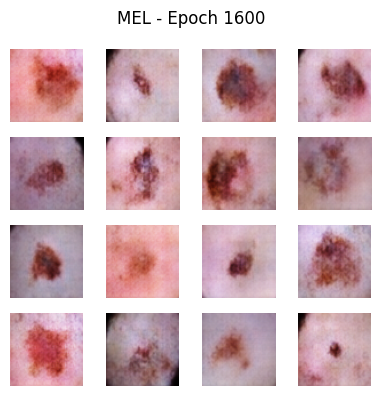

Epoch 1602 — G_loss: 0.7465, D_loss: 1.3360
Epoch 1603 — G_loss: 0.7382, D_loss: 1.3419
Epoch 1604 — G_loss: 0.7429, D_loss: 1.3495
Epoch 1605 — G_loss: 0.7391, D_loss: 1.3396
Epoch 1606 — G_loss: 0.7604, D_loss: 1.3227
Epoch 1607 — G_loss: 0.7299, D_loss: 1.3493
Epoch 1608 — G_loss: 0.7513, D_loss: 1.3376
Epoch 1609 — G_loss: 0.7342, D_loss: 1.3381
Epoch 1610 — G_loss: 0.7586, D_loss: 1.3246
Epoch 1611 — G_loss: 0.7360, D_loss: 1.3515
Epoch 1612 — G_loss: 0.7426, D_loss: 1.3341
Epoch 1613 — G_loss: 0.7510, D_loss: 1.3398
Epoch 1614 — G_loss: 0.7453, D_loss: 1.3382
Epoch 1615 — G_loss: 0.7363, D_loss: 1.3442
Epoch 1616 — G_loss: 0.7614, D_loss: 1.3457
Epoch 1617 — G_loss: 0.7161, D_loss: 1.3460
Epoch 1618 — G_loss: 0.7473, D_loss: 1.3467
Epoch 1619 — G_loss: 0.7475, D_loss: 1.3479
Epoch 1620 — G_loss: 0.7332, D_loss: 1.3474
Epoch 1621 — G_loss: 0.7500, D_loss: 1.3367
Epoch 1622 — G_loss: 0.7319, D_loss: 1.3386
Epoch 1623 — G_loss: 0.7696, D_loss: 1.3379
Epoch 1624 — G_loss: 0.7471, D_l

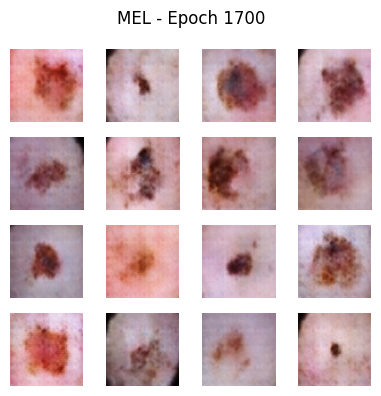

Epoch 1702 — G_loss: 0.7453, D_loss: 1.3402
Epoch 1703 — G_loss: 0.7531, D_loss: 1.3411
Epoch 1704 — G_loss: 0.7282, D_loss: 1.3349
Epoch 1705 — G_loss: 0.7558, D_loss: 1.3479
Epoch 1706 — G_loss: 0.7390, D_loss: 1.3373
Epoch 1707 — G_loss: 0.7559, D_loss: 1.3412
Epoch 1708 — G_loss: 0.7542, D_loss: 1.3361
Epoch 1709 — G_loss: 0.7403, D_loss: 1.3359
Epoch 1710 — G_loss: 0.7496, D_loss: 1.3381
Epoch 1711 — G_loss: 0.7462, D_loss: 1.3369
Epoch 1712 — G_loss: 0.7494, D_loss: 1.3164
Epoch 1713 — G_loss: 0.7496, D_loss: 1.3288
Epoch 1714 — G_loss: 0.7613, D_loss: 1.3307
Epoch 1715 — G_loss: 0.7510, D_loss: 1.3320
Epoch 1716 — G_loss: 0.7456, D_loss: 1.3196
Epoch 1717 — G_loss: 0.7441, D_loss: 1.3436
Epoch 1718 — G_loss: 0.7517, D_loss: 1.3455
Epoch 1719 — G_loss: 0.7485, D_loss: 1.3281
Epoch 1720 — G_loss: 0.7542, D_loss: 1.3390
Epoch 1721 — G_loss: 0.7530, D_loss: 1.3359
Epoch 1722 — G_loss: 0.7419, D_loss: 1.3229
Epoch 1723 — G_loss: 0.7489, D_loss: 1.3332
Epoch 1724 — G_loss: 0.7478, D_l

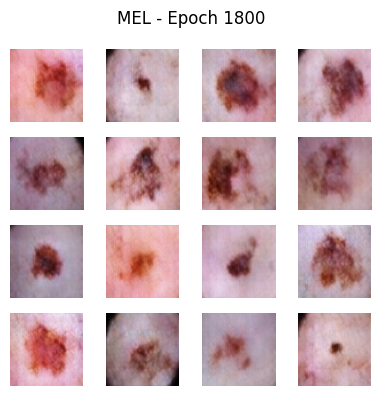

Epoch 1802 — G_loss: 0.7471, D_loss: 1.3234
Epoch 1803 — G_loss: 0.7574, D_loss: 1.3098
Epoch 1804 — G_loss: 0.7485, D_loss: 1.3412
Epoch 1805 — G_loss: 0.7604, D_loss: 1.3107
Epoch 1806 — G_loss: 0.7647, D_loss: 1.3194
Epoch 1807 — G_loss: 0.7639, D_loss: 1.3202
Epoch 1808 — G_loss: 0.7363, D_loss: 1.3426
Epoch 1809 — G_loss: 0.7557, D_loss: 1.3341
Epoch 1810 — G_loss: 0.7405, D_loss: 1.3423
Epoch 1811 — G_loss: 0.7586, D_loss: 1.3333
Epoch 1812 — G_loss: 0.7584, D_loss: 1.3130
Epoch 1813 — G_loss: 0.7458, D_loss: 1.3306
Epoch 1814 — G_loss: 0.7472, D_loss: 1.3338
Epoch 1815 — G_loss: 0.7609, D_loss: 1.3222
Epoch 1816 — G_loss: 0.7521, D_loss: 1.3298
Epoch 1817 — G_loss: 0.7624, D_loss: 1.3227
Epoch 1818 — G_loss: 0.7456, D_loss: 1.3265
Epoch 1819 — G_loss: 0.7578, D_loss: 1.3275
Epoch 1820 — G_loss: 0.7642, D_loss: 1.3527
Epoch 1821 — G_loss: 0.7576, D_loss: 1.3181
Epoch 1822 — G_loss: 0.7395, D_loss: 1.3378
Epoch 1823 — G_loss: 0.7774, D_loss: 1.3207
Epoch 1824 — G_loss: 0.7496, D_l

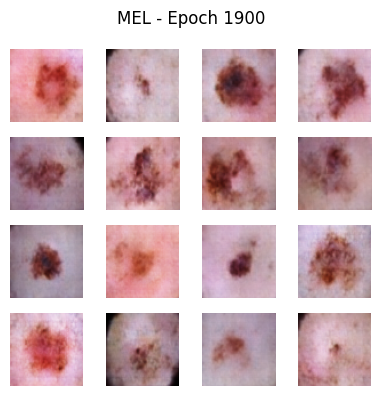

Epoch 1902 — G_loss: 0.7603, D_loss: 1.3216
Epoch 1903 — G_loss: 0.7775, D_loss: 1.3186
Epoch 1904 — G_loss: 0.7485, D_loss: 1.3161
Epoch 1905 — G_loss: 0.7840, D_loss: 1.3090
Epoch 1906 — G_loss: 0.7632, D_loss: 1.3124
Epoch 1907 — G_loss: 0.7590, D_loss: 1.3297
Epoch 1908 — G_loss: 0.7692, D_loss: 1.3049
Epoch 1909 — G_loss: 0.7520, D_loss: 1.3205
Epoch 1910 — G_loss: 0.7686, D_loss: 1.3218
Epoch 1911 — G_loss: 0.7635, D_loss: 1.3201
Epoch 1912 — G_loss: 0.7555, D_loss: 1.3116
Epoch 1913 — G_loss: 0.7616, D_loss: 1.3350
Epoch 1914 — G_loss: 0.7605, D_loss: 1.3127
Epoch 1915 — G_loss: 0.7652, D_loss: 1.3246
Epoch 1916 — G_loss: 0.7480, D_loss: 1.3375
Epoch 1917 — G_loss: 0.7636, D_loss: 1.3232
Epoch 1918 — G_loss: 0.7494, D_loss: 1.3432
Epoch 1919 — G_loss: 0.7496, D_loss: 1.3389
Epoch 1920 — G_loss: 0.7751, D_loss: 1.2993
Epoch 1921 — G_loss: 0.7494, D_loss: 1.3370
Epoch 1922 — G_loss: 0.7664, D_loss: 1.3207
Epoch 1923 — G_loss: 0.7582, D_loss: 1.3270
Epoch 1924 — G_loss: 0.7530, D_l

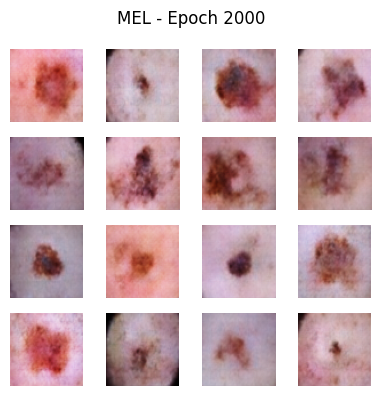

Epoch 2002 — G_loss: 0.7694, D_loss: 1.3157
Epoch 2003 — G_loss: 0.7674, D_loss: 1.3073
Epoch 2004 — G_loss: 0.7798, D_loss: 1.3118
Epoch 2005 — G_loss: 0.7577, D_loss: 1.3240
Epoch 2006 — G_loss: 0.7687, D_loss: 1.3124
Epoch 2007 — G_loss: 0.7725, D_loss: 1.3046
Epoch 2008 — G_loss: 0.7825, D_loss: 1.3084
Epoch 2009 — G_loss: 0.7631, D_loss: 1.3144
Epoch 2010 — G_loss: 0.7717, D_loss: 1.3065
Epoch 2011 — G_loss: 0.7743, D_loss: 1.3157
Epoch 2012 — G_loss: 0.7626, D_loss: 1.3050
Epoch 2013 — G_loss: 0.7835, D_loss: 1.3257
Epoch 2014 — G_loss: 0.7553, D_loss: 1.3110
Epoch 2015 — G_loss: 0.7700, D_loss: 1.3115
Epoch 2016 — G_loss: 0.7729, D_loss: 1.3157
Epoch 2017 — G_loss: 0.7578, D_loss: 1.3220
Epoch 2018 — G_loss: 0.7733, D_loss: 1.2991
Epoch 2019 — G_loss: 0.7590, D_loss: 1.3199
Epoch 2020 — G_loss: 0.7826, D_loss: 1.3049
Epoch 2021 — G_loss: 0.7618, D_loss: 1.3062
Epoch 2022 — G_loss: 0.7756, D_loss: 1.3151
Epoch 2023 — G_loss: 0.7602, D_loss: 1.3226
Epoch 2024 — G_loss: 0.7765, D_l

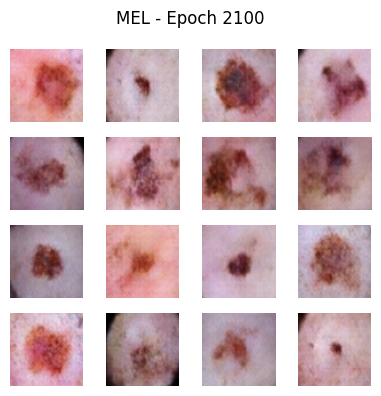

Epoch 2102 — G_loss: 0.7886, D_loss: 1.2953
Epoch 2103 — G_loss: 0.7774, D_loss: 1.3005
Epoch 2104 — G_loss: 0.7859, D_loss: 1.2956
Epoch 2105 — G_loss: 0.7875, D_loss: 1.2978
Epoch 2106 — G_loss: 0.7754, D_loss: 1.3058
Epoch 2107 — G_loss: 0.7792, D_loss: 1.2992
Epoch 2108 — G_loss: 0.7849, D_loss: 1.2967
Epoch 2109 — G_loss: 0.7865, D_loss: 1.3059
Epoch 2110 — G_loss: 0.7805, D_loss: 1.2948
Epoch 2111 — G_loss: 0.7712, D_loss: 1.2964
Epoch 2112 — G_loss: 0.7753, D_loss: 1.3205
Epoch 2113 — G_loss: 0.7718, D_loss: 1.3149
Epoch 2114 — G_loss: 0.7878, D_loss: 1.3109
Epoch 2115 — G_loss: 0.7689, D_loss: 1.2971
Epoch 2116 — G_loss: 0.7769, D_loss: 1.3070
Epoch 2117 — G_loss: 0.7863, D_loss: 1.2935
Epoch 2118 — G_loss: 0.7841, D_loss: 1.3008
Epoch 2119 — G_loss: 0.7809, D_loss: 1.3051
Epoch 2120 — G_loss: 0.7772, D_loss: 1.2997
Epoch 2121 — G_loss: 0.7675, D_loss: 1.3267
Epoch 2122 — G_loss: 0.7796, D_loss: 1.2971
Epoch 2123 — G_loss: 0.7868, D_loss: 1.2969
Epoch 2124 — G_loss: 0.7651, D_l

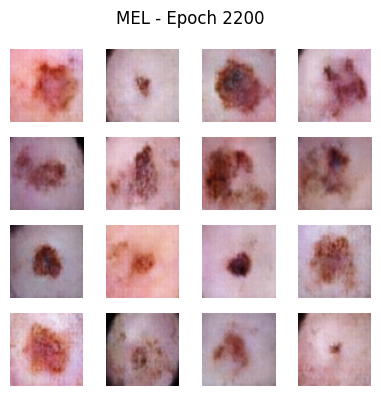

Epoch 2202 — G_loss: 0.7814, D_loss: 1.3035
Epoch 2203 — G_loss: 0.7799, D_loss: 1.3058
Epoch 2204 — G_loss: 0.7689, D_loss: 1.3140
Epoch 2205 — G_loss: 0.7773, D_loss: 1.3016
Epoch 2206 — G_loss: 0.7889, D_loss: 1.3083
Epoch 2207 — G_loss: 0.7559, D_loss: 1.3122
Epoch 2208 — G_loss: 0.7856, D_loss: 1.3040
Epoch 2209 — G_loss: 0.7954, D_loss: 1.2865
Epoch 2210 — G_loss: 0.7841, D_loss: 1.3061
Epoch 2211 — G_loss: 0.7782, D_loss: 1.3092
Epoch 2212 — G_loss: 0.7891, D_loss: 1.2923
Epoch 2213 — G_loss: 0.7768, D_loss: 1.3018
Epoch 2214 — G_loss: 0.7872, D_loss: 1.3059
Epoch 2215 — G_loss: 0.7820, D_loss: 1.2941
Epoch 2216 — G_loss: 0.7880, D_loss: 1.3006
Epoch 2217 — G_loss: 0.7819, D_loss: 1.3127
Epoch 2218 — G_loss: 0.7817, D_loss: 1.2839
Epoch 2219 — G_loss: 0.7769, D_loss: 1.3028
Epoch 2220 — G_loss: 0.7970, D_loss: 1.2992
Epoch 2221 — G_loss: 0.7678, D_loss: 1.3082
Epoch 2222 — G_loss: 0.7979, D_loss: 1.2945
Epoch 2223 — G_loss: 0.7797, D_loss: 1.3114
Epoch 2224 — G_loss: 0.7742, D_l

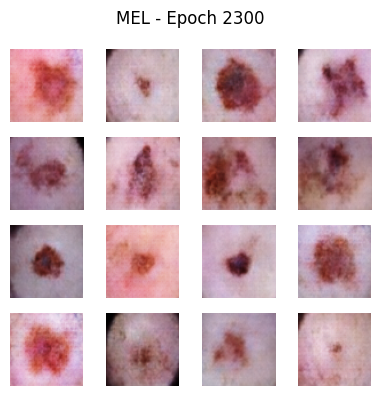

Epoch 2302 — G_loss: 0.8025, D_loss: 1.2934
Epoch 2303 — G_loss: 0.7853, D_loss: 1.2925
Epoch 2304 — G_loss: 0.8053, D_loss: 1.2904
Epoch 2305 — G_loss: 0.7802, D_loss: 1.3064
Epoch 2306 — G_loss: 0.7961, D_loss: 1.2763
Epoch 2307 — G_loss: 0.7920, D_loss: 1.2907
Epoch 2308 — G_loss: 0.7886, D_loss: 1.2978
Epoch 2309 — G_loss: 0.7895, D_loss: 1.2962
Epoch 2310 — G_loss: 0.8057, D_loss: 1.2795
Epoch 2311 — G_loss: 0.7921, D_loss: 1.2903
Epoch 2312 — G_loss: 0.7984, D_loss: 1.2904
Epoch 2313 — G_loss: 0.7823, D_loss: 1.3123
Epoch 2314 — G_loss: 0.7921, D_loss: 1.2982
Epoch 2315 — G_loss: 0.7936, D_loss: 1.2886
Epoch 2316 — G_loss: 0.8016, D_loss: 1.2836
Epoch 2317 — G_loss: 0.7866, D_loss: 1.2820
Epoch 2318 — G_loss: 0.7923, D_loss: 1.3018
Epoch 2319 — G_loss: 0.7898, D_loss: 1.3010
Epoch 2320 — G_loss: 0.7979, D_loss: 1.2815
Epoch 2321 — G_loss: 0.7954, D_loss: 1.3031
Epoch 2322 — G_loss: 0.7802, D_loss: 1.2992
Epoch 2323 — G_loss: 0.7985, D_loss: 1.2966
Epoch 2324 — G_loss: 0.7957, D_l

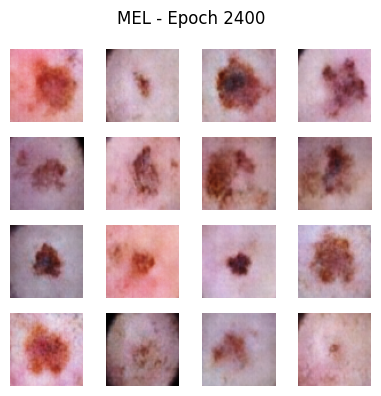

Epoch 2402 — G_loss: 0.8066, D_loss: 1.2703
Epoch 2403 — G_loss: 0.8061, D_loss: 1.2896
Epoch 2404 — G_loss: 0.7890, D_loss: 1.2823
Epoch 2405 — G_loss: 0.8113, D_loss: 1.2843
Epoch 2406 — G_loss: 0.8036, D_loss: 1.2812
Epoch 2407 — G_loss: 0.7951, D_loss: 1.2734
Epoch 2408 — G_loss: 0.8045, D_loss: 1.2949
Epoch 2409 — G_loss: 0.7949, D_loss: 1.2741
Epoch 2410 — G_loss: 0.7800, D_loss: 1.2791
Epoch 2411 — G_loss: 0.8168, D_loss: 1.2804
Epoch 2412 — G_loss: 0.7967, D_loss: 1.2939
Epoch 2413 — G_loss: 0.8070, D_loss: 1.2890
Epoch 2414 — G_loss: 0.7948, D_loss: 1.2883
Epoch 2415 — G_loss: 0.8126, D_loss: 1.2691
Epoch 2416 — G_loss: 0.8143, D_loss: 1.2705
Epoch 2417 — G_loss: 0.8038, D_loss: 1.2865
Epoch 2418 — G_loss: 0.8117, D_loss: 1.2804
Epoch 2419 — G_loss: 0.7939, D_loss: 1.2845
Epoch 2420 — G_loss: 0.8057, D_loss: 1.2716
Epoch 2421 — G_loss: 0.7904, D_loss: 1.3399
Epoch 2422 — G_loss: 0.8149, D_loss: 1.2729
Epoch 2423 — G_loss: 0.8164, D_loss: 1.2890
Epoch 2424 — G_loss: 0.8013, D_l

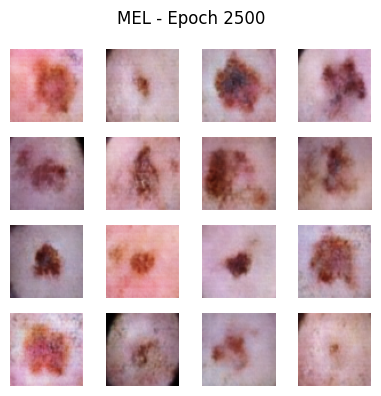

Epoch 2502 — G_loss: 0.8026, D_loss: 1.2873
Epoch 2503 — G_loss: 0.8063, D_loss: 1.3016
Epoch 2504 — G_loss: 0.7985, D_loss: 1.2661
Epoch 2505 — G_loss: 0.8323, D_loss: 1.2755
Epoch 2506 — G_loss: 0.8113, D_loss: 1.2722
Epoch 2507 — G_loss: 0.8088, D_loss: 1.2754
Epoch 2508 — G_loss: 0.8080, D_loss: 1.2737
Epoch 2509 — G_loss: 0.7943, D_loss: 1.2899
Epoch 2510 — G_loss: 0.8044, D_loss: 1.2872
Epoch 2511 — G_loss: 0.8129, D_loss: 1.2730
Epoch 2512 — G_loss: 0.8038, D_loss: 1.2746
Epoch 2513 — G_loss: 0.8105, D_loss: 1.2916
Epoch 2514 — G_loss: 0.8013, D_loss: 1.2801
Epoch 2515 — G_loss: 0.8104, D_loss: 1.2817
Epoch 2516 — G_loss: 0.8186, D_loss: 1.2811
Epoch 2517 — G_loss: 0.8135, D_loss: 1.2636
Epoch 2518 — G_loss: 0.8118, D_loss: 1.2746
Epoch 2519 — G_loss: 0.8144, D_loss: 1.2712
Epoch 2520 — G_loss: 0.8064, D_loss: 1.2799
Epoch 2521 — G_loss: 0.8182, D_loss: 1.2784
Epoch 2522 — G_loss: 0.8170, D_loss: 1.2682
Epoch 2523 — G_loss: 0.8168, D_loss: 1.2687
Epoch 2524 — G_loss: 0.8116, D_l

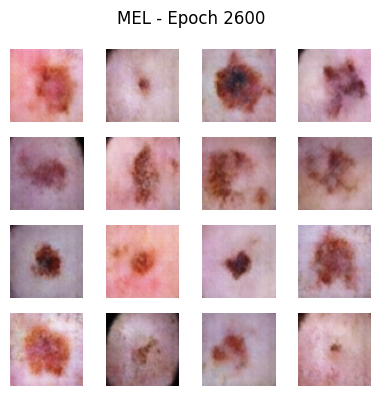

Epoch 2602 — G_loss: 0.8183, D_loss: 1.2799
Epoch 2603 — G_loss: 0.8039, D_loss: 1.2775
Epoch 2604 — G_loss: 0.8208, D_loss: 1.2579
Epoch 2605 — G_loss: 0.8196, D_loss: 1.2728
Epoch 2606 — G_loss: 0.8079, D_loss: 1.2749
Epoch 2607 — G_loss: 0.8165, D_loss: 1.2789
Epoch 2608 — G_loss: 0.8176, D_loss: 1.2682
Epoch 2609 — G_loss: 0.8253, D_loss: 1.2603
Epoch 2610 — G_loss: 0.8184, D_loss: 1.2462
Epoch 2611 — G_loss: 0.8313, D_loss: 1.2715
Epoch 2612 — G_loss: 0.8159, D_loss: 1.2797
Epoch 2613 — G_loss: 0.8012, D_loss: 1.2923
Epoch 2614 — G_loss: 0.8277, D_loss: 1.2642
Epoch 2615 — G_loss: 0.8250, D_loss: 1.2575
Epoch 2616 — G_loss: 0.7976, D_loss: 1.2888
Epoch 2617 — G_loss: 0.8137, D_loss: 1.2610
Epoch 2618 — G_loss: 0.8064, D_loss: 1.2865
Epoch 2619 — G_loss: 0.8178, D_loss: 1.2671
Epoch 2620 — G_loss: 0.8074, D_loss: 1.2793
Epoch 2621 — G_loss: 0.8224, D_loss: 1.2639
Epoch 2622 — G_loss: 0.8175, D_loss: 1.2607
Epoch 2623 — G_loss: 0.8283, D_loss: 1.2558
Epoch 2624 — G_loss: 0.7957, D_l

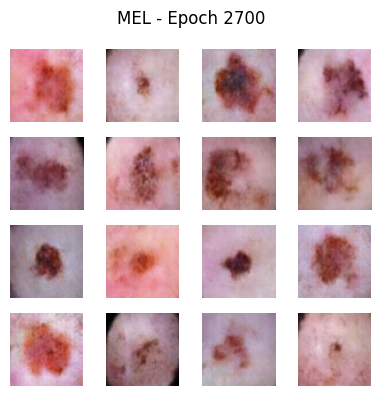

Epoch 2702 — G_loss: 0.8210, D_loss: 1.2719
Epoch 2703 — G_loss: 0.8166, D_loss: 1.2686
Epoch 2704 — G_loss: 0.8335, D_loss: 1.2636
Epoch 2705 — G_loss: 0.8174, D_loss: 1.2756
Epoch 2706 — G_loss: 0.8177, D_loss: 1.2651
Epoch 2707 — G_loss: 0.8193, D_loss: 1.2655
Epoch 2708 — G_loss: 0.8404, D_loss: 1.2566
Epoch 2709 — G_loss: 0.8125, D_loss: 1.2797
Epoch 2710 — G_loss: 0.8283, D_loss: 1.2620
Epoch 2711 — G_loss: 0.8052, D_loss: 1.2770
Epoch 2712 — G_loss: 0.8278, D_loss: 1.2637
Epoch 2713 — G_loss: 0.8292, D_loss: 1.2656
Epoch 2714 — G_loss: 0.8257, D_loss: 1.2666
Epoch 2715 — G_loss: 0.8222, D_loss: 1.2501
Epoch 2716 — G_loss: 0.8327, D_loss: 1.2596
Epoch 2717 — G_loss: 0.8346, D_loss: 1.2615
Epoch 2718 — G_loss: 0.8266, D_loss: 1.2533
Epoch 2719 — G_loss: 0.8357, D_loss: 1.2410
Epoch 2720 — G_loss: 0.8347, D_loss: 1.2673
Epoch 2721 — G_loss: 0.8223, D_loss: 1.2655
Epoch 2722 — G_loss: 0.8266, D_loss: 1.2568
Epoch 2723 — G_loss: 0.8468, D_loss: 1.2423
Epoch 2724 — G_loss: 0.8160, D_l

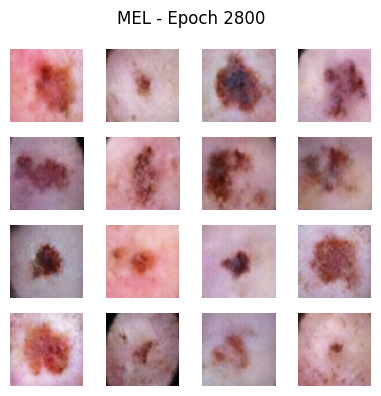

Epoch 2802 — G_loss: 0.8410, D_loss: 1.2419
Epoch 2803 — G_loss: 0.8220, D_loss: 1.2563
Epoch 2804 — G_loss: 0.8421, D_loss: 1.2489
Epoch 2805 — G_loss: 0.8610, D_loss: 1.2149
Epoch 2806 — G_loss: 0.8351, D_loss: 1.2626
Epoch 2807 — G_loss: 0.8422, D_loss: 1.2398
Epoch 2808 — G_loss: 0.8605, D_loss: 1.2352
Epoch 2809 — G_loss: 0.8442, D_loss: 1.2445
Epoch 2810 — G_loss: 0.8420, D_loss: 1.2444
Epoch 2811 — G_loss: 0.8279, D_loss: 1.2535
Epoch 2812 — G_loss: 0.8418, D_loss: 1.2384
Epoch 2813 — G_loss: 0.8294, D_loss: 1.2579
Epoch 2814 — G_loss: 0.8390, D_loss: 1.2552
Epoch 2815 — G_loss: 0.8331, D_loss: 1.2512
Epoch 2816 — G_loss: 0.8563, D_loss: 1.2656
Epoch 2817 — G_loss: 0.8324, D_loss: 1.2363
Epoch 2818 — G_loss: 0.8406, D_loss: 1.2476
Epoch 2819 — G_loss: 0.8466, D_loss: 1.2372
Epoch 2820 — G_loss: 0.8423, D_loss: 1.2365
Epoch 2821 — G_loss: 0.8319, D_loss: 1.2623
Epoch 2822 — G_loss: 0.8524, D_loss: 1.2247
Epoch 2823 — G_loss: 0.8507, D_loss: 1.2757
Epoch 2824 — G_loss: 0.8289, D_l

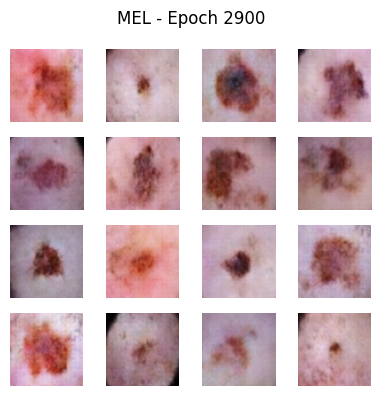

Epoch 2902 — G_loss: 0.8531, D_loss: 1.2511
Epoch 2903 — G_loss: 0.8749, D_loss: 1.2099
Epoch 2904 — G_loss: 0.8560, D_loss: 1.2268
Epoch 2905 — G_loss: 0.8539, D_loss: 1.2383
Epoch 2906 — G_loss: 0.8662, D_loss: 1.2235
Epoch 2907 — G_loss: 0.8470, D_loss: 1.2539
Epoch 2908 — G_loss: 0.8354, D_loss: 1.2489
Epoch 2909 — G_loss: 0.8626, D_loss: 1.2212
Epoch 2910 — G_loss: 0.8619, D_loss: 1.2182
Epoch 2911 — G_loss: 0.8548, D_loss: 1.2461
Epoch 2912 — G_loss: 0.8451, D_loss: 1.2650
Epoch 2913 — G_loss: 0.8648, D_loss: 1.2093
Epoch 2914 — G_loss: 0.8809, D_loss: 1.2221
Epoch 2915 — G_loss: 0.8723, D_loss: 1.2094
Epoch 2916 — G_loss: 0.8799, D_loss: 1.2162
Epoch 2917 — G_loss: 0.8364, D_loss: 1.2459
Epoch 2918 — G_loss: 0.8533, D_loss: 1.2337
Epoch 2919 — G_loss: 0.8425, D_loss: 1.2435
Epoch 2920 — G_loss: 0.8739, D_loss: 1.2136
Epoch 2921 — G_loss: 0.8650, D_loss: 1.2167
Epoch 2922 — G_loss: 0.8763, D_loss: 1.2128
Epoch 2923 — G_loss: 0.8662, D_loss: 1.2390
Epoch 2924 — G_loss: 0.8569, D_l

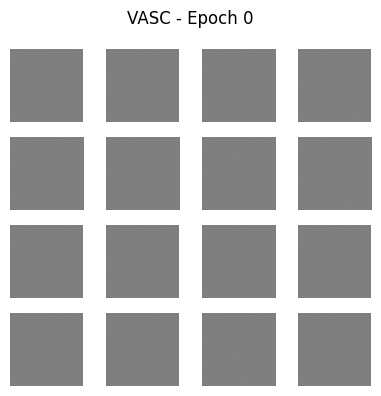

Epoch 2 — G_loss: 0.6536, D_loss: 1.2814
Epoch 3 — G_loss: 0.6550, D_loss: 1.2171
Epoch 4 — G_loss: 0.6511, D_loss: 1.1385
Epoch 5 — G_loss: 0.6761, D_loss: 1.0293
Epoch 6 — G_loss: 0.7200, D_loss: 0.9418
Epoch 7 — G_loss: 0.7694, D_loss: 0.8362
Epoch 8 — G_loss: 0.8383, D_loss: 0.7542
Epoch 9 — G_loss: 0.9609, D_loss: 0.6473
Epoch 10 — G_loss: 1.0930, D_loss: 0.5682
Epoch 11 — G_loss: 1.1900, D_loss: 0.4824
Epoch 12 — G_loss: 1.3026, D_loss: 0.4423
Epoch 13 — G_loss: 1.4359, D_loss: 0.3932
Epoch 14 — G_loss: 1.4684, D_loss: 0.3986
Epoch 15 — G_loss: 1.4909, D_loss: 0.3861
Epoch 16 — G_loss: 1.5533, D_loss: 0.3580
Epoch 17 — G_loss: 1.6685, D_loss: 0.3787
Epoch 18 — G_loss: 1.5892, D_loss: 0.3588
Epoch 19 — G_loss: 1.6520, D_loss: 0.4508
Epoch 20 — G_loss: 1.4546, D_loss: 0.3962
Epoch 21 — G_loss: 1.4975, D_loss: 0.4364
Epoch 22 — G_loss: 1.5241, D_loss: 0.4856
Epoch 23 — G_loss: 1.4480, D_loss: 0.4756
Epoch 24 — G_loss: 1.4089, D_loss: 0.5746
Epoch 25 — G_loss: 1.3886, D_loss: 0.6100


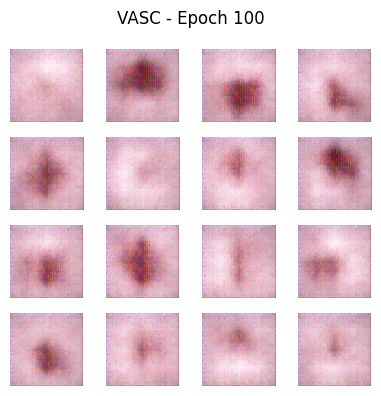

Epoch 102 — G_loss: 0.7593, D_loss: 1.4650
Epoch 103 — G_loss: 0.8040, D_loss: 1.4939
Epoch 104 — G_loss: 0.7168, D_loss: 1.4702
Epoch 105 — G_loss: 0.7733, D_loss: 1.4474
Epoch 106 — G_loss: 0.7842, D_loss: 1.4571
Epoch 107 — G_loss: 0.7645, D_loss: 1.4313
Epoch 108 — G_loss: 0.7970, D_loss: 1.3810
Epoch 109 — G_loss: 0.7562, D_loss: 1.4578
Epoch 110 — G_loss: 0.7674, D_loss: 1.3882
Epoch 111 — G_loss: 0.7743, D_loss: 1.4323
Epoch 112 — G_loss: 0.8214, D_loss: 1.4087
Epoch 113 — G_loss: 0.7531, D_loss: 1.3462
Epoch 114 — G_loss: 0.8013, D_loss: 1.3804
Epoch 115 — G_loss: 0.7887, D_loss: 1.4002
Epoch 116 — G_loss: 0.7916, D_loss: 1.3752
Epoch 117 — G_loss: 0.7954, D_loss: 1.3807
Epoch 118 — G_loss: 0.8059, D_loss: 1.3643
Epoch 119 — G_loss: 0.7957, D_loss: 1.3421
Epoch 120 — G_loss: 0.7964, D_loss: 1.3936
Epoch 121 — G_loss: 0.8023, D_loss: 1.3660
Epoch 122 — G_loss: 0.8139, D_loss: 1.3437
Epoch 123 — G_loss: 0.7795, D_loss: 1.3782
Epoch 124 — G_loss: 0.8125, D_loss: 1.4059
Epoch 125 —

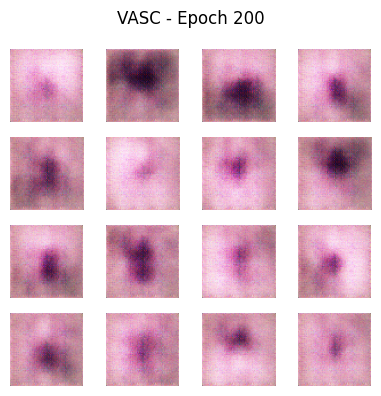

Epoch 202 — G_loss: 0.7836, D_loss: 1.2826
Epoch 203 — G_loss: 0.7779, D_loss: 1.2884
Epoch 204 — G_loss: 0.7697, D_loss: 1.2968
Epoch 205 — G_loss: 0.8009, D_loss: 1.2898
Epoch 206 — G_loss: 0.7610, D_loss: 1.3093
Epoch 207 — G_loss: 0.7673, D_loss: 1.2816
Epoch 208 — G_loss: 0.7783, D_loss: 1.2952
Epoch 209 — G_loss: 0.7711, D_loss: 1.2710
Epoch 210 — G_loss: 0.7777, D_loss: 1.2559
Epoch 211 — G_loss: 0.7689, D_loss: 1.2878
Epoch 212 — G_loss: 0.7645, D_loss: 1.3082
Epoch 213 — G_loss: 0.7477, D_loss: 1.3002
Epoch 214 — G_loss: 0.7823, D_loss: 1.3494
Epoch 215 — G_loss: 0.7619, D_loss: 1.3266
Epoch 216 — G_loss: 0.7456, D_loss: 1.2896
Epoch 217 — G_loss: 0.7664, D_loss: 1.3115
Epoch 218 — G_loss: 0.7700, D_loss: 1.3218
Epoch 219 — G_loss: 0.7493, D_loss: 1.3594
Epoch 220 — G_loss: 0.7292, D_loss: 1.3172
Epoch 221 — G_loss: 0.7377, D_loss: 1.3361
Epoch 222 — G_loss: 0.7542, D_loss: 1.3552
Epoch 223 — G_loss: 0.7422, D_loss: 1.3251
Epoch 224 — G_loss: 0.7420, D_loss: 1.3292
Epoch 225 —

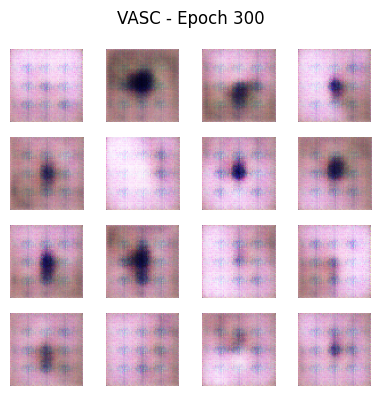

Epoch 302 — G_loss: 0.7850, D_loss: 1.1937
Epoch 303 — G_loss: 0.8273, D_loss: 1.2206
Epoch 304 — G_loss: 0.8108, D_loss: 1.2815
Epoch 305 — G_loss: 0.7800, D_loss: 1.3607
Epoch 306 — G_loss: 0.8253, D_loss: 1.3236
Epoch 307 — G_loss: 0.8443, D_loss: 1.3212
Epoch 308 — G_loss: 0.8658, D_loss: 1.2056
Epoch 309 — G_loss: 0.8651, D_loss: 1.2211
Epoch 310 — G_loss: 0.8261, D_loss: 1.2089
Epoch 311 — G_loss: 0.8221, D_loss: 1.2623
Epoch 312 — G_loss: 0.7663, D_loss: 1.2532
Epoch 313 — G_loss: 0.8171, D_loss: 1.1871
Epoch 314 — G_loss: 0.8154, D_loss: 1.2099
Epoch 315 — G_loss: 0.7592, D_loss: 1.3539
Epoch 316 — G_loss: 0.7179, D_loss: 1.4700
Epoch 317 — G_loss: 0.7389, D_loss: 1.4130
Epoch 318 — G_loss: 0.8446, D_loss: 1.3935
Epoch 319 — G_loss: 0.8198, D_loss: 1.3186
Epoch 320 — G_loss: 0.8153, D_loss: 1.2967
Epoch 321 — G_loss: 0.7695, D_loss: 1.3159
Epoch 322 — G_loss: 0.7283, D_loss: 1.3529
Epoch 323 — G_loss: 0.7453, D_loss: 1.3819
Epoch 324 — G_loss: 0.8040, D_loss: 1.3113
Epoch 325 —

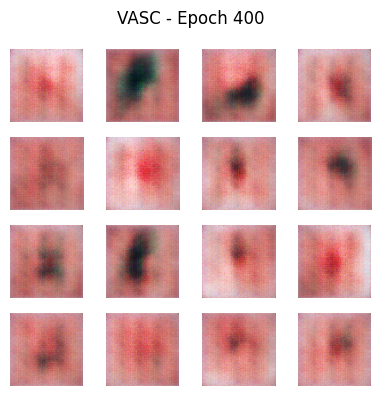

Epoch 402 — G_loss: 0.7369, D_loss: 1.4073
Epoch 403 — G_loss: 0.7767, D_loss: 1.3711
Epoch 404 — G_loss: 0.8205, D_loss: 1.2664
Epoch 405 — G_loss: 0.7889, D_loss: 1.2927
Epoch 406 — G_loss: 0.7490, D_loss: 1.3293
Epoch 407 — G_loss: 0.7015, D_loss: 1.4183
Epoch 408 — G_loss: 0.7039, D_loss: 1.3913
Epoch 409 — G_loss: 0.7474, D_loss: 1.3284
Epoch 410 — G_loss: 0.7737, D_loss: 1.2671
Epoch 411 — G_loss: 0.7650, D_loss: 1.3196
Epoch 412 — G_loss: 0.7359, D_loss: 1.4577
Epoch 413 — G_loss: 0.6966, D_loss: 1.5499
Epoch 414 — G_loss: 0.7132, D_loss: 1.4757
Epoch 415 — G_loss: 0.7798, D_loss: 1.3245
Epoch 416 — G_loss: 0.8434, D_loss: 1.2790
Epoch 417 — G_loss: 0.7640, D_loss: 1.3504
Epoch 418 — G_loss: 0.7016, D_loss: 1.4533
Epoch 419 — G_loss: 0.6869, D_loss: 1.3735
Epoch 420 — G_loss: 0.7455, D_loss: 1.3104
Epoch 421 — G_loss: 0.7837, D_loss: 1.2331
Epoch 422 — G_loss: 0.8090, D_loss: 1.2617
Epoch 423 — G_loss: 0.7886, D_loss: 1.2655
Epoch 424 — G_loss: 0.7526, D_loss: 1.3464
Epoch 425 —

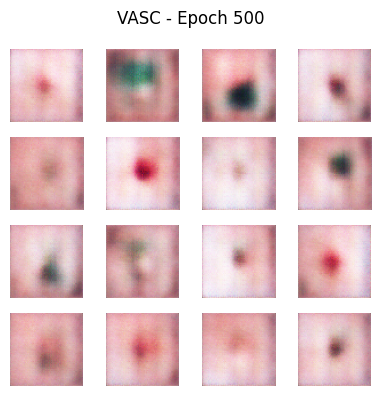

Epoch 502 — G_loss: 0.7860, D_loss: 1.2266
Epoch 503 — G_loss: 0.8085, D_loss: 1.2232
Epoch 504 — G_loss: 0.8029, D_loss: 1.2581
Epoch 505 — G_loss: 0.8226, D_loss: 1.2464
Epoch 506 — G_loss: 0.8434, D_loss: 1.2091
Epoch 507 — G_loss: 0.8292, D_loss: 1.2536
Epoch 508 — G_loss: 0.7555, D_loss: 1.2994
Epoch 509 — G_loss: 0.7166, D_loss: 1.3661
Epoch 510 — G_loss: 0.6933, D_loss: 1.5258
Epoch 511 — G_loss: 0.6853, D_loss: 1.5662
Epoch 512 — G_loss: 0.6413, D_loss: 1.5372
Epoch 513 — G_loss: 0.6873, D_loss: 1.4121
Epoch 514 — G_loss: 0.7068, D_loss: 1.3709
Epoch 515 — G_loss: 0.7446, D_loss: 1.3589
Epoch 516 — G_loss: 0.7218, D_loss: 1.4177
Epoch 517 — G_loss: 0.7339, D_loss: 1.4206
Epoch 518 — G_loss: 0.7525, D_loss: 1.3576
Epoch 519 — G_loss: 0.7727, D_loss: 1.3764
Epoch 520 — G_loss: 0.7886, D_loss: 1.3304
Epoch 521 — G_loss: 0.8391, D_loss: 1.2688
Epoch 522 — G_loss: 0.7793, D_loss: 1.2514
Epoch 523 — G_loss: 0.8299, D_loss: 1.2581
Epoch 524 — G_loss: 0.7741, D_loss: 1.2326
Epoch 525 —

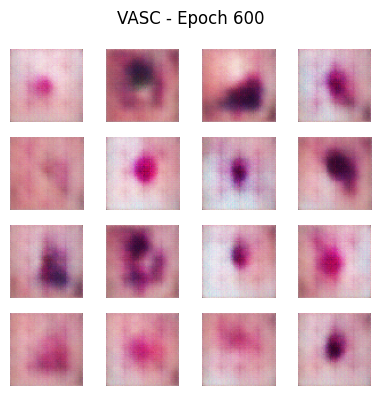

Epoch 602 — G_loss: 0.7852, D_loss: 1.3455
Epoch 603 — G_loss: 0.7011, D_loss: 1.3215
Epoch 604 — G_loss: 0.7464, D_loss: 1.3407
Epoch 605 — G_loss: 0.7439, D_loss: 1.3235
Epoch 606 — G_loss: 0.7619, D_loss: 1.3069
Epoch 607 — G_loss: 0.7588, D_loss: 1.3398
Epoch 608 — G_loss: 0.7213, D_loss: 1.3142
Epoch 609 — G_loss: 0.7906, D_loss: 1.3388
Epoch 610 — G_loss: 0.7311, D_loss: 1.3509
Epoch 611 — G_loss: 0.7229, D_loss: 1.3585
Epoch 612 — G_loss: 0.7250, D_loss: 1.3710
Epoch 613 — G_loss: 0.7411, D_loss: 1.3563
Epoch 614 — G_loss: 0.6990, D_loss: 1.3903
Epoch 615 — G_loss: 0.7285, D_loss: 1.4099
Epoch 616 — G_loss: 0.7178, D_loss: 1.4109
Epoch 617 — G_loss: 0.7066, D_loss: 1.4169
Epoch 618 — G_loss: 0.6719, D_loss: 1.4090
Epoch 619 — G_loss: 0.7356, D_loss: 1.3801
Epoch 620 — G_loss: 0.7094, D_loss: 1.3955
Epoch 621 — G_loss: 0.7212, D_loss: 1.3578
Epoch 622 — G_loss: 0.7224, D_loss: 1.3738
Epoch 623 — G_loss: 0.7359, D_loss: 1.3296
Epoch 624 — G_loss: 0.7860, D_loss: 1.3098
Epoch 625 —

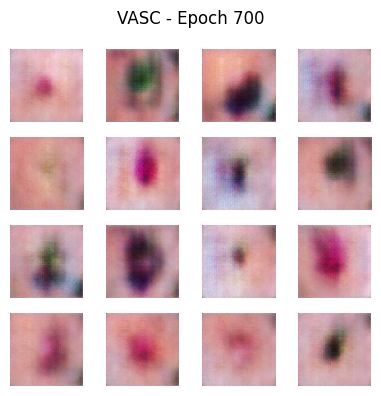

Epoch 702 — G_loss: 0.6721, D_loss: 1.3585
Epoch 703 — G_loss: 0.7656, D_loss: 1.3777
Epoch 704 — G_loss: 0.6539, D_loss: 1.3802
Epoch 705 — G_loss: 0.7273, D_loss: 1.3511
Epoch 706 — G_loss: 0.7083, D_loss: 1.3291
Epoch 707 — G_loss: 0.7575, D_loss: 1.3648
Epoch 708 — G_loss: 0.7292, D_loss: 1.3577
Epoch 709 — G_loss: 0.7236, D_loss: 1.3574
Epoch 710 — G_loss: 0.7340, D_loss: 1.3456
Epoch 711 — G_loss: 0.7227, D_loss: 1.3500
Epoch 712 — G_loss: 0.7287, D_loss: 1.3809
Epoch 713 — G_loss: 0.6470, D_loss: 1.3568
Epoch 714 — G_loss: 0.7002, D_loss: 1.3639
Epoch 715 — G_loss: 0.7291, D_loss: 1.3507
Epoch 716 — G_loss: 0.7062, D_loss: 1.3552
Epoch 717 — G_loss: 0.7016, D_loss: 1.3213
Epoch 718 — G_loss: 0.6956, D_loss: 1.3887
Epoch 719 — G_loss: 0.7149, D_loss: 1.3687
Epoch 720 — G_loss: 0.7051, D_loss: 1.3429
Epoch 721 — G_loss: 0.7306, D_loss: 1.3733
Epoch 722 — G_loss: 0.7184, D_loss: 1.3651
Epoch 723 — G_loss: 0.7420, D_loss: 1.3642
Epoch 724 — G_loss: 0.7208, D_loss: 1.3421
Epoch 725 —

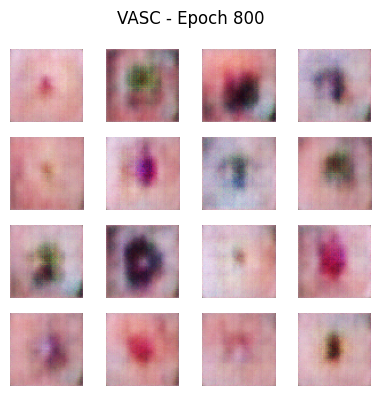

Epoch 802 — G_loss: 0.7158, D_loss: 1.3640
Epoch 803 — G_loss: 0.6919, D_loss: 1.3452
Epoch 804 — G_loss: 0.7055, D_loss: 1.3122
Epoch 805 — G_loss: 0.7725, D_loss: 1.2753
Epoch 806 — G_loss: 0.7173, D_loss: 1.3287
Epoch 807 — G_loss: 0.7212, D_loss: 1.3850
Epoch 808 — G_loss: 0.6977, D_loss: 1.4274
Epoch 809 — G_loss: 0.7502, D_loss: 1.3900
Epoch 810 — G_loss: 0.7576, D_loss: 1.3244
Epoch 811 — G_loss: 0.7932, D_loss: 1.2633
Epoch 812 — G_loss: 0.7660, D_loss: 1.2862
Epoch 813 — G_loss: 0.7588, D_loss: 1.3236
Epoch 814 — G_loss: 0.7219, D_loss: 1.3883
Epoch 815 — G_loss: 0.6435, D_loss: 1.4209
Epoch 816 — G_loss: 0.7514, D_loss: 1.4114
Epoch 817 — G_loss: 0.6635, D_loss: 1.3369
Epoch 818 — G_loss: 0.7497, D_loss: 1.2509
Epoch 819 — G_loss: 0.7627, D_loss: 1.2909
Epoch 820 — G_loss: 0.7264, D_loss: 1.3614
Epoch 821 — G_loss: 0.7138, D_loss: 1.4261
Epoch 822 — G_loss: 0.7147, D_loss: 1.4335
Epoch 823 — G_loss: 0.7536, D_loss: 1.4041
Epoch 824 — G_loss: 0.7834, D_loss: 1.3338
Epoch 825 —

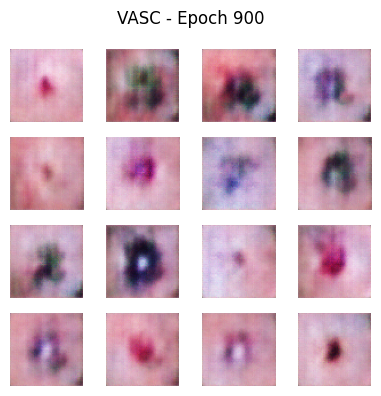

Epoch 902 — G_loss: 0.6478, D_loss: 1.4034
Epoch 903 — G_loss: 0.6911, D_loss: 1.3609
Epoch 904 — G_loss: 0.7118, D_loss: 1.2981
Epoch 905 — G_loss: 0.7425, D_loss: 1.3070
Epoch 906 — G_loss: 0.7096, D_loss: 1.3326
Epoch 907 — G_loss: 0.7699, D_loss: 1.3628
Epoch 908 — G_loss: 0.7247, D_loss: 1.3994
Epoch 909 — G_loss: 0.7049, D_loss: 1.3862
Epoch 910 — G_loss: 0.7728, D_loss: 1.3449
Epoch 911 — G_loss: 0.7596, D_loss: 1.3412
Epoch 912 — G_loss: 0.7619, D_loss: 1.3134
Epoch 913 — G_loss: 0.7478, D_loss: 1.3282
Epoch 914 — G_loss: 0.7419, D_loss: 1.3677
Epoch 915 — G_loss: 0.7138, D_loss: 1.3686
Epoch 916 — G_loss: 0.7007, D_loss: 1.4109
Epoch 917 — G_loss: 0.6936, D_loss: 1.3809
Epoch 918 — G_loss: 0.7192, D_loss: 1.3571
Epoch 919 — G_loss: 0.6821, D_loss: 1.3061
Epoch 920 — G_loss: 0.7182, D_loss: 1.3184
Epoch 921 — G_loss: 0.7431, D_loss: 1.3354
Epoch 922 — G_loss: 0.7425, D_loss: 1.3679
Epoch 923 — G_loss: 0.7153, D_loss: 1.3874
Epoch 924 — G_loss: 0.8122, D_loss: 1.3599
Epoch 925 —

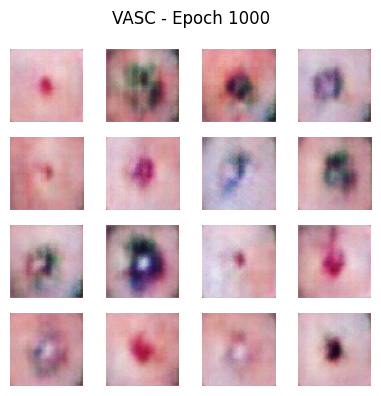

Epoch 1002 — G_loss: 0.7204, D_loss: 1.3231
Epoch 1003 — G_loss: 0.6872, D_loss: 1.3849
Epoch 1004 — G_loss: 0.6760, D_loss: 1.3926
Epoch 1005 — G_loss: 0.7184, D_loss: 1.3881
Epoch 1006 — G_loss: 0.7261, D_loss: 1.3668
Epoch 1007 — G_loss: 0.7139, D_loss: 1.3528
Epoch 1008 — G_loss: 0.7385, D_loss: 1.3279
Epoch 1009 — G_loss: 0.7768, D_loss: 1.3221
Epoch 1010 — G_loss: 0.7590, D_loss: 1.3378
Epoch 1011 — G_loss: 0.7118, D_loss: 1.3314
Epoch 1012 — G_loss: 0.7685, D_loss: 1.3284
Epoch 1013 — G_loss: 0.7222, D_loss: 1.3470
Epoch 1014 — G_loss: 0.7352, D_loss: 1.3956
Epoch 1015 — G_loss: 0.6805, D_loss: 1.4125
Epoch 1016 — G_loss: 0.7035, D_loss: 1.4186
Epoch 1017 — G_loss: 0.7027, D_loss: 1.3506
Epoch 1018 — G_loss: 0.7305, D_loss: 1.3165
Epoch 1019 — G_loss: 0.7688, D_loss: 1.3028
Epoch 1020 — G_loss: 0.7532, D_loss: 1.3037
Epoch 1021 — G_loss: 0.7116, D_loss: 1.3156
Epoch 1022 — G_loss: 0.7605, D_loss: 1.3454
Epoch 1023 — G_loss: 0.7199, D_loss: 1.3551
Epoch 1024 — G_loss: 0.7470, D_l

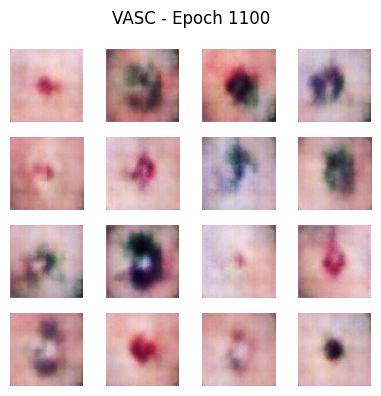

Epoch 1102 — G_loss: 0.7198, D_loss: 1.3593
Epoch 1103 — G_loss: 0.7164, D_loss: 1.3425
Epoch 1104 — G_loss: 0.7432, D_loss: 1.3540
Epoch 1105 — G_loss: 0.7240, D_loss: 1.3586
Epoch 1106 — G_loss: 0.7314, D_loss: 1.3100
Epoch 1107 — G_loss: 0.7441, D_loss: 1.3385
Epoch 1108 — G_loss: 0.7080, D_loss: 1.3890
Epoch 1109 — G_loss: 0.7482, D_loss: 1.3899
Epoch 1110 — G_loss: 0.7155, D_loss: 1.3918
Epoch 1111 — G_loss: 0.7237, D_loss: 1.3698
Epoch 1112 — G_loss: 0.7071, D_loss: 1.3053
Epoch 1113 — G_loss: 0.7886, D_loss: 1.2935
Epoch 1114 — G_loss: 0.7213, D_loss: 1.3118
Epoch 1115 — G_loss: 0.7540, D_loss: 1.3705
Epoch 1116 — G_loss: 0.7010, D_loss: 1.3673
Epoch 1117 — G_loss: 0.7378, D_loss: 1.3735
Epoch 1118 — G_loss: 0.7421, D_loss: 1.3478
Epoch 1119 — G_loss: 0.7036, D_loss: 1.3569
Epoch 1120 — G_loss: 0.7488, D_loss: 1.3512
Epoch 1121 — G_loss: 0.6765, D_loss: 1.3632
Epoch 1122 — G_loss: 0.7460, D_loss: 1.3734
Epoch 1123 — G_loss: 0.7257, D_loss: 1.3884
Epoch 1124 — G_loss: 0.6808, D_l

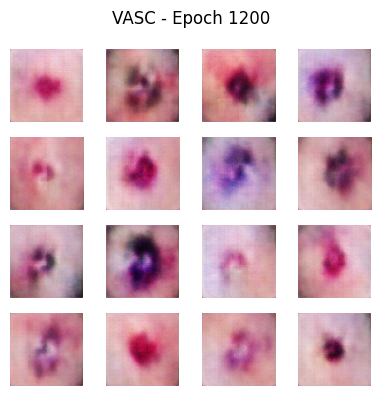

Epoch 1202 — G_loss: 0.7241, D_loss: 1.3262
Epoch 1203 — G_loss: 0.7430, D_loss: 1.3607
Epoch 1204 — G_loss: 0.7058, D_loss: 1.3638
Epoch 1205 — G_loss: 0.7078, D_loss: 1.3566
Epoch 1206 — G_loss: 0.7310, D_loss: 1.3790
Epoch 1207 — G_loss: 0.7036, D_loss: 1.3480
Epoch 1208 — G_loss: 0.7379, D_loss: 1.3434
Epoch 1209 — G_loss: 0.7187, D_loss: 1.3268
Epoch 1210 — G_loss: 0.7455, D_loss: 1.3363
Epoch 1211 — G_loss: 0.7192, D_loss: 1.3549
Epoch 1212 — G_loss: 0.7158, D_loss: 1.3482
Epoch 1213 — G_loss: 0.7506, D_loss: 1.3490
Epoch 1214 — G_loss: 0.7436, D_loss: 1.3241
Epoch 1215 — G_loss: 0.7465, D_loss: 1.2994
Epoch 1216 — G_loss: 0.7516, D_loss: 1.3364
Epoch 1217 — G_loss: 0.7174, D_loss: 1.3647
Epoch 1218 — G_loss: 0.6963, D_loss: 1.4043
Epoch 1219 — G_loss: 0.6872, D_loss: 1.3879
Epoch 1220 — G_loss: 0.7170, D_loss: 1.3543
Epoch 1221 — G_loss: 0.7495, D_loss: 1.2854
Epoch 1222 — G_loss: 0.7705, D_loss: 1.2940
Epoch 1223 — G_loss: 0.7257, D_loss: 1.3381
Epoch 1224 — G_loss: 0.7212, D_l

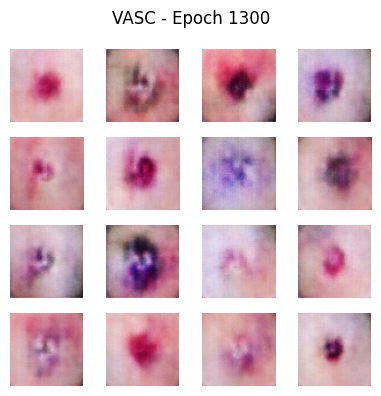

Epoch 1302 — G_loss: 0.7300, D_loss: 1.2960
Epoch 1303 — G_loss: 0.7366, D_loss: 1.3070
Epoch 1304 — G_loss: 0.7625, D_loss: 1.3695
Epoch 1305 — G_loss: 0.7112, D_loss: 1.3547
Epoch 1306 — G_loss: 0.7249, D_loss: 1.3740
Epoch 1307 — G_loss: 0.7083, D_loss: 1.3731
Epoch 1308 — G_loss: 0.7078, D_loss: 1.3999
Epoch 1309 — G_loss: 0.7469, D_loss: 1.3675
Epoch 1310 — G_loss: 0.7313, D_loss: 1.3565
Epoch 1311 — G_loss: 0.7580, D_loss: 1.2945
Epoch 1312 — G_loss: 0.7345, D_loss: 1.2656
Epoch 1313 — G_loss: 0.7042, D_loss: 1.3231
Epoch 1314 — G_loss: 0.7055, D_loss: 1.3432
Epoch 1315 — G_loss: 0.7175, D_loss: 1.4199
Epoch 1316 — G_loss: 0.6862, D_loss: 1.3826
Epoch 1317 — G_loss: 0.7460, D_loss: 1.3657
Epoch 1318 — G_loss: 0.7599, D_loss: 1.3253
Epoch 1319 — G_loss: 0.7132, D_loss: 1.3400
Epoch 1320 — G_loss: 0.7630, D_loss: 1.3151
Epoch 1321 — G_loss: 0.7294, D_loss: 1.3414
Epoch 1322 — G_loss: 0.7600, D_loss: 1.3465
Epoch 1323 — G_loss: 0.7657, D_loss: 1.3323
Epoch 1324 — G_loss: 0.7251, D_l

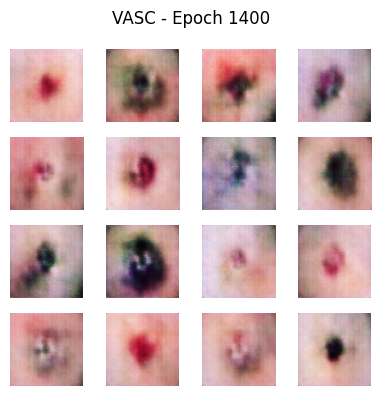

Epoch 1402 — G_loss: 0.7368, D_loss: 1.3691
Epoch 1403 — G_loss: 0.7529, D_loss: 1.3459
Epoch 1404 — G_loss: 0.7898, D_loss: 1.3067
Epoch 1405 — G_loss: 0.7399, D_loss: 1.3428
Epoch 1406 — G_loss: 0.7372, D_loss: 1.3301
Epoch 1407 — G_loss: 0.6965, D_loss: 1.3635
Epoch 1408 — G_loss: 0.6720, D_loss: 1.3807
Epoch 1409 — G_loss: 0.7352, D_loss: 1.3471
Epoch 1410 — G_loss: 0.6998, D_loss: 1.3814
Epoch 1411 — G_loss: 0.7184, D_loss: 1.3674
Epoch 1412 — G_loss: 0.7213, D_loss: 1.3667
Epoch 1413 — G_loss: 0.7421, D_loss: 1.3420
Epoch 1414 — G_loss: 0.7242, D_loss: 1.2583
Epoch 1415 — G_loss: 0.7733, D_loss: 1.2696
Epoch 1416 — G_loss: 0.7676, D_loss: 1.3121
Epoch 1417 — G_loss: 0.6807, D_loss: 1.3963
Epoch 1418 — G_loss: 0.7457, D_loss: 1.4181
Epoch 1419 — G_loss: 0.7369, D_loss: 1.4205
Epoch 1420 — G_loss: 0.7244, D_loss: 1.3354
Epoch 1421 — G_loss: 0.7294, D_loss: 1.3238
Epoch 1422 — G_loss: 0.7256, D_loss: 1.3466
Epoch 1423 — G_loss: 0.7390, D_loss: 1.3264
Epoch 1424 — G_loss: 0.7351, D_l

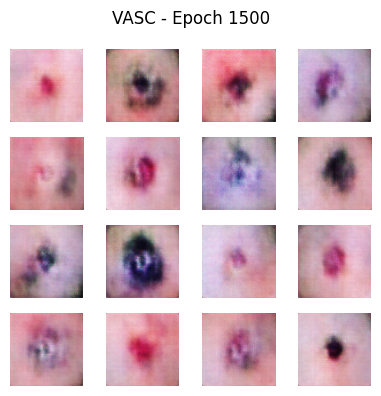

Epoch 1502 — G_loss: 0.7259, D_loss: 1.3441
Epoch 1503 — G_loss: 0.7160, D_loss: 1.3439
Epoch 1504 — G_loss: 0.7348, D_loss: 1.3399
Epoch 1505 — G_loss: 0.7452, D_loss: 1.3386
Epoch 1506 — G_loss: 0.7025, D_loss: 1.3470
Epoch 1507 — G_loss: 0.7490, D_loss: 1.3535
Epoch 1508 — G_loss: 0.7620, D_loss: 1.3114
Epoch 1509 — G_loss: 0.7130, D_loss: 1.3260
Epoch 1510 — G_loss: 0.7476, D_loss: 1.2861
Epoch 1511 — G_loss: 0.7601, D_loss: 1.3306
Epoch 1512 — G_loss: 0.7159, D_loss: 1.3783
Epoch 1513 — G_loss: 0.7133, D_loss: 1.3767
Epoch 1514 — G_loss: 0.7543, D_loss: 1.3353
Epoch 1515 — G_loss: 0.7381, D_loss: 1.3370
Epoch 1516 — G_loss: 0.7357, D_loss: 1.3590
Epoch 1517 — G_loss: 0.6887, D_loss: 1.3230
Epoch 1518 — G_loss: 0.7401, D_loss: 1.3318
Epoch 1519 — G_loss: 0.7124, D_loss: 1.3287
Epoch 1520 — G_loss: 0.7360, D_loss: 1.3510
Epoch 1521 — G_loss: 0.7366, D_loss: 1.3320
Epoch 1522 — G_loss: 0.7732, D_loss: 1.3193
Epoch 1523 — G_loss: 0.7373, D_loss: 1.3246
Epoch 1524 — G_loss: 0.7296, D_l

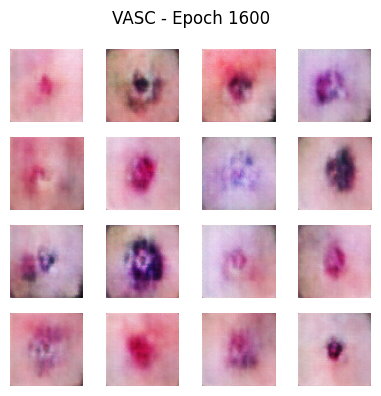

Epoch 1602 — G_loss: 0.7334, D_loss: 1.3517
Epoch 1603 — G_loss: 0.6994, D_loss: 1.3844
Epoch 1604 — G_loss: 0.7251, D_loss: 1.3746
Epoch 1605 — G_loss: 0.7493, D_loss: 1.3467
Epoch 1606 — G_loss: 0.7286, D_loss: 1.3564
Epoch 1607 — G_loss: 0.7600, D_loss: 1.3274
Epoch 1608 — G_loss: 0.7292, D_loss: 1.3560
Epoch 1609 — G_loss: 0.7230, D_loss: 1.3558
Epoch 1610 — G_loss: 0.7235, D_loss: 1.3440
Epoch 1611 — G_loss: 0.7236, D_loss: 1.3390
Epoch 1612 — G_loss: 0.7523, D_loss: 1.3682
Epoch 1613 — G_loss: 0.7287, D_loss: 1.3463
Epoch 1614 — G_loss: 0.6880, D_loss: 1.3681
Epoch 1615 — G_loss: 0.7225, D_loss: 1.3558
Epoch 1616 — G_loss: 0.6690, D_loss: 1.3702
Epoch 1617 — G_loss: 0.7428, D_loss: 1.3319
Epoch 1618 — G_loss: 0.7589, D_loss: 1.3365
Epoch 1619 — G_loss: 0.7349, D_loss: 1.3160
Epoch 1620 — G_loss: 0.7611, D_loss: 1.3141
Epoch 1621 — G_loss: 0.7344, D_loss: 1.3585
Epoch 1622 — G_loss: 0.7289, D_loss: 1.3665
Epoch 1623 — G_loss: 0.7569, D_loss: 1.4001
Epoch 1624 — G_loss: 0.7519, D_l

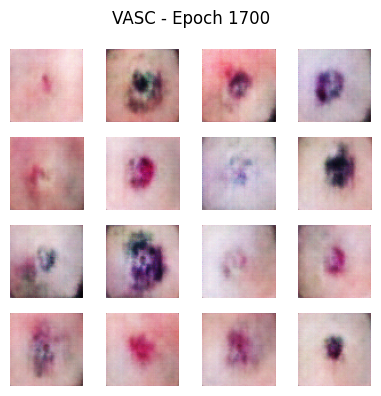

Epoch 1702 — G_loss: 0.7369, D_loss: 1.3003
Epoch 1703 — G_loss: 0.7503, D_loss: 1.3072
Epoch 1704 — G_loss: 0.7881, D_loss: 1.3306
Epoch 1705 — G_loss: 0.7399, D_loss: 1.3266
Epoch 1706 — G_loss: 0.7390, D_loss: 1.4085
Epoch 1707 — G_loss: 0.7120, D_loss: 1.3572
Epoch 1708 — G_loss: 0.7379, D_loss: 1.3652
Epoch 1709 — G_loss: 0.7999, D_loss: 1.3468
Epoch 1710 — G_loss: 0.7305, D_loss: 1.3616
Epoch 1711 — G_loss: 0.7265, D_loss: 1.3524
Epoch 1712 — G_loss: 0.7395, D_loss: 1.3187
Epoch 1713 — G_loss: 0.7411, D_loss: 1.3432
Epoch 1714 — G_loss: 0.7602, D_loss: 1.3500
Epoch 1715 — G_loss: 0.7248, D_loss: 1.3454
Epoch 1716 — G_loss: 0.7183, D_loss: 1.3454
Epoch 1717 — G_loss: 0.7528, D_loss: 1.3560
Epoch 1718 — G_loss: 0.6863, D_loss: 1.3557
Epoch 1719 — G_loss: 0.8141, D_loss: 1.3394
Epoch 1720 — G_loss: 0.7492, D_loss: 1.3119
Epoch 1721 — G_loss: 0.7190, D_loss: 1.3361
Epoch 1722 — G_loss: 0.7447, D_loss: 1.3170
Epoch 1723 — G_loss: 0.7544, D_loss: 1.3413
Epoch 1724 — G_loss: 0.7060, D_l

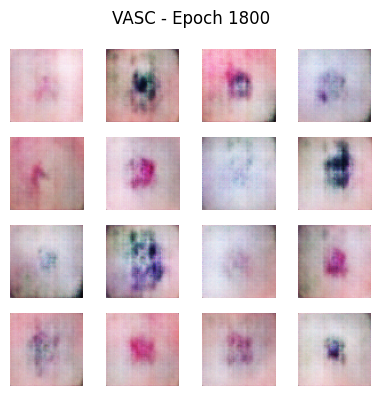

Epoch 1802 — G_loss: 0.7529, D_loss: 1.3155
Epoch 1803 — G_loss: 0.7796, D_loss: 1.2950
Epoch 1804 — G_loss: 0.7639, D_loss: 1.3245
Epoch 1805 — G_loss: 0.7362, D_loss: 1.3094
Epoch 1806 — G_loss: 0.7550, D_loss: 1.3581
Epoch 1807 — G_loss: 0.7099, D_loss: 1.3587
Epoch 1808 — G_loss: 0.6910, D_loss: 1.4138
Epoch 1809 — G_loss: 0.7424, D_loss: 1.3929
Epoch 1810 — G_loss: 0.7249, D_loss: 1.3833
Epoch 1811 — G_loss: 0.7860, D_loss: 1.2979
Epoch 1812 — G_loss: 0.7628, D_loss: 1.3371
Epoch 1813 — G_loss: 0.7228, D_loss: 1.3708
Epoch 1814 — G_loss: 0.7081, D_loss: 1.3543
Epoch 1815 — G_loss: 0.6723, D_loss: 1.3615
Epoch 1816 — G_loss: 0.7481, D_loss: 1.3926
Epoch 1817 — G_loss: 0.7131, D_loss: 1.3241
Epoch 1818 — G_loss: 0.7525, D_loss: 1.3623
Epoch 1819 — G_loss: 0.7505, D_loss: 1.3104
Epoch 1820 — G_loss: 0.7501, D_loss: 1.3590
Epoch 1821 — G_loss: 0.7514, D_loss: 1.3701
Epoch 1822 — G_loss: 0.6683, D_loss: 1.3647
Epoch 1823 — G_loss: 0.7614, D_loss: 1.3490
Epoch 1824 — G_loss: 0.7517, D_l

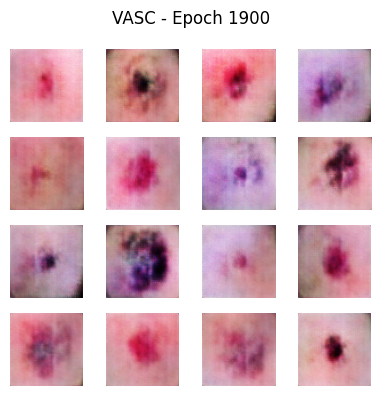

Epoch 1902 — G_loss: 0.7407, D_loss: 1.3457
Epoch 1903 — G_loss: 0.7627, D_loss: 1.3646
Epoch 1904 — G_loss: 0.7445, D_loss: 1.3456
Epoch 1905 — G_loss: 0.7487, D_loss: 1.3577
Epoch 1906 — G_loss: 0.7360, D_loss: 1.3661
Epoch 1907 — G_loss: 0.7425, D_loss: 1.3449
Epoch 1908 — G_loss: 0.7136, D_loss: 1.3211
Epoch 1909 — G_loss: 0.7399, D_loss: 1.3436
Epoch 1910 — G_loss: 0.7363, D_loss: 1.3217
Epoch 1911 — G_loss: 0.7481, D_loss: 1.3216
Epoch 1912 — G_loss: 0.7309, D_loss: 1.3415
Epoch 1913 — G_loss: 0.7469, D_loss: 1.3379
Epoch 1914 — G_loss: 0.7040, D_loss: 1.3657
Epoch 1915 — G_loss: 0.7469, D_loss: 1.3613
Epoch 1916 — G_loss: 0.7279, D_loss: 1.3633
Epoch 1917 — G_loss: 0.7805, D_loss: 1.3630
Epoch 1918 — G_loss: 0.7308, D_loss: 1.3590
Epoch 1919 — G_loss: 0.7404, D_loss: 1.3709
Epoch 1920 — G_loss: 0.7244, D_loss: 1.3585
Epoch 1921 — G_loss: 0.7097, D_loss: 1.3669
Epoch 1922 — G_loss: 0.7144, D_loss: 1.3211
Epoch 1923 — G_loss: 0.7532, D_loss: 1.3301
Epoch 1924 — G_loss: 0.7563, D_l

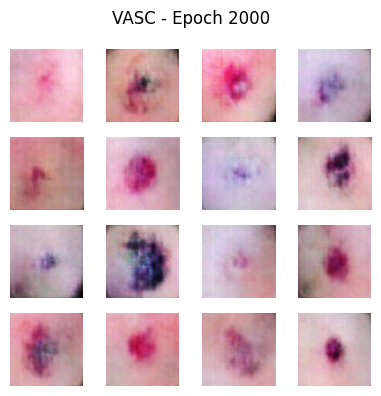

Epoch 2002 — G_loss: 0.7455, D_loss: 1.3555
Epoch 2003 — G_loss: 0.7196, D_loss: 1.3412
Epoch 2004 — G_loss: 0.7591, D_loss: 1.3290
Epoch 2005 — G_loss: 0.7771, D_loss: 1.3601
Epoch 2006 — G_loss: 0.7312, D_loss: 1.3623
Epoch 2007 — G_loss: 0.7072, D_loss: 1.3697
Epoch 2008 — G_loss: 0.7226, D_loss: 1.3024
Epoch 2009 — G_loss: 0.7653, D_loss: 1.3456
Epoch 2010 — G_loss: 0.7353, D_loss: 1.3328
Epoch 2011 — G_loss: 0.7232, D_loss: 1.3607
Epoch 2012 — G_loss: 0.6906, D_loss: 1.3778
Epoch 2013 — G_loss: 0.7453, D_loss: 1.3268
Epoch 2014 — G_loss: 0.7116, D_loss: 1.3403
Epoch 2015 — G_loss: 0.7161, D_loss: 1.3310
Epoch 2016 — G_loss: 0.7689, D_loss: 1.3053
Epoch 2017 — G_loss: 0.7284, D_loss: 1.3521
Epoch 2018 — G_loss: 0.6796, D_loss: 1.4051
Epoch 2019 — G_loss: 0.7567, D_loss: 1.3638
Epoch 2020 — G_loss: 0.8069, D_loss: 1.3471
Epoch 2021 — G_loss: 0.7204, D_loss: 1.3483
Epoch 2022 — G_loss: 0.7667, D_loss: 1.3327
Epoch 2023 — G_loss: 0.7333, D_loss: 1.3472
Epoch 2024 — G_loss: 0.7100, D_l

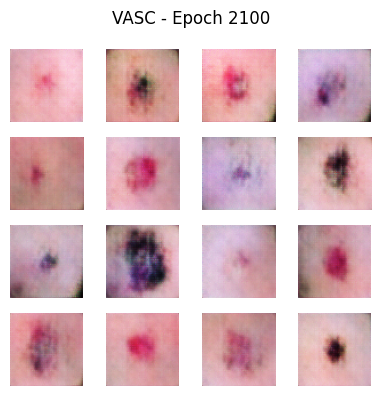

Epoch 2102 — G_loss: 0.7297, D_loss: 1.3216
Epoch 2103 — G_loss: 0.7080, D_loss: 1.3676
Epoch 2104 — G_loss: 0.7066, D_loss: 1.3474
Epoch 2105 — G_loss: 0.7263, D_loss: 1.3518
Epoch 2106 — G_loss: 0.6971, D_loss: 1.3587
Epoch 2107 — G_loss: 0.7257, D_loss: 1.3864
Epoch 2108 — G_loss: 0.7376, D_loss: 1.3558
Epoch 2109 — G_loss: 0.7093, D_loss: 1.3407
Epoch 2110 — G_loss: 0.7361, D_loss: 1.3400
Epoch 2111 — G_loss: 0.7322, D_loss: 1.3665
Epoch 2112 — G_loss: 0.7421, D_loss: 1.3147
Epoch 2113 — G_loss: 0.7584, D_loss: 1.3367
Epoch 2114 — G_loss: 0.7342, D_loss: 1.3661
Epoch 2115 — G_loss: 0.7183, D_loss: 1.3682
Epoch 2116 — G_loss: 0.7194, D_loss: 1.3762
Epoch 2117 — G_loss: 0.7229, D_loss: 1.3570
Epoch 2118 — G_loss: 0.7196, D_loss: 1.3550
Epoch 2119 — G_loss: 0.7243, D_loss: 1.3299
Epoch 2120 — G_loss: 0.7207, D_loss: 1.3280
Epoch 2121 — G_loss: 0.7412, D_loss: 1.3359
Epoch 2122 — G_loss: 0.7113, D_loss: 1.3543
Epoch 2123 — G_loss: 0.7234, D_loss: 1.3611
Epoch 2124 — G_loss: 0.7242, D_l

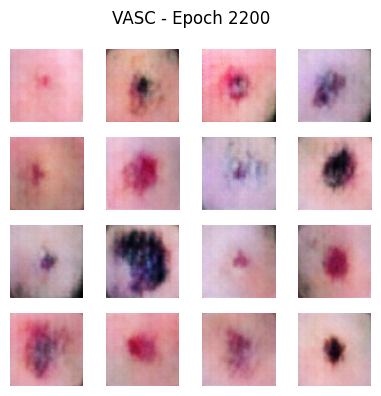

Epoch 2202 — G_loss: 0.7411, D_loss: 1.3670
Epoch 2203 — G_loss: 0.7103, D_loss: 1.3450
Epoch 2204 — G_loss: 0.7148, D_loss: 1.3493
Epoch 2205 — G_loss: 0.7353, D_loss: 1.3491
Epoch 2206 — G_loss: 0.7277, D_loss: 1.3480
Epoch 2207 — G_loss: 0.7183, D_loss: 1.3699
Epoch 2208 — G_loss: 0.7256, D_loss: 1.3375
Epoch 2209 — G_loss: 0.7046, D_loss: 1.3573
Epoch 2210 — G_loss: 0.7348, D_loss: 1.3535
Epoch 2211 — G_loss: 0.7506, D_loss: 1.3633
Epoch 2212 — G_loss: 0.7086, D_loss: 1.3869
Epoch 2213 — G_loss: 0.6933, D_loss: 1.3777
Epoch 2214 — G_loss: 0.7945, D_loss: 1.3531
Epoch 2215 — G_loss: 0.7215, D_loss: 1.3250
Epoch 2216 — G_loss: 0.6787, D_loss: 1.3668
Epoch 2217 — G_loss: 0.7711, D_loss: 1.3548
Epoch 2218 — G_loss: 0.7302, D_loss: 1.3436
Epoch 2219 — G_loss: 0.7558, D_loss: 1.3298
Epoch 2220 — G_loss: 0.7256, D_loss: 1.3363
Epoch 2221 — G_loss: 0.7580, D_loss: 1.3473
Epoch 2222 — G_loss: 0.7630, D_loss: 1.3703
Epoch 2223 — G_loss: 0.7131, D_loss: 1.3566
Epoch 2224 — G_loss: 0.7232, D_l

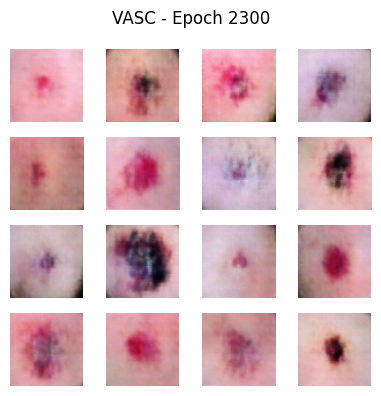

Epoch 2302 — G_loss: 0.7341, D_loss: 1.3467
Epoch 2303 — G_loss: 0.7496, D_loss: 1.3544
Epoch 2304 — G_loss: 0.7028, D_loss: 1.3652
Epoch 2305 — G_loss: 0.7614, D_loss: 1.3495
Epoch 2306 — G_loss: 0.7270, D_loss: 1.3363
Epoch 2307 — G_loss: 0.6886, D_loss: 1.3530
Epoch 2308 — G_loss: 0.7411, D_loss: 1.3753
Epoch 2309 — G_loss: 0.6986, D_loss: 1.3661
Epoch 2310 — G_loss: 0.6991, D_loss: 1.3545
Epoch 2311 — G_loss: 0.7698, D_loss: 1.3256
Epoch 2312 — G_loss: 0.7192, D_loss: 1.3601
Epoch 2313 — G_loss: 0.6993, D_loss: 1.3322
Epoch 2314 — G_loss: 0.7613, D_loss: 1.3369
Epoch 2315 — G_loss: 0.7381, D_loss: 1.3324
Epoch 2316 — G_loss: 0.7789, D_loss: 1.3848
Epoch 2317 — G_loss: 0.6950, D_loss: 1.3693
Epoch 2318 — G_loss: 0.7112, D_loss: 1.3590
Epoch 2319 — G_loss: 0.7813, D_loss: 1.3510
Epoch 2320 — G_loss: 0.7702, D_loss: 1.3196
Epoch 2321 — G_loss: 0.7227, D_loss: 1.3659
Epoch 2322 — G_loss: 0.7565, D_loss: 1.3690
Epoch 2323 — G_loss: 0.7093, D_loss: 1.3688
Epoch 2324 — G_loss: 0.7365, D_l

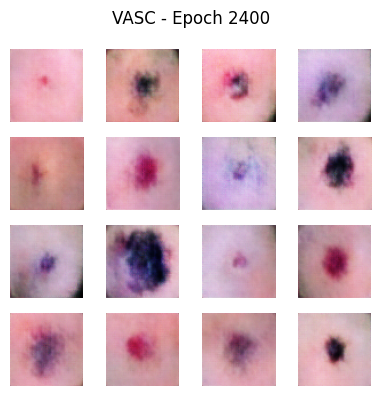

Epoch 2402 — G_loss: 0.7170, D_loss: 1.3567
Epoch 2403 — G_loss: 0.7257, D_loss: 1.3676
Epoch 2404 — G_loss: 0.7281, D_loss: 1.3427
Epoch 2405 — G_loss: 0.7194, D_loss: 1.3214
Epoch 2406 — G_loss: 0.7763, D_loss: 1.3381
Epoch 2407 — G_loss: 0.7073, D_loss: 1.3759
Epoch 2408 — G_loss: 0.7154, D_loss: 1.3761
Epoch 2409 — G_loss: 0.7211, D_loss: 1.3107
Epoch 2410 — G_loss: 0.7786, D_loss: 1.3088
Epoch 2411 — G_loss: 0.7489, D_loss: 1.3667
Epoch 2412 — G_loss: 0.7285, D_loss: 1.3730
Epoch 2413 — G_loss: 0.7738, D_loss: 1.3543
Epoch 2414 — G_loss: 0.7673, D_loss: 1.3889
Epoch 2415 — G_loss: 0.8137, D_loss: 1.3899
Epoch 2416 — G_loss: 0.6832, D_loss: 1.3733
Epoch 2417 — G_loss: 0.7217, D_loss: 1.3813
Epoch 2418 — G_loss: 0.7976, D_loss: 1.2572
Epoch 2419 — G_loss: 0.7018, D_loss: 1.1820
Epoch 2420 — G_loss: 0.7782, D_loss: 1.3590
Epoch 2421 — G_loss: 0.7298, D_loss: 1.3738
Epoch 2422 — G_loss: 0.7487, D_loss: 1.4396
Epoch 2423 — G_loss: 0.7416, D_loss: 1.4228
Epoch 2424 — G_loss: 0.7161, D_l

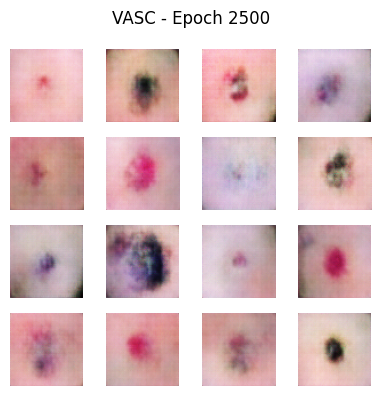

Epoch 2502 — G_loss: 0.6939, D_loss: 1.3530
Epoch 2503 — G_loss: 0.7276, D_loss: 1.4141
Epoch 2504 — G_loss: 0.6848, D_loss: 1.3964
Epoch 2505 — G_loss: 0.7220, D_loss: 1.4073
Epoch 2506 — G_loss: 0.6751, D_loss: 1.3991
Epoch 2507 — G_loss: 0.6972, D_loss: 1.3434
Epoch 2508 — G_loss: 0.7405, D_loss: 1.3182
Epoch 2509 — G_loss: 0.7607, D_loss: 1.3139
Epoch 2510 — G_loss: 0.7216, D_loss: 1.3666
Epoch 2511 — G_loss: 0.7249, D_loss: 1.3880
Epoch 2512 — G_loss: 0.6996, D_loss: 1.3579
Epoch 2513 — G_loss: 0.7173, D_loss: 1.3731
Epoch 2514 — G_loss: 0.7534, D_loss: 1.3451
Epoch 2515 — G_loss: 0.7376, D_loss: 1.3561
Epoch 2516 — G_loss: 0.7176, D_loss: 1.2901
Epoch 2517 — G_loss: 0.7969, D_loss: 1.3013
Epoch 2518 — G_loss: 0.7535, D_loss: 1.2841
Epoch 2519 — G_loss: 0.7670, D_loss: 1.3548
Epoch 2520 — G_loss: 0.7355, D_loss: 1.3957
Epoch 2521 — G_loss: 0.6813, D_loss: 1.4000
Epoch 2522 — G_loss: 0.7828, D_loss: 1.4297
Epoch 2523 — G_loss: 0.7146, D_loss: 1.3999
Epoch 2524 — G_loss: 0.7365, D_l

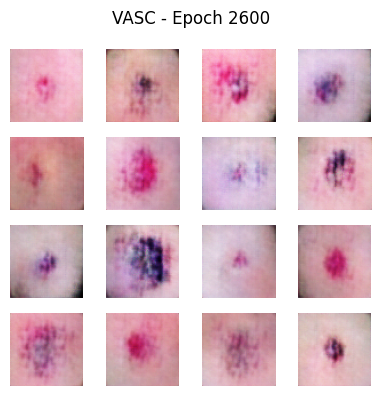

Epoch 2602 — G_loss: 0.7292, D_loss: 1.3313
Epoch 2603 — G_loss: 0.7560, D_loss: 1.3429
Epoch 2604 — G_loss: 0.7243, D_loss: 1.3426
Epoch 2605 — G_loss: 0.7423, D_loss: 1.3473
Epoch 2606 — G_loss: 0.7237, D_loss: 1.3620
Epoch 2607 — G_loss: 0.7088, D_loss: 1.3874
Epoch 2608 — G_loss: 0.7322, D_loss: 1.3519
Epoch 2609 — G_loss: 0.7652, D_loss: 1.3444
Epoch 2610 — G_loss: 0.7086, D_loss: 1.3852
Epoch 2611 — G_loss: 0.7328, D_loss: 1.3860
Epoch 2612 — G_loss: 0.6895, D_loss: 1.3488
Epoch 2613 — G_loss: 0.7263, D_loss: 1.3436
Epoch 2614 — G_loss: 0.7267, D_loss: 1.3608
Epoch 2615 — G_loss: 0.6985, D_loss: 1.3563
Epoch 2616 — G_loss: 0.7445, D_loss: 1.3574
Epoch 2617 — G_loss: 0.7067, D_loss: 1.3656
Epoch 2618 — G_loss: 0.7424, D_loss: 1.3753
Epoch 2619 — G_loss: 0.6931, D_loss: 1.3572
Epoch 2620 — G_loss: 0.7058, D_loss: 1.3570
Epoch 2621 — G_loss: 0.7591, D_loss: 1.3447
Epoch 2622 — G_loss: 0.6985, D_loss: 1.3567
Epoch 2623 — G_loss: 0.7273, D_loss: 1.3781
Epoch 2624 — G_loss: 0.7388, D_l

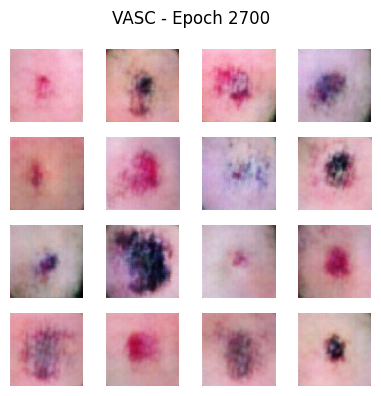

Epoch 2702 — G_loss: 0.7703, D_loss: 1.3172
Epoch 2703 — G_loss: 0.7125, D_loss: 1.3633
Epoch 2704 — G_loss: 0.6896, D_loss: 1.3793
Epoch 2705 — G_loss: 0.7671, D_loss: 1.3613
Epoch 2706 — G_loss: 0.6831, D_loss: 1.3714
Epoch 2707 — G_loss: 0.7380, D_loss: 1.3339
Epoch 2708 — G_loss: 0.7209, D_loss: 1.3501
Epoch 2709 — G_loss: 0.7152, D_loss: 1.3145
Epoch 2710 — G_loss: 0.7650, D_loss: 1.3500
Epoch 2711 — G_loss: 0.7508, D_loss: 1.3436
Epoch 2712 — G_loss: 0.6935, D_loss: 1.3562
Epoch 2713 — G_loss: 0.7722, D_loss: 1.3471
Epoch 2714 — G_loss: 0.7165, D_loss: 1.3598
Epoch 2715 — G_loss: 0.7257, D_loss: 1.3366
Epoch 2716 — G_loss: 0.7337, D_loss: 1.3673
Epoch 2717 — G_loss: 0.7637, D_loss: 1.3322
Epoch 2718 — G_loss: 0.6947, D_loss: 1.3731
Epoch 2719 — G_loss: 0.7796, D_loss: 1.3343
Epoch 2720 — G_loss: 0.6776, D_loss: 1.3704
Epoch 2721 — G_loss: 0.7261, D_loss: 1.3773
Epoch 2722 — G_loss: 0.7198, D_loss: 1.3434
Epoch 2723 — G_loss: 0.7196, D_loss: 1.3644
Epoch 2724 — G_loss: 0.7408, D_l

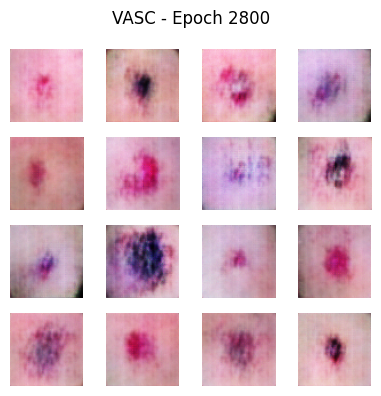

Epoch 2802 — G_loss: 0.7675, D_loss: 1.3448
Epoch 2803 — G_loss: 0.7588, D_loss: 1.3431
Epoch 2804 — G_loss: 0.7218, D_loss: 1.3773
Epoch 2805 — G_loss: 0.7363, D_loss: 1.4013
Epoch 2806 — G_loss: 0.7426, D_loss: 1.3602
Epoch 2807 — G_loss: 0.7177, D_loss: 1.3524
Epoch 2808 — G_loss: 0.7323, D_loss: 1.3330
Epoch 2809 — G_loss: 0.7334, D_loss: 1.3730
Epoch 2810 — G_loss: 0.6800, D_loss: 1.3539
Epoch 2811 — G_loss: 0.7508, D_loss: 1.3615
Epoch 2812 — G_loss: 0.7318, D_loss: 1.3382
Epoch 2813 — G_loss: 0.7242, D_loss: 1.3437
Epoch 2814 — G_loss: 0.7251, D_loss: 1.3585
Epoch 2815 — G_loss: 0.7198, D_loss: 1.3585
Epoch 2816 — G_loss: 0.7254, D_loss: 1.3042
Epoch 2817 — G_loss: 0.7516, D_loss: 1.3293
Epoch 2818 — G_loss: 0.7177, D_loss: 1.3625
Epoch 2819 — G_loss: 0.7470, D_loss: 1.3935
Epoch 2820 — G_loss: 0.7127, D_loss: 1.3634
Epoch 2821 — G_loss: 0.8504, D_loss: 1.3598
Epoch 2822 — G_loss: 0.6618, D_loss: 1.3436
Epoch 2823 — G_loss: 0.7809, D_loss: 1.3450
Epoch 2824 — G_loss: 0.7131, D_l

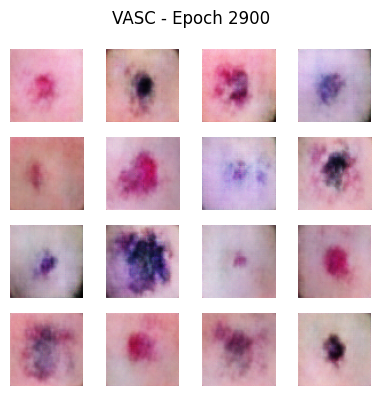

Epoch 2902 — G_loss: 0.7204, D_loss: 1.3589
Epoch 2903 — G_loss: 0.7343, D_loss: 1.3477
Epoch 2904 — G_loss: 0.7393, D_loss: 1.3649
Epoch 2905 — G_loss: 0.7398, D_loss: 1.3627
Epoch 2906 — G_loss: 0.7572, D_loss: 1.3473
Epoch 2907 — G_loss: 0.7133, D_loss: 1.3668
Epoch 2908 — G_loss: 0.6625, D_loss: 1.3406
Epoch 2909 — G_loss: 0.7784, D_loss: 1.3511
Epoch 2910 — G_loss: 0.7314, D_loss: 1.3371
Epoch 2911 — G_loss: 0.7916, D_loss: 1.3318
Epoch 2912 — G_loss: 0.7559, D_loss: 1.3399
Epoch 2913 — G_loss: 0.6956, D_loss: 1.3422
Epoch 2914 — G_loss: 0.7267, D_loss: 1.3574
Epoch 2915 — G_loss: 0.7242, D_loss: 1.3472
Epoch 2916 — G_loss: 0.7241, D_loss: 1.3398
Epoch 2917 — G_loss: 0.7586, D_loss: 1.3301
Epoch 2918 — G_loss: 0.7265, D_loss: 1.3667
Epoch 2919 — G_loss: 0.7099, D_loss: 1.3360
Epoch 2920 — G_loss: 0.7940, D_loss: 1.3411
Epoch 2921 — G_loss: 0.7083, D_loss: 1.3533
Epoch 2922 — G_loss: 0.7767, D_loss: 1.3705
Epoch 2923 — G_loss: 0.7261, D_loss: 1.3664
Epoch 2924 — G_loss: 0.7509, D_l

In [15]:
# Count images in each class
class_counts = {}
base_dir = "C:\\Users\\devgo\\OneDrive\\Desktop\\project\\data\\processed_images"
for label in os.listdir(base_dir):
    class_path = os.path.join(base_dir, label)
    if os.path.isdir(class_path):
        count = len([f for f in os.listdir(class_path) if f.endswith('.jpg')])
        class_counts[label] = count

max_count = max(class_counts.values())
print("🔢 Image counts per class:", class_counts)
print(f"📊 Max class size = {max_count}")

# Run GAN training and augmentation
for label in os.listdir(base_dir):
    path = os.path.join(base_dir, label)
    if os.path.isdir(path):
        train_gan_for_class(label, path, target_total=max_count)


No generated images for NV


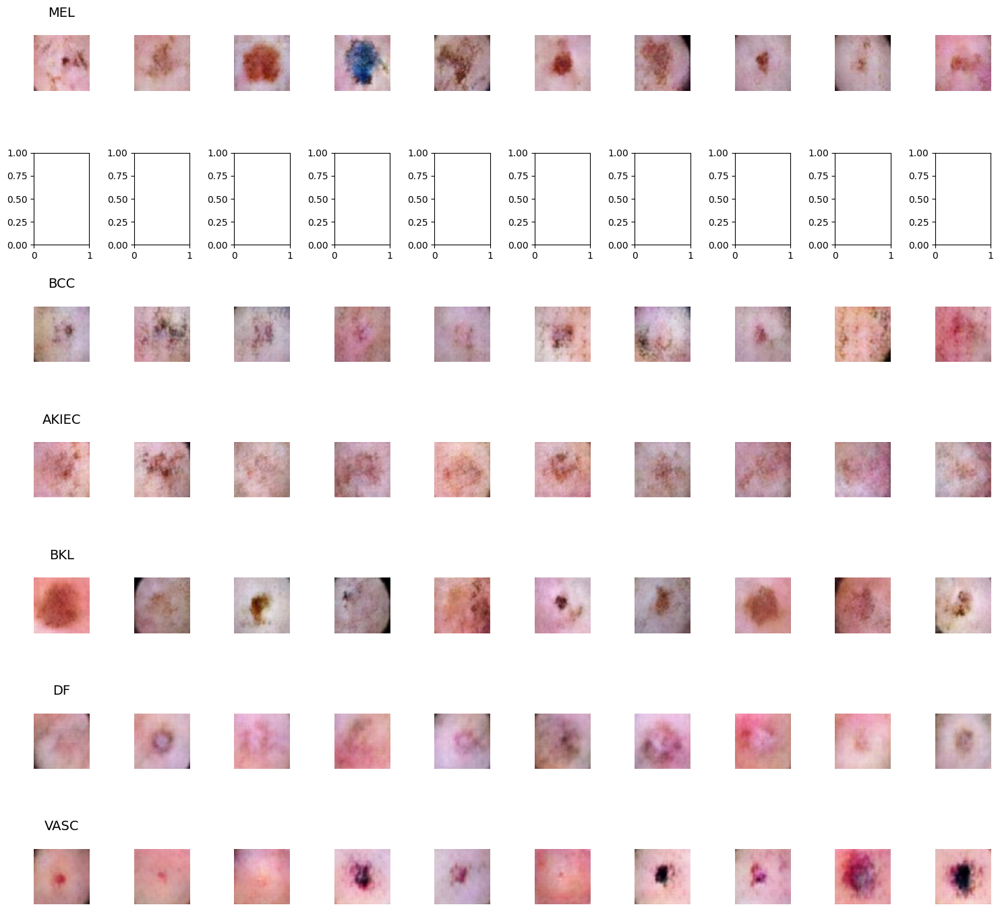

In [7]:
if 'base_dir' not in globals():
    base_dir = out_dir  # fallback to out_dir if base_dir is not defined

fig, axes = plt.subplots(len(label_cols), 10, figsize=(15, 14))
for i, label in enumerate(label_cols):
    aug_dir = os.path.join(base_dir, label, "augmented")
    if not os.path.exists(aug_dir):
        print(f"No generated images for {label}")
        continue
    img_files = [f for f in os.listdir(aug_dir) if f.endswith('.jpg')][:10]
    for j, img_file in enumerate(img_files):
        img_path = os.path.join(aug_dir, img_file)
        img = Image.open(img_path)
        axes[i, j].imshow(img)
        axes[i, j].axis('off')
        if j == 0:
            axes[i, j].set_ylabel(label, fontsize=12)
    # Set cancer name on top of the row
    axes[i, 0].set_title(label, fontsize=14, pad=20)
plt.tight_layout()
plt.show()

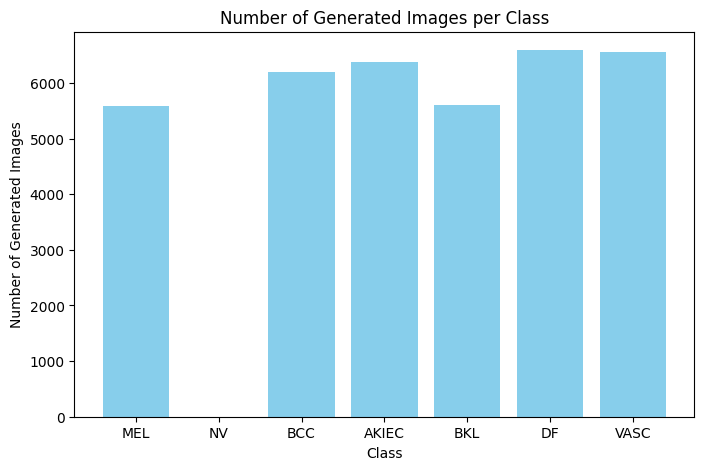

In [8]:
# Count number of generated images in each class's "augmented" folder
generated_counts = {}
for label in label_cols:
    aug_dir = os.path.join(base_dir, label, "augmented")
    if os.path.exists(aug_dir):
        count = len([f for f in os.listdir(aug_dir) if f.endswith('.jpg')])
    else:
        count = 0
    generated_counts[label] = count

plt.figure(figsize=(8, 5))
plt.bar(generated_counts.keys(), generated_counts.values(), color='skyblue')
plt.xlabel('Class')
plt.ylabel('Number of Generated Images')
plt.title('Number of Generated Images per Class')
plt.show()

In [9]:
class_counts = {}
for label in label_cols:
    class_path = os.path.join(base_dir, label)
    if os.path.isdir(class_path):
        count = len([f for f in os.listdir(class_path) if f.endswith('.jpg')])
        class_counts[label] = count
print(class_counts)

{'MEL': 1113, 'NV': 6705, 'BCC': 514, 'AKIEC': 327, 'BKL': 1099, 'DF': 115, 'VASC': 142}


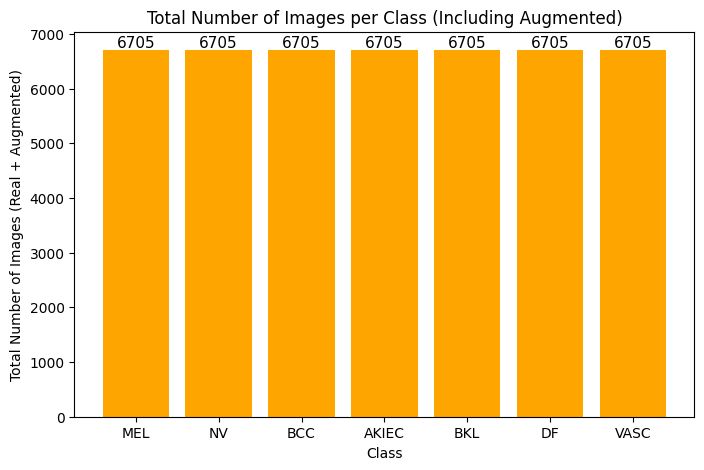

In [10]:
# Calculate total images (real + augmented) for each class
total_counts = {}
for label in label_cols:
    real = class_counts.get(label, 0)
    augmented = generated_counts.get(label, 0)
    total_counts[label] = real + augmented

plt.figure(figsize=(8, 5))
bars = plt.bar(total_counts.keys(), total_counts.values(), color='orange')
plt.xlabel('Class')
plt.ylabel('Total Number of Images (Real + Augmented)')
plt.title('Total Number of Images per Class (Including Augmented)')

# Add counts on top of each bar
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height, str(height), ha='center', va='bottom', fontsize=11)

plt.show()


In [15]:
import os
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

IMAGE_SIZE = (64, 64)
BATCH_SIZE = 64


In [ ]:
def load_image(path):
    img = Image.open(path).convert("RGB").resize(IMAGE_SIZE)
    img = np.asarray(img).astype("float32") / 127.5 - 1
    return img

def load_denoising_dataset(base_dir="./data/processed_images"):
    clean_images = []
    noisy_images = []

    for label in os.listdir(base_dir):
        label_path = os.path.join(base_dir, label)
        aug_path = os.path.join(label_path, "augmented")
        if not os.path.exists(aug_path): continue

        real_imgs = [f for f in os.listdir(label_path) if f.endswith(".jpg")]
        gan_imgs = [f for f in os.listdir(aug_path) if f.endswith(".jpg")]
        pair_count = min(len(real_imgs), len(gan_imgs))

        for i in range(pair_count):
            try:
                clean = load_image(os.path.join(label_path, real_imgs[i]))
                noisy = load_image(os.path.join(aug_path, gan_imgs[i]))
                clean_images.append(clean)
                noisy_images.append(noisy)
            except:
                continue

    print(f"✅ Loaded {len(clean_images)} image pairs.")
    return np.array(noisy_images), np.array(clean_images)

noisy_imgs, clean_imgs = load_denoising_dataset()


✅ Loaded 3310 image pairs.


In [43]:
def ssim_loss(y_true, y_pred):
    return 1 - tf.reduce_mean(tf.image.ssim(y_true, y_pred, max_val=2.0))


In [44]:
def build_better_autoencoder():
    inputs = layers.Input(shape=(64, 64, 3))

    # Encoder
    x1 = layers.Conv2D(32, 3, activation='relu', padding='same')(inputs)
    x1p = layers.MaxPooling2D(2)(x1)
    x2 = layers.Conv2D(64, 3, activation='relu', padding='same')(x1p)
    x2p = layers.MaxPooling2D(2)(x2)
    x3 = layers.Conv2D(128, 3, activation='relu', padding='same')(x2p)
    encoded = layers.MaxPooling2D(2)(x3)

    # Decoder with skip connections
    x = layers.Conv2D(128, 3, activation='relu', padding='same')(encoded)
    x = layers.UpSampling2D(2)(x)
    x = layers.Concatenate()([x, x3])
    x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
    x = layers.UpSampling2D(2)(x)
    x = layers.Concatenate()([x, x2])
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(x)
    x = layers.UpSampling2D(2)(x)
    x = layers.Concatenate()([x, x1])
    decoded = layers.Conv2D(3, 3, activation='tanh', padding='same')(x)

    return models.Model(inputs, decoded)

autoencoder = build_better_autoencoder()
autoencoder.compile(optimizer='adam', loss=ssim_loss)
autoencoder.summary()


Model: "functional_201"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_17      │ (None, 64, 64, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_31 (Conv2D)  │ (None, 64, 64,    │        896 │ input_layer_17[0… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 32, 32,    │          0 │ conv2d_31[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_32 (Conv2D)  │ (None, 32, 32,    │     18,496 │ max_pooling2d_3[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 16, 16,    │          0 │ conv2d_32[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_33 (Conv2D)  │ (None, 16, 16,    │     73,856 │ max_pooling2d_4[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 8, 8, 128) │          0 │ conv2d_33[0][0]   │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_34 (Conv2D)  │ (None, 8, 8, 128) │    147,584 │ max_pooling2d_5[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_3     │ (None, 16, 16,    │          0 │ conv2d_34[0][0]   │
│ (UpSampling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 16, 16,    │          0 │ up_sampling2d_3[… │
│ (Concatenate)       │ 256)              │            │ conv2d_33[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_35 (Conv2D)  │ (None, 16, 16,    │    147,520 │ concatenate[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_4     │ (None, 32, 32,    │          0 │ conv2d_35[0][0]   │
│ (UpSampling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 32, 32,    │          0 │ up_sampling2d_4[… │
│ (Concatenate)       │ 128)              │            │ conv2d_32[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_36 (Conv2D)  │ (None, 32, 32,    │     36,896 │ concatenate_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_5     │ (None, 64, 64,    │          0 │ conv2d_36[0][0]   │
│ (UpSampling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 64, 64,    │          0 │ up_sampling2d_5[… │
│ (Concatenate)       │ 64)               │            │ conv2d_31[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_37 (Conv2D)  │ (None, 64, 64, 3) │      1,731 │ concatenate_2[0]… │
└─────────────────────┴───────────────────┴────────────┴─────────────────

 Total params: 426,979 (1.63 MB)

 Trainable params: 426,979 (1.63 MB)

 Non-trainable params: 0 (0.00 B)

In [45]:
history = autoencoder.fit(
    noisy_imgs, clean_imgs,
    epochs=200,
    batch_size=BATCH_SIZE,
    validation_split=0.1
)


Epoch 1/200
47/47 ━━━━━━━━━━━━━━━━━━━━ 7s 115ms/step - loss: 0.7042 - val_loss: 0.6131
Epoch 2/200
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 106ms/step - loss: 0.6317 - val_loss: 0.6122
Epoch 3/200
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 105ms/step - loss: 0.6312 - val_loss: 0.6090
Epoch 4/200
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 106ms/step - loss: 0.6278 - val_loss: 0.6094
Epoch 5/200
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 106ms/step - loss: 0.6279 - val_loss: 0.6082
Epoch 6/200
47/47 ━━━━━━━━━━━━━━━━━━━━ 13s 277ms/step - loss: 0.6282 - val_loss: 0.6119
Epoch 7/200
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - loss: 0.6263 - val_loss: 0.6015
Epoch 8/200
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 105ms/step - loss: 0.6242 - val_loss: 0.6016
Epoch 9/200
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 105ms/step - loss: 0.6264 - val_loss: 0.5986
Epoch 10/200
47/47 ━━━━━━━━━━━━━━━━━━━━ 6s 119ms/step - loss: 0.6199 - val_loss: 0.5992
Epoch 11/200
47/47 ━━━━━━━━━━━━━━━━━━━━ 6s 121ms/step - loss: 0.6169 - val_loss: 0.5989
Epoch 12/200
47/47 ━━━━━━━━━━━━━━━━━━━━ 

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step


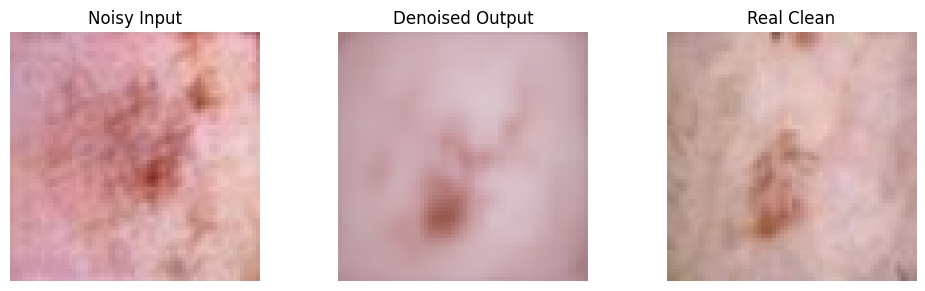

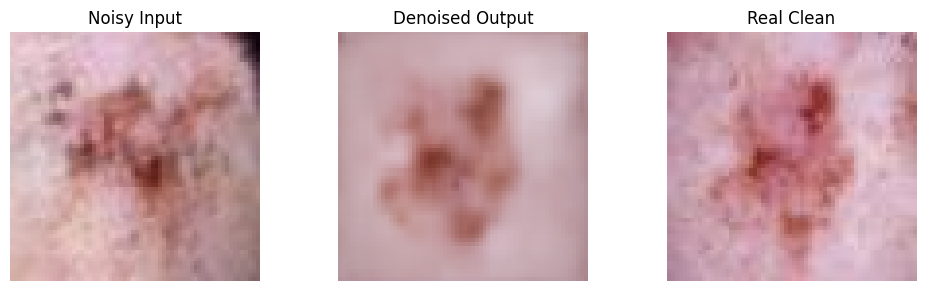

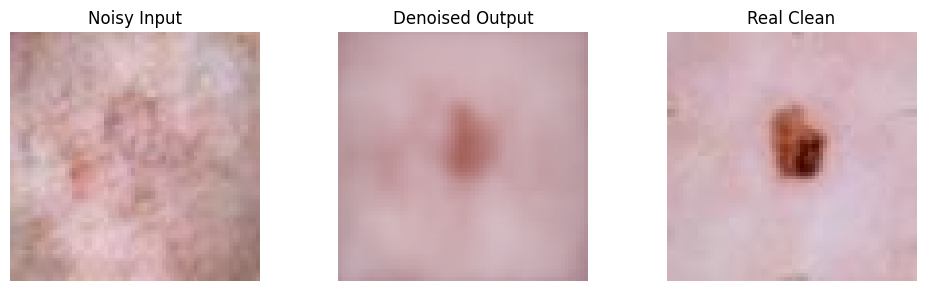

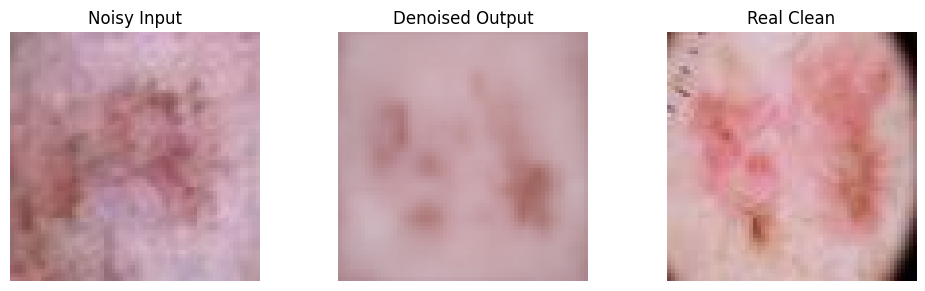

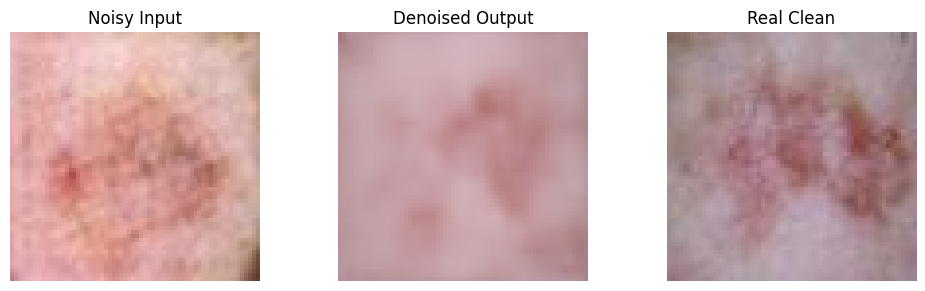

In [46]:
def show_denoising_examples(model, noisy, clean, count=5):
    preds = model.predict(noisy[:count])
    for i in range(count):
        fig, axs = plt.subplots(1, 3, figsize=(10, 3))
        axs[0].imshow(((noisy[i] + 1) / 2))
        axs[0].set_title("Noisy Input")
        axs[1].imshow(((preds[i] + 1) / 2))
        axs[1].set_title("Denoised Output")
        axs[2].imshow(((clean[i] + 1) / 2))
        axs[2].set_title("Real Clean")
        for ax in axs: ax.axis('off')
        plt.tight_layout()
        plt.show()

show_denoising_examples(autoencoder, noisy_imgs, clean_imgs)


In [47]:

import os
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers

IMG_SIZE = (64, 64)
IMG_SHAPE = (64, 64, 3)
BATCH_SIZE = 16


In [48]:
def load_image(path):
    img = Image.open(path).convert("RGB").resize(IMG_SIZE)
    return np.array(img).astype(np.float32) / 127.5 - 1

def load_dataset(base_dir="./data/processed_images"):
    noisy_images, clean_images = [], []
    for label in os.listdir(base_dir):
        aug_dir = os.path.join(base_dir, label, "augmented")
        real_dir = os.path.join(base_dir, label)
        if not os.path.exists(aug_dir): continue

        aug_files = sorted([f for f in os.listdir(aug_dir) if f.endswith(".jpg")])
        real_files = sorted([f for f in os.listdir(real_dir) if f.endswith(".jpg")])
        pair_count = min(len(aug_files), len(real_files))

        for i in range(pair_count):
            try:
                noisy = load_image(os.path.join(aug_dir, aug_files[i]))
                clean = load_image(os.path.join(real_dir, real_files[i]))
                noisy_images.append(noisy)
                clean_images.append(clean)
            except: continue

    return np.array(noisy_images), np.array(clean_images)

noisy_imgs, clean_imgs = load_dataset()
print("✅ Loaded:", noisy_imgs.shape)


✅ Loaded: (3310, 64, 64, 3)


In [55]:
def build_generator():
    inputs = layers.Input(shape=IMG_SHAPE)

    # Encoder
    down1 = layers.Conv2D(64, 4, strides=2, padding='same', activation='relu')(inputs)   # 32x32
    down2 = layers.Conv2D(128, 4, strides=2, padding='same', activation='relu')(down1)   # 16x16
    down3 = layers.Conv2D(256, 4, strides=2, padding='same', activation='relu')(down2)   # 8x8

    # Bottleneck
    bottleneck = layers.Conv2D(512, 4, strides=2, padding='same', activation='relu')(down3)  # 4x4

    # Decoder with skip connections
    up1 = layers.Conv2DTranspose(256, 4, strides=2, padding='same', activation='relu')(bottleneck)  # 8x8
    up1 = layers.Concatenate()([up1, down3])
    up2 = layers.Conv2DTranspose(128, 4, strides=2, padding='same', activation='relu')(up1)         # 16x16
    up2 = layers.Concatenate()([up2, down2])
    up3 = layers.Conv2DTranspose(64, 4, strides=2, padding='same', activation='relu')(up2)          # 32x32
    up3 = layers.Concatenate()([up3, down1])
    up4 = layers.Conv2DTranspose(32, 4, strides=2, padding='same', activation='relu')(up3)          # 64x64

    output = layers.Conv2DTranspose(3, 4, strides=1, padding='same', activation='tanh')(up4)

    return tf.keras.Model(inputs, output)

generator = build_generator()


In [56]:
def build_discriminator():
    inp_img = layers.Input(shape=IMG_SHAPE)
    target_img = layers.Input(shape=IMG_SHAPE)
    x = layers.Concatenate()([inp_img, target_img])
    x = layers.Conv2D(64, 4, strides=2, padding='same', activation='relu')(x)
    x = layers.Conv2D(128, 4, strides=2, padding='same', activation='relu')(x)
    x = layers.Conv2D(256, 4, strides=2, padding='same', activation='relu')(x)
    x = layers.Conv2D(1, 4, padding='same')(x)
    return tf.keras.Model([inp_img, target_img], x)

discriminator = build_discriminator()


In [57]:
loss_object = tf.keras.losses.BinaryCrossentropy(from_logits=True)
LAMBDA = 100

def generator_loss(disc_generated_output, gen_output, target):
    gan_loss = loss_object(tf.ones_like(disc_generated_output), disc_generated_output)
    l1_loss = tf.reduce_mean(tf.abs(target - gen_output))
    return gan_loss + (LAMBDA * l1_loss)

def discriminator_loss(disc_real_output, disc_generated_output):
    real_loss = loss_object(tf.ones_like(disc_real_output), disc_real_output)
    fake_loss = loss_object(tf.zeros_like(disc_generated_output), disc_generated_output)
    return real_loss + fake_loss

gen_optimizer = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)
disc_optimizer = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)


In [58]:
@tf.function
def train_step(input_image, target):
    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        gen_output = generator(input_image, training=True)
        disc_real_output = discriminator([input_image, target], training=True)
        disc_generated_output = discriminator([input_image, gen_output], training=True)

        gen_loss = generator_loss(disc_generated_output, gen_output, target)
        disc_loss = discriminator_loss(disc_real_output, disc_generated_output)

    gen_grads = gen_tape.gradient(gen_loss, generator.trainable_variables)
    disc_grads = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    gen_optimizer.apply_gradients(zip(gen_grads, generator.trainable_variables))
    disc_optimizer.apply_gradients(zip(disc_grads, discriminator.trainable_variables))

    return gen_loss, disc_loss


Epoch 1/200
  Gen Loss: 20.1289 | Disc Loss: 0.8943
Epoch 2/200
  Gen Loss: 20.7492 | Disc Loss: 0.8212
Epoch 3/200
  Gen Loss: 20.3976 | Disc Loss: 0.9974
Epoch 4/200
  Gen Loss: 20.5193 | Disc Loss: 0.8329
Epoch 5/200
  Gen Loss: 20.5934 | Disc Loss: 1.0677
Epoch 6/200
  Gen Loss: 19.9760 | Disc Loss: 0.9427
Epoch 7/200
  Gen Loss: 21.2272 | Disc Loss: 0.6966
Epoch 8/200
  Gen Loss: 21.1438 | Disc Loss: 0.6486
Epoch 9/200
  Gen Loss: 20.7324 | Disc Loss: 0.8512
Epoch 10/200
  Gen Loss: 20.1701 | Disc Loss: 0.9983


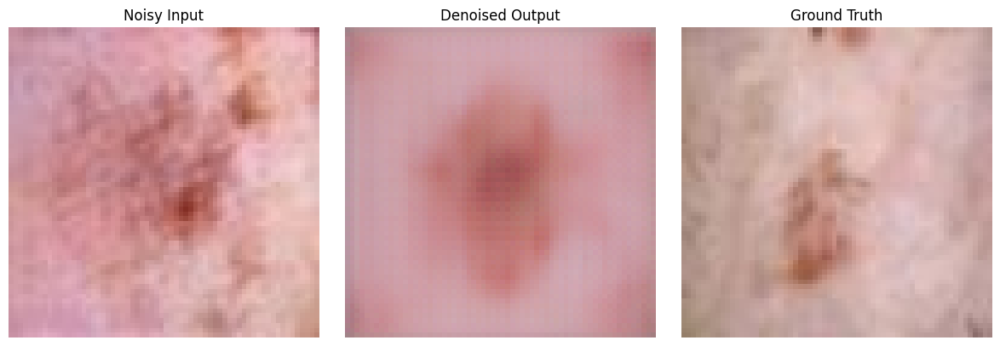

Epoch 11/200
  Gen Loss: 23.6070 | Disc Loss: 1.0866
Epoch 12/200
  Gen Loss: 21.2111 | Disc Loss: 0.6980
Epoch 13/200
  Gen Loss: 20.5999 | Disc Loss: 0.9556
Epoch 14/200
  Gen Loss: 20.6016 | Disc Loss: 1.0024
Epoch 15/200
  Gen Loss: 20.5194 | Disc Loss: 0.9820
Epoch 16/200
  Gen Loss: 20.3928 | Disc Loss: 1.0389
Epoch 17/200
  Gen Loss: 20.4223 | Disc Loss: 0.9953
Epoch 18/200
  Gen Loss: 19.1599 | Disc Loss: 0.8831
Epoch 19/200
  Gen Loss: 20.2901 | Disc Loss: 1.0518
Epoch 20/200
  Gen Loss: 20.9611 | Disc Loss: 0.9713


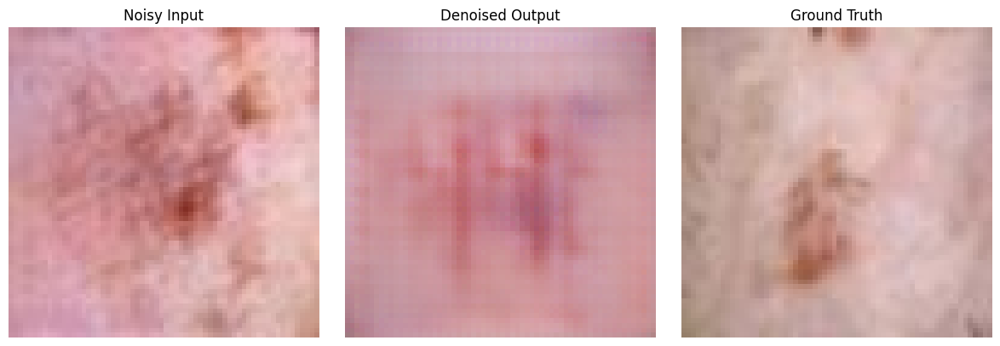

Epoch 21/200
  Gen Loss: 19.0174 | Disc Loss: 1.0619
Epoch 22/200
  Gen Loss: 18.3035 | Disc Loss: 1.2819
Epoch 23/200
  Gen Loss: 17.7491 | Disc Loss: 1.1863
Epoch 24/200
  Gen Loss: 17.1586 | Disc Loss: 1.0043
Epoch 25/200
  Gen Loss: 16.7740 | Disc Loss: 1.1648
Epoch 26/200
  Gen Loss: 14.3266 | Disc Loss: 1.0432
Epoch 27/200
  Gen Loss: 14.0436 | Disc Loss: 1.1626
Epoch 28/200
  Gen Loss: 14.0372 | Disc Loss: 0.9912
Epoch 29/200
  Gen Loss: 13.1340 | Disc Loss: 1.0149
Epoch 30/200
  Gen Loss: 14.5519 | Disc Loss: 1.1744


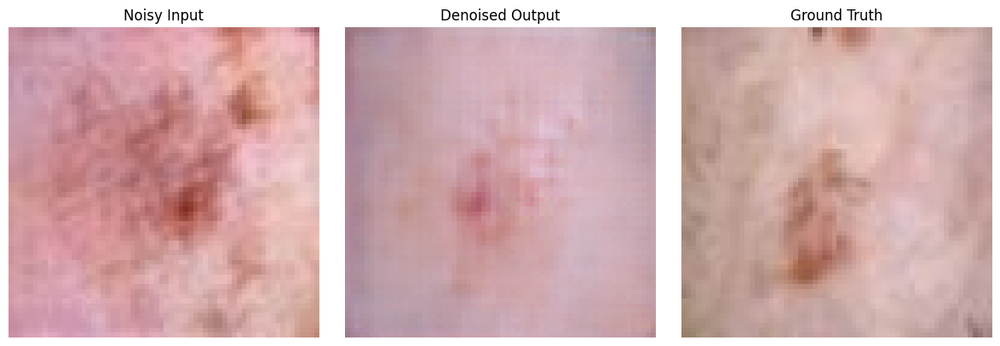

Epoch 31/200
  Gen Loss: 13.7758 | Disc Loss: 0.7696
Epoch 32/200
  Gen Loss: 11.8501 | Disc Loss: 0.9492
Epoch 33/200
  Gen Loss: 12.3911 | Disc Loss: 0.9130
Epoch 34/200
  Gen Loss: 11.4110 | Disc Loss: 1.0397
Epoch 35/200
  Gen Loss: 11.2857 | Disc Loss: 1.0650
Epoch 36/200
  Gen Loss: 13.2181 | Disc Loss: 0.7425
Epoch 37/200
  Gen Loss: 15.0942 | Disc Loss: 0.9998
Epoch 38/200
  Gen Loss: 12.1419 | Disc Loss: 0.9930
Epoch 39/200
  Gen Loss: 10.5197 | Disc Loss: 0.9934
Epoch 40/200
  Gen Loss: 10.9135 | Disc Loss: 0.9393


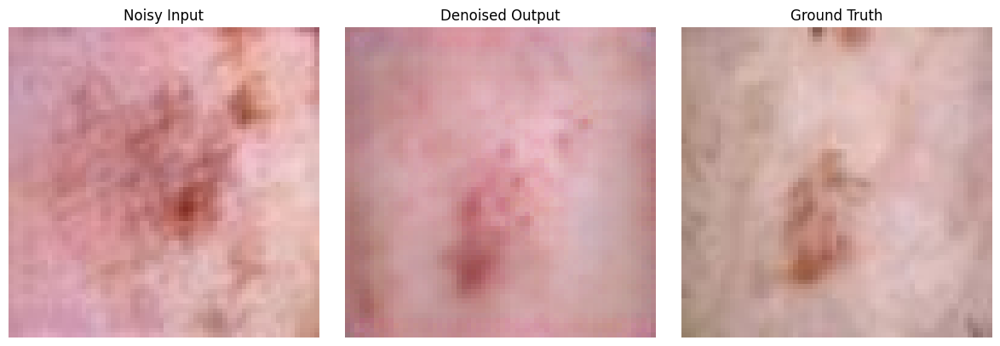

Epoch 41/200
  Gen Loss: 10.8441 | Disc Loss: 1.0231
Epoch 42/200
  Gen Loss: 10.6036 | Disc Loss: 1.0060
Epoch 43/200
  Gen Loss: 9.7658 | Disc Loss: 0.8766
Epoch 44/200
  Gen Loss: 9.1673 | Disc Loss: 1.0551
Epoch 45/200
  Gen Loss: 9.0770 | Disc Loss: 1.1874
Epoch 46/200
  Gen Loss: 9.5928 | Disc Loss: 0.8283
Epoch 47/200
  Gen Loss: 9.6671 | Disc Loss: 0.8441
Epoch 48/200
  Gen Loss: 10.9008 | Disc Loss: 0.8944
Epoch 49/200
  Gen Loss: 9.6966 | Disc Loss: 0.9862
Epoch 50/200
  Gen Loss: 9.0401 | Disc Loss: 1.0414


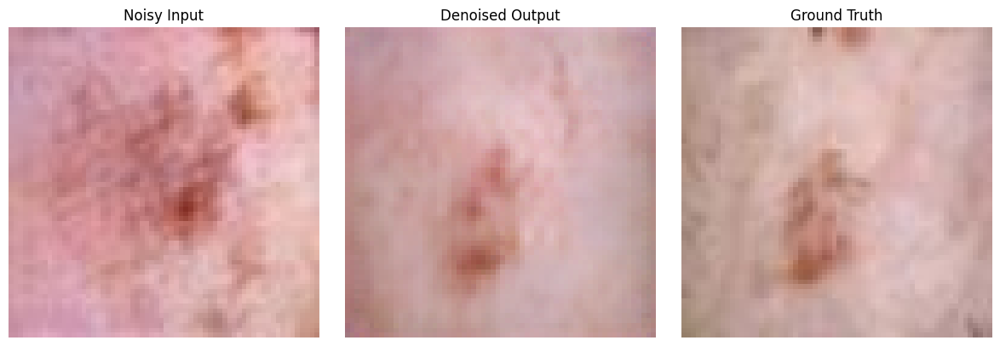

Epoch 51/200
  Gen Loss: 8.7937 | Disc Loss: 1.1119
Epoch 52/200
  Gen Loss: 8.2743 | Disc Loss: 1.0784
Epoch 53/200
  Gen Loss: 8.3143 | Disc Loss: 1.1659
Epoch 54/200
  Gen Loss: 9.1675 | Disc Loss: 1.1445
Epoch 55/200
  Gen Loss: 9.7315 | Disc Loss: 1.1016
Epoch 56/200
  Gen Loss: 8.9764 | Disc Loss: 1.1124
Epoch 57/200
  Gen Loss: 8.4479 | Disc Loss: 1.0855
Epoch 58/200
  Gen Loss: 9.3531 | Disc Loss: 1.0560
Epoch 59/200
  Gen Loss: 10.1825 | Disc Loss: 1.0806
Epoch 60/200
  Gen Loss: 8.1277 | Disc Loss: 1.0064


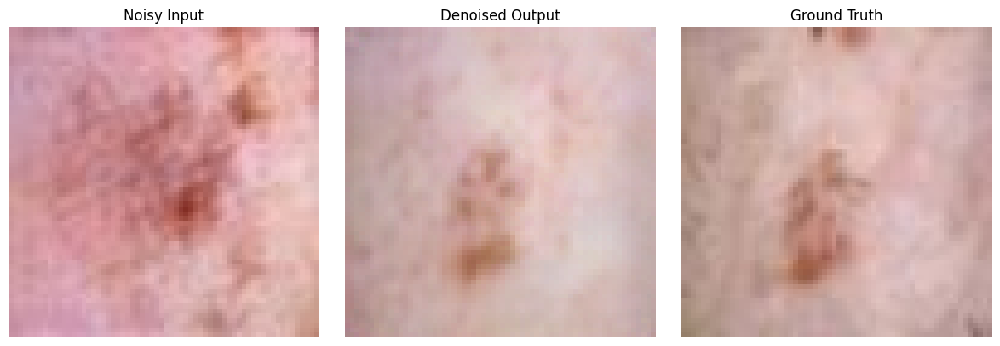

Epoch 61/200
  Gen Loss: 8.4976 | Disc Loss: 0.9735
Epoch 62/200
  Gen Loss: 8.7835 | Disc Loss: 1.0097
Epoch 63/200
  Gen Loss: 8.0724 | Disc Loss: 1.0216
Epoch 64/200
  Gen Loss: 8.9591 | Disc Loss: 0.8935
Epoch 65/200
  Gen Loss: 8.1257 | Disc Loss: 0.9327
Epoch 66/200
  Gen Loss: 8.8694 | Disc Loss: 1.0102
Epoch 67/200
  Gen Loss: 7.8658 | Disc Loss: 1.0083
Epoch 68/200
  Gen Loss: 7.6968 | Disc Loss: 0.9965
Epoch 69/200
  Gen Loss: 8.8997 | Disc Loss: 1.0011
Epoch 70/200
  Gen Loss: 7.7116 | Disc Loss: 1.0405


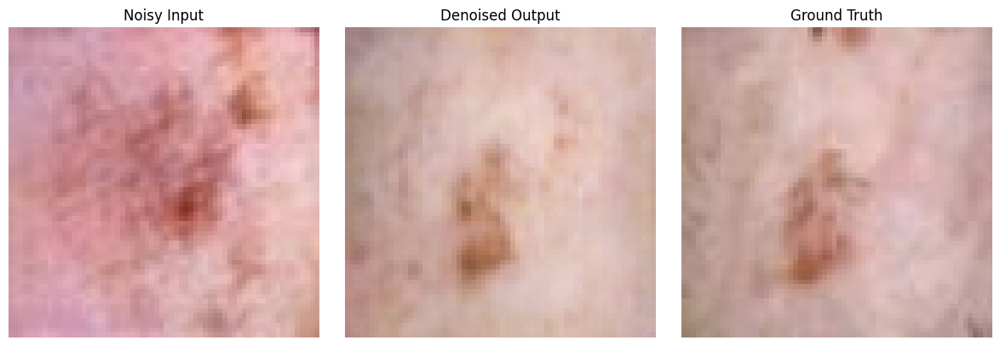

Epoch 71/200
  Gen Loss: 8.0855 | Disc Loss: 0.9374
Epoch 72/200
  Gen Loss: 7.4046 | Disc Loss: 0.9388
Epoch 73/200
  Gen Loss: 7.6921 | Disc Loss: 0.9511
Epoch 74/200
  Gen Loss: 7.1894 | Disc Loss: 1.0246
Epoch 75/200
  Gen Loss: 7.7887 | Disc Loss: 0.9880
Epoch 76/200
  Gen Loss: 7.2561 | Disc Loss: 0.9796
Epoch 77/200
  Gen Loss: 7.3264 | Disc Loss: 0.9769
Epoch 78/200
  Gen Loss: 7.6446 | Disc Loss: 1.0247
Epoch 79/200
  Gen Loss: 7.1376 | Disc Loss: 1.0250
Epoch 80/200
  Gen Loss: 7.6261 | Disc Loss: 1.0406


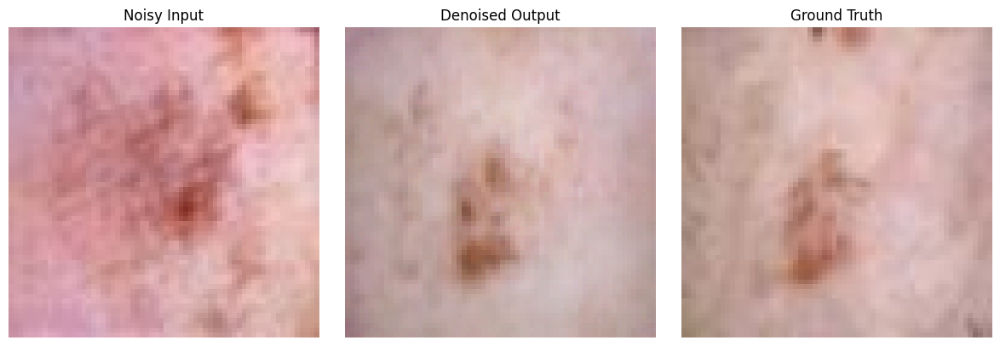

Epoch 81/200
  Gen Loss: 7.5903 | Disc Loss: 1.0383
Epoch 82/200
  Gen Loss: 6.6491 | Disc Loss: 1.0235
Epoch 83/200
  Gen Loss: 6.6028 | Disc Loss: 1.0397
Epoch 84/200
  Gen Loss: 6.8169 | Disc Loss: 1.0495
Epoch 85/200
  Gen Loss: 7.2977 | Disc Loss: 1.0755
Epoch 86/200
  Gen Loss: 6.9251 | Disc Loss: 1.2058
Epoch 87/200
  Gen Loss: 7.8285 | Disc Loss: 1.0976
Epoch 88/200
  Gen Loss: 7.2489 | Disc Loss: 0.9982
Epoch 89/200
  Gen Loss: 7.5939 | Disc Loss: 1.1486
Epoch 90/200
  Gen Loss: 7.3197 | Disc Loss: 1.1692


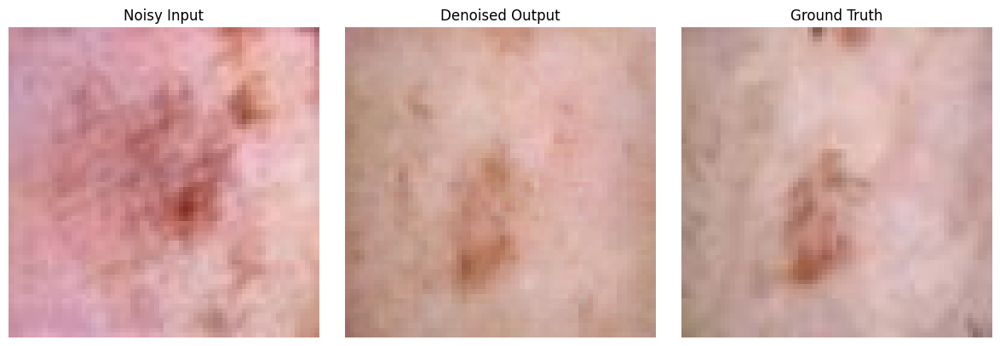

Epoch 91/200
  Gen Loss: 7.3767 | Disc Loss: 1.2715
Epoch 92/200
  Gen Loss: 7.0099 | Disc Loss: 1.2890
Epoch 93/200
  Gen Loss: 6.6519 | Disc Loss: 1.1792
Epoch 94/200
  Gen Loss: 6.9345 | Disc Loss: 1.0887
Epoch 95/200
  Gen Loss: 7.6903 | Disc Loss: 1.0034
Epoch 96/200
  Gen Loss: 6.9121 | Disc Loss: 1.1298
Epoch 97/200
  Gen Loss: 6.7956 | Disc Loss: 1.2099
Epoch 98/200
  Gen Loss: 6.2847 | Disc Loss: 1.1244
Epoch 99/200
  Gen Loss: 6.8355 | Disc Loss: 1.0528
Epoch 100/200
  Gen Loss: 7.0472 | Disc Loss: 1.2585


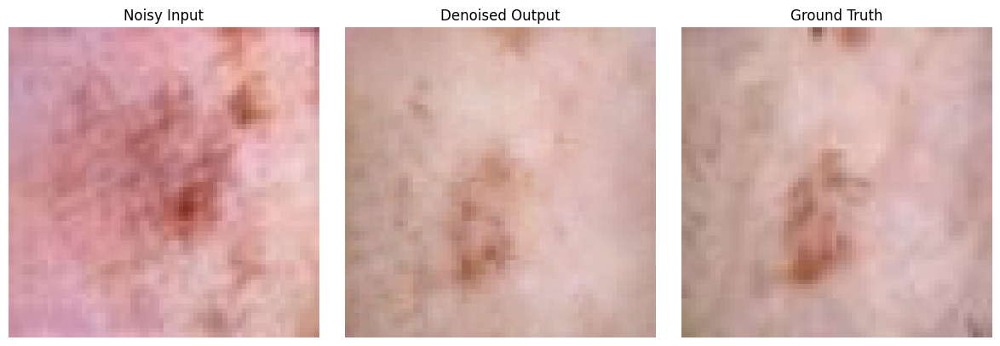

Epoch 101/200
  Gen Loss: 6.2640 | Disc Loss: 1.1220
Epoch 102/200
  Gen Loss: 6.2524 | Disc Loss: 1.0566
Epoch 103/200
  Gen Loss: 6.5350 | Disc Loss: 1.1169
Epoch 104/200
  Gen Loss: 6.5278 | Disc Loss: 1.1062
Epoch 105/200
  Gen Loss: 6.3035 | Disc Loss: 1.1282
Epoch 106/200
  Gen Loss: 6.5877 | Disc Loss: 1.1218
Epoch 107/200
  Gen Loss: 6.4655 | Disc Loss: 1.2791
Epoch 108/200
  Gen Loss: 6.8899 | Disc Loss: 1.1788
Epoch 109/200
  Gen Loss: 6.8510 | Disc Loss: 1.1334
Epoch 110/200
  Gen Loss: 6.1977 | Disc Loss: 1.2153


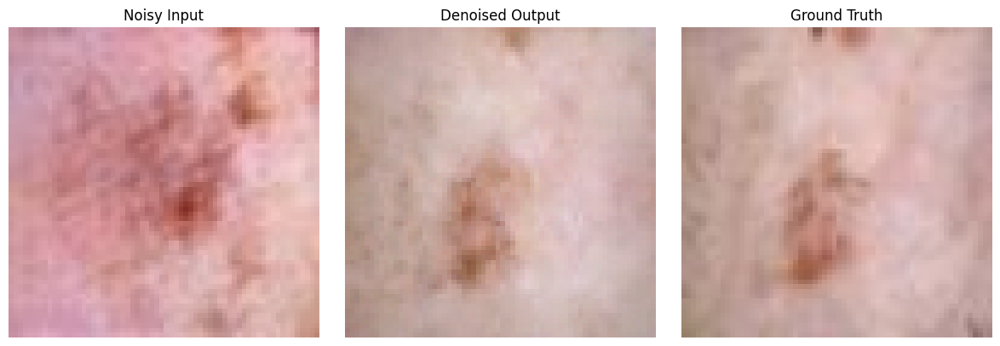

Epoch 111/200
  Gen Loss: 6.3969 | Disc Loss: 1.2207
Epoch 112/200
  Gen Loss: 6.2099 | Disc Loss: 1.1629
Epoch 113/200
  Gen Loss: 6.1093 | Disc Loss: 1.0855
Epoch 114/200
  Gen Loss: 6.2160 | Disc Loss: 1.0997
Epoch 115/200
  Gen Loss: 6.1102 | Disc Loss: 1.1505
Epoch 116/200
  Gen Loss: 6.4858 | Disc Loss: 1.0902
Epoch 117/200
  Gen Loss: 5.9260 | Disc Loss: 1.1156
Epoch 118/200
  Gen Loss: 6.5114 | Disc Loss: 1.3473
Epoch 119/200
  Gen Loss: 6.0314 | Disc Loss: 1.3042
Epoch 120/200
  Gen Loss: 6.2683 | Disc Loss: 1.1946


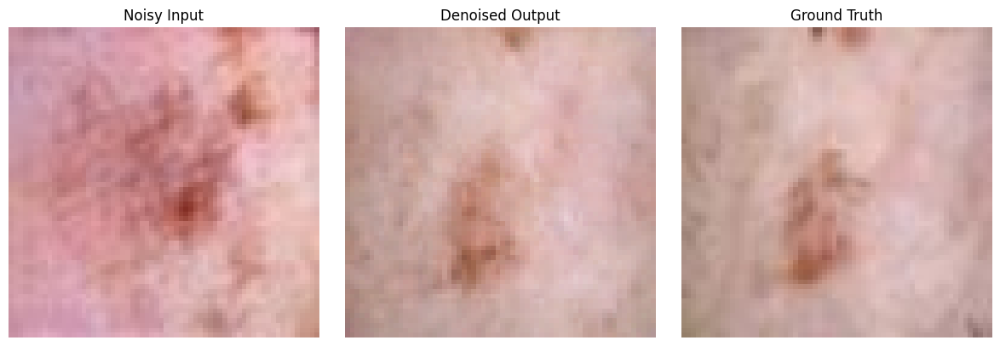

Epoch 121/200
  Gen Loss: 5.9508 | Disc Loss: 1.2376
Epoch 122/200
  Gen Loss: 5.8232 | Disc Loss: 1.2213
Epoch 123/200
  Gen Loss: 5.8563 | Disc Loss: 1.1005
Epoch 124/200
  Gen Loss: 6.2947 | Disc Loss: 1.2523
Epoch 125/200
  Gen Loss: 5.8584 | Disc Loss: 1.1362
Epoch 126/200
  Gen Loss: 5.9445 | Disc Loss: 1.1482
Epoch 127/200
  Gen Loss: 5.8441 | Disc Loss: 1.1675
Epoch 128/200
  Gen Loss: 6.5481 | Disc Loss: 1.1726
Epoch 129/200
  Gen Loss: 5.9919 | Disc Loss: 1.1273
Epoch 130/200
  Gen Loss: 6.1610 | Disc Loss: 1.1631


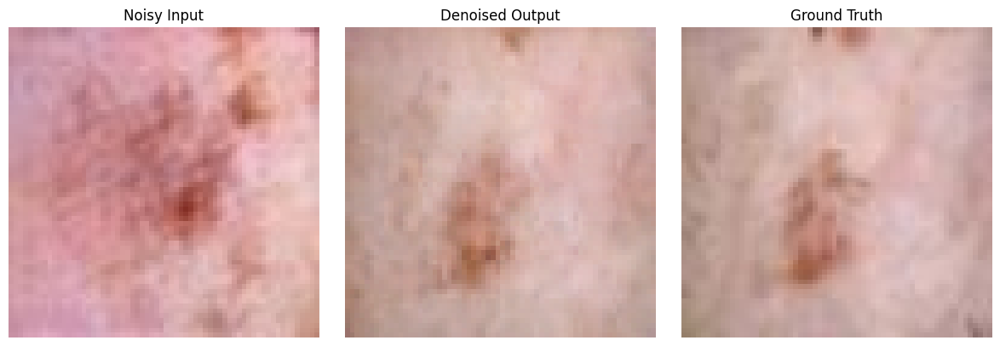

Epoch 131/200
  Gen Loss: 5.6312 | Disc Loss: 1.1094
Epoch 132/200
  Gen Loss: 6.1280 | Disc Loss: 1.1410
Epoch 133/200
  Gen Loss: 5.9933 | Disc Loss: 1.1021
Epoch 134/200
  Gen Loss: 6.1106 | Disc Loss: 1.2603
Epoch 135/200
  Gen Loss: 5.9422 | Disc Loss: 1.2517
Epoch 136/200
  Gen Loss: 5.9577 | Disc Loss: 1.0979
Epoch 137/200
  Gen Loss: 5.3095 | Disc Loss: 1.1562
Epoch 138/200
  Gen Loss: 5.8066 | Disc Loss: 1.0775
Epoch 139/200
  Gen Loss: 6.1509 | Disc Loss: 0.9893
Epoch 140/200
  Gen Loss: 5.6081 | Disc Loss: 1.0423


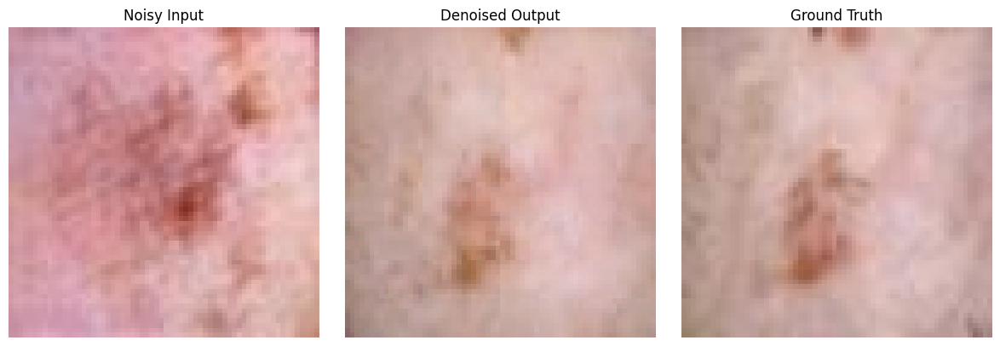

Epoch 141/200
  Gen Loss: 6.1532 | Disc Loss: 1.0587
Epoch 142/200
  Gen Loss: 6.4086 | Disc Loss: 1.1163
Epoch 143/200
  Gen Loss: 5.6273 | Disc Loss: 1.1024
Epoch 144/200
  Gen Loss: 6.5815 | Disc Loss: 0.9614
Epoch 145/200
  Gen Loss: 6.1590 | Disc Loss: 0.9905
Epoch 146/200
  Gen Loss: 5.8264 | Disc Loss: 1.1706
Epoch 147/200
  Gen Loss: 6.3157 | Disc Loss: 1.0687
Epoch 148/200
  Gen Loss: 5.6519 | Disc Loss: 1.0438
Epoch 149/200
  Gen Loss: 5.5055 | Disc Loss: 1.0890
Epoch 150/200
  Gen Loss: 5.3718 | Disc Loss: 1.0977


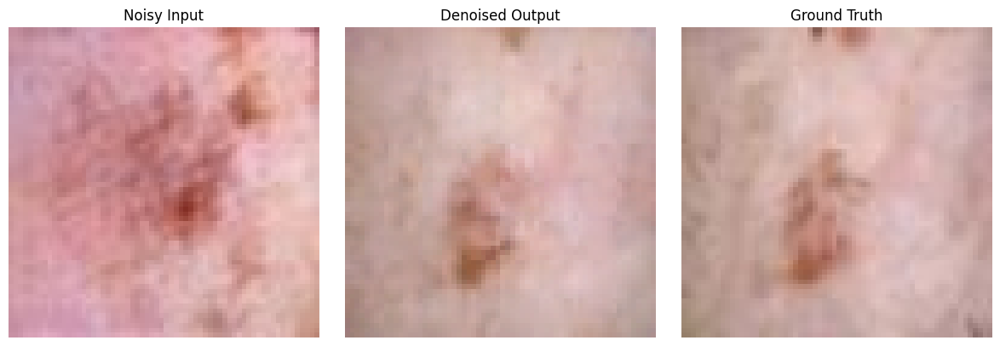

Epoch 151/200
  Gen Loss: 6.5895 | Disc Loss: 1.0353
Epoch 152/200
  Gen Loss: 5.6002 | Disc Loss: 1.1024
Epoch 153/200
  Gen Loss: 6.5142 | Disc Loss: 1.0916
Epoch 154/200
  Gen Loss: 5.9272 | Disc Loss: 1.0388
Epoch 155/200
  Gen Loss: 5.5073 | Disc Loss: 1.0049
Epoch 156/200
  Gen Loss: 5.3068 | Disc Loss: 1.0230
Epoch 157/200
  Gen Loss: 5.5410 | Disc Loss: 1.0473
Epoch 158/200
  Gen Loss: 5.2412 | Disc Loss: 1.0086
Epoch 159/200
  Gen Loss: 5.2570 | Disc Loss: 0.9699
Epoch 160/200
  Gen Loss: 6.3695 | Disc Loss: 0.9549


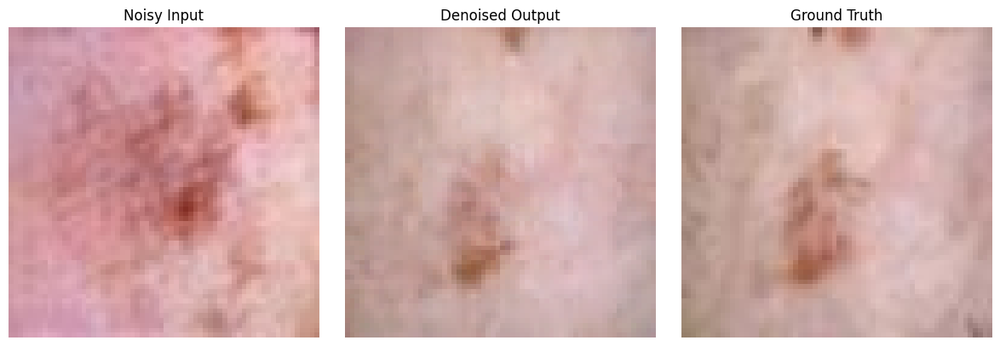

Epoch 161/200
  Gen Loss: 5.9966 | Disc Loss: 0.9737
Epoch 162/200
  Gen Loss: 5.4070 | Disc Loss: 1.0624
Epoch 163/200
  Gen Loss: 6.0751 | Disc Loss: 0.9515
Epoch 164/200
  Gen Loss: 5.6874 | Disc Loss: 0.9799
Epoch 165/200
  Gen Loss: 5.9163 | Disc Loss: 1.0712
Epoch 166/200
  Gen Loss: 5.2599 | Disc Loss: 1.1273
Epoch 167/200
  Gen Loss: 5.2061 | Disc Loss: 1.0528
Epoch 168/200
  Gen Loss: 5.4035 | Disc Loss: 0.9736
Epoch 169/200
  Gen Loss: 5.6473 | Disc Loss: 0.9683
Epoch 170/200
  Gen Loss: 5.4451 | Disc Loss: 0.9226


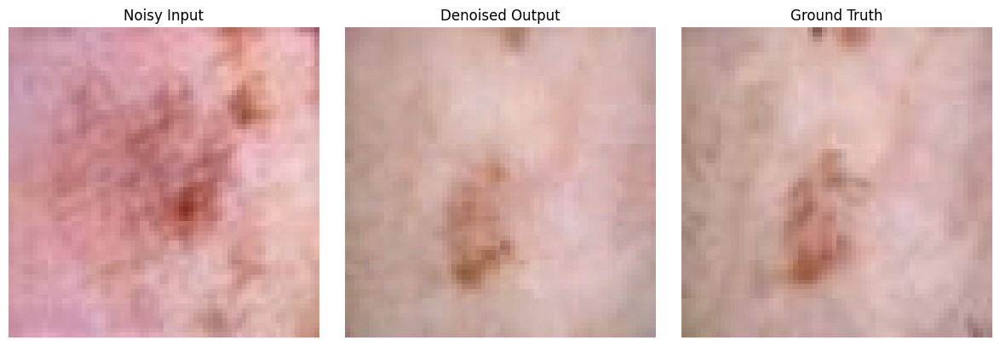

Epoch 171/200
  Gen Loss: 6.1136 | Disc Loss: 0.9409
Epoch 172/200
  Gen Loss: 5.7593 | Disc Loss: 0.9329
Epoch 173/200
  Gen Loss: 6.1390 | Disc Loss: 1.1030
Epoch 174/200
  Gen Loss: 4.8877 | Disc Loss: 1.2127
Epoch 175/200
  Gen Loss: 4.8532 | Disc Loss: 1.2698
Epoch 176/200
  Gen Loss: 6.4778 | Disc Loss: 0.9180
Epoch 177/200
  Gen Loss: 5.6247 | Disc Loss: 0.8953
Epoch 178/200
  Gen Loss: 5.6336 | Disc Loss: 0.8935
Epoch 179/200
  Gen Loss: 5.5580 | Disc Loss: 1.0475
Epoch 180/200
  Gen Loss: 5.4293 | Disc Loss: 1.2501


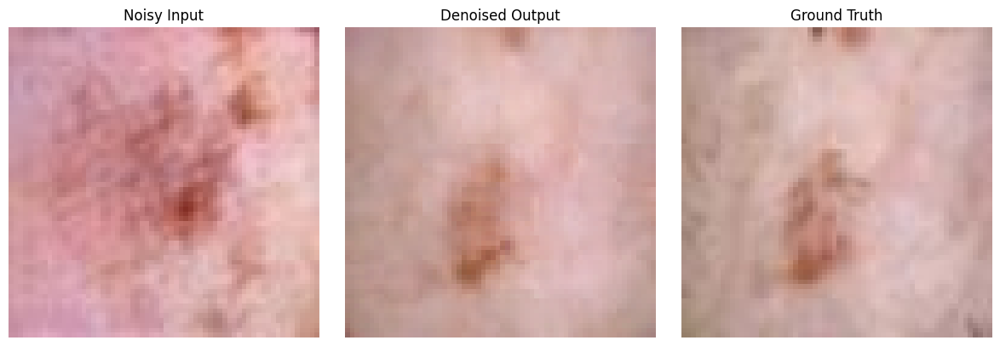

Epoch 181/200
  Gen Loss: 5.2775 | Disc Loss: 1.0106
Epoch 182/200
  Gen Loss: 5.8535 | Disc Loss: 0.9099
Epoch 183/200
  Gen Loss: 5.7694 | Disc Loss: 1.0193
Epoch 184/200
  Gen Loss: 5.8955 | Disc Loss: 1.0046
Epoch 185/200
  Gen Loss: 5.4055 | Disc Loss: 1.1058
Epoch 186/200
  Gen Loss: 5.2530 | Disc Loss: 1.0758
Epoch 187/200
  Gen Loss: 5.1430 | Disc Loss: 0.9252
Epoch 188/200
  Gen Loss: 5.5538 | Disc Loss: 0.9786
Epoch 189/200
  Gen Loss: 5.8733 | Disc Loss: 0.9225
Epoch 190/200
  Gen Loss: 5.4544 | Disc Loss: 0.9738


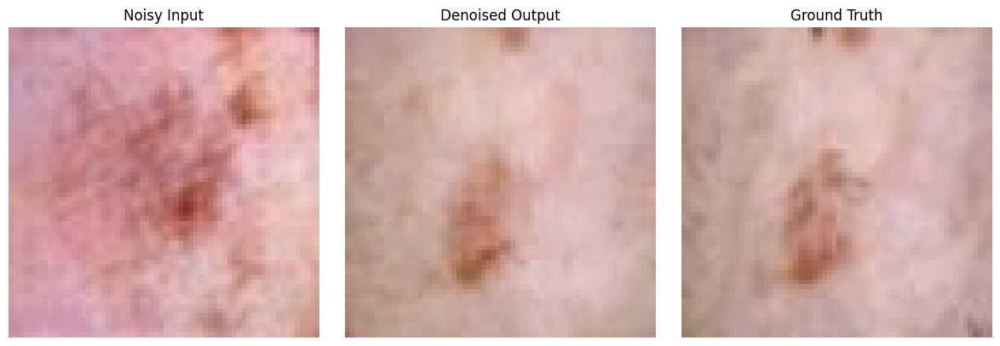

Epoch 191/200
  Gen Loss: 5.5777 | Disc Loss: 1.0435
Epoch 192/200
  Gen Loss: 5.2463 | Disc Loss: 1.0101
Epoch 193/200
  Gen Loss: 5.5656 | Disc Loss: 1.0137
Epoch 194/200
  Gen Loss: 6.0829 | Disc Loss: 1.0077
Epoch 195/200
  Gen Loss: 5.2196 | Disc Loss: 0.9531
Epoch 196/200
  Gen Loss: 5.2234 | Disc Loss: 0.9246
Epoch 197/200
  Gen Loss: 5.2876 | Disc Loss: 0.8782
Epoch 198/200
  Gen Loss: 5.6092 | Disc Loss: 0.9240
Epoch 199/200
  Gen Loss: 5.1656 | Disc Loss: 0.9934
Epoch 200/200
  Gen Loss: 5.2207 | Disc Loss: 0.9852


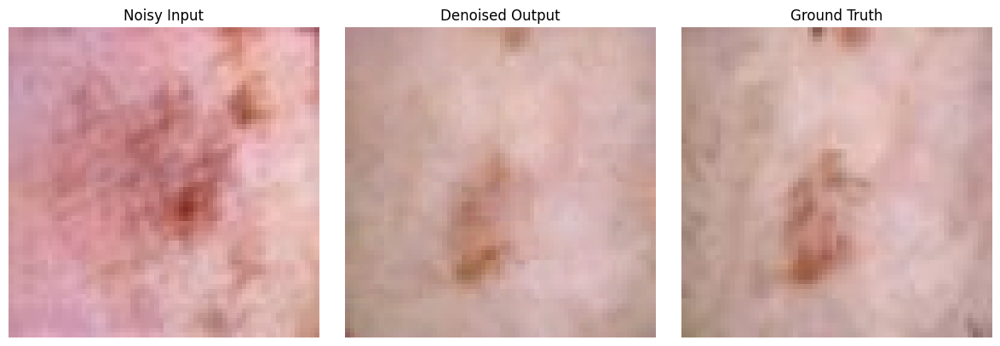

In [60]:
def generate_sample(model, noisy_img, clean_img, epoch):
    pred = model(np.expand_dims(noisy_img, 0), training=False)[0]
    fig, axs = plt.subplots(1, 3, figsize=(12, 4))
    axs[0].imshow((noisy_img + 1) / 2)
    axs[0].set_title("Noisy Input")
    axs[1].imshow((pred + 1) / 2)
    axs[1].set_title("Denoised Output")
    axs[2].imshow((clean_img + 1) / 2)
    axs[2].set_title("Ground Truth")
    for ax in axs: ax.axis('off')
    plt.tight_layout()
    plt.show()

def train(noisy_imgs, clean_imgs, epochs=200):
    for epoch in range(epochs):
        print(f"Epoch {epoch+1}/{epochs}")
        for i in range(0, len(noisy_imgs), BATCH_SIZE):
            input_batch = noisy_imgs[i:i+BATCH_SIZE]
            target_batch = clean_imgs[i:i+BATCH_SIZE]
            gen_loss, disc_loss = train_step(input_batch, target_batch)

        print(f"  Gen Loss: {gen_loss:.4f} | Disc Loss: {disc_loss:.4f}")
        if (epoch + 1) % 10 == 0:
            generate_sample(generator, noisy_imgs[0], clean_imgs[0], epoch)

# 🔁 Start training
train(noisy_imgs, clean_imgs, epochs=200)


In [61]:
import os
from PIL import Image
import numpy as np

def denoise_and_save(base_dir="./data/processed_images"):
    for label in os.listdir(base_dir):
        aug_dir = os.path.join(base_dir, label, "augmented")
        save_dir = os.path.join(base_dir, label, "denoised")
        os.makedirs(save_dir, exist_ok=True)

        if not os.path.exists(aug_dir):
            print(f"Skipping {label} (no augmented folder)")
            continue

        image_files = [f for f in os.listdir(aug_dir) if f.endswith(".jpg") or f.endswith(".png")]
        print(f"🔁 Processing {len(image_files)} images for class '{label}'")

        for fname in image_files:
            try:
                img_path = os.path.join(aug_dir, fname)
                img = Image.open(img_path).convert("RGB").resize(IMG_SIZE)
                img_array = np.array(img).astype(np.float32) / 127.5 - 1
                pred = generator(np.expand_dims(img_array, 0), training=False)[0]
                pred = ((pred + 1) * 127.5).numpy().astype(np.uint8)

                Image.fromarray(pred).save(os.path.join(save_dir, fname))
            except Exception as e:
                print(f"❌ Error processing {fname}: {e}")

    print("✅ Denoising complete for all classes.")

# Run it
denoise_and_save()


🔁 Processing 6378 images for class 'AKIEC'
🔁 Processing 6191 images for class 'BCC'
🔁 Processing 5606 images for class 'BKL'
🔁 Processing 6590 images for class 'DF'
🔁 Processing 5592 images for class 'MEL'
Skipping NV (no augmented folder)
🔁 Processing 6563 images for class 'VASC'
✅ Denoising complete for all classes.


In [11]:
# Calculate and print the total number of images (real + augmented + denoised) for each class
total_images = 0
for label in label_cols:
    real = class_counts.get(label, 0)
    augmented = generated_counts.get(label, 0)
    denoised_dir = os.path.join(base_dir, label, "denoised")
    denoised = len([f for f in os.listdir(denoised_dir) if f.endswith('.jpg') or f.endswith('.png')]) if os.path.exists(denoised_dir) else 0
    total = real + augmented
    print(f"{label}: Real={real}, Augmented={augmented}, Denoised={denoised}, Total={total}")
    total_images += total
print("Total images for training:", total_images)

MEL: Real=1113, Augmented=5592, Denoised=5592, Total=6705
NV: Real=6705, Augmented=0, Denoised=0, Total=6705
BCC: Real=514, Augmented=6191, Denoised=6191, Total=6705
AKIEC: Real=327, Augmented=6378, Denoised=6378, Total=6705
BKL: Real=1099, Augmented=5606, Denoised=5606, Total=6705
DF: Real=115, Augmented=6590, Denoised=6590, Total=6705
VASC: Real=142, Augmented=6563, Denoised=6563, Total=6705
Total images for training: 46935


In [12]:
import os
print(os.listdir("./data/processed_images"))


['AKIEC', 'BCC', 'BKL', 'DF', 'MEL', 'NV', 'VASC']


In [14]:
print(os.listdir(os.path.join(base_dir, "MEL", "denoised")))


['aug_0.jpg', 'aug_1.jpg', 'aug_10.jpg', 'aug_100.jpg', 'aug_1000.jpg', 'aug_1001.jpg', 'aug_1002.jpg', 'aug_1003.jpg', 'aug_1004.jpg', 'aug_1005.jpg', 'aug_1006.jpg', 'aug_1007.jpg', 'aug_1008.jpg', 'aug_1009.jpg', 'aug_101.jpg', 'aug_1010.jpg', 'aug_1011.jpg', 'aug_1012.jpg', 'aug_1013.jpg', 'aug_1014.jpg', 'aug_1015.jpg', 'aug_1016.jpg', 'aug_1017.jpg', 'aug_1018.jpg', 'aug_1019.jpg', 'aug_102.jpg', 'aug_1020.jpg', 'aug_1021.jpg', 'aug_1022.jpg', 'aug_1023.jpg', 'aug_1024.jpg', 'aug_1025.jpg', 'aug_1026.jpg', 'aug_1027.jpg', 'aug_1028.jpg', 'aug_1029.jpg', 'aug_103.jpg', 'aug_1030.jpg', 'aug_1031.jpg', 'aug_1032.jpg', 'aug_1033.jpg', 'aug_1034.jpg', 'aug_1035.jpg', 'aug_1036.jpg', 'aug_1037.jpg', 'aug_1038.jpg', 'aug_1039.jpg', 'aug_104.jpg', 'aug_1040.jpg', 'aug_1041.jpg', 'aug_1042.jpg', 'aug_1043.jpg', 'aug_1044.jpg', 'aug_1045.jpg', 'aug_1046.jpg', 'aug_1047.jpg', 'aug_1048.jpg', 'aug_1049.jpg', 'aug_105.jpg', 'aug_1050.jpg', 'aug_1051.jpg', 'aug_1052.jpg', 'aug_1053.jpg', 'aug_

In [27]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from skimage import exposure

# Base data path
BASE_DIR= "C:\\Users\\devgo\\OneDrive\\Desktop\\project\\data\\processed_images"

# Folder names inside each class
GAN_FOLDER = "denoised"          # Or "augmented"
OUTPUT_FOLDER = "normalized"     # Where we save color-normalized GAN images


In [28]:
def reinhard_color_transfer(source_img, target_img):
    source = cv2.cvtColor(source_img, cv2.COLOR_RGB2LAB).astype("float32")
    target = cv2.cvtColor(target_img, cv2.COLOR_RGB2LAB).astype("float32")

    mean_s, std_s = cv2.meanStdDev(source)
    mean_t, std_t = cv2.meanStdDev(target)

    normalized = (source - mean_s) * (std_t / std_s + 1e-8) + mean_t
    normalized = np.clip(normalized, 0, 255)
    return cv2.cvtColor(normalized.astype("uint8"), cv2.COLOR_LAB2RGB)



In [ ]:
def normalize_gan_images(base_dir=BASE_DIR):
    class_dirs = os.listdir(base_dir)
    print("📂 Found classes:", class_dirs)

    for label in class_dirs:
        class_path = os.path.join(BASE_DIR, label)
        gan_dir = os.path.join(class_path, GAN_FOLDER)
        norm_dir = os.path.join(class_path, OUTPUT_FOLDER)
        os.makedirs(norm_dir, exist_ok=True)

        if not os.path.exists(gan_dir):
            print(f"⚠️ Skipping {label} (no '{GAN_FOLDER}' folder)")
            continue

        real_files = sorted([f for f in os.listdir(class_path) if f.endswith(".jpg")])
        gan_files = sorted([f for f in os.listdir(gan_dir) if f.endswith(".jpg")])
        match_count = min(len(real_files), len(gan_files))

        print(f"🔧 {label}: {len(real_files)} real, {len(gan_files)} GAN | Processing {match_count} pairs")

        for i in range(match_count):
            try:
                real_img_path = os.path.join(class_path, real_files[i])
                gan_img_path = os.path.join(gan_dir, gan_files[i])
                save_path = os.path.join(norm_dir, gan_files[i])

                real = np.array(Image.open(real_img_path).convert("RGB").resize((64, 64)))
                gan = np.array(Image.open(gan_img_path).convert("RGB").resize((64, 64)))

                norm = reinhard_color_transfer(gan, real)
                Image.fromarray(norm).save(save_path)

            except Exception as e:
                print(f"❌ Error on {gan_files[i]}: {e}")

    print("✅ Color normalization completed.")


In [ ]:
from PIL import Image
import os

# Print (display) the images in the directory specified by class_path
import matplotlib.pyplot as plt

image_files = [f for f in os.listdir(class_path) if f.endswith('.jpg') or f.endswith('.png')]
n = min(10, len(image_files))
fig, axs = plt.subplots(1, n, figsize=(15, 3))
for i in range(n):
    img = Image.open(os.path.join(class_path, image_files[i]))
    axs[i].imshow(img)
    axs[i].axis('off')
    axs[i].set_title(image_files[i])
plt.tight_layout()
plt.show()

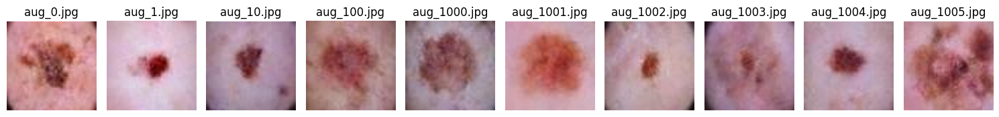

In [25]:
import os
from PIL import Image

import matplotlib.pyplot as plt
# Define gan_dir using existing variables
example_label = 'MEL'
gan_dir = os.path.join(base_dir, example_label, GAN_FOLDER)
gan_files = [f for f in os.listdir(gan_dir) if f.endswith('.jpg') or f.endswith('.png')][:10]

fig, axs = plt.subplots(1, len(gan_files), figsize=(15, 3))
for i, fname in enumerate(gan_files):
    img = Image.open(os.path.join(gan_dir, fname))
    axs[i].imshow(img)
    axs[i].axis('off')
    axs[i].set_title(fname)
plt.tight_layout()
plt.show()

In [3]:
import os
import pandas as pd

base_dir = "./data/processed_images"
output_csv_path = "./final_labels_onehot.csv"

data_rows = []
all_labels = sorted([label for label in os.listdir(base_dir) if os.path.isdir(os.path.join(base_dir, label))])

for label in all_labels:
    label_dir = os.path.join(base_dir, label)

    # Real images
    for file in os.listdir(label_dir):
        if file.endswith(".jpg") or file.endswith(".png"):
            row = {"filename": f"{label}/{file}"}
            row.update({lbl: int(lbl == label) for lbl in all_labels})
            data_rows.append(row)

    # Augmented images
    aug_dir = os.path.join(label_dir, "augmented")
    if os.path.exists(aug_dir):
        for file in os.listdir(aug_dir):
            if file.endswith(".jpg") or file.endswith(".png"):
                row = {"filename": f"{label}/augmented/{file}"}
                row.update({lbl: int(lbl == label) for lbl in all_labels})
                data_rows.append(row)

# Save to CSV
df = pd.DataFrame(data_rows)
df.to_csv(output_csv_path, index=False)
print(f"✅ One-hot encoded CSV saved to: {output_csv_path} with {len(df)} entries")
df.head()


✅ One-hot encoded CSV saved to: ./final_labels_onehot.csv with 46935 entries


,filename,AKIEC,BCC,BKL,DF,MEL,NV,VASC
0,AKIEC/ISIC_0024329.jpg,1,0,0,0,0,0,0
1,AKIEC/ISIC_0024372.jpg,1,0,0,0,0,0,0
2,AKIEC/ISIC_0024418.jpg,1,0,0,0,0,0,0
3,AKIEC/ISIC_0024450.jpg,1,0,0,0,0,0,0
4,AKIEC/ISIC_0024463.jpg,1,0,0,0,0,0,0
